# <center><b>Predicting District Paddy Yields in Sri Lanka</b></center>

Wijesinghe W K A D U (index 269219J)

IT5504 Applied Machine Learning, Final Assignment

The complete code, data and deployment files are available in the [GitHub repository](https://github.com/Uthpalagit/paddy-yield-prediction-269219J). The deployed [web application](https://paddy-yield-app.grayflower-d27356cf.malaysiawest.azurecontainerapps.io) and the [prediction API](https://paddy-yield-api.grayflower-d27356cf.malaysiawest.azurecontainerapps.io/docs) are hosted on Azure Container Apps, with a [backup copy of the application](https://paddy-yield-prediction-269219j-2wfd9iajbb7ebf2jpuzzgb.streamlit.app) on Streamlit Community Cloud.

## <center><b>Problem Definition</b></center>

Rice is the staple food of Sri Lanka and is cultivated in two seasons. Maha, the main season, extends approximately from October to March under the north-east monsoon, and Yala, the minor season, approximately from April to September.

District yields are known only when the Department of Census and Statistics (DCS) completes its crop-cutting survey, months after harvest. Until then, the Department of Agriculture, the Paddy Marketing Board and the Ministry must plan procurement, storage, imports and support without knowing the size of the harvest. The cost of this gap was demonstrated in the 2021/22 Maha season, when the abrupt ban on chemical fertilizer imports in 2021 caused a sharp national decline in yields and urgent rice imports.

The aim is to estimate a district's average paddy yield (kg per hectare) as soon as the season ends, using only the planted extent and irrigation type, the district's previous seasons and the weather during the season. The models range from weak learners through bagging, boosting (including CatBoost and LightGBM) and stacking to time-series hybrids with ARIMA. They are compared with published approaches and interpreted with SHAP and LIME.

More than 40 candidate features from eleven public datasets were each tested on the validation years, and the final set was examined with three standard feature selection methods. Only features that improved accuracy were retained (Sections 3, 10.1 and 15.3).

The beneficiaries are the Department of Agriculture and provincial agriculture offices receive early warning of underperforming districts, the Paddy Marketing Board can plan procurement, and policy makers can make more informed import decisions.

## <center><b>1. Possible Features from Earlier Studies</b></center>

Before data collection, earlier rice yield studies were reviewed to identify factors that might affect a district's harvest. Each is framed as a hypothesis with its rationale, expected direction and data source, and missing data are stated explicitly, since gaps matter as much as the data used. The notebook then proceeds through the datasets, cleaning into one table, feature construction and testing, retaining only features that improve accuracy.

1. Past yields reflect a district's soils, irrigation and farming practice and should be the strongest single predictor, while the steady rise since the 1980s suggests a trend term. Earlier Sri Lankan forecasting work used time-series models such as ARIMA (Senevirathne and Premasiri, 2025). The data are obtained from the DCS paddy statistics (history features and an ARIMA forecast).
2. The effect of rainfall should depend on timing. Rain before the season should raise yields by filling the tanks and reservoirs on which irrigated fields depend.

   During the season, insufficient rain should lower rainfed yields, while very heavy rain floods and flattens the crop. Every Sri Lankan crop-weather study uses rainfall, and an inter-district regression from the 1980s identified rainfall and fertilizer as the two most important factors.

   The data are obtained from CHIRPS. Rain before the season and over the preceding six months is kept separate from rain during the season (total, anomaly, wettest and driest months, dry spells, heavy-rain days), so that each can have a distinct effect.
3. Temperature, humidity, sunshine and wind may be relevant, with sunshine aiding growth and heat and strong wind reducing yield. A Random Forest study of seven paddy regions found minimum humidity and maximum temperature the most influential weather measures (Ekanayake et al., 2021, *Journal of Mathematics*), and a Gaussian Process study also used wind, evaporation and sunshine hours. The data are obtained from NASA POWER.
4. Fields under major irrigation schemes should yield more and vary less than rainfed fields, as their water does not depend on seasonal rain. The DCS reports the extent under major schemes, minor tanks and rain.

   Tank storage at the start of the season may also be relevant, especially for Yala, which relies on water remaining from the Maha rains. Reservoir levels are not published, so rain before the season and over the preceding six months serves as a proxy (see item 2).
5. Fertilizer and government policy should have a strong effect, as the 2021/22 shortage demonstrated. The fertilizer subsidy has been the principal paddy policy since 1962 (Weerahewa, Kodithuwakku and Ariyawardana, 2010).

   National fertilizer imports are obtained from FAOSTAT and the policy in force each season from published policy studies. Fertilizer issued to each district might best capture a shock such as 2021, but it is not published and could not be used.
6. A greener, denser crop observed from space should produce more grain, and satellite greenness is widely used for yield forecasting, including for Sri Lankan agro-zones (Senevirathne and Premasiri, 2025). The data are obtained from NASA MODIS (NDVI) and NOAA (crop health over the rice fields).
7. Dry soil, or hot windy days that draw water from the field, should reduce yield, and satellite yield studies use root-zone soil moisture. The data are obtained from ERA5-Land, with evaporation derived from NASA POWER.
8. El Niño and the Indian Ocean Dipole alter the amount of monsoon rain reaching Sri Lanka and might add information beyond rainfall itself. The Indian Ocean Dipole has been linked to Maha paddy production (Abeysekera et al., 2023). The data are obtained from NOAA.
9. Weather at each growth stage is also relevant, as heat at flowering can prevent grain formation, cooler nights during grain filling should raise yield and a wet harvest causes losses. A systematic review of 156 rice yield studies (*Computers and Electronics in Agriculture*) found that temperature and sunshine have different effects at each stage. The data are obtained from NASA POWER and CHIRPS.
10. Districts in the same province or climate zone may behave similarly, so grouping them could allow the model to learn from neighbours. The data are obtained from the administrative map and the Department of Agriculture's agro-ecological zones.
11. The same review identified nitrogen application and the adoption of new varieties among the strongest drivers of yield, and a pest outbreak such as brown planthopper can destroy a district's harvest.

   Sri Lanka publishes no district-level records of varieties grown, nitrogen applied or pest outbreaks, so these could not be included. This is one of the principal limitations of the project (Section 20).

Sections 10, 15 and 17 test these hypotheses against the data.

## <center><b>2. Import the Required Libraries</b></center>

In [1]:
import os
import io
import re
import json
import time
import pickle
import zipfile
import warnings

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor, StackingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from scipy.stats import wilcoxon
from statsmodels.tsa.arima.model import ARIMA

import xgboost
import lightgbm
import catboost
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import shap
from lime.lime_tabular import LimeTabularExplainer
warnings.filterwarnings("ignore", category=DeprecationWarning)  # ydata-profiling announces a future rename on import
from ydata_profiling import ProfileReport
import statsmodels.api as sm
from sklearn.linear_model import HuberRegressor
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from interpret.glassbox import ExplainableBoostingRegressor
from ngboost import NGBRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)
random_state = 42

os.makedirs("Raw Data", exist_ok=True)
print("xgboost", xgboost.__version__, "| lightgbm", lightgbm.__version__, "| catboost", catboost.__version__, "| shap", shap.__version__)

xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10 | shap 0.53.0


## <center><b>3. Data Collection</b></center>

No ready-made dataset exists for this problem, so one is assembled from publicly available sources. Many sources are loaded to identify the best combination of features rather than to use them all, since weather, soil water, crop health, fertilizer supply, government policy and the ocean patterns that shift the monsoon could all affect a harvest.

Each source is loaded here, converted into candidate features in Section 7, tested on the validation years only (Section 10.1) and examined with three standard feature selection methods (Section 15.3). Only features that improve accuracy are retained, and rejected sources remain as evidence for their exclusion, with a ledger in Section 15.6 recording every source, feature and decision. The sources are listed below in loading order.

1. Paddy statistics are obtained from the [Department of Census and Statistics (DCS)](https://www.statistics.gov.lk/Agriculture/StaticalInformation/PaddyStatistics) (3.1). They provide the yield (the target), sown extent and irrigation shares, yield history and trend forecast, the neighbouring districts' previous season and the harvested share. The final model uses them.
2. District locations and boundaries are obtained from [OpenStreetMap Nominatim](https://nominatim.openstreetmap.org/) (3.2). The final model uses them to match the weather to each district, and the app uses them to draw the map.
3. Temperature, humidity, solar radiation and wind are obtained from [NASA POWER](https://power.larc.nasa.gov/) (3.3), which also provides evapotranspiration, the hottest month and growth-stage weather. The final model uses maximum temperature, humidity, solar radiation and wind.
4. Daily rainfall is obtained from [CHIRPS](https://www.chc.ucsb.edu/data/chirps) through the [ClimateSERV](https://climateserv.servirglobal.net/) web service (3.4). It provides season rainfall and its anomaly, the wettest and driest months, rain before the season, dry spells, heavy-rain days, rain in the preceding six months and rain at harvest, and the final model uses it.
5. Fertilizer imports are obtained from [FAOSTAT](https://www.fao.org/faostat/en/#data/RFN) (3.5). They were tested and not retained.
6. Vegetation greenness is obtained from [NASA MODIS MOD13Q1](https://lpdaac.usgs.gov/products/mod13q1v061/) through the [ORNL DAAC](https://modis.ornl.gov/) web service (3.6). It was tested and not retained.
7. El Niño and Indian Ocean Dipole indices are obtained from [NOAA CPC](https://www.cpc.ncep.noaa.gov/data/indices/) and [NOAA PSL](https://psl.noaa.gov/gcos_wgsp/Timeseries/DMI/) (3.7). They were tested and not retained.
8. Crop health over the rice fields is obtained from [NOAA STAR Vegetation Health](https://www.star.nesdis.noaa.gov/smcd/emb/vci/VH/vh_adminMeanByCrop.php) (3.8). It was tested and not retained.
9. Soil moisture is obtained from [ECMWF ERA5-Land](https://cds.climate.copernicus.eu/) through the [Open-Meteo historical weather API](https://open-meteo.com/en/docs/historical-weather-api) (3.9). It was tested and not retained.
10. The fertilizer subsidy history is taken from two published policy studies (7.1), providing the support level, shortage flag and policy regime. The final model uses the shortage flag as a scenario switch (Section 11).
11. Provinces and climate zones are taken from the administrative map and the Department of Agriculture's agro-ecological zones (7.1). They were tested and not retained.

The final model, app and API therefore depend only on the DCS paddy statistics, CHIRPS rainfall, NASA POWER weather and the fertilizer policy record, with OpenStreetMap used once to locate each district.

Sources are loaded here exactly as downloaded, without cleaning. Each loader uses a saved copy in Raw Data/ when present and otherwise queries the live source, so reruns are fast and the download code remains functional.

All the data used is publicly released and aggregated to district level. No personal or sensitive information about farmers or households is collected or used, so no consent is required, and each source is cited and used within its terms of release.

In [2]:
# every source below follows the same pattern, reusing the cached file if it exists and otherwise downloading and saving it once
def load_or_fetch(cache_path, fetch_func, label):
    if os.path.exists(cache_path):
        print(f"Loading cached {label} from", cache_path)
    else:
        print(f"No cached file found, fetching {label}...")
        fetch_func(cache_path)
    return cache_path

### <b>3.1 Paddy Statistics (DCS)</b>

The DCS publishes four tables for each of the two seasons, namely average yield, sown extent, harvested extent and production. Average yield is the target and is derived from the DCS crop-cutting survey, which is completed only months after harvest.

In [3]:
DCS_BASE = "https://www.statistics.gov.lk/Agriculture/StaticalInformation/PaddyStatistics"
DCS_FILES = [
    "Average_Yeild-Maha_Season-1979-2025", "Average_Yeild-Yala_Season-1979-2025",
    "Sown_Extent-Maha_Seasons-1979-2025", "Sown_Extent-Yala_Seasons-1979-2025",
    "Harvested_Extent-Maha_Seasons-1979-2025", "Harvested_Extent-Yala_Seasons-1979-2025",
    "Production-Maha_Season-1979-2025", "Production-Yala_Season-1979-2025",
]
HEADERS = {"User-Agent": "Mozilla/5.0 (MSc coursework)"}


def download_dcs_file(name):
    # returns a function that downloads one DCS table to the given path
    def fetch(path):
        r = requests.get(f"{DCS_BASE}/{name}", headers=HEADERS, timeout=60)
        r.raise_for_status()
        with open(path, "wb") as f:
            f.write(r.content)
    return fetch


raw_tables = {}
for name in DCS_FILES:
    path = load_or_fetch(f"Raw Data/{name}.xlsx", download_dcs_file(name), name)
    raw_tables[name] = pd.read_excel(path, header=None)

print()
for name, table in raw_tables.items():
    print(f"{name:42s} shape {table.shape}")

Loading cached Average_Yeild-Maha_Season-1979-2025 from Raw Data/Average_Yeild-Maha_Season-1979-2025.xlsx
Loading cached Average_Yeild-Yala_Season-1979-2025 from Raw Data/Average_Yeild-Yala_Season-1979-2025.xlsx
Loading cached Sown_Extent-Maha_Seasons-1979-2025 from Raw Data/Sown_Extent-Maha_Seasons-1979-2025.xlsx
Loading cached Sown_Extent-Yala_Seasons-1979-2025 from Raw Data/Sown_Extent-Yala_Seasons-1979-2025.xlsx
Loading cached Harvested_Extent-Maha_Seasons-1979-2025 from Raw Data/Harvested_Extent-Maha_Seasons-1979-2025.xlsx
Loading cached Harvested_Extent-Yala_Seasons-1979-2025 from Raw Data/Harvested_Extent-Yala_Seasons-1979-2025.xlsx
Loading cached Production-Maha_Season-1979-2025 from Raw Data/Production-Maha_Season-1979-2025.xlsx
Loading cached Production-Yala_Season-1979-2025 from Raw Data/Production-Yala_Season-1979-2025.xlsx

Average_Yeild-Maha_Season-1979-2025        shape (34, 194)
Average_Yeild-Yala_Season-1979-2025        shape (34, 190)
Sown_Extent-Maha_Seasons-1979-202

In [4]:
raw_tables["Average_Yeild-Maha_Season-1979-2025"].iloc[:10, :11]

,0,1,2,3,4,5,6,7,8,9,10
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,District,1978/1979,NaN,NaN,NaN,1979/1980,NaN,NaN,NaN,1980/1981
3,NaN,NaN,Major,Minor,Rainfed,Total,Major,Minor,Rainfed,Total,Major
4,NaN,COLOMBO,-,-,-,2038,-,-,-,2713,-
5,NaN,GAMPAHA,-,-,-,2476,-,-,-,2473,-
6,NaN,KALUTARA,-,-,-,1707,-,-,-,1803,-
7,NaN,KANDY,-,-,-,3201,-,-,-,3141,-
8,NaN,MATALE,-,-,-,3245,-,-,-,3085,-
9,NaN,NUWARA ELIYA,-,-,-,4111,-,-,-,3720,-


The tables are in wide format, with one row per district and four columns per season (Major, Minor, Rainfed, Total). The season label appears only above the first of the four, and "-" denotes missing figures. These issues must be resolved before the tables can be joined (Section 4).

### <b>3.2 District Coordinates</b>

NASA POWER is queried by latitude and longitude, so each production unit requires a coordinate. The 27 units are the 25 administrative districts plus two irrigation project areas reported separately by the DCS (Mahaweli System H and Udawalawe, see 4.3). For these two areas a central town is used, Thambuttegama for System H and Udawalawe town for the Udawalawe scheme.

In [5]:
# the 27 production units, spelled the way they are cleaned in 4.3 (the raw DCS files use a few other spellings)
production_units = [
    "AMPARA", "ANURADHAPURA", "BADULLA", "BATTICALOA", "COLOMBO", "GALLE", "GAMPAHA", "HAMBANTOTA", "JAFFNA",
    "KALUTARA", "KANDY", "KEGALLE", "KILINOCHCHI", "KURUNEGALA", "MAHAWELI 'H'", "MANNAR", "MATALE", "MATARA",
    "MONARAGALA", "MULLATIVU", "NUWARA ELIYA", "POLONNARUWA", "PUTTALAM", "RATNAPURA", "TRINCOMALEE", "UDAWALAWE", "VAVUNIYA",
]
GEO_QUERY = {d: f"{d.title()} District" for d in production_units}
GEO_QUERY.update({"MULLATIVU": "Mullaitivu District", "UDAWALAWE": "Udawalawe", "MAHAWELI 'H'": "Thambuttegama"})


def geocode_all(path):
    rows = []
    for district, query in sorted(GEO_QUERY.items()):
        r = requests.get("https://nominatim.openstreetmap.org/search",
                         params={"q": f"{query}, Sri Lanka", "format": "json", "limit": 1},
                         headers={"User-Agent": "msc-coursework-paddy/1.0"}, timeout=30).json()
        rows.append({"district": district, "query": query, "latitude": float(r[0]["lat"]), "longitude": float(r[0]["lon"]),
                     "matched": r[0]["display_name"]})
        time.sleep(1.1)  # Nominatim asks for at most one request per second
    pd.DataFrame(rows).to_csv(path, index=False)


coords = pd.read_csv(load_or_fetch("Raw Data/district_coordinates.csv", geocode_all, "district coordinates"))
print("Units geocoded", len(coords))
print("Every match inside Sri Lanka", coords["matched"].str.contains("Sri Lanka").all())
print("Latitude range", coords.latitude.min(), "-", coords.latitude.max(), "| longitude range", coords.longitude.min(), "-", coords.longitude.max())
coords[["district", "query", "latitude", "longitude", "matched"]]

Loading cached district coordinates from Raw Data/district_coordinates.csv
Units geocoded 27
Every match inside Sri Lanka True
Latitude range 6.0582732 - 9.6985 | longitude range 79.8293371 - 81.8322887


,district,query,latitude,longitude,matched
0,AMPARA,Ampara District,7.074,81.832,"Ampara District, Eastern Province, Sri Lanka"
1,ANURADHAPURA,Anuradhapura District,8.368,80.440,"Anuradhapura District, North Central Province,..."
2,BADULLA,Badulla District,7.084,81.089,"Badulla District, Uva Province, Sri Lanka"
3,BATTICALOA,Batticaloa District,7.838,81.557,"Batticaloa District, Eastern Province, Sri Lanka"
4,COLOMBO,Colombo District,6.848,79.926,"Colombo District, Western Province, Sri Lanka"
5,GALLE,Galle District,6.105,80.152,"Galle District, Southern Province, Sri Lanka"
6,GAMPAHA,Gampaha District,7.119,79.916,"Gampaha District, Western Province, Sri Lanka"
7,HAMBANTOTA,Hambantota District,6.176,81.132,"Hambantota District, Southern Province, Sri Lanka"
8,JAFFNA,Jaffna District,9.698,80.079,"Jaffna District, Northern Province, Sri Lanka"
9,KALUTARA,Kalutara District,6.575,80.029,"Kalutara District, Western Province, Sri Lanka"


Every query resolved to a place in Sri Lanka, and all coordinates fall inside the island's bounding box (approximately 5.9-9.9° N, 79.5-81.9° E). District queries matched district boundaries rather than towns of the same name, except where a town was requested deliberately. Kurunegala matched as "Kurunǣgala" (the OSM spelling), the correct place, and Nuwara Eliya returns (7.012, 80.757), close to the commonly cited (7.00, 80.75).

### <b>3.3 Weather (NASA POWER)</b>

NASA POWER provides temperature, humidity, solar radiation and wind (and a rainfall estimate) for each coordinate.

In [6]:
POWER_PARAMS = "PRECTOTCORR_SUM,T2M,T2M_MAX,T2M_MIN,RH2M,ALLSKY_SFC_SW_DWN,WS2M"


def download_weather(path, start=1981, end=2026):
    # one request per unit, and the CSV response has a text header ending with -END HEADER-
    frames = []
    for _, c in coords.iterrows():
        url = ("https://power.larc.nasa.gov/api/temporal/monthly/point"
               f"?parameters={POWER_PARAMS}&community=AG&longitude={c.longitude:.4f}&latitude={c.latitude:.4f}"
               f"&start={start}&end={end}&format=CSV")
        text = requests.get(url, timeout=120).text
        body = text[text.index("-END HEADER-") + len("-END HEADER-"):].strip()
        part = pd.read_csv(io.StringIO(body))
        part.insert(0, "district", c.district)
        frames.append(part)
        time.sleep(0.5)
    pd.concat(frames, ignore_index=True).to_csv(path, index=False)


weather_raw = pd.read_csv(load_or_fetch("Raw Data/nasa_power_monthly.csv", download_weather, "NASA POWER weather"))
print("Shape", weather_raw.shape)
print("Units", weather_raw.district.nunique(), "| parameters", sorted(weather_raw.PARAMETER.unique()), "| years", weather_raw.YEAR.min(), "-", weather_raw.YEAR.max())
weather_raw.head(10)

Loading cached NASA POWER weather from Raw Data/nasa_power_monthly.csv
Shape (8694, 16)
Units 27 | parameters ['ALLSKY_SFC_SW_DWN', 'PRECTOTCORR_SUM', 'RH2M', 'T2M', 'T2M_MAX', 'T2M_MIN', 'WS2M'] | years 1981 - 2026


,district,PARAMETER,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANN
0,AMPARA,ALLSKY_SFC_SW_DWN,1981,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00
1,AMPARA,ALLSKY_SFC_SW_DWN,1982,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00
2,AMPARA,ALLSKY_SFC_SW_DWN,1983,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00,-999.00
3,AMPARA,ALLSKY_SFC_SW_DWN,1984,12.91,11.71,20.06,18.86,21.35,20.47,17.77,19.91,20.11,19.06,16.81,15.49,17.90
4,AMPARA,ALLSKY_SFC_SW_DWN,1985,16.64,17.37,21.92,22.37,20.64,18.71,19.44,19.51,20.14,18.91,16.54,14.88,18.93
5,AMPARA,ALLSKY_SFC_SW_DWN,1986,14.32,18.59,19.07,23.10,22.33,19.41,19.19,20.65,20.20,19.01,16.94,14.52,18.94
6,AMPARA,ALLSKY_SFC_SW_DWN,1987,13.59,19.80,21.28,20.85,21.32,17.78,20.92,18.65,20.31,18.00,17.30,14.69,18.69
7,AMPARA,ALLSKY_SFC_SW_DWN,1988,14.95,18.74,19.94,19.45,19.02,20.34,17.31,17.85,18.39,21.14,15.65,15.13,18.15
8,AMPARA,ALLSKY_SFC_SW_DWN,1989,14.31,19.85,22.41,22.56,19.56,18.03,18.47,20.02,19.90,20.02,16.85,15.74,18.97
9,AMPARA,ALLSKY_SFC_SW_DWN,1990,16.50,19.37,20.71,21.32,19.30,19.59,18.66,18.43,20.16,18.80,17.77,13.47,18.66


This table is also in wide format, with one row per unit, parameter and year, a column per month and an unnecessary annual column (ANN).

### <b>3.4 Rainfall (CHIRPS)</b>

Rainfall is the most important weather variable for paddy, so it has a dedicated source of finer resolution. CHIRPS (Climate Hazards Group InfraRed Precipitation with Station data) combines satellite imagery with rain-gauge records on a grid of about 5 km and is the product most widely used for agricultural drought monitoring.

The ClimateSERV API (NASA and USAID's SERVIR programme) returns daily values averaged over any area, so each district receives the average over its OpenStreetMap boundary rather than a point value. The two irrigation areas lack official boundaries, so a box of about 25 km around each centre is used.

In [7]:
CHIRPS_API = "https://climateserv.servirglobal.net/api"


def district_outline(district, query, lat, lon):
    # the district's boundary polygon from OpenStreetMap (simplified), or a small box for the two irrigation areas
    if district in ("MAHAWELI 'H'", "UDAWALAWE"):
        d = 0.12
        return {"type": "Polygon", "coordinates": [[[lon - d, lat - d], [lon + d, lat - d], [lon + d, lat + d], [lon - d, lat + d], [lon - d, lat - d]]]}
    r = requests.get("https://nominatim.openstreetmap.org/search",
                     params={"q": f"{query}, Sri Lanka", "format": "json", "limit": 1, "polygon_geojson": 1, "polygon_threshold": 0.01},
                     headers={"User-Agent": "msc-coursework-paddy/1.0"}, timeout=60).json()[0]["geojson"]
    if r["type"] == "MultiPolygon":  # keep the largest part (the mainland part of a coastal district)
        r = {"type": "Polygon", "coordinates": max(r["coordinates"], key=lambda p: len(p[0]))}
    return r


def download_outlines(path):
    outlines = {}
    for c in coords.itertuples():
        outlines[c.district] = district_outline(c.district, c.query, c.latitude, c.longitude)
        time.sleep(1.1)
    with open(path, "w") as f:
        json.dump(outlines, f)


def chirps_chunk(geom, begin, end, tries=4):
    # one ClimateSERV job returning daily CHIRPS rainfall averaged over the polygon (datatype 0 is CHIRPS, operationtype 5 is the average)
    for attempt in range(tries):
        try:
            job = requests.get(f"{CHIRPS_API}/submitDataRequest/", params={"datatype": 0, "begintime": begin, "endtime": end, "intervaltype": 0,
                                                                            "operationtype": 5, "geometry": json.dumps(geom)}, timeout=120).json()[0]
            for _ in range(120):
                progress = requests.get(f"{CHIRPS_API}/getDataRequestProgress/", params={"id": job}, timeout=60).json()[0]
                if progress >= 100 or progress < 0:
                    break
                time.sleep(3)
            data = requests.get(f"{CHIRPS_API}/getDataFromRequest/", params={"id": job}, timeout=300).json()["data"]
            return pd.DataFrame({"date": [d["date"] for d in data], "rain_mm": [d["value"]["avg"] for d in data]})
        except Exception:
            time.sleep(10)
    raise RuntimeError(f"CHIRPS request failed for {begin}-{end}")


def download_chirps(path):
    # long requests time out on the server, so each district is fetched in 5-year pieces, 10 at a time
    from concurrent.futures import ThreadPoolExecutor
    chunks = [(f"01/01/{y}", f"12/31/{min(y + 4, 2025)}") for y in range(1981, 2026, 5)] + [("01/01/2026", "03/31/2026")]
    tasks = [(d, b, e) for d in outlines for b, e in chunks]

    def fetch(task):
        d, b, e = task
        return chirps_chunk(outlines[d], b, e).assign(district=d)

    with ThreadPoolExecutor(10) as pool:
        out = pd.concat(list(pool.map(fetch, tasks)), ignore_index=True)
    out = out.assign(_day=pd.to_datetime(out.date, format="%m/%d/%Y")).sort_values(["district", "_day"])
    out[["district", "date", "rain_mm"]].to_csv(path, index=False)


with open(load_or_fetch("Raw Data/district_outlines.json", download_outlines, "district outlines")) as f:
    outlines = json.load(f)
chirps_raw = pd.read_csv(load_or_fetch("Raw Data/chirps_daily.csv", download_chirps, "CHIRPS daily rainfall"))
print("Outlines", len(outlines), "| points per outline", min(len(g["coordinates"][0]) for g in outlines.values()), "-", max(len(g["coordinates"][0]) for g in outlines.values()))
print("Shape", chirps_raw.shape, "| units", chirps_raw.district.nunique(), "| from", chirps_raw.date.iloc[0], "to", chirps_raw.date.iloc[-1])
chirps_raw.head()

Loading cached district outlines from Raw Data/district_outlines.json
Loading cached CHIRPS daily rainfall from Raw Data/chirps_daily.csv
Outlines 27 | points per outline 5 - 80
Shape (446202, 3) | units 27 | from 01/01/1981 to 03/31/2026


,district,date,rain_mm
0,AMPARA,01/01/1981,38.231
1,AMPARA,01/02/1981,40.012
2,AMPARA,01/03/1981,10.048
3,AMPARA,01/04/1981,2.390
4,AMPARA,01/05/1981,0.000


### <b>3.5 Fertilizer Imports (FAOSTAT)</b>

The 2021/22 collapse was caused by fertilizer, which none of the sources above capture. FAOSTAT (the statistics database of the UN Food and Agriculture Organization) publishes annual fertilizer figures for every country. The full file is downloaded once and only the Sri Lanka rows are retained.

In [8]:
FAOSTAT_ZIP = "https://bulks-faostat.fao.org/production/Inputs_FertilizersNutrient_E_All_Data_(Normalized).zip"


def download_fertilizer(path):
    r = requests.get(FAOSTAT_ZIP, timeout=300)
    r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        name = next(n for n in z.namelist() if n.endswith("(Normalized).csv"))
        full = pd.read_csv(z.open(name), encoding="latin1")
    full.loc[full.Area == "Sri Lanka", ["Area", "Item", "Element", "Year", "Unit", "Value", "Flag"]].to_csv(path, index=False)


fertilizer_raw = pd.read_csv(load_or_fetch("Raw Data/faostat_fertilizer_sri_lanka.csv", download_fertilizer, "FAOSTAT fertilizer data"))
print("Shape", fertilizer_raw.shape, "| years", fertilizer_raw.Year.min(), "-", fertilizer_raw.Year.max())
print("Items", fertilizer_raw.Item.unique().tolist())
print("Elements", fertilizer_raw.Element.unique().tolist())

Loading cached FAOSTAT fertilizer data from Raw Data/faostat_fertilizer_sri_lanka.csv
Shape (1142, 7) | years 1961 - 2024
Items ['Nutrient nitrogen N (total)', 'Nutrient phosphate P2O5 (total)', 'Nutrient potash K2O (total)']
Elements ['Production', 'Import quantity', 'Export quantity', 'Agricultural Use', 'Use per area of cropland', 'Use per capita', 'Use per value of agricultural production']


### <b>3.6 Vegetation Greenness (MODIS NDVI)</b>

NDVI (Normalised Difference Vegetation Index) measures vegetation greenness and density, from 0 (bare ground) to about 0.9 (dense crop or forest). NASA's MODIS records it every 16 days at 250 m (product MOD13Q1, from February 2000), and Oak Ridge National Laboratory's MODIS web service returns it for a box around any point.

A 10 x 10 km box around each district centre is used. For each 16-day image the 75th percentile of pixels is retained rather than the mean, since clouds and water depress individual pixels.

In [9]:
MODIS_API = "https://modis.ornl.gov/rst/api/v1/MOD13Q1"


def modis_get(url, params, tries=12):
    for attempt in range(tries):
        try:
            r = requests.get(url, params=params, headers={"Accept": "application/json"}, timeout=180)
            r.raise_for_status()
            return r.json()
        except Exception:
            time.sleep(10 * (attempt + 1))
    raise RuntimeError(url)


def download_ndvi(path):
    # every 16-day NDVI image since 2000 for a 10 x 10 km box around each unit's centre, 10 images per request
    from concurrent.futures import ThreadPoolExecutor

    def one_unit(c):
        dates = [d["modis_date"] for d in modis_get(f"{MODIS_API}/dates", {"latitude": c.latitude, "longitude": c.longitude})["dates"]]
        rows = []
        for i in range(0, len(dates), 10):
            js = modis_get(f"{MODIS_API}/subset", {"latitude": c.latitude, "longitude": c.longitude, "band": "250m_16_days_NDVI",
                                                   "startDate": dates[i], "endDate": dates[min(i + 9, len(dates) - 1)], "kmAboveBelow": 5, "kmLeftRight": 5})
            for img in js["subset"]:
                v = np.array(img["data"], dtype=float)
                v = v[v > -2000] * 0.0001  # -3000 is the fill value, 0.0001 the scale factor
                rows.append({"district": c.district, "modis_date": img["modis_date"], "calendar_date": img["calendar_date"],
                             "ndvi_mean": v.mean() if len(v) else np.nan, "ndvi_p75": np.percentile(v, 75) if len(v) else np.nan, "valid_pixels": len(v)})
        return pd.DataFrame(rows)

    with ThreadPoolExecutor(2) as pool:
        pd.concat(list(pool.map(one_unit, list(coords.itertuples()))), ignore_index=True).to_csv(path, index=False)


ndvi_raw = pd.read_csv(load_or_fetch("Raw Data/modis_ndvi.csv", download_ndvi, "MODIS NDVI"))
print("Shape", ndvi_raw.shape, "| units", ndvi_raw.district.nunique(), "| from", ndvi_raw.calendar_date.min(), "to", ndvi_raw.calendar_date.max())
print("Images per unit", ndvi_raw.groupby("district").size().min(), "-", ndvi_raw.groupby("district").size().max())
ndvi_raw.head()

Loading cached MODIS NDVI from Raw Data/modis_ndvi.csv
Shape (16512, 6) | units 27 | from 2000-02-18 to 2026-09-14
Images per unit 611 - 612


,district,modis_date,calendar_date,ndvi_mean,ndvi_p75,valid_pixels
0,AMPARA,A2000049,2000-02-18,0.563,0.667,1453
1,AMPARA,A2000065,2000-03-05,0.575,0.701,1500
2,AMPARA,A2000081,2000-03-21,0.588,0.721,1515
3,AMPARA,A2000097,2000-04-06,0.483,0.579,1502
4,AMPARA,A2000113,2000-04-22,0.436,0.540,1501


### <b>3.7 Climate Indices (ENSO and the Indian Ocean Dipole)</b>

Two ocean patterns influence Sri Lanka's monsoons. ENSO (El Niño / La Niña) is measured by NOAA's Oceanic Niño Index (ONI), the 3-month running mean of the central Pacific sea temperature anomaly, with values above +0.5 °C classed as El Niño. The Indian Ocean Dipole is measured by the Dipole Mode Index (DMI), the temperature difference between the western and eastern Indian Ocean.

El Niño years tend to bring a wetter Maha planting period, and a positive dipole was found to raise Maha production and yield in the main paddy districts (Tropical Agriculturist 171(3), 2023). Both indices are single national monthly values, available once the month ends.

In [10]:
ONI_URL = "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt"
DMI_URL = "https://psl.noaa.gov/gcos_wgsp/Timeseries/Data/dmi.had.long.data"


def text_downloader(url):
    def fetch(path):
        r = requests.get(url, timeout=120)
        r.raise_for_status()
        with open(path, "w") as f:
            f.write(r.text)
    return fetch


oni_raw = pd.read_csv(load_or_fetch("Raw Data/noaa_oni.txt", text_downloader(ONI_URL), "ENSO index (ONI)"), sep=r"\s+")
dmi_rows = []
with open(load_or_fetch("Raw Data/noaa_dmi.txt", text_downloader(DMI_URL), "Indian Ocean Dipole index (DMI)")) as f:
    for line in f.read().splitlines()[1:]:
        parts = line.split()
        if len(parts) == 13 and parts[0].isdigit():  # one row per year, twelve monthly values
            dmi_rows += [{"year": int(parts[0]), "month": m + 1, "dmi": float(parts[m + 1])} for m in range(12)]
dmi_raw = pd.DataFrame(dmi_rows)
print("ONI", oni_raw.shape, "| from", oni_raw.SEAS.iloc[0], oni_raw.YR.iloc[0], "to", oni_raw.SEAS.iloc[-1], oni_raw.YR.iloc[-1])
last_dmi = dmi_raw[dmi_raw.dmi > -999].iloc[-1]
print("DMI", dmi_raw.shape, "| from", dmi_raw.year.min(), "| months coded -9999 (not yet available)", (dmi_raw.dmi < -999).sum(),
      "| last real month", int(last_dmi.year), "-", int(last_dmi.month))
oni_raw.tail(3)

Loading cached ENSO index (ONI) from Raw Data/noaa_oni.txt
Loading cached Indian Ocean Dipole index (DMI) from Raw Data/noaa_dmi.txt
ONI (920, 4) | from DJF 1950 to JAS 2026
DMI (1884, 3) | from 1870 | months coded -9999 (not yet available) 7 | last real month 2026 - 5


,SEAS,YR,TOTAL,ANOM
917,MJJ,2026,29.02,1.39
918,JJA,2026,29.09,1.80
919,JAS,2026,29.12,2.16


### <b>3.8 Crop Health over Rice Fields (NOAA Vegetation Health)</b>

The MODIS box in 3.6 is centred on each district and includes a considerable area of non-paddy land. NOAA's Center for Satellite Applications and Research (STAR) instead publishes weekly Vegetation Health indices averaged over each district's rice area only, masked with the MapSPAM global crop map, from 1982 onwards at 4 km resolution.

Each week has the smoothed NDVI (`smn`), the brightness temperature (`smt`) and three indices on a 0-100 scale. VCI (vegetation condition) compares greenness with the best and worst for that week of the year, TCI (temperature condition) declines under heat stress, and VHI averages the two. The 25 administrative districts are covered, but not the two irrigation areas.

In [11]:
VH_API = "https://www.star.nesdis.noaa.gov/smcd/emb/vci/VH/get_TS_admin.php"


def download_vh(path):
    # weekly vegetation health averaged over the rice-growing part of each district (NOAA STAR, rice area from the MapSPAM crop map)
    rows = []
    for district_id in range(1, 26):
        txt = requests.get(VH_API, params={"provinceID": district_id, "country": "LKA", "adminVHversion": "GC_current", "yearlyTag": "Weekly",
                                           "type": "Mean", "TagCropland": "RICE", "year1": 1982, "year2": 2026},
                           headers={"User-Agent": "Mozilla/5.0"}, timeout=180).text
        name = re.search(r"Province= \d+: ([A-Za-z ]+)", txt).group(1).strip().upper()
        for line in txt.split("<pre>")[1].split("</pre>")[0].strip().splitlines():
            parts = [x.strip() for x in line.split(",") if x.strip()]
            if len(parts) == 7:
                rows.append([name, int(parts[0]), int(parts[1])] + [float(x) for x in parts[2:]])
        time.sleep(1)
    pd.DataFrame(rows, columns=["district", "year", "week", "smn", "smt", "vci", "tci", "vhi"]).to_csv(path, index=False)


vh_raw = pd.read_csv(load_or_fetch("Raw Data/noaa_vh_rice.csv", download_vh, "NOAA vegetation health over rice areas"))
print("Shape", vh_raw.shape, "| districts", vh_raw.district.nunique(), "| years", vh_raw.year.min(), "-", vh_raw.year.max())
print("Weeks without data yet (coded -1)", (vh_raw.vhi < 0).sum(), "| last week with data",
      vh_raw[vh_raw.vhi >= 0][["year", "week"]].iloc[-1].tolist())
vh_raw.head()

Loading cached NOAA vegetation health over rice areas from Raw Data/noaa_vh_rice.csv
Shape (58500, 8) | districts 25 | years 1982 - 2026
Weeks without data yet (coded -1) 1525 | last week with data [2026, 41]


,district,year,week,smn,smt,vci,tci,vhi
0,AMPARA,1982,1,0.436,296.00,88.68,8.34,48.51
1,AMPARA,1982,2,0.431,296.35,87.59,8.53,48.06
2,AMPARA,1982,3,0.432,297.04,88.09,7.39,47.74
3,AMPARA,1982,4,0.435,297.93,89.34,4.36,46.85
4,AMPARA,1982,5,0.431,298.62,87.91,3.59,45.75


### <b>3.9 Soil Moisture (ERA5-Land)</b>

Rainfall shows how much water arrived, whereas soil moisture indicates how much remained available to the crop. It is obtained from ERA5-Land, a weather record from the European Centre for Medium-Range Weather Forecasts (ECMWF) that combines station and satellite measurements into a consistent daily series from 1950 at about 11 km resolution. Open-Meteo provides it free of charge for any location, queried at the same district centres as NASA POWER.

The measure is soil moisture between 7 and 28 cm below the surface, approximately the paddy root zone, as a volume fraction (0.40 means 40% water by volume). ERA5-Land does not account for irrigation, so it reflects rain alone and suits rainfed and small-tank fields better than the large schemes. The service limits hourly downloads, so districts are fetched one at a time with a pause whenever the limit is reached.

In [12]:
ERA5_API = "https://archive-api.open-meteo.com/v1/archive"


def download_soil_moisture(path):
    # daily root-zone soil moisture (7-28 cm, ERA5-Land) at each unit's centre, one unit per request
    rows = []
    for c in coords.itertuples():
        params = {"latitude": c.latitude, "longitude": c.longitude, "start_date": "1980-10-01", "end_date": "2026-09-30",
                  "timezone": "Asia/Colombo", "daily": "soil_moisture_7_to_28cm_mean", "models": "era5_land"}
        while True:
            r = requests.get(ERA5_API, params=params, timeout=300)
            if r.status_code == 429:  # the hourly limit of the free service has been reached, so the request waits and is repeated
                time.sleep(300)
                continue
            r.raise_for_status()
            break
        daily = r.json()["daily"]
        rows.append(pd.DataFrame({"district": c.district, "date": daily["time"], "soil_moisture": daily["soil_moisture_7_to_28cm_mean"]}))
        time.sleep(15)
    pd.concat(rows).to_csv(path, index=False)


soil_raw = pd.read_csv(load_or_fetch("Raw Data/era5_soil_moisture.csv", download_soil_moisture, "ERA5-Land soil moisture"), parse_dates=["date"])
print("Shape", soil_raw.shape, "| units", soil_raw.district.nunique(), "| from", soil_raw.date.min().date(), "to",
      soil_raw.dropna().date.max().date(), "| missing days", int(soil_raw.soil_moisture.isna().sum()))
print("Different soil moisture series", soil_raw.pivot(index="date", columns="district", values="soil_moisture").T.drop_duplicates().shape[0], "for 27 units")
soil_raw.soil_moisture.describe().round(3)

Loading cached ERA5-Land soil moisture from Raw Data/era5_soil_moisture.csv
Shape (453627, 3) | units 27 | from 1980-10-01 to 2026-09-30 | missing days 0
Different soil moisture series 27 for 27 units


count    453627.000
mean          0.314
std           0.121
min           0.059
25%           0.211
50%           0.322
75%           0.419
max           0.513
Name: soil_moisture, dtype: float64

## <center><b>4. Dataset Creation</b></center>

The raw tables cannot be joined in their original form. This section performs only the cleaning that the join requires, namely locating headers, reshaping, matching district names and season labels, and converting "-" and -999 to missing values.

All other checks (plausibility, outliers, missing values, encoding, scaling, feature selection) are deferred to Sections 6 and 7, which operate on the joined table, since some of these problems arise only after the join.

### <b>4.1 Finding the Header in Each File</b>

Before a single parser is written for all eight files, their layouts are examined for consistency.

In [13]:
for name, table in raw_tables.items():
    header_row = [i for i in range(8) if any(str(v).strip().upper() == "DISTRICT" for v in table.iloc[i, :3])]
    header_col = [j for j in range(3) if str(table.iat[header_row[0], j]).strip().upper() == "DISTRICT"]
    has_types = any(str(v).strip() in ("Major", "Total") for v in table.iloc[header_row[0] + 1, :12])
    print(f"{name:42s} 'District' found at row {header_row[0]}, column {header_col[0]} | irrigation-type sub-columns {has_types}")

Average_Yeild-Maha_Season-1979-2025        'District' found at row 2, column 1 | irrigation-type sub-columns True
Average_Yeild-Yala_Season-1979-2025        'District' found at row 2, column 1 | irrigation-type sub-columns True
Sown_Extent-Maha_Seasons-1979-2025         'District' found at row 1, column 1 | irrigation-type sub-columns True
Sown_Extent-Yala_Seasons-1979-2025         'District' found at row 2, column 1 | irrigation-type sub-columns True
Harvested_Extent-Maha_Seasons-1979-2025    'District' found at row 2, column 1 | irrigation-type sub-columns True
Harvested_Extent-Yala_Seasons-1979-2025    'District' found at row 2, column 1 | irrigation-type sub-columns True
Production-Maha_Season-1979-2025           'District' found at row 2, column 1 | irrigation-type sub-columns False
Production-Yala_Season-1979-2025           'District' found at row 2, column 0 | irrigation-type sub-columns False


The layouts are inconsistent. "District" appears in row 1 or 2 depending on the file, and in column 0 for the Yala production table but column 1 elsewhere. The two production tables have no irrigation-type breakdown (one column per season). The parser must therefore locate the header itself rather than assume a fixed position.

### <b>4.2 Reshaping the Wide Tables</b>

Each table is converted into a "long" table with one row per district, season label and irrigation type.

In [14]:
def parse_dcs_table(table, measure, season):
    # finds the 'District' header, then turns the wide table into one row per district x season label x irrigation type
    r = next(i for i in range(8) if any(str(v).strip().upper() == "DISTRICT" for v in table.iloc[i, :3]))
    c = next(j for j in range(3) if str(table.iat[r, j]).strip().upper() == "DISTRICT")
    season_labels = table.iloc[r, c + 1:].ffill()
    has_types = any(str(v).strip() in ("Major", "Total") for v in table.iloc[r + 1, c + 1:c + 13])
    types = table.iloc[r + 1, c + 1:] if has_types else pd.Series("Total", index=season_labels.index)
    first_data_row = r + 2 if has_types else r + 1

    rows = []
    for i in range(first_data_row, len(table)):
        district = table.iat[i, c]
        if pd.isna(district):
            continue
        for col in season_labels.index:
            rows.append({"district_raw": str(district), "season_label": season_labels[col],
                         "irrigation": str(types[col]).strip(), "value": table.at[i, col],
                         "measure": measure, "season": season})
    return pd.DataFrame(rows)


long_parts = []
for name, table in raw_tables.items():
    measure = {"Average_Yeild": "yield", "Sown_Extent": "sown", "Harvested_Extent": "harvested", "Production": "production"}[name.split("-")[0]]
    season = "Maha" if "Maha" in name else "Yala"
    long_parts.append(parse_dcs_table(table, measure, season))
paddy_long = pd.concat(long_parts, ignore_index=True)

print("Long table", paddy_long.shape)
paddy_long.sample(5, random_state=random_state)

Long table (34646, 6)


,district_raw,season_label,irrigation,value,measure,season
31104,RATNAPURA,2010,Major,2147,harvested,Yala
21250,SRI LANKA,2018,Rainfed,46363,sown,Yala
31201,KEGALLE,1987,Minor,2161,harvested,Yala
22110,MATALE,1993/1994,Rainfed,3698,harvested,Maha
32713,VAVUNIYA,2019/2020,Total,155.59,production,Maha


A check confirms that the reshape preserved every cell. Each wide table has (districts x season columns) data cells, and the long table should have exactly that number of rows.

In [15]:
expected = 0
for name, table in raw_tables.items():
    r = next(i for i in range(8) if any(str(v).strip().upper() == "DISTRICT" for v in table.iloc[i, :3]))
    c = next(j for j in range(3) if str(table.iat[r, j]).strip().upper() == "DISTRICT")
    has_types = any(str(v).strip() in ("Major", "Total") for v in table.iloc[r + 1, c + 1:c + 13])
    data_rows = table.iloc[r + 2 if has_types else r + 1:, c].notna().sum()
    expected += data_rows * (table.shape[1] - c - 1)
print("Cells in the wide tables", expected, "| rows in the long table", len(paddy_long), "| match", expected == len(paddy_long))
print()
print(paddy_long["irrigation"].value_counts().to_string())

Cells in the wide tables 34646 | rows in the long table 34646 | match True

irrigation
Total      10706
Major       7896
Minor       7896
Rainfed     7896
major         84
minor         84
rainfed       84


Every cell is accounted for, but the irrigation sub-columns are spelled inconsistently. Most files use "Major / Minor / Rainfed" and at least one uses lower case. If left unchanged, "Major" and "major" would later become separate columns, so they are standardised at this stage.

In [16]:
paddy_long["irrigation"] = paddy_long["irrigation"].str.strip().str.capitalize()
print("Irrigation labels after the fix", sorted(paddy_long["irrigation"].unique()))

Irrigation labels after the fix ['Major', 'Minor', 'Rainfed', 'Total']


### <b>4.3 Standardise District Names</b>

The tables are joined on district, so the names must match exactly. Rather than assuming that they do, every spelling across the eight files is listed.

In [17]:
all_names = sorted(paddy_long["district_raw"].unique())
print(len(all_names), "different district spellings across the 8 files:\n")
print(all_names)

34 different district spellings across the 8 files:

['AMPARA', 'ANURADHAPURA', 'BADULLA', 'BATTICALOA', 'COLOMBO', 'GALLE', 'GAMPAHA', 'HAMBANTOTA', 'HIGHLAND PADDY', 'JAFFNA', 'KALUTARA', 'KANDY', 'KEGALLE', 'KILINOCHCHI', 'KILINOCHCHIYA', 'KILLINOCHCHI', 'KURUNEGALA', "MAHAWELI  'H'", "MAHAWELI 'H'", "MAHAWELI'H'", 'MANNAR', 'MATALE', 'MATARA', 'MONARAGALA', 'MULLATIVU', 'NUWARA ELIYA', 'POLONNARUWA', 'PUTTALAM', 'RATNAPURA', 'SRI LANKA', 'TRINCOMALEE', 'UDAWALAWE', 'VAVUNIYA', 'kilinochchi']


There are 34 spellings for what should be 27 places. The differences are small but would cause every subsequent merge to fail.

- Kilinochchi appears in four forms, as KILINOCHCHI, KILLINOCHCHI, KILINOCHCHIYA and lower-case kilinochchi.
- Mahaweli 'H' appears in three forms, differing only in spacing (MAHAWELI 'H', MAHAWELI  'H' with a double space, and MAHAWELI'H').
- All other names are consistent, but they are upper case here and title case in other sources, so they are normalised to one form.

In [18]:
def clean_district(name):
    # upper case, single spaces, and the known spelling variants mapped to one name
    name = re.sub(r"\s+", " ", name.upper().strip())
    name = name.replace("MAHAWELI'H'", "MAHAWELI 'H'")
    return {"KILLINOCHCHI": "KILINOCHCHI", "KILINOCHCHIYA": "KILINOCHCHI"}.get(name, name)


paddy_long["district"] = paddy_long["district_raw"].map(clean_district)
known_variants = ["KILLINOCHCHI", "KILINOCHCHIYA", "kilinochchi", "MAHAWELI  'H'", "MAHAWELI'H'"]
print("Spellings before", paddy_long["district_raw"].nunique(), "| after", paddy_long["district"].nunique())
print("Known variants present in the raw files", [v for v in known_variants if v in set(paddy_long["district_raw"])])
print("Any of them left after cleaning", [v for v in known_variants if v in set(paddy_long["district"])] or "none")
print(sorted(paddy_long["district"].unique()))

Spellings before 34 | after 29
Known variants present in the raw files ['KILLINOCHCHI', 'KILINOCHCHIYA', 'kilinochchi', "MAHAWELI  'H'", "MAHAWELI'H'"]
Any of them left after cleaning none
['AMPARA', 'ANURADHAPURA', 'BADULLA', 'BATTICALOA', 'COLOMBO', 'GALLE', 'GAMPAHA', 'HAMBANTOTA', 'HIGHLAND PADDY', 'JAFFNA', 'KALUTARA', 'KANDY', 'KEGALLE', 'KILINOCHCHI', 'KURUNEGALA', "MAHAWELI 'H'", 'MANNAR', 'MATALE', 'MATARA', 'MONARAGALA', 'MULLATIVU', 'NUWARA ELIYA', 'POLONNARUWA', 'PUTTALAM', 'RATNAPURA', 'SRI LANKA', 'TRINCOMALEE', 'UDAWALAWE', 'VAVUNIYA']


Two names are not production units. SRI LANKA is the national total, which would double count every district, and HIGHLAND PADDY is a minor category found only in the production tables. Both are removed.

UDAWALAWE and MAHAWELI 'H' are irrigation project areas that the DCS reports as separate production units. Mahaweli System H, around Thambuttegama and Galnewa, was formed from parts of Anuradhapura and Kurunegala, and Udawalawe lies on the Ratnapura-Hambantota-Monaragala border. As they have their own extents and yields, they are kept as separate units, giving 27 production units.

In [19]:
paddy_long = paddy_long[~paddy_long["district"].isin(["SRI LANKA", "HIGHLAND PADDY"])].copy()

names_per_table = paddy_long.groupby(["measure", "season"])["district"].apply(set)
print("Production units", paddy_long["district"].nunique())
print("Same as the geocoded list in 3.2", set(paddy_long["district"]) == set(production_units))
print("\nUnits missing from a table")
for key, names in names_per_table.items():
    missing = sorted(set(production_units) - names)
    print(f"  {key[0]:10s} {key[1]} {missing or 'none'}")

Production units 27
Same as the geocoded list in 3.2 True

Units missing from a table
  harvested  Maha none
  harvested  Yala none
  production Maha none
  production Yala none
  sown       Maha none
  sown       Yala none
  yield      Maha none
  yield      Yala none


The names now match the coordinate list exactly, and every unit appears in all eight tables, so the subsequent joins do not silently omit any rows.

### <b>4.4 Season Labels</b>

Maha seasons are labelled in the form "2023/2024" (planted in late 2023, harvested in early 2024) and Yala seasons by a single year. Each label is converted to a numeric starting year and checked for order within every file, since a typographical error would silently shift an entire column to the incorrect season.

In [20]:
def label_to_year(label, season):
    # "2023/2024" -> 2023 for Maha, "2024" -> 2024 for Yala
    text = str(label).strip().replace(".0", "")
    return pd.to_numeric(text[:4] if season == "Maha" else text, errors="coerce")


def labels_out_of_order(frame):
    result = {}
    for (measure, season), part in frame.groupby(["measure", "season"]):
        labels = part.drop_duplicates("season_label")["season_label"].tolist()
        years = [label_to_year(l, season) for l in labels]
        result[(measure, season)] = [(labels[i], years[i]) for i in range(1, len(years)) if not (years[i] > years[i - 1])]
    return result


for key, bad in labels_out_of_order(paddy_long).items():
    print(f"{key[0]:10s} {key[1]} out of order {bad}")

harvested  Maha out of order [('2000/2021', np.int64(2000))]
harvested  Yala out of order []
production Maha out of order []
production Yala out of order [(198.0, np.int64(198))]
sown       Maha out of order [('2000/2021', np.int64(2000))]
sown       Yala out of order []
yield      Maha out of order [('2000/2021', np.int64(2000))]
yield      Yala out of order []


Two labels are out of order, both typographical errors in the source files.

- In the Maha yield, sown and harvested tables, the column between 2019/2020 and 2021/2022 is labelled "2000/2021", which can only be 2020/2021. As written, it would have overwritten or duplicated the 2000/01 season, and 2020/21 would have been lost.
- In the Yala production table the second column is labelled "198" instead of 1980.

Both are corrected below, and a check for duplicate entries confirms that no label clash remains.

In [21]:
label_fixes = {("Maha", "2000/2021"): "2020/2021", ("Yala", "198"): "1980", ("Yala", 198): "1980", ("Yala", 198.0): "1980"}
paddy_long["season_label"] = [label_fixes.get((s, l), l) for s, l in zip(paddy_long["season"], paddy_long["season_label"])]
paddy_long["year"] = [label_to_year(l, s) for l, s in zip(paddy_long["season_label"], paddy_long["season"])]

print("Labels still out of order after the fix", ", ".join(f"{k} {v}" for k, v in labels_out_of_order(paddy_long).items() if v) or "none")
print("Polonnaruwa Maha yield from 2019, after the fix")
paddy_long.query("district == 'POLONNARUWA' and season == 'Maha' and measure == 'yield' and irrigation == 'Total' and year >= 2019")[["season_label", "year", "value"]]

Labels still out of order after the fix none
Polonnaruwa Maha yield from 2019, after the fix


,season_label,year,value
4007,2019/2020,2019,5404
4011,2020/2021,2020,5220
4015,2021/2022,2021,3103
4019,2022/2023,2022,4416
4023,2023/2024,2023,4697
4027,2024/2025,2024,4794
4031,2025/2026,2025,6095


The 2020/21 Maha season is now correctly placed (5,220 kg/ha for Polonnaruwa, between 2019/20 and 2021/22), and no other label is out of order.

### <b>4.5 Non-Numeric Values</b>

The value column must be numeric before the tables can be pivoted and combined.

In [22]:
non_numeric = paddy_long.loc[pd.to_numeric(paddy_long["value"], errors="coerce").isna() & paddy_long["value"].notna(), "value"]
print("Non-numeric entries", ", ".join(f"{k} {v}" for k, v in non_numeric.astype(str).value_counts().items()))
paddy_long["value"] = pd.to_numeric(paddy_long["value"], errors="coerce")
print("Value column type after conversion", paddy_long["value"].dtype)

Non-numeric entries - 6130
Value column type after conversion float64


All 6,130 non-numeric entries are "-", the DCS symbol for "not available", and are converted to NaN. Missingness is examined in 6.1.

### <b>4.6 One Row per District and Season</b>

The four measures (yield, sown, harvested, production) are placed side by side for the Total column. Sown extent by irrigation type is added as shares of the total under major schemes, minor tanks and rainfed.

In [23]:
totals = paddy_long[paddy_long.irrigation == "Total"].pivot_table(index=["district", "season", "year"], columns="measure", values="value").reset_index()
panel = totals.rename(columns={"yield": "yield_kg_ha", "sown": "sown_ha", "harvested": "harvested_ha"})
by_type = (paddy_long[(paddy_long.measure == "sown") & (paddy_long.irrigation.isin(["Major", "Minor", "Rainfed"]))]
           .pivot_table(index=["district", "season", "year"], columns="irrigation", values="value").reset_index())
by_type.columns = ["district", "season", "year", "sown_major", "sown_minor", "sown_rainfed"]
panel = panel.merge(by_type, on=["district", "season", "year"], how="left")

type_sum = panel[["sown_major", "sown_minor", "sown_rainfed"]].sum(axis=1, min_count=1)
for t in ["major", "minor", "rainfed"]:
    panel[f"share_{t}"] = panel[f"sown_{t}"] / type_sum

# a time index in chronological order, in which Yala of year y starts in April and Maha y/y+1 in October
panel["t"] = np.where(panel["season"] == "Maha", panel["year"] + 0.75, panel["year"] + 0.25)
panel = panel.sort_values(["district", "t"]).reset_index(drop=True)

print("Shape", panel.shape)
print("One row per district, season and year", not panel.duplicated(["district", "season", "year"]).any())
print("Shares add up to 1 where available", np.allclose(panel[["share_major", "share_minor", "share_rainfed"]].dropna().sum(axis=1), 1))
panel.head()

Shape (2468, 14)
One row per district, season and year True
Shares add up to 1 where available True


,district,season,year,harvested_ha,production,sown_ha,yield_kg_ha,sown_major,sown_minor,sown_rainfed,share_major,share_minor,share_rainfed,t
0,AMPARA,Maha,1978,41779.0,29.3,44037.0,3124.0,NaN,NaN,NaN,NaN,NaN,NaN,1978.75
1,AMPARA,Yala,1979,27375.0,87.8,28703.0,3349.0,NaN,NaN,NaN,NaN,NaN,NaN,1979.25
2,AMPARA,Maha,1979,40609.0,30.1,41056.0,3597.0,NaN,NaN,NaN,NaN,NaN,NaN,1979.75
3,AMPARA,Yala,1980,28805.0,112.3,29414.0,4073.0,NaN,NaN,NaN,NaN,NaN,NaN,1980.25
4,AMPARA,Maha,1980,48638.0,30.6,48835.0,4253.0,NaN,NaN,NaN,NaN,NaN,NaN,1980.75


### <b>4.7 Aggregating Weather from Monthly Values to Seasons</b>

NASA POWER codes missing values as -999, which must be removed before averaging. A single -999 would drag down a seasonal mean temperature below zero.

In [24]:
month_cols = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]
print("Values coded -999 per parameter and year")
flag = weather_raw[month_cols].eq(-999)
weather_raw.assign(n=flag.sum(axis=1)).query("n > 0").groupby(["PARAMETER", "YEAR"])["n"].sum().unstack(fill_value=0)

Values coded -999 per parameter and year


YEAR,1981,1982,1983,2026
PARAMETER,,,,
ALLSKY_SFC_SW_DWN,324,324,324,189
PRECTOTCORR_SUM,0,0,0,108
RH2M,0,0,0,108
T2M,0,0,0,108
T2M_MAX,0,0,0,108
T2M_MIN,0,0,0,108
WS2M,0,0,0,108


NASA POWER's missing code (-999) occurs in two forms.

- Solar radiation is missing for 1981-1983 at every location (324 = 27 units x 12 months each year), as the satellite product starts in 1984.
- The last 4 months of 2026 are missing for every parameter, since they have not yet occurred (108 = 27 x 4).

Both are converted to NaN. The 2026 gap is irrelevant, as the last season used, Maha 2025/26, ends in February 2026.

Solar radiation for the early 1980s is filled by the imputer inside the modelling pipeline. Imputed values can distort SHAP explanations, so SHAP results for solar radiation in those seasons require caution.

In [25]:
weather_long = (weather_raw.replace(-999, np.nan)
                .melt(id_vars=["district", "PARAMETER", "YEAR"], value_vars=month_cols, var_name="mon", value_name="value"))
weather_long["month"] = weather_long["mon"].map({m: i + 1 for i, m in enumerate(month_cols)})
weather_monthly = weather_long.pivot_table(index=["district", "YEAR", "month"], columns="PARAMETER", values="value").reset_index()
weather_monthly["date"] = pd.to_datetime(dict(year=weather_monthly.YEAR, month=weather_monthly.month, day=1))
weather_monthly = weather_monthly.rename(columns={"PRECTOTCORR_SUM": "rain_mm", "T2M": "tmean", "T2M_MAX": "tmax", "T2M_MIN": "tmin",
                                                  "RH2M": "rh", "ALLSKY_SFC_SW_DWN": "solar", "WS2M": "wind"})
print("-999 left after the replacement", int((weather_monthly.select_dtypes("number") == -999).sum().sum()))
print("Monthly weather", weather_monthly.shape)
weather_monthly.head()

-999 left after the replacement 0
Monthly weather (14796, 11)


PARAMETER,district,YEAR,month,solar,rain_mm,rh,tmean,tmax,tmin,wind,date
0,AMPARA,1981,1,NaN,65.15,79.60,25.24,28.34,22.14,2.81,1981-01-01
1,AMPARA,1981,2,NaN,72.19,75.90,25.97,30.37,22.55,2.45,1981-02-01
2,AMPARA,1981,3,NaN,55.99,75.63,27.94,31.91,25.11,2.38,1981-03-01
3,AMPARA,1981,4,NaN,67.85,77.84,28.58,32.73,25.79,2.10,1981-04-01
4,AMPARA,1981,5,NaN,67.54,74.76,28.97,34.35,25.97,2.28,1981-05-01


Weather is relevant only while the crop is in the field. The windows follow the Department of Agriculture's crop calendar.

- Maha (y/y+1). The season runs from October to February, and August-September determine soil wetness at planting.
- Yala (y). The season runs from April to August. Most Yala paddy is irrigated from reservoirs filled by the previous Maha rains, so October to January rainfall serves as a reservoir proxy (a stand-in for reservoir storage).

Each window yields total rainfall, the wettest and driest month, and pre-season rainfall. As CHIRPS is daily, two quantities hidden by monthly totals are added.

The first is the longest dry spell, the run of consecutive days under 1 mm in the growing months. The harvest month is excluded, since dry weather then is normal and even beneficial, whereas drought during tillering or flowering damages the crop.

The second is the number of heavy-rain days (50 mm or more), which cause flooding. Rainfall comes from CHIRPS, and temperature, humidity, solar radiation and wind from NASA POWER.

In [26]:
chirps = chirps_raw.assign(date=pd.to_datetime(chirps_raw["date"], format="%m/%d/%Y"))
print("Negative or missing daily values", int((chirps.rain_mm < 0).sum()), int(chirps.rain_mm.isna().sum()))
rain_daily = {d: g.set_index("date")["rain_mm"].sort_index() for d, g in chirps.groupby("district")}


def longest_dry_spell(daily):
    # longest run of consecutive days with less than 1 mm
    dry = (daily < 1).astype(int)
    return int(dry.groupby((dry != dry.shift()).cumsum()).cumsum().max())


def season_weather(district, season, year):
    # weather of one district-season, aggregated over its growing window
    w = weather_monthly[weather_monthly["district"] == district]
    r = rain_daily[district]
    if season == "Maha":
        months = (f"{year}-10-01", f"{year + 1}-02-01")
        rain_grow, rain_before = r[f"{year}-10-01":f"{year + 1}-02-28"], r[f"{year}-08-01":f"{year}-09-30"]
        rain_crop = r[f"{year}-10-01":f"{year + 1}-01-31"]  # growing months without the harvest month
    else:
        months = (f"{year}-04-01", f"{year}-08-01")
        rain_grow, rain_before = r[f"{year}-04-01":f"{year}-08-31"], r[f"{year - 1}-10-01":f"{year}-01-31"]
        rain_crop = r[f"{year}-04-01":f"{year}-07-31"]
    grow = w[(w.date >= months[0]) & (w.date <= months[1])]
    if len(grow) < 5 or len(rain_grow) < 140:  # season not fully covered by the weather data
        return {}
    rain_months = rain_grow.resample("MS").sum()
    return {
        "rain_season": rain_grow.sum(), "rain_wettest_month": rain_months.max(), "rain_driest_month": rain_months.min(),
        "rain_before": rain_before.sum(), "dry_spell_days": longest_dry_spell(rain_crop), "heavy_rain_days": int((rain_grow >= 50).sum()),
        "tmean": grow.tmean.mean(), "tmax": grow.tmax.mean(), "tmin": grow.tmin.mean(),
        "rh": grow.rh.mean(), "solar": grow.solar.mean(), "wind": grow.wind.mean(),
        # NASA POWER's own rainfall for the same window, kept only to compare the two rainfall sources in 10.1
        "nasa_rain_season": grow.rain_mm.sum(), "nasa_rain_wettest": grow.rain_mm.max(), "nasa_rain_driest": grow.rain_mm.min(),
    }


season_rows = [season_weather(d, s, int(y)) for d, s, y in panel[["district", "season", "year"]].itertuples(index=False)]
season_wx = pd.DataFrame(season_rows, index=panel.index)

# manual check of one season against the daily table, Polonnaruwa Maha 2021/22 (1 October 2021 to 28 February 2022)
by_hand = chirps.query("district == 'POLONNARUWA' and date >= '2021-10-01' and date <= '2022-02-28'")["rain_mm"].sum()
check = season_wx.loc[panel.query("district == 'POLONNARUWA' and season == 'Maha' and year == 2021").index[0]]
print(f"Polonnaruwa Maha 2021/22 rainfall summed by hand {by_hand:.1f} mm | from season_weather {check.rain_season:.1f} mm")
print(f"Longest dry spell {check.dry_spell_days:.0f} days | heavy-rain days {check.heavy_rain_days:.0f}")

Negative or missing daily values 0 0
Polonnaruwa Maha 2021/22 rainfall summed by hand 1101.1 mm | from season_weather 1101.1 mm
Longest dry spell 19 days | heavy-rain days 1


A dry year in Hambantota and a dry year in Kegalle involve very different rainfall amounts. Rainfall is therefore also expressed as an anomaly, the percentage above or below the district's seasonal normal. The normal is the 1981-2010 average, the standard 30-year climate period, which keeps it independent of the years being predicted.

### <b>4.8 Joining Everything into One Table</b>

In [27]:
rows_before = len(panel)
panel = pd.concat([panel, season_wx], axis=1)
normal = (panel[(panel.year >= 1981) & (panel.year <= 2010)]
          .groupby(["district", "season"])["rain_season"].mean().rename("rain_normal_1981_2010"))
panel = panel.merge(normal, on=["district", "season"], how="left")
panel["rain_anomaly_pct"] = (panel["rain_season"] / panel["rain_normal_1981_2010"] - 1) * 100
nasa_normal = panel[(panel.year >= 1981) & (panel.year <= 2010)].groupby(["district", "season"])["nasa_rain_season"].mean().rename("nasa_normal")
panel = panel.merge(nasa_normal, on=["district", "season"], how="left")
panel["nasa_rain_anomaly_pct"] = (panel["nasa_rain_season"] / panel["nasa_normal"] - 1) * 100

print("Rows before and after the join", rows_before, "->", len(panel))
print("District-seasons with weather", panel["rain_season"].notna().sum(), "of", len(panel))
print("Without weather, by first year of the season", ", ".join(f"{k} {v}" for k, v in panel.loc[panel.rain_season.isna(), "year"].value_counts().sort_index().items()))

Rows before and after the join 2468 -> 2468
District-seasons with weather 2340 of 2468
Without weather, by first year of the season 1978 26, 1979 50, 1980 52


The join kept every row without duplication. The seasons without weather are exactly those before NASA POWER begins, Maha 1978/79 to 1980/81 and Yala 1979-1980 (Maha 1980/81 starts in October 1980, before the January 1981 data start).

These cannot be modelled with weather, but their yields serve as history for later seasons, so they are retained at this stage.

In [28]:
print("Final Dataset Creation output")
print("Shape", panel.shape)
panel.head(10)

Final Dataset Creation output
Shape (2468, 33)


,district,season,year,harvested_ha,production,sown_ha,yield_kg_ha,sown_major,sown_minor,sown_rainfed,share_major,share_minor,share_rainfed,t,rain_season,rain_wettest_month,rain_driest_month,rain_before,dry_spell_days,heavy_rain_days,tmean,tmax,tmin,rh,solar,wind,nasa_rain_season,nasa_rain_wettest,nasa_rain_driest,rain_normal_1981_2010,rain_anomaly_pct,nasa_normal,nasa_rain_anomaly_pct
0,AMPARA,Maha,1978,41779.0,29.3,44037.0,3124.0,NaN,NaN,NaN,NaN,NaN,NaN,1978.75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1151.880,NaN,744.281,NaN
1,AMPARA,Yala,1979,27375.0,87.8,28703.0,3349.0,NaN,NaN,NaN,NaN,NaN,NaN,1979.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,267.626,NaN,411.655,NaN
2,AMPARA,Maha,1979,40609.0,30.1,41056.0,3597.0,NaN,NaN,NaN,NaN,NaN,NaN,1979.75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1151.880,NaN,744.281,NaN
3,AMPARA,Yala,1980,28805.0,112.3,29414.0,4073.0,NaN,NaN,NaN,NaN,NaN,NaN,1980.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,267.626,NaN,411.655,NaN
4,AMPARA,Maha,1980,48638.0,30.6,48835.0,4253.0,NaN,NaN,NaN,NaN,NaN,NaN,1980.75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1151.880,NaN,744.281,NaN
5,AMPARA,Yala,1981,23674.0,93.8,24160.0,4139.0,NaN,NaN,NaN,NaN,NaN,NaN,1981.25,317.510,108.512,18.927,99.560,10.0,0.0,28.740,33.900,25.540,73.612,NaN,2.394,348.65,89.65,53.00,267.626,18.639,411.655,-15.305
6,AMPARA,Maha,1981,41433.0,32.2,47587.0,3893.0,NaN,NaN,NaN,NaN,NaN,NaN,1981.75,520.549,183.028,15.161,130.168,18.0,1.0,26.404,30.350,23.312,78.296,NaN,2.372,472.73,196.32,0.55,1151.880,-54.809,744.281,-36.485
7,AMPARA,Yala,1982,23883.0,103.3,25107.0,4520.0,NaN,NaN,NaN,NaN,NaN,NaN,1982.25,178.139,79.625,13.101,505.388,18.0,0.0,27.702,31.912,25.054,80.816,NaN,2.430,768.37,278.10,82.91,267.626,-33.437,411.655,86.654
8,AMPARA,Maha,1982,46702.0,43.1,49356.0,4339.0,NaN,NaN,NaN,NaN,NaN,NaN,1982.75,1069.952,519.036,21.875,48.811,17.0,7.0,26.324,29.662,23.942,82.142,NaN,2.476,809.75,320.39,0.01,1151.880,-7.113,744.281,8.796
9,AMPARA,Yala,1983,31116.0,128.2,31663.0,4304.0,NaN,NaN,NaN,NaN,NaN,NaN,1983.25,182.345,68.895,17.961,1048.078,25.0,0.0,29.076,34.282,25.798,72.570,NaN,2.536,366.29,136.16,21.45,267.626,-31.866,411.655,-11.020


## <center><b>5. Data Understanding</b></center>

The joined table is described below by column contents, record count, data types and summary statistics. This first inspection precedes any change and informs the decisions in Sections 6 and 7.

### <b>5.1 Data Dictionary</b>

In [29]:
data_dictionary = {
    "district": "production unit (25 districts + 2 irrigation project areas), from the DCS files, standardised in 3.3",
    "season": "Maha (main season, about Oct-Mar) or Yala (minor season, about Apr-Sep)",
    "year": "year the season starts, from the DCS season label (4.4)",
    "harvested_ha": "extent harvested (ha), DCS",
    "production": "production, DCS (units checked in 6.3)",
    "sown_ha": "extent sown (ha), DCS",
    "yield_kg_ha": "average yield (kg/ha), DCS crop-cutting survey, the target",
    "sown_major / sown_minor / sown_rainfed": "extent sown under major irrigation schemes, minor tanks and rainfed (ha), DCS",
    "share_major / share_minor / share_rainfed": "the same as shares of the sown extent, computed in 3.6",
    "t": "time index in season order (year + 0.25 for Yala, + 0.75 for Maha), computed in 3.6",
    "rain_season": "total rainfall in the growing window (mm), CHIRPS, averaged over the district",
    "rain_wettest_month / rain_driest_month": "rainfall in the wettest and driest month of the window (mm), CHIRPS",
    "rain_before": "rainfall before the season (Maha Aug-Sep; Yala previous Oct-Jan), CHIRPS",
    "dry_spell_days": "longest run of days with less than 1 mm in the window, CHIRPS",
    "heavy_rain_days": "days with 50 mm or more in the window, CHIRPS",
    "tmean / tmax / tmin": "mean temperature, mean daily maximum and minimum in the window (°C), NASA POWER",
    "rh": "mean relative humidity in the window (%), NASA POWER",
    "solar": "mean solar radiation in the window (MJ/m²/day), NASA POWER",
    "wind": "mean wind speed at 2 m in the window (m/s), NASA POWER",
    "rain_normal_1981_2010": "1981-2010 average of rain_season for that district and season",
    "rain_anomaly_pct": "rain_season compared with the normal (%)",
}
pd.DataFrame.from_dict(data_dictionary, orient="index", columns=["description"])

,description
district,production unit (25 districts + 2 irrigation p...
season,"Maha (main season, about Oct-Mar) or Yala (min..."
year,"year the season starts, from the DCS season la..."
harvested_ha,"extent harvested (ha), DCS"
production,"production, DCS (units checked in 6.3)"
sown_ha,"extent sown (ha), DCS"
yield_kg_ha,"average yield (kg/ha), DCS crop-cutting survey..."
sown_major / sown_minor / sown_rainfed,"extent sown under major irrigation schemes, mi..."
share_major / share_minor / share_rainfed,"the same as shares of the sown extent, compute..."
t,time index in season order (year + 0.25 for Ya...


In [30]:
print("Number of records", len(panel))
print("Number of production units", panel["district"].nunique())
print("Seasons", ", ".join(f"{k} {v}" for k, v in panel["season"].value_counts().items()))
print("Year range", panel["year"].min(), "-", panel["year"].max())
print("\nColumns and data types")
print(panel.dtypes.to_string())

Number of records 2468
Number of production units 27
Seasons Maha 1265, Yala 1203
Year range 1978 - 2025

Columns and data types
district                  object
season                    object
year                       int64
harvested_ha             float64
production               float64
sown_ha                  float64
yield_kg_ha              float64
sown_major               float64
sown_minor               float64
sown_rainfed             float64
share_major              float64
share_minor              float64
share_rainfed            float64
t                        float64
rain_season              float64
rain_wettest_month       float64
rain_driest_month        float64
rain_before              float64
dry_spell_days           float64
heavy_rain_days          float64
tmean                    float64
tmax                     float64
tmin                     float64
rh                       float64
solar                    float64
wind                     float64
nasa_rain_sea

In [31]:
numeric_cols = panel.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = panel.select_dtypes(exclude=[np.number]).columns.tolist()
print("Numeric columns", numeric_cols)
print("\nCategorical columns", categorical_cols)

Numeric columns ['year', 'harvested_ha', 'production', 'sown_ha', 'yield_kg_ha', 'sown_major', 'sown_minor', 'sown_rainfed', 'share_major', 'share_minor', 'share_rainfed', 't', 'rain_season', 'rain_wettest_month', 'rain_driest_month', 'rain_before', 'dry_spell_days', 'heavy_rain_days', 'tmean', 'tmax', 'tmin', 'rh', 'solar', 'wind', 'nasa_rain_season', 'nasa_rain_wettest', 'nasa_rain_driest', 'rain_normal_1981_2010', 'rain_anomaly_pct', 'nasa_normal', 'nasa_rain_anomaly_pct']

Categorical columns ['district', 'season']


Summary statistics for the numeric columns are shown below.

In [32]:
panel[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
year,2468.0,2001.58,13.62,1978.00,1990.00,2002.00,2013.00,2025.00
harvested_ha,2451.0,17922.82,18188.79,11.00,6480.00,12184.00,20113.00,127203.00
production,2429.0,61.66,72.71,0.00,18.50,36.40,69.30,530.36
sown_ha,2452.0,18765.77,18805.85,0.00,6890.75,12684.00,20973.50,127517.00
yield_kg_ha,2449.0,3602.90,969.86,0.00,2948.00,3562.00,4223.00,6622.00
sown_major,1979.0,10866.10,14260.80,0.00,1666.00,5050.00,12589.00,66727.00
sown_minor,2002.0,4786.31,7229.60,0.00,1075.50,2687.50,5406.50,53536.00
sown_rainfed,1822.0,5783.80,6973.07,0.00,745.27,3340.00,8348.50,40822.00
share_major,1978.0,0.50,0.32,0.00,0.22,0.43,0.81,1.00
share_minor,2001.0,0.28,0.21,0.00,0.11,0.23,0.42,1.00


Even before any plotting, the minimum yield is 0, which a harvested paddy field cannot produce. The minimum sown extent is also 0, while some yields exist for very small extents. Both are examined in Section 6.

Average yield by unit, highest first, shows the extent to which the units differ.

In [33]:
panel.groupby("district")["yield_kg_ha"].mean().sort_values(ascending=False).round(0)

district
UDAWALAWE       5181.0
HAMBANTOTA      4696.0
MAHAWELI 'H'    4681.0
POLONNARUWA     4591.0
AMPARA          4261.0
ANURADHAPURA    4091.0
BADULLA         4009.0
MATALE          3840.0
NUWARA ELIYA    3752.0
MONARAGALA      3737.0
MANNAR          3646.0
TRINCOMALEE     3642.0
VAVUNIYA        3518.0
KURUNEGALA      3506.0
KANDY           3491.0
KILINOCHCHI     3373.0
KEGALLE         3320.0
RATNAPURA       3313.0
PUTTALAM        3309.0
MATARA          3230.0
BATTICALOA      3191.0
MULLATIVU       3160.0
GAMPAHA         3078.0
COLOMBO         2867.0
GALLE           2702.0
KALUTARA        2652.0
JAFFNA          2283.0
Name: yield_kg_ha, dtype: float64

The most common value of each categorical column is shown below.

In [34]:
panel[categorical_cols].mode().iloc[0]

district    AMPARA
season        Maha
Name: 0, dtype: object

### <b>5.2 Automated Overview</b>

ydata-profiling reports distributions, correlations and missing values for every column in one pass. It is an automated cross-check on, not a substitute for, the manual work in Sections 6 and 7.

In [35]:
profile = ProfileReport(panel.drop(columns=["t"]), minimal=True, title="Paddy District-Season Table, Automated Overview", progress_bar=False)
profile.to_notebook_iframe()

100%|██████████| 32/32 [00:00<00:00, 567.15it/s]


In [36]:
# ydata-profiling changes matplotlib's backend while drawing its own charts, which stops later plt.show() calls from displaying
%matplotlib inline

## <center><b>6. Data Preprocessing</b></center>

Cleaning follows the description in Section 5. Two kinds of steps appear below, and the distinction is important.

- Values that are incorrect in the source (impossible zeros, an impossible extent, labels) are corrected directly in the panel, and each correction is verified immediately.
- Imputation, encoding and scaling are only diagnosed here. Fitting them on the entire table before the train/test split (Section 9) would leak information from the test seasons, so they are applied inside the modelling pipeline and fitted on training seasons only.

### <b>6.1 Missing Values</b>

In [37]:
panel.isnull().sum()

district                   0
season                     0
year                       0
harvested_ha              17
production                39
sown_ha                   16
yield_kg_ha               19
sown_major               489
sown_minor               466
sown_rainfed             646
share_major              490
share_minor              467
share_rainfed            647
t                          0
rain_season              128
rain_wettest_month       128
rain_driest_month        128
rain_before              128
dry_spell_days           128
heavy_rain_days          128
tmean                    128
tmax                     128
tmin                     128
rh                       128
solar                    260
wind                     128
nasa_rain_season         128
nasa_rain_wettest        128
nasa_rain_driest         128
rain_normal_1981_2010      0
rain_anomaly_pct         128
nasa_normal                0
nasa_rain_anomaly_pct    128
dtype: int64

The check is narrowed below to the affected columns, with the share of rows affected.

In [38]:
missing_counts = panel.isna().sum()
missing_summary = pd.DataFrame({"missing_count": missing_counts, "missing_pct": (missing_counts / len(panel) * 100).round(1)})
missing_summary[missing_summary.missing_count > 0].sort_values("missing_count", ascending=False)

,missing_count,missing_pct
share_rainfed,647,26.2
sown_rainfed,646,26.2
share_major,490,19.9
sown_major,489,19.8
share_minor,467,18.9
sown_minor,466,18.9
solar,260,10.5
rain_before,128,5.2
tmax,128,5.2
rain_anomaly_pct,128,5.2


The same check is repeated in the long table, by measure and irrigation type.

In [39]:
paddy_long.pivot_table(index="measure", columns="irrigation", values="value", aggfunc=lambda s: round(s.isna().mean() * 100, 1))

irrigation,Major,Minor,Rainfed,Total
measure,,,,
harvested,23.4,22.8,30.8,4.4
production,NaN,NaN,NaN,4.3
sown,22.8,21.9,29.0,4.4
yield,21.8,21.6,28.6,4.5


All 6,130 non-numeric entries are "-", the DCS symbol for "not available", and are converted to NaN.

Total yield, sown and harvested figures are nearly complete (about 4.5% missing). The irrigation-type breakdown is missing for 22-31% of entries, mostly in early years before the DCS reported it, so irrigation shares require imputation.

Yields by irrigation type are used only for understanding. They are never model inputs, being components of the target.

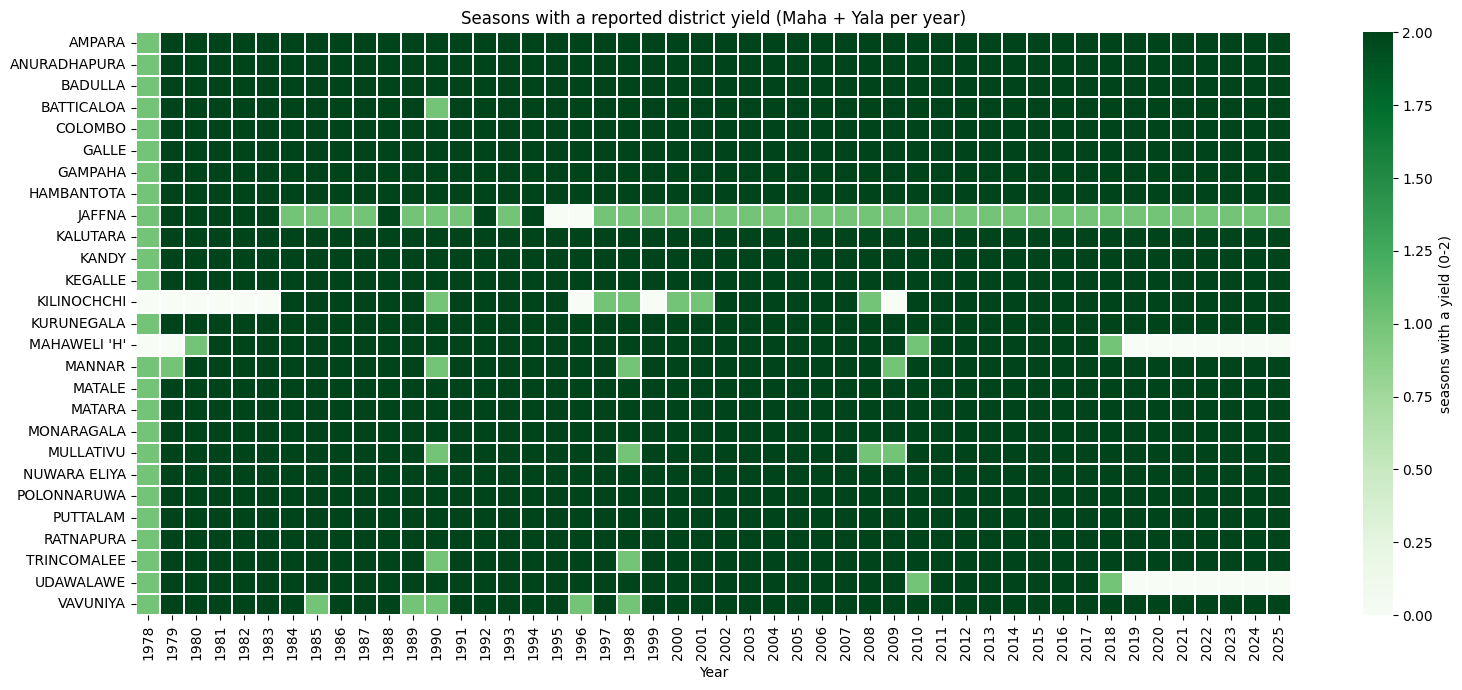

In [40]:
yield_total = paddy_long[(paddy_long.measure == "yield") & (paddy_long.irrigation == "Total")]
coverage = yield_total.assign(has=yield_total["value"].notna()).pivot_table(index="district", columns="year", values="has", aggfunc="sum")

plt.figure(figsize=(16, 7))
sns.heatmap(coverage, cmap="Greens", cbar_kws={"label": "seasons with a yield (0-2)"}, linewidths=0.1)
plt.title("Seasons with a reported district yield (Maha + Yala per year)")
plt.xlabel("Year")
plt.ylabel("")
plt.tight_layout()
plt.show()

The gaps are not random and follow Sri Lankan history.

- Jaffna reports one season a year from 1984 (dark green = both seasons, light = one) and nothing in 1995-1996, the years of heaviest fighting on the peninsula. Its paddy is mostly rainfed and grown in Maha only.
- Kilinochchi has no data before 1984, when it became a district, and several gaps up to 2009, the end of the war.
- Mahaweli 'H' and Udawalawe stop after 2018, presumably reported within their parent districts thereafter (the tables do not state this), so the units end rather than having gaps.

Missing seasons thus mean "no survey that season". They are excluded rather than filled, since an invented war-year yield would be worse than no row.

How the missing values are handled is summarised below, with the section where each step is applied.

1. A missing yield, the target, is never filled. Those district-seasons are excluded from modelling (7.4), because a model cannot learn from or be evaluated on an answer that was never recorded, and an invented war-year yield would mislead it. The 21 zero yields join this group once they are set to missing (6.4).
2. For every model built with the preprocessing pipeline (Ridge, the decision tree, bagging, Random Forest, XGBoost, LightGBM, stacking, the ARIMA hybrid, the Ridge part of the Ridge and CatBoost blend, NGBoost, the Gaussian Process, Extra Trees, Histogram Gradient Boosting, Huber regression and the two published methods), a missing input is filled with the median of that column in the training seasons (9.3). The median is used rather than the mean because several inputs are skewed (7.5). The imputer is fitted inside the pipeline on the training rows of each fold only, so no information from later years leaks in (9.4). The main gaps are the early irrigation breakdown, the ARIMA forecast for districts with fewer than 8 earlier seasons, and solar radiation before 1984.
3. CatBoost and the Explainable Boosting Machine are not given imputed inputs. They receive the columns directly and handle missing values themselves, and the EBM learns a separate contribution for a missing value of each feature. The deployed EBM therefore never substitutes a median, in the notebook, the saved model, the API or the app.
4. A history feature that depends on a missing season is itself missing and is filled as in step 2. The three-season average uses the earlier seasons that exist, and a district-season with fewer than two earlier same-season yields is not modelled (7.4).

### <b>6.2 Duplicate Records</b>

In [41]:
print("Duplicate (district, season, year) rows", panel.duplicated(["district", "season", "year"]).sum())
print("Fully duplicate rows", panel.duplicated().sum())
print("Duplicate entries in the long table", paddy_long.duplicated(["measure", "season", "district", "year", "irrigation"]).sum())

Duplicate (district, season, year) rows 0
Fully duplicate rows 0
Duplicate entries in the long table 0


No duplicates were found. This is significant because, without the correction to the "2000/2021" label in 4.4, the 2000/01 season would have appeared twice for every unit.

### <b>6.3 Inconsistent Data</b>

District, season and irrigation labels were standardised in Section 4 for the joins. They are re-checked here on the final table, column by column.

In [42]:
print("Units", panel["district"].nunique())
print(panel["season"].value_counts().to_string())

Units 27
season
Maha    1265
Yala    1203


In [43]:
panel["year"].value_counts().sort_index().to_frame().T

year,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
count,26,50,52,53,53,52,53,53,53,53,54,52,47,53,54,53,54,53,50,52,52,52,52,52,53,53,54,54,54,53,53,50,51,53,53,53,53,53,53,53,51,49,49,49,49,49,49,49


1978 has only a Maha season (26 rows), and later years have 47-54. The count varies as units start (Kilinochchi in 1984) and stop (Mahaweli 'H' and Udawalawe after 2018), and with the war-year gaps (see 6.1). No year has only a few rows or more than 2 x 27.

The more important inconsistencies lie between tables describing the same seasons. Five checks follow.

Check 1 tests whether production = harvested extent x yield, which also confirms each table's units.

In [44]:
ratio = (panel["harvested_ha"] * panel["yield_kg_ha"] / 1e6) / panel["production"]
ratio = ratio.replace([np.inf, -np.inf], np.nan).dropna()
print("harvested x yield / production")
print(ratio.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(3).to_string())

harvested x yield / production
count    2408.000
mean        1.357
std         1.292
min         0.000
5%          0.520
25%         1.060
50%         1.131
75%         1.238
95%         2.236
max        16.534


For the middle half of rows the ratio lies between 1.06 and 1.24, so harvested x yield exceeds published production by about 13%. Yet it spans 0.52 to 2.24 within the central 90%, and reaches 16 at the extreme, so production is not a consistent product of the other two.

It may use a different extent definition (net versus gross harvested area) in some years, or different units in places. The yield and extent tables agree with each other and with the DCS method description, so they are used. Production is computed from the target and would leak it in any case.

Check 2 compares harvested with sown extent, as a district cannot harvest more than it sowed.

In [45]:
check_cols = ["district", "season", "year", "yield_kg_ha", "sown_ha", "harvested_ha"]
harvest_share = panel["harvested_ha"] / panel["sown_ha"]
print(harvest_share.describe(percentiles=[0.01, 0.05, 0.5, 0.95]).round(3).to_string())
panel.loc[(harvest_share > 1) | (harvest_share < 0.3), check_cols].assign(harvested_share=harvest_share.round(2))

count    2451.000
mean        0.956
std         0.098
min         0.131
1%          0.491
5%          0.792
50%         0.989
95%         1.000
max         1.872


,district,season,year,yield_kg_ha,sown_ha,harvested_ha,harvested_share
17,AMPARA,Yala,1987,4280.0,45785.38,45869.0,1.00
348,BATTICALOA,Maha,2010,2399.0,59520.00,14424.0,0.24
784,JAFFNA,Maha,1995,NaN,6182.00,850.0,0.14
805,JAFFNA,Maha,2013,1547.0,10180.00,2624.0,0.26
808,JAFFNA,Maha,2016,2021.0,10049.00,1830.0,0.18
1305,MAHAWELI 'H',Yala,1994,3307.0,9202.56,9203.0,1.00
1340,MAHAWELI 'H',Yala,2012,5316.0,12533.00,2172.0,0.17
1372,MANNAR,Maha,1988,3423.0,6971.00,1978.0,0.28
1701,MONARAGALA,Maha,2011,4258.0,31985.00,31986.0,1.00
2014,PUTTALAM,Yala,1979,1493.0,2038.00,513.0,0.25


Nearly all sown land is normally harvested (median 99%, and 95% of district-seasons harvest at least 79%).

- Puttalam, Maha 1983/84 reports 19,763 ha harvested from 10,559 ha sown, which is impossible, so its harvested extent is set to missing. The few other values above 1.00 exceed sowing by 1-2 ha, which is rounding.
- The very low values are genuine losses. Batticaloa Maha 2010/11 (24% harvested) matches the January-February 2011 eastern floods, also extreme in the weather check in 6.4. Jaffna Maha 2013/14 and 2016/17 and Mahaweli 'H' Yala 2012 were droughts with insufficient water for all planted land, and Jaffna and Vavuniya Maha 1995/96 fell during the fighting. These are kept.

Harvested extent is not a model input, as it would leak the result (see 7.4), but it is kept correct in the saved dataset.

In [46]:
panel.loc[harvest_share > 1.05, "harvested_ha"] = np.nan
print("Harvested extents set to missing", (harvest_share > 1.05).sum())
print("Rows still harvesting more than 5% over the sown extent", (panel.harvested_ha / panel.sown_ha > 1.05).sum())

Harvested extents set to missing 1
Rows still harvesting more than 5% over the sown extent 0


Check 3 tests whether major + minor + rainfed sum to the total sown extent.

In [47]:
parts_sum = panel[["sown_major", "sown_minor", "sown_rainfed"]].sum(axis=1, min_count=1)
parts_gap = (parts_sum / panel["sown_ha"] - 1).abs()
print("Rows with a breakdown", parts_gap.notna().sum(), "| off from the total by more than 2%:", (parts_gap > 0.02).sum())
panel.loc[parts_gap > 0.02, ["district", "season", "year", "sown_ha", "sown_major", "sown_minor", "sown_rainfed"]].assign(parts_total=parts_sum)

Rows with a breakdown 2178 | off from the total by more than 2%: 2


,district,season,year,sown_ha,sown_major,sown_minor,sown_rainfed,parts_total
781,JAFFNA,Maha,1993,9132.0,NaN,NaN,932.0,932.0
1373,MANNAR,Yala,1989,13.0,8.0,1.0,3.0,12.0


Only 2 of 2,178 district-seasons do not add up.

- Jaffna, Maha 1993/94. Only the rainfed part is filled (932 ha) against a total of 9,132 ha. As Jaffna is almost entirely rainfed, a dropped digit is likely but unprovable.
- Mannar, Yala 1989. The parts sum to 12 ha against 13 ha, a rounding difference.

Rather than estimating the correct values, irrigation shares deviating by more than 5% are set to missing for the pipeline to fill.

In [48]:
panel.loc[parts_gap > 0.05, ["share_major", "share_minor", "share_rainfed"]] = np.nan
print("Rows where the shares come from a breakdown more than 5% off the total", (panel[["share_major"]].notna().squeeze() & (parts_gap > 0.05)).sum())

Rows where the shares come from a breakdown more than 5% off the total 0


Check 4 tests physical plausibility. Minimum temperature cannot exceed the mean, nor the mean the maximum. Humidity must lie between 0 and 100%, and rainfall and wind cannot be negative.

In [49]:
weather_checks = pd.Series({
    "tmin above tmean": (weather_monthly.tmin > weather_monthly.tmean).sum(),
    "tmean above tmax": (weather_monthly.tmean > weather_monthly.tmax).sum(),
    "humidity outside 0-100%": (weather_monthly.rh.notna() & ~weather_monthly.rh.between(0, 100)).sum(),
    "negative rainfall": (weather_monthly.rain_mm < 0).sum(),
    "negative wind": (weather_monthly.wind < 0).sum(),
}, name="months failing")
weather_checks

tmin above tmean           0
tmean above tmax           0
humidity outside 0-100%    0
negative rainfall          0
negative wind              0
Name: months failing, dtype: int64

None fail, so NASA POWER is internally consistent.

Check 5 tests whether every unit has its own weather.

In [50]:
# NASA POWER is a grid product, so units close together may fall into the same grid cell
rain_series = weather_monthly.pivot_table(index="date", columns="district", values="rain_mm")
fingerprint = rain_series.round(2).T.apply(tuple, axis=1)
same_cell = fingerprint.groupby(fingerprint).apply(lambda s: sorted(s.index)).tolist()
print("Different NASA POWER series", len(same_cell), "for", rain_series.shape[1], "production units")
for group in same_cell:
    if len(group) > 1:
        print("  identical weather", ", ".join(group))

chirps_series = chirps.pivot_table(index="date", columns="district", values="rain_mm")
print("\nDifferent CHIRPS series", chirps_series.round(2).T.apply(tuple, axis=1).nunique(), "for", chirps_series.shape[1], "production units")
nasa_monthly = rain_series.loc["1981-01-01":"2025-12-01"]
chirps_monthly = chirps_series.resample("MS").sum().loc["1981-01-01":"2025-12-01"]
agreement = pd.Series({d: nasa_monthly[d].corr(chirps_monthly[d]) for d in chirps_monthly.columns}).sort_values()
print("Correlation between NASA POWER and CHIRPS monthly rainfall, by unit median", round(agreement.median(), 2),
      "| lowest", agreement.index[0], round(agreement.iloc[0], 2), "| highest", agreement.index[-1], round(agreement.iloc[-1], 2))

Different NASA POWER series 19 for 27 production units
  identical weather JAFFNA, KILINOCHCHI
  identical weather BADULLA, MONARAGALA
  identical weather BATTICALOA, POLONNARUWA
  identical weather RATNAPURA, UDAWALAWE
  identical weather KANDY, KEGALLE, NUWARA ELIYA
  identical weather MAHAWELI 'H', PUTTALAM
  identical weather COLOMBO, GAMPAHA

Different CHIRPS series 27 for 27 production units
Correlation between NASA POWER and CHIRPS monthly rainfall, by unit median 0.82 | lowest KEGALLE 0.71 | highest MANNAR 0.88


NASA POWER provides only 19 distinct series for the 27 production units. As a gridded product (about half a degree, roughly 50 km), it gives identical values to units in the same cell, such as Kandy, Kegalle and Nuwara Eliya, or Batticaloa and Polonnaruwa.

It therefore cannot separate districts sharing a cell, even with different climates. Nuwara Eliya, at almost 1,900 m, shares Kegalle's series.

This is why rainfall comes from CHIRPS (3.4), which, averaged over district boundaries, gives 27 distinct series for 27 units. The sources still agree on timing (median monthly rainfall correlation 0.82, lowest in hilly Kegalle at 0.71), a useful consistency check.

Temperature, humidity, solar radiation and wind are nevertheless taken from NASA POWER, since they vary far more smoothly in space than rainfall.

### <b>6.4 Outlier Detection</b>

The standard IQR method is applied to the target first. The IQR (interquartile range) is the spread of the middle half of the values, and values more than 1.5 times the IQR below the 25th or above the 75th percentile are outliers.

In [51]:
q1, q3 = panel["yield_kg_ha"].quantile(0.25), panel["yield_kg_ha"].quantile(0.75)
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_rows = panel[(panel["yield_kg_ha"] < lower_bound) | (panel["yield_kg_ha"] > upper_bound)]

print(f"IQR bounds for yield [{lower_bound:.0f}, {upper_bound:.0f}] kg/ha")
print(f"Outlier rows {len(outlier_rows)} / {panel.yield_kg_ha.notna().sum()} ({100 * len(outlier_rows) / panel.yield_kg_ha.notna().sum():.1f}%)")
print("Below the lower bound", (panel["yield_kg_ha"] < lower_bound).sum(), "| above the upper bound", (panel["yield_kg_ha"] > upper_bound).sum())
print("Values below the lower bound", sorted(panel.loc[panel["yield_kg_ha"] < lower_bound, "yield_kg_ha"].unique()))
print("Above the upper bound, by unit", ", ".join(f"{k} {v}" for k, v in panel.loc[panel["yield_kg_ha"] > upper_bound, "district"].value_counts().items()))
print("Above the upper bound, by year", ", ".join(f"{k} {v}" for k, v in panel.loc[panel["yield_kg_ha"] > upper_bound, "year"].value_counts().sort_index().items()))

IQR bounds for yield [1036, 6136] kg/ha
Outlier rows 43 / 2449 (1.8%)
Below the lower bound 21 | above the upper bound 22
Values below the lower bound [np.float64(0.0)]
Above the upper bound, by unit UDAWALAWE 13, HAMBANTOTA 5, MAHAWELI 'H' 4
Above the upper bound, by year 2008 2, 2009 2, 2010 1, 2011 3, 2012 2, 2013 1, 2014 3, 2015 1, 2016 1, 2017 1, 2018 3, 2019 1, 2025 1


The IQR range for yield is 1,036 to 6,136 kg/ha, and 43 rows (1.8%) fall outside it in two distinct groups.

- 21 rows fall below, every one exactly 0, with nothing between 1 and 1,036. They are not a tail of low yields but a separate group of impossible values, examined below.
- 22 rows fall above, all in Udawalawe (13), Hambantota (5) and Mahaweli 'H' (4) from 2008 onwards. These are the best irrigated rice areas in their best recent years, so they are genuine and kept. Removing them would teach the model that yields above about 6,100 kg/ha are impossible, though they now occur regularly there.

In [52]:
print("Yields of exactly 0", (panel.yield_kg_ha == 0).sum())
print("  ...of these, with land actually harvested", ((panel.yield_kg_ha == 0) & (panel.harvested_ha > 0)).sum())
panel.loc[panel.yield_kg_ha == 0, check_cols].sort_values(["year", "season", "district"])

Yields of exactly 0 21
  ...of these, with land actually harvested 16


,district,season,year,yield_kg_ha,sown_ha,harvested_ha
2217,TRINCOMALEE,Maha,1985,0.0,16586.00,16010.0
774,JAFFNA,Yala,1988,0.0,NaN,NaN
23,AMPARA,Yala,1990,0.0,47492.00,37270.0
308,BATTICALOA,Yala,1990,0.0,14400.00,13956.0
777,JAFFNA,Yala,1990,0.0,NaN,NaN
1120,KILINOCHCHI,Yala,1990,0.0,175.00,172.0
1375,MANNAR,Yala,1990,0.0,12.00,11.0
1753,MULLATIVU,Yala,1990,0.0,245.00,236.0
2226,TRINCOMALEE,Yala,1990,0.0,4000.00,3529.0
2398,VAVUNIYA,Yala,1990,0.0,NaN,NaN


No yields lie between 1 and 1,000 kg/ha, yet 21 are exactly 0, which cannot be real harvests. In 16 the same table records harvested land, up to 37,270 ha in Ampara in Yala 1990. A district harvesting 37,000 ha cannot have produced nothing, and total crop failure would show as zero extent, not zero yield.

20 of the 21 are Yala seasons in 1988-1994 in the Northern and Eastern provinces, eight in Yala 1990 alone, when the second phase of the war broke out (June 1990). The other is Trincomalee, Maha 1985/86, also a period of heavy fighting there.

The most probable explanation is that the crop-cutting survey could not be conducted and 0 was entered instead of "-".

Retained, these zeros would teach the model that a season can produce nothing. They would also depress the lag and three-season-average features of later seasons and the national average yield. They are set to missing.

In [53]:
zero_yield = panel["yield_kg_ha"] == 0
panel.loc[zero_yield, "yield_kg_ha"] = np.nan
print(zero_yield.sum(), "zero yields set to missing")
print("Zero yields left", (panel.yield_kg_ha == 0).sum(), "| lowest yield now", panel.yield_kg_ha.min(), "kg/ha")

21 zero yields set to missing
Zero yields left 0 | lowest yield now 1153.0 kg/ha


A single IQR range across all units is, however, a coarse criterion. A normal Polonnaruwa yield would be extreme for Jaffna, and a normal 1985 yield would be low by current standards.

A local check is therefore added. Each yield is compared with the median of the seven surrounding seasons (same unit, same season), and deviations over 40% are listed.

In [54]:
local_median = panel.groupby(["district", "season"])["yield_kg_ha"].transform(lambda s: s.rolling(7, center=True, min_periods=4).median())
change = panel["yield_kg_ha"] / local_median - 1
unusual = panel.loc[change.abs() > 0.4, check_cols].assign(local_median=local_median.round(), change_pct=(change * 100).round())
print(len(unusual), "district-seasons more than 40% away from the seasons around them")
unusual.sort_values(["year", "district"])

21 district-seasons more than 40% away from the seasons around them


,district,season,year,yield_kg_ha,sown_ha,harvested_ha,local_median,change_pct
1353,MANNAR,Maha,1978,4603.0,15612.0,13856.0,3280.0,40.0
1358,MANNAR,Maha,1981,1956.0,16024.0,10266.0,3781.0,-48.0
766,JAFFNA,Yala,1982,4853.0,7132.0,7132.0,3418.0,42.0
767,JAFFNA,Maha,1982,2672.0,31876.0,29936.0,1792.0,49.0
1359,MANNAR,Yala,1982,1836.0,112.0,96.0,3354.0,-45.0
1283,MAHAWELI 'H',Yala,1983,4173.0,3917.0,3856.0,2970.0,41.0
1361,MANNAR,Yala,1983,4297.0,238.0,210.0,3058.0,41.0
1740,MULLATIVU,Maha,1983,1153.0,13709.0,7544.0,2498.0,-54.0
303,BATTICALOA,Maha,1987,1703.0,29664.0,11381.0,3037.0,-44.0
2406,VAVUNIYA,Maha,1994,4012.0,8003.0,7972.0,2423.0,66.0


After removing the zeros, 21 district-seasons deviate by more than 40% from their neighbours. Each was checked and falls into the groups below.

- War years in the north and east (Mannar 1978-1983, Jaffna 1982, Mullaitivu 1983, Batticaloa 1987, Vavuniya 1994), with displacement and disrupted farming. Several have very small Yala extents (Mannar Yala 1982 had 112 ha).
- The 2010/11 floods affected Trincomalee Maha 2010/11 (-45%).
- The 2021/22 fertilizer ban affected Batticaloa (-47%) and Mannar (-44%).
- Post-war recovery in the north (Mullaitivu Maha 2009/10, Jaffna Maha 2001/02 and 2002/03 during the ceasefire, Jaffna Maha 2018/19 and 2019/20).
- Mannar Yala (2013, 2017, 2024) is a small, irregular season in a mainly Maha district.

All are kept, as each matches a known event or cannot be shown to be incorrect, and no other table contradicts them. Removing genuine extremes would overstate model performance, and these are the seasons of greatest concern to a decision maker.

Rainfall is treated likewise, comparing each month's CHIRPS rainfall with the unit's average for that month.

In [55]:
rain_month_long = chirps_monthly.stack().rename("rain_mm").reset_index()
rain_month_long["month"] = rain_month_long["date"].dt.month
rain_z = rain_month_long.groupby(["district", "month"])["rain_mm"].transform(lambda s: (s - s.mean()) / s.std())
print("Months with rainfall more than 4 standard deviations above that unit's normal for the month", (rain_z > 4).sum())
rain_month_long.loc[rain_z > 4, ["district", "date", "rain_mm"]].assign(sd_above=rain_z[rain_z > 4].round(1)).sort_values(["date", "district"])

Months with rainfall more than 4 standard deviations above that unit's normal for the month 38


,district,date,rain_mm,sd_above
1000,ANURADHAPURA,1984-02-01,264.507,4.1
1001,BADULLA,1984-02-01,538.133,4.2
1007,JAFFNA,1984-02-01,175.880,4.3
1009,KANDY,1984-02-01,553.266,4.2
1012,KURUNEGALA,1984-02-01,319.204,4.2
1013,MAHAWELI 'H',1984-02-01,234.279,4.3
1014,MANNAR,1984-02-01,239.594,4.3
1015,MATALE,1984-02-01,533.953,4.1
1019,NUWARA ELIYA,1984-02-01,520.686,4.3
1021,PUTTALAM,1984-02-01,229.659,4.5


38 months have CHIRPS rainfall more than 4 standard deviations above the unit's monthly normal. Most cluster across neighbouring units in the same month, as real weather events do, whereas a local error would not.

Examples are February 1984 in the centre and north, March 2008 in the west and north, May 2016 (Cyclone Roanu, hitting Batticaloa, Polonnaruwa, Trincomalee and Gampaha) and May-June 2023 in the north.

A few are small amounts in normally dry months, such as 3 mm in Jaffna in July 2020, which is extreme in standard deviations. All are kept, as the model should learn from extreme rainfall.

Very small extents are examined last. They are not errors, but yields measured on small areas are unreliable.

In [56]:
small = panel[(panel.sown_ha < 100) & panel.yield_kg_ha.notna()]
print(len(small), "district-seasons where the yield comes from less than 100 ha of paddy")
small[check_cols]

6 district-seasons where the yield comes from less than 100 ha of paddy


,district,season,year,yield_kg_ha,sown_ha,harvested_ha
1369,MANNAR,Yala,1987,3379.0,72.44,51.0
1373,MANNAR,Yala,1989,2616.0,13.00,11.0
1376,MANNAR,Yala,1991,2964.0,12.00,11.0
1406,MANNAR,Yala,2006,4067.0,48.00,48.0
2393,VAVUNIYA,Yala,1987,3609.0,78.91,72.0
2410,VAVUNIYA,Yala,1997,2836.0,65.00,55.0


Six district-seasons (Yala in Mannar and Vavuniya) have yields measured on under 100 ha, down to 12 ha. A 12 ha yield rests on very few crop cuts yet would weigh as much in training as Polonnaruwa's 60,000 ha. They remain as history for the lag features but are excluded from training and test rows (7.4).

### <b>6.5 Data Type Conversion</b>

In [57]:
print(panel.dtypes.value_counts().to_string())
print("\nNon-numeric columns", panel.select_dtypes(exclude=[np.number]).columns.tolist())
print("year is a whole number everywhere", (panel["year"] == panel["year"].round()).all(), "| type", panel["year"].dtype)
print("Measures stored as text", [c for c in ["yield_kg_ha", "sown_ha", "harvested_ha", "production"] if panel[c].dtype == object] or "none")

float64    30
object      2
int64       1

Non-numeric columns ['district', 'season']
year is a whole number everywhere True | type int64
Measures stored as text none


No conversion is needed. The "-" entries became NaN in 4.5 before the pivot, so the measures are numeric, and the year column was built as an integer from the season label in 4.4.

The measures stay floats because integer columns cannot hold NaN. District and season remain plain text rather than pandas categories, since the one-hot encoder accepts either and CatBoost (Section 12) reads raw text labels.

## <center><b>7. Feature Engineering</b></center>

### <b>7.1 History and Candidate Features</b>

A district's recent history is usually the strongest signal of its yield. These features are built only after 6.4, since a war-year zero would otherwise have propagated into the lag and average of the next three seasons. All use past information only.

- yield_same_season_lag1 is the same season last year (Maha follows Maha).
- yield_same_season_roll3 is the average of the last three same seasons.
- yield_prev_season is the preceding season (a Yala for a Maha and vice versa).
- national_prev_season is the area-weighted national yield of the previous season, capturing country-wide shocks such as input shortages.
- sown_vs_prev3 compares sown extent with the previous three same seasons. Farmers plant less when expecting a poor season (for example when tanks are low), and this is known at planting.

In [58]:
def national_yield(frame):
    # area-weighted national yield, in which each district is weighted by the extent it planted
    ok = frame.dropna(subset=["yield_kg_ha", "sown_ha"])
    return ok.groupby(["season", "year"]).apply(lambda g: np.average(g.yield_kg_ha, weights=g.sown_ha)).rename("national_yield").reset_index()


panel = panel.sort_values(["district", "t"]).reset_index(drop=True)
same = panel.groupby(["district", "season"])
panel["yield_same_season_lag1"] = same["yield_kg_ha"].shift(1)
panel["yield_same_season_roll3"] = same["yield_kg_ha"].transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
panel["yield_prev_season"] = panel.groupby("district")["yield_kg_ha"].shift(1)
panel["sown_vs_prev3"] = panel["sown_ha"] / same["sown_ha"].transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())

nat_t = national_yield(panel).assign(t=lambda d: np.where(d.season == "Maha", d.year + 0.75, d.year + 0.25)).sort_values("t")
nat_t["national_prev_season"] = nat_t["national_yield"].shift(1)
panel = panel.merge(nat_t[["t", "national_prev_season"]], on="t", how="left")

# check against the source, for Polonnaruwa Maha 2021/22 the previous same season is Maha 2020/21 (5,220 in the DCS table)
check = panel.query("district == 'POLONNARUWA' and season == 'Maha' and year == 2021").iloc[0]
earlier = panel.query("district == 'POLONNARUWA' and season == 'Maha' and year in [2018, 2019, 2020]")["yield_kg_ha"]
print("Polonnaruwa Maha 2021/22 | lag1", check.yield_same_season_lag1, "| roll3", round(check.yield_same_season_roll3, 1),
      "| mean of Maha 2018/19-2020/21 from the table", round(earlier.mean(), 1))

Polonnaruwa Maha 2021/22 | lag1 5220.0 | roll3 5233.0 | mean of Maha 2018/19-2020/21 from the table 5233.0


The lag and three-season average match values read from the table, so the shift is correctly directed and excludes the current season.

Following the lecture's suggestion of combining ARIMA with Random Forest, each unit's yield series (one per season) receives an ARIMA(1,1,1) forecast for the next season. It is fitted only on earlier seasons (an expanding window from 8 past seasons), so the tree models can combine "what the trend says" with the season's weather.

ARIMA(1,1,1) is used throughout. One difference removes the long-term upward trend, and one AR (autoregressive) and one MA (moving average) term suit such short series (about 45 points each), where larger models would overfit.

In [59]:
def arima_expanding_forecasts(series, order=(1, 1, 1), min_history=8):
    # one-step forecast for each season, from the seasons before it only
    values = series.values
    out = np.full(len(values), np.nan)
    for k in range(min_history, len(values)):
        history = values[:k][~np.isnan(values[:k])]
        if len(history) < min_history:
            continue
        try:
            out[k] = ARIMA(history, order=order).fit().forecast(1)[0]
        except Exception:
            pass
    return pd.Series(out, index=series.index)


start = time.time()
panel["arima_forecast"] = panel.groupby(["district", "season"], group_keys=False)["yield_kg_ha"].apply(arima_expanding_forecasts)
print(f"ARIMA forecasts done in {time.time() - start:.0f}s; available for {panel['arima_forecast'].notna().sum()} district-seasons")

ARIMA forecasts done in 34s; available for 2023 district-seasons


Fertilizer supply follows. Nitrogen (urea) is the nutrient paddy needs most and the one in short supply in 2021. FAOSTAT offers "Agricultural Use" and "Import quantity", and as Sri Lanka produces no nitrogen fertilizer, imports approximate supply. Both are examined with FAOSTAT's quality flags.

In [60]:
nitrogen = fertilizer_raw[fertilizer_raw.Item == "Nutrient nitrogen N (total)"]
values = nitrogen[nitrogen.Element.isin(["Agricultural Use", "Import quantity", "Production"])].pivot_table(index="Year", columns="Element", values="Value")
flags = nitrogen[nitrogen.Element.isin(["Agricultural Use", "Import quantity"])].pivot_table(index="Year", columns="Element", values="Flag", aggfunc="first")
values.join(flags, rsuffix=" flag").loc[2014:]

Element,Agricultural Use,Import quantity,Production,Agricultural Use flag,Import quantity flag
Year,,,,,
2014,227848.0,227763.0,0.0,I,E
2015,150059.0,225495.0,0.0,I,E
2016,117776.0,117637.0,0.0,I,E
2017,109729.0,109750.0,0.0,I,E
2018,68829.0,150451.0,0.0,I,I
2019,143689.0,191152.0,0.0,I,E
2020,239288.0,273475.0,0.0,I,E
2021,119230.0,90526.0,0.0,I,E
2022,119230.0,125606.0,0.0,I,E


The series diverge, and the flags explain why. Agricultural Use is flagged "I" (imputed by FAO) throughout and repeats 119,230 t for 2021, 2022 and 2023, an estimate carried forward that cannot be used.

Import quantity is flagged "E" (estimated, but from trade records) and shows the ban distinctly, from 273,475 t in 2020 to 90,526 t in 2021, then a slow recovery (125,606 t in 2022, 165,669 t in 2023). Production is zero every year, as expected. Imports are used.

In [61]:
n_imports = nitrogen[nitrogen.Element == "Import quantity"].set_index("Year")["Value"].sort_index()
print("Consecutive years with no gaps", (n_imports.index.to_series().diff().dropna() == 1).all())
# this year's nitrogen imports compared with the average of the three years before
n_ratio = n_imports / n_imports.shift(1).rolling(3).mean()

# Maha (planted from October) uses the same year's imports, and Yala (planted from April) mainly the previous year's
panel["fertilizer_year"] = np.where(panel["season"] == "Maha", panel["year"], panel["year"] - 1)
panel["nitrogen_import_ratio"] = panel["fertilizer_year"].map(n_ratio)

print(n_ratio.loc[2015:].round(2).to_string())
print("\nMaha 2021/22 gets", round(n_ratio[2021], 2), "| Yala 2021 gets", round(n_ratio[2020], 2), "| Yala 2022 gets", round(n_ratio[2021], 2))
print("Seasons without a value", panel.loc[panel.year >= 1981, "nitrogen_import_ratio"].isna().sum(), "->",
      panel.loc[(panel.year >= 1981) & panel.nitrogen_import_ratio.isna(), ["season", "year"]].drop_duplicates().values.tolist())

Consecutive years with no gaps True
Year
2015    1.30
2016    0.61
2017    0.58
2018    1.00
2019    1.52
2020    1.82
2021    0.44
2022    0.68
2023    1.02
2024    1.10

Maha 2021/22 gets 0.44 | Yala 2021 gets 1.82 | Yala 2022 gets 0.44
Seasons without a value 25 -> [['Maha', 2025]]


Maha 2021/22 and Yala 2022 both receive 0.44, the lowest since 1983, while Yala 2021, planted before the ban, receives 1.82. Only Maha 2025/26 lacks a value, as FAOSTAT has no 2025 imports yet, and it is filled with the training median in the pipeline.

Neighbouring districts are considered next. Some shocks are regional, such as pest outbreaks (for example brown planthopper), low shared reservoirs or cyclones, so poor results in the three nearest units may be informative.

The feature averages, over the three nearest units, last season's yield relative to their own three-season average (1.0 = normal). Only completed seasons are used, so it is known at prediction time.

In [62]:
from math import radians, sin, cos, sqrt, atan2


def haversine_km(a, b):
    lat1, lon1, lat2, lon2 = map(radians, [a[0], a[1], b[0], b[1]])
    h = sin((lat2 - lat1) / 2) ** 2 + cos(lat1) * cos(lat2) * sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * atan2(sqrt(h), sqrt(1 - h))


points = {c.district: (c.latitude, c.longitude) for c in coords.itertuples()}
nearest = {d: sorted([o for o in points if o != d], key=lambda o: haversine_km(points[d], points[o]))[:3] for d in points}

season_ratio = (panel["yield_kg_ha"] / panel["yield_same_season_roll3"]).values
ratio_at = dict(zip(zip(panel.district, panel.t), season_ratio))
panel["neighbours_prev_ratio"] = [np.nanmean([ratio_at.get((n, t - 0.5), np.nan) for n in nearest[d]])
                                  if any(pd.notna(ratio_at.get((n, t - 0.5), np.nan)) for n in nearest[d]) else np.nan
                                  for d, t in zip(panel.district, panel.t)]
print("Nearest units, examples", {d: nearest[d] for d in ["POLONNARUWA", "JAFFNA", "KANDY"]})
print("Available for", panel.neighbours_prev_ratio.notna().sum(), "of", len(panel), "district-seasons")

Nearest units, examples {'POLONNARUWA': ['MATALE', 'BATTICALOA', 'TRINCOMALEE'], 'JAFFNA': ['KILINOCHCHI', 'MULLATIVU', 'MANNAR'], 'KANDY': ['NUWARA ELIYA', 'KEGALLE', 'BADULLA']}
Available for 2323 of 2468 district-seasons


Seasonal greenness is measured with NDVI. For each district-season, the feature takes the mean and peak of 16-day NDVI over the main growing months (November-February for Maha, May-August for Yala) and the mean relative to the unit's seasonal normal. The normal uses only seasons before 2017, excluding the test period.

In [63]:
ndvi = ndvi_raw.assign(date=pd.to_datetime(ndvi_raw["calendar_date"]))
ndvi_by_unit = {d: g.set_index("date")["ndvi_p75"].sort_index() for d, g in ndvi.groupby("district")}


def season_ndvi(district, season, year):
    if district not in ndvi_by_unit:
        return np.nan, np.nan
    v = ndvi_by_unit[district]
    v = v[f"{year}-11-01":f"{year + 1}-02-28"] if season == "Maha" else v[f"{year}-05-01":f"{year}-08-31"]
    return (v.mean(), v.max()) if len(v) >= 4 else (np.nan, np.nan)


values = [season_ndvi(d, s, int(y)) for d, s, y in zip(panel.district, panel.season, panel.year)]
panel["ndvi_mean"], panel["ndvi_max"] = [v[0] for v in values], [v[1] for v in values]
ndvi_normal = panel[(panel.t < 2017) & panel.ndvi_mean.notna()].groupby(["district", "season"])["ndvi_mean"].mean().rename("ndvi_normal")
panel = panel.merge(ndvi_normal, on=["district", "season"], how="left")
panel["ndvi_anomaly"] = panel["ndvi_mean"] - panel["ndvi_normal"]
print("NDVI available for", panel.ndvi_mean.notna().sum(), "district-seasons (from Maha 2000/01)")
print("Correlation of the NDVI anomaly with the yield's change from its 3-season average",
      round(panel["ndvi_anomaly"].corr(panel["yield_kg_ha"] / panel["yield_same_season_roll3"]), 3))

NDVI available for 1344 district-seasons (from Maha 2000/01)
Correlation of the NDVI anomaly with the yield's change from its 3-season average 0.049


El Niño and the Indian Ocean Dipole are averaged over the dry-spell months (October-January for Maha, April-July for Yala). The correlations below test whether they track the deviation of yield from the district's three-season average, the part history cannot explain.

In [64]:
centre_month = {s: i + 1 for i, s in enumerate(["DJF", "JFM", "FMA", "MAM", "AMJ", "MJJ", "JJA", "JAS", "ASO", "SON", "OND", "NDJ"])}
oni_series = oni_raw.set_index(pd.to_datetime(dict(year=oni_raw.YR, month=oni_raw.SEAS.map(centre_month), day=1)))["ANOM"]
dmi_valid = dmi_raw[dmi_raw.dmi > -999]
dmi_series = dmi_valid.set_index(pd.to_datetime(dict(year=dmi_valid.year, month=dmi_valid.month, day=1)))["dmi"]


def growing_mean(series, season, year):
    v = series[f"{year}-10-01":f"{year + 1}-01-31"] if season == "Maha" else series[f"{year}-04-01":f"{year}-07-31"]
    return v.mean() if len(v) == 4 else np.nan


panel["enso_index"] = [growing_mean(oni_series, s, int(y)) for s, y in zip(panel.season, panel.year)]
panel["iod_index"] = [growing_mean(dmi_series, s, int(y)) for s, y in zip(panel.season, panel.year)]
yield_vs_average = panel["yield_kg_ha"] / panel["yield_same_season_roll3"]
for s in ["Maha", "Yala"]:
    m = (panel.season == s) & yield_vs_average.notna()
    print(f"{s} correlation with the yield's change from its 3-season average | ENSO {yield_vs_average[m].corr(panel.loc[m, 'enso_index']):.3f}"
          f" | IOD {yield_vs_average[m].corr(panel.loc[m, 'iod_index']):.3f}")
print("Seasons without a value", ", ".join(f"{k} {v}" for k, v in panel.loc[panel.year >= 1981, ["enso_index", "iod_index"]].isna().sum().items()))

Maha correlation with the yield's change from its 3-season average | ENSO 0.154 | IOD 0.058
Yala correlation with the yield's change from its 3-season average | ENSO 0.098 | IOD 0.077
Seasons without a value enso_index 0, iod_index 0


Crop health over the rice fields is next. For each district-season, the feature takes mean VCI and TCI and peak smoothed NDVI over the MODIS months (November-February for Maha, May-August for Yala). Two NOAA district spellings differ, and the irrigation areas take their host district (Mahaweli 'H' in Anuradhapura, Udawalawe in Ratnapura).

If the feature is useful in any season, it should be so in Maha 2021/22, since nitrogen-deficient crops are paler, which NDVI measures.

In [65]:
vh = vh_raw[vh_raw.vhi >= 0].assign(date=lambda d: pd.to_datetime(d.year.astype(str) + "-01-01") + pd.to_timedelta((d.week - 1) * 7, unit="D"))
vh = vh.assign(district=vh.district.replace({"MULLAITIVU": "MULLATIVU", "MONERAGALA": "MONARAGALA"}))
vh_by_unit = {d: g.set_index("date").sort_index() for d, g in vh.groupby("district")}
vh_by_unit["MAHAWELI 'H'"], vh_by_unit["UDAWALAWE"] = vh_by_unit["ANURADHAPURA"], vh_by_unit["RATNAPURA"]
print("DCS units without a match", sorted(set(panel.district) - set(vh_by_unit)))


def season_vh(district, season, year):
    g = vh_by_unit.get(district)
    if g is None:
        return [np.nan] * 3
    w = g[f"{year}-11-01":f"{year + 1}-02-28"] if season == "Maha" else g[f"{year}-05-01":f"{year}-08-31"]
    return [w.vci.mean(), w.tci.mean(), w.smn.max()] if len(w) >= 8 else [np.nan] * 3


values = np.array([season_vh(d, s, int(y)) for d, s, y in zip(panel.district, panel.season, panel.year)])
panel["rice_vci"], panel["rice_tci"], panel["rice_ndvi_peak"] = values[:, 0], values[:, 1], values[:, 2]
for c in ["rice_vci", "rice_tci", "rice_ndvi_peak"]:
    print(f"{c:15s} correlation with the yield's change from its 3-season average {yield_vs_average.corr(panel[c]):.3f}")

recent_maha = panel[(panel.season == "Maha") & panel.year.between(2016, 2024)].dropna(subset=["yield_kg_ha", "yield_same_season_roll3", "rice_ndvi_peak"])
recent_maha.groupby("year").apply(lambda g: pd.Series({
    "yield vs 3-season average": np.average(g.yield_kg_ha / g.yield_same_season_roll3, weights=g.sown_ha),
    "rice NDVI peak": np.average(g.rice_ndvi_peak, weights=g.sown_ha), "rice VCI": np.average(g.rice_vci, weights=g.sown_ha)})).round(3)

DCS units without a match []
rice_vci        correlation with the yield's change from its 3-season average 0.005
rice_tci        correlation with the yield's change from its 3-season average 0.012
rice_ndvi_peak  correlation with the yield's change from its 3-season average 0.021


,yield vs 3-season average,rice NDVI peak,rice VCI
year,,,
2016,0.994,0.418,63.683
2017,1.007,0.394,60.018
2018,1.127,0.400,61.013
2019,1.099,0.408,62.102
2020,0.983,0.389,56.808
2021,0.605,0.400,63.073
2022,0.925,0.395,58.036
2023,1.042,0.398,59.697
2024,1.118,0.386,56.515


Neither index tracks yield deviation from the three-season average (correlations 0.005 to 0.021).

The table shows why the feature fails in the key season. In Maha 2021/22 yield fell to 0.61 of the three-season average, yet peak NDVI was 0.400, within the decade's Maha range (0.386-0.418), and VCI was 63, among the highest.

At 4 km, with a 2010 crop map, the satellite sees green fields but not nitrogen-starved plants filling fewer grains. It is still tested in 10.1 for normal seasons.

Soil moisture and evaporation are summarised by three values per district-season over the crop-health months (November to February for Maha, May to August for Yala).

The first is average soil moisture from 3.9. The second is the lowest 30-day average, capturing dry stretches long enough to stress the crop.

The third is total reference evapotranspiration (ET0), the millimetres of water a well-watered crop would lose over the season. Hot, sunny months draw more water than cool, cloudy ones.

ET0 is computed from the NASA POWER temperature and sunshine in 3.3 with the Hargreaves-Samani formula (Hargreaves and Samani, 1985), a standard UN Food and Agriculture Organization method when only temperature and radiation exist. Monthly ET0 per day = 0.0135 x (mean temperature + 17.8) x solar radiation, with radiation converted from MJ per m² to millimetres of water by multiplying by 0.408.

In [66]:
soil_by_unit = {d: g.set_index("date").sort_index()["soil_moisture"] for d, g in soil_raw.groupby("district")}
wx_by_unit = {d: g.set_index("date").sort_index() for d, g in weather_monthly.groupby("district")}
for g in wx_by_unit.values():
    # Hargreaves-Samani reference evapotranspiration for the month in mm (solar radiation in MJ/m2/day is multiplied by 0.408 to give mm of water)
    g["et0_mm"] = 0.0135 * (g.tmean + 17.8) * g.solar * 0.408 * g.index.days_in_month


def season_water(district, season, year):
    soil, wx = soil_by_unit.get(district), wx_by_unit.get(district)
    if soil is None or wx is None:
        return [np.nan] * 3
    if season == "Maha":
        days, months = soil[f"{year}-11-01":f"{year + 1}-02-28"], wx[f"{year}-11-01":f"{year + 1}-02-01"]
    else:
        days, months = soil[f"{year}-05-01":f"{year}-08-31"], wx[f"{year}-05-01":f"{year}-08-01"]
    if days.notna().sum() < 100 or months.et0_mm.notna().sum() < 4:
        return [np.nan] * 3
    return [days.mean(), days.rolling(30).mean().min(), months.et0_mm.sum()]


values = np.array([season_water(d, s, int(y)) for d, s, y in zip(panel.district, panel.season, panel.year)])
panel["soil_moisture"], panel["soil_moisture_min"], panel["et0_total"] = values[:, 0], values[:, 1], values[:, 2]
for c in ["soil_moisture", "soil_moisture_min", "et0_total"]:
    print(f"{c:18s} correlation with the yield's change from its 3-season average {yield_vs_average.corr(panel[c]):.3f}"
          f" | with season rainfall {panel['rain_season'].corr(panel[c]):.2f}")
print("Seasons without a value (1981 onwards)", ", ".join(f"{k} {v}" for k, v in panel.loc[panel.year >= 1981, ["soil_moisture", "et0_total"]].isna().sum().items()))
print(f"Season ET0, typical range {panel.et0_total.quantile(0.05):.0f} to {panel.et0_total.quantile(0.95):.0f} mm")

# the driest seasons by soil moisture and the change in yield in those seasons
dry = panel[panel.yield_kg_ha.notna() & panel.yield_same_season_roll3.notna()].nsmallest(10, "soil_moisture_min")
dry.assign(yield_vs_average=(dry.yield_kg_ha / dry.yield_same_season_roll3).round(2))[
    ["district", "season", "year", "soil_moisture_min", "rain_season", "yield_vs_average"]].round(3)

soil_moisture      correlation with the yield's change from its 3-season average -0.022 | with season rainfall 0.76
soil_moisture_min  correlation with the yield's change from its 3-season average -0.024 | with season rainfall 0.69
et0_total          correlation with the yield's change from its 3-season average 0.027 | with season rainfall -0.67
Seasons without a value (1981 onwards) soil_moisture 158, et0_total 158
Season ET0, typical range 444 to 656 mm


,district,season,year,soil_moisture_min,rain_season,yield_vs_average
315,BATTICALOA,Yala,1994,0.059,97.477,0.93
331,BATTICALOA,Yala,2002,0.059,151.326,0.96
339,BATTICALOA,Yala,2006,0.059,113.735,1.07
345,BATTICALOA,Yala,2009,0.059,185.969,1.11
351,BATTICALOA,Yala,2012,0.059,159.552,0.97
355,BATTICALOA,Yala,2014,0.059,163.825,0.99
377,BATTICALOA,Yala,2025,0.059,223.491,1.41
373,BATTICALOA,Yala,2023,0.059,228.665,0.87
302,BATTICALOA,Yala,1987,0.059,95.583,0.91
313,BATTICALOA,Yala,1993,0.059,139.082,1.43


Several factors that matter for paddy lack publicly available district records, namely reservoir storage, fertilizer issued to farmers and pest outbreaks. Radar imagery begins only in 2015, leaving almost no training years.

For two of these the closest measurable stand-in is built, plus one weather feature.

The first is rain_storage, district rainfall in the six months before the season (April to September for Maha, October to March for Yala), which fills the reservoirs irrigated fields draw on. The second is soil_moisture_start, ERA5 soil moisture in the month before planting, showing whether fields started wet or dry.

The third is tmax_hottest_month, the highest monthly mean of daily maximum temperature in the season. Rice flowers are damaged above about 35 °C, so a hot month near flowering can reduce grain yield.

The harvested_share (harvested over sown area) is computed only to show why it must not be used. Published with the yield months after the season, it is unknown when the estimate is needed (7.4), and is tested in 15.1 solely to show the extent to which such a leak inflates scores.

In [67]:
def season_proxies(district, season, year):
    r, w, e = rain_daily.get(district), wx_by_unit.get(district), soil_by_unit.get(district)
    if season == "Maha":
        storage, start, grow = (f"{year}-04-01", f"{year}-09-30"), (f"{year}-09-01", f"{year}-09-30"), (f"{year}-10-01", f"{year + 1}-02-01")
    else:
        storage, start, grow = (f"{year - 1}-10-01", f"{year}-03-31"), (f"{year}-03-01", f"{year}-03-31"), (f"{year}-04-01", f"{year}-08-01")
    rain_storage = r[storage[0]:storage[1]].sum() if r is not None and len(r[storage[0]:storage[1]]) > 170 else np.nan
    soil_start = e[start[0]:start[1]].mean() if e is not None else np.nan
    hottest = w.tmax[grow[0]:grow[1]].max() if w is not None and w.tmax[grow[0]:grow[1]].notna().sum() >= 4 else np.nan
    return [rain_storage, soil_start, hottest]


values = np.array([season_proxies(d, s, int(y)) for d, s, y in zip(panel.district, panel.season, panel.year)])
panel["rain_storage"], panel["soil_moisture_start"], panel["tmax_hottest_month"] = values[:, 0], values[:, 1], values[:, 2]
panel["harvested_share"] = panel["harvested_ha"] / panel["sown_ha"]  # not allowed as an input (see 7.4), only used in 15.1 to show the leak
for c in ["rain_storage", "soil_moisture_start", "tmax_hottest_month", "harvested_share"]:
    print(f"{c:20s} correlation with the yield's change from its 3-season average {yield_vs_average.corr(panel[c]):.3f}")

rain_storage         correlation with the yield's change from its 3-season average -0.034
soil_moisture_start  correlation with the yield's change from its 3-season average -0.059
tmax_hottest_month   correlation with the yield's change from its 3-season average 0.075
harvested_share      correlation with the yield's change from its 3-season average 0.145


The weather features up to this point are season averages. A systematic review of 156 rice yield studies (*Computers and Electronics in Agriculture*) found that the effects of temperature and sunshine differ by crop stage. Cooler nights during grain filling and more sunshine during ripening raise yield, while heat at flowering can prevent grain formation, effects that a season average conceals.

Four stage-specific features are therefore built from existing data, assuming flowering, ripening and harvest in December, January and February for Maha and in June, July and August for Yala. They are the mean daily maximum temperature at flowering (tmax_flowering), the mean night-time minimum at ripening (tmin_ripening), solar radiation at ripening (solar_ripening) and harvest-month rain (rain_harvest_month), since a wet harvest hinders drying and causes losses.

In [68]:
def stage_weather(district, season, year):
    r, w = rain_daily.get(district), wx_by_unit.get(district)
    if r is None or w is None:
        return [np.nan] * 4
    flower, ripen, harvest = (f"{year}-12", f"{year + 1}-01", f"{year + 1}-02") if season == "Maha" else (f"{year}-06", f"{year}-07", f"{year}-08")

    def month_value(col, month):
        v = w[col].loc[month] if month in w.index.strftime("%Y-%m") else []
        return float(v.iloc[0]) if len(v) else np.nan

    rain_month = r.loc[harvest] if harvest in r.index.strftime("%Y-%m") else []
    return [month_value("tmax", flower), month_value("tmin", ripen), month_value("solar", ripen),
            rain_month.sum() if len(rain_month) >= 28 else np.nan]


values = np.array([stage_weather(d, s, int(y)) for d, s, y in zip(panel.district, panel.season, panel.year)])
for k, c in enumerate(["tmax_flowering", "tmin_ripening", "solar_ripening", "rain_harvest_month"]):
    panel[c] = values[:, k]
    print(f"{c:20s} correlation with the yield's change from its 3-season average {yield_vs_average.corr(panel[c]):.3f}"
          f" | missing from 1981 {panel.loc[panel.year >= 1981, c].isna().sum()}")

tmax_flowering       correlation with the yield's change from its 3-season average 0.023 | missing from 1981 0
tmin_ripening        correlation with the yield's change from its 3-season average 0.021 | missing from 1981 0
solar_ripening       correlation with the yield's change from its 3-season average 0.059 | missing from 1981 132
rain_harvest_month   correlation with the yield's change from its 3-season average -0.126 | missing from 1981 0


The fertilizer subsidy has been the principal policy instrument for paddy since 1962 and is well documented. Each season is assigned a support level from the published record.

- Level 0 denotes a ban or shortage. The chemical fertilizer import ban (gazette of 6 May 2021) affected Maha 2021/22, and although it was lifted in November 2021, fertilizer remained scarce and expensive in Yala 2022 during the economic crisis.
- Level 1 denotes no subsidy (1990-1994).
- Level 2 denotes a urea-only subsidy (1997-2004).
- Level 3 denotes that all three nutrients were subsidised. This covers the remaining years, including the Kethata Aruna subsidy from 2005 and the 2016-2018 cash grant that replaced it for four seasons.
- Level 4 denotes free fertilizer for paddy, from mid-2020 (Yala 2020 to Yala 2021).

For 1962-2005 the source is Weerahewa, Kodithuwakku and Ariyawardana, "The Fertilizer Subsidy Program in Sri Lanka", Cornell Food Policy case study 7-11 (2010). For 2016-2021 it is Weerahewa, Senaratne and Babu, "Reforming Fertilizer Import Policies for Sustainable Intensification of Agricultural Systems in Sri Lanka: Is there a Policy Failure?", PRCI Policy Research Note 3 (2021).

Policy is announced before the season, so the level is known at prediction time. A binary version, fertilizer_shortage, marks only the two seasons at level 0.

In [69]:
def fertilizer_support(season, year):
    t = year + (0.75 if season == "Maha" else 0.25)
    if t in (2021.75, 2022.25):
        return 0  # import ban, then the 2022 shortage
    if 2020.25 <= t <= 2021.25:
        return 4  # free fertilizer for paddy
    if 1990 <= t < 1995:
        return 1  # no subsidy
    if 1997 <= t < 2005:
        return 2  # urea only
    return 3      # all three nutrients subsidised (or the equivalent cash grant)


panel["fertilizer_support"] = [fertilizer_support(s, int(y)) for s, y in zip(panel.season, panel.year)]
panel["fertilizer_shortage"] = (panel["fertilizer_support"] == 0).astype(int)
panel[panel.year >= 1981].assign(yield_vs_average=yield_vs_average).groupby("fertilizer_support").agg(
    first_season=("t", "min"), last_season=("t", "max"), district_seasons=("t", "size"), yield_vs_3season_average=("yield_vs_average", "mean")).round(3)

,first_season,last_season,district_seasons,yield_vs_3season_average
fertilizer_support,,,,
0,2021.75,2022.25,49,0.688
1,1990.25,1994.75,261,1.007
2,1997.25,2004.75,420,1.036
3,1981.25,2025.75,1537,1.033
4,2020.25,2021.25,73,1.024


All candidates up to this point are numeric, so four categorical features are added to test whether district or season labels improve prediction.

- policy_regime records the fertilizer policy as seven categories rather than the 0 to 4 level. These are full subsidy (to 1989 and 1995-1996), no subsidy (1990-1994), urea only (1997-2004), the Kethata Aruna subsidy (2005 onwards), the cash grant that replaced it for four seasons (Yala 2016 to Maha 2017/18, Weerahewa, Senaratne and Babu, 2021), free fertilizer (Yala 2020 to Yala 2021) and ban or shortage (Maha 2021/22 and Yala 2022).
- province is the province of each district, with Mahaweli 'H' assigned to the North Central and Udawalawe to Sabaragamuwa.
- climate_zone is the predominant climate zone of the paddy land in each district (wet, intermediate or dry), from the Department of Agriculture's agro-ecological map.
- enso_phase labels the growing months as El Niño (index above +0.5), La Niña (below -0.5) or neutral, using the index from 3.7.

Province and climate zone are fixed per district and are therefore implied by the district label. They may nevertheless allow similar districts to share information.

In [70]:
province = {"COLOMBO": "Western", "GAMPAHA": "Western", "KALUTARA": "Western", "KANDY": "Central", "MATALE": "Central", "NUWARA ELIYA": "Central",
            "GALLE": "Southern", "MATARA": "Southern", "HAMBANTOTA": "Southern", "JAFFNA": "Northern", "KILINOCHCHI": "Northern", "MANNAR": "Northern",
            "MULLATIVU": "Northern", "VAVUNIYA": "Northern", "AMPARA": "Eastern", "BATTICALOA": "Eastern", "TRINCOMALEE": "Eastern",
            "KURUNEGALA": "North Western", "PUTTALAM": "North Western", "ANURADHAPURA": "North Central", "POLONNARUWA": "North Central",
            "MAHAWELI 'H'": "North Central", "BADULLA": "Uva", "MONARAGALA": "Uva", "RATNAPURA": "Sabaragamuwa", "KEGALLE": "Sabaragamuwa",
            "UDAWALAWE": "Sabaragamuwa"}
wet_zone = {"COLOMBO", "GAMPAHA", "KALUTARA", "GALLE", "MATARA", "RATNAPURA", "KEGALLE", "NUWARA ELIYA"}
intermediate_zone = {"KANDY", "MATALE", "KURUNEGALA", "BADULLA"}


def policy_regime(season, year):
    t = year + (0.75 if season == "Maha" else 0.25)
    if t in (2021.75, 2022.25):
        return "ban or shortage"
    if 2020.25 <= t <= 2021.25:
        return "free fertilizer"
    if 2016.25 <= t <= 2017.75:
        return "cash grant"
    if t >= 2005:
        return "Kethata Aruna"
    if 1997 <= t < 2005:
        return "urea only"
    if 1990 <= t < 1995:
        return "no subsidy"
    return "full subsidy"


panel["policy_regime"] = [policy_regime(s, int(y)) for s, y in zip(panel.season, panel.year)]
panel["province"] = panel.district.map(province)
panel["climate_zone"] = np.where(panel.district.isin(wet_zone), "wet", np.where(panel.district.isin(intermediate_zone), "intermediate", "dry"))
panel["enso_phase"] = np.select([panel.enso_index > 0.5, panel.enso_index < -0.5], ["El Nino", "La Nina"], "neutral")
qualitative_features = ["policy_regime", "province", "climate_zone", "enso_phase"]
print("Districts without a province", panel.loc[panel.province.isna(), "district"].unique().tolist())
recent = panel[panel.year >= 1981].assign(yield_vs_average=yield_vs_average)
pd.concat({c: recent.groupby(c)["yield_vs_average"].agg(["size", "mean"]) for c in qualitative_features}).round(3).rename(
    columns={"size": "district-seasons", "mean": "yield vs 3-season average"})

Districts without a province []


district-seasons  yield vs 3-season average
policy_regime Kethata Aruna                 852                      1.038
              ban or shortage                49                      0.688
              cash grant                    106                      0.978
              free fertilizer                73                      1.024
              full subsidy                  579                      1.037
              no subsidy                    261                      1.007
              urea only                     420                      1.036
province      Central                       270                      1.016
              Eastern                       268                      1.023
              North Central                 254                      1.027
              North Western                 180                      1.029
              Northern                      394                      1.031
              Sabaragamuwa                  254                      1.022
              Southern                      270                      1.025
              Uva                           180                      1.027
              Western                       270                      1.014
climate_zone  dry                          1260                      1.027
              intermediate                  360                      1.020
              wet                           720                      1.019
enso_phase    El Nino                       655                      1.047
              La Nina                       626                      0.985
              neutral                      1059                      1.032

Seasons under the import ban and shortage averaged 0.69 of their three-season average, the only level substantially different from normal. The no-subsidy years 1990-1994 (1.01) were no worse than full-subsidy years (1.03), and free-fertilizer seasons (1.02) were no better.

The subsidy level therefore had little effect on yields, whereas the physical absence of fertilizer had a large effect. The support level is thus expected to contribute little in 10.1, since the decisive factor, the shortage, occurred in only two seasons, both after 2016.

### <b>7.2 Encoding Categorical Values</b>

The district and season columns are nominal with no natural order, so one-hot encoding is appropriate for the models that require numeric input. Their contents confirm this.

In [71]:
for col in ["district", "season"]:
    print(f"{col} {panel[col].nunique()} categories -> {sorted(panel[col].unique())}")

# Correction applied later. These columns are one-hot encoded inside the Pipeline in Section 9.3, fitted on the training seasons only.
# OneHotEncoder(handle_unknown="ignore")

district 27 categories -> ['AMPARA', 'ANURADHAPURA', 'BADULLA', 'BATTICALOA', 'COLOMBO', 'GALLE', 'GAMPAHA', 'HAMBANTOTA', 'JAFFNA', 'KALUTARA', 'KANDY', 'KEGALLE', 'KILINOCHCHI', 'KURUNEGALA', "MAHAWELI 'H'", 'MANNAR', 'MATALE', 'MATARA', 'MONARAGALA', 'MULLATIVU', 'NUWARA ELIYA', 'POLONNARUWA', 'PUTTALAM', 'RATNAPURA', 'TRINCOMALEE', 'UDAWALAWE', 'VAVUNIYA']
season 2 categories -> ['Maha', 'Yala']


The 27 districts become 27 binary columns, which is a manageable number. CatBoost instead receives the raw text columns and encodes them with ordered target statistics (Section 12).

### <b>7.3 Feature Correlation and Multicollinearity</b>

Before the final feature list is decided (7.4), the candidate numeric features are examined for excessive mutual correlation. Two checks are used, a pairwise correlation matrix and the Variance Inflation Factor (VIF). The VIF detects a feature explained by a combination of others even when no single pair is strongly correlated.

In [72]:
candidate_numeric = [
    "sown_ha", "share_major", "share_minor", "share_rainfed", "sown_vs_prev3",
    "yield_same_season_lag1", "yield_same_season_roll3", "yield_prev_season", "national_prev_season", "arima_forecast",
    "rain_season", "rain_anomaly_pct", "rain_wettest_month", "rain_driest_month", "rain_before", "dry_spell_days", "heavy_rain_days",
    "tmean", "tmax", "tmin", "rh", "solar", "wind", "nitrogen_import_ratio", "neighbours_prev_ratio", "ndvi_anomaly", "ndvi_max",
]
correlation_matrix = panel[candidate_numeric].corr()

strong_pairs = []
for i, col_a in enumerate(correlation_matrix.columns):
    for col_b in correlation_matrix.columns[i + 1:]:
        r = correlation_matrix.loc[col_a, col_b]
        if abs(r) > 0.7:
            strong_pairs.append({"feature_a": col_a, "feature_b": col_b, "correlation": round(r, 3)})
pd.DataFrame(strong_pairs).sort_values("correlation", key=abs, ascending=False)

,feature_a,feature_b,correlation
3,yield_same_season_roll3,arima_forecast,0.967
2,yield_same_season_lag1,arima_forecast,0.945
1,yield_same_season_lag1,yield_same_season_roll3,0.927
5,tmean,tmin,0.917
4,rain_season,rain_wettest_month,0.883
7,tmax,rh,-0.812
8,tmin,wind,0.811
0,share_major,share_rainfed,-0.733
6,tmean,wind,0.728


In [73]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# VIF needs complete data, so gaps are filled with the median for this diagnostic only
vif_data = panel[candidate_numeric].fillna(panel[candidate_numeric].median())
vif_data = vif_data.assign(const=1.0)
vif_results = pd.DataFrame({
    "feature": candidate_numeric,
    "VIF": [variance_inflation_factor(vif_data.values, i) for i in range(len(candidate_numeric))],
}).sort_values("VIF", ascending=False)
vif_results.round(1)

,feature,VIF
17,tmean,49.3
19,tmin,36.8
10,rain_season,18.0
18,tmax,12.2
6,yield_same_season_roll3,8.9
12,rain_wettest_month,7.3
5,yield_same_season_lag1,6.8
20,rh,6.4
9,arima_forecast,5.6
1,share_major,5.1


Two groups of features are strongly related, for different reasons.

- The history features (three-season average, last year's same season and the ARIMA forecast, r = 0.93-0.97) all derive from past yields. They are retained deliberately, as each captures a different aspect (last year, recent average, trend), tree models select among them freely and the L2 penalty of Ridge distributes weight across them rather than inflating coefficients. Their VIFs (5.6-8.9) are moderate.
- Temperature (tmean with tmin, r = 0.92, VIF 49.3 and 36.8) and season rainfall with its wettest month (r = 0.88, VIF 18.0) reflect physical links, since warm seasons are warm by day and night and wet seasons are wet mainly through their wettest month. No feature is removed, as tree models are unaffected by collinearity, but the Ridge coefficients for tmean, tmin and tmax can be interpreted only jointly (Section 17).

Other values are lower, with humidity at 6.4, the major-irrigation share at 5.1 and all others under 5. The choice of temperature variables is tested in 10.1.

The new candidates (nitrogen imports, neighbours, NDVI) are unrelated to the rest (VIF 1.0-1.6). Any benefit would therefore arise from new information.

### <b>7.4 Excluding Columns That Leak the Answer</b>

Some columns are excluded because they would leak the target.

- production is computed from yield (production = harvested extent x yield).
- harvested_ha originates from the same end-of-season survey as yield and directly reflects crop losses.
- sown_major / sown_minor / sown_rainfed are replaced by the shares, as the absolute extents duplicate sown_ha.
- Yields by irrigation type are components of the target and are mostly missing (6.1).
- rain_normal_1981_2010 is constant per unit and season, and its information is already contained in rain_anomaly_pct and the district.

All remaining inputs, namely the sown extent and its irrigation shares, the history of the district and the weather, are known by the end of the season.

In [74]:
numeric_features = candidate_numeric  # all 27 candidates at this stage, and Section 10.1 tests which of the new ones are retained
categorical_features = ["district", "season"]
feature_columns = categorical_features + numeric_features

model_df = panel[(panel.year >= 1981) & panel["yield_kg_ha"].notna() & panel["yield_same_season_roll3"].notna() & panel["rain_season"].notna()
                 & ~(panel["sown_ha"] < 100)].copy()
print("Total features selected", len(feature_columns), "| numeric", len(numeric_features), "| categorical", len(categorical_features))
print("Modelling rows", len(model_df), "| seasons", model_df.t.nunique(), "| units", model_df.district.nunique())
print("\nMissing values in the features")
print(model_df[numeric_features].isna().sum()[lambda s: s > 0].to_string())

Total features selected 29 | numeric 27 | categorical 2
Modelling rows 2276 | seasons 90 | units 27

Missing values in the features
share_major               333
share_minor               307
share_rainfed             475
yield_same_season_lag1     14
yield_prev_season          31
arima_forecast            293
solar                     126
nitrogen_import_ratio      25
neighbours_prev_ratio      15
ndvi_anomaly              941
ndvi_max                  941


The modelling table contains 2,276 district-seasons across 90 seasons (1981 Yala to 2025/26 Maha) and 27 units. Rows are excluded if they lack a yield (including the war-year zeros from 6.4), at least two earlier same-season yields or weather, or had less than 100 ha sown.

The remaining gaps have identifiable causes. Irrigation shares are missing before that breakdown was reported, the ARIMA forecast requires 8 earlier seasons and solar radiation is missing for 1981-1983. Nitrogen imports lack a 2025 figure, the neighbours' feature is missing where all three neighbours had no yield in the previous season, and NDVI begins in 2000.

These gaps are filled with the training median inside the pipeline. The retention of new candidates is decided in 10.1.

### <b>7.5 Scaling</b>

Scaling is important for Ridge and SVR, which are sensitive to the magnitude of the inputs, but not for the tree models. The ranges below demonstrate why it is required.

In [75]:
model_df[numeric_features].describe().loc[["min", "max"]].T.assign(skew=model_df[numeric_features].skew().round(2))

# Correction applied later. The numeric columns are scaled inside the Pipeline in Section 9.3, fitted on the training seasons only.

,min,max,skew
sown_ha,101.000,127517.000,2.01
share_major,0.000,1.000,0.22
share_minor,0.000,1.000,0.69
share_rainfed,0.000,1.000,0.59
sown_vs_prev3,0.023,18.271,13.93
yield_same_season_lag1,1153.000,6622.000,0.36
yield_same_season_roll3,1455.500,6397.000,0.38
yield_prev_season,1153.000,6622.000,0.38
national_prev_season,2828.081,4837.843,0.06
arima_forecast,1755.561,6511.190,0.42


The ranges span six orders of magnitude, from the shares (0-1) to the sown extent (up to 127,517 ha), so the scale-sensitive models (Ridge and SVR) require scaling.

The feature sown_vs_prev3 is extremely skewed (skew 13.9, maximum 18.3). All 21 values above 3 are Yala seasons in dry-zone districts (Vavuniya, Mullaitivu, Kilinochchi, Mannar, Anuradhapura), the largest being Vavuniya, Yala 1984, at 18 times its recent average.

In these districts the Yala extent depends on water remaining in the tanks after Maha, so one full-tank season after years of minimal cultivation can multiply the extent. Some cases also fall in the war years, when cultivation ceased and resumed. These genuine values are the signal the feature was designed to carry and are not capped.

The sown extent, dry spell, heavy-rain days and nitrogen ratio are also right-skewed (skew 1.8-2.5), while CHIRPS rainfall is considerably less skewed than that of NASA. Whether a robust scaler (median and IQR, the interquartile range) outperforms the standard one is therefore tested in 9.3.

### <b>7.6 Saving the Cleaned Dataset</b>

With every preceding step applied, the modelling table is saved to its own CSV, separate from the raw files, so that it can be inspected outside the notebook.

In [76]:
dataset_cols = ["district", "season", "year", "yield_kg_ha", "sown_ha", "harvested_ha"] + [c for c in numeric_features if c != "sown_ha"] + ["rain_normal_1981_2010"]
model_df[dataset_cols].round(3).to_csv("Raw Data/cleaned_paddy_data.csv", index=False)

saved = pd.read_csv("Raw Data/cleaned_paddy_data.csv")
print("Saved Raw Data/cleaned_paddy_data.csv", saved.shape)
print("Reads back with the same rows and columns", saved.shape == model_df[dataset_cols].shape)
print("Zero yields in the saved file", (saved.yield_kg_ha == 0).sum(), "| duplicate district-seasons", saved.duplicated(["district", "season", "year"]).sum())

Saved Raw Data/cleaned_paddy_data.csv (2276, 33)
Reads back with the same rows and columns True
Zero yields in the saved file 0 | duplicate district-seasons 0


Summary of the cleaning

1. The header is located in different rows and columns across the 8 files, so the parser identifies it automatically (4.1).
2. "Major" and "major" irrigation labels were standardised (4.2).
3. 34 spellings were mapped to 27 units, and the national total and "Highland paddy" rows were removed (4.3).
4. The "2000/2021" and "198" season labels were corrected (4.4).
5. 6,130 "-" cells and the NASA -999 codes were converted to missing values (4.5, 4.7).
6. The production table does not reconcile with extent x yield and would also leak the target, so it is not used (6.3).
7. One harvested extent almost double the sown extent, and two irrigation breakdowns that do not sum correctly, were set to missing (6.3).
8. 21 yields of exactly 0 from the war years were set to missing (6.4).
9. Extreme but genuine seasons and rainfall months were retained (6.4).
10. 6 yields measured on less than 100 ha are retained as history but not modelled (6.4).
11. The remaining gaps (shares, ARIMA, solar) are filled with the median inside the pipeline (7.4).

## <center><b>8. Exploratory Data Analysis</b></center>

This section uses the cleaned table from Sections 6 and 7.

### <b>8.1 Trends in Yield</b>

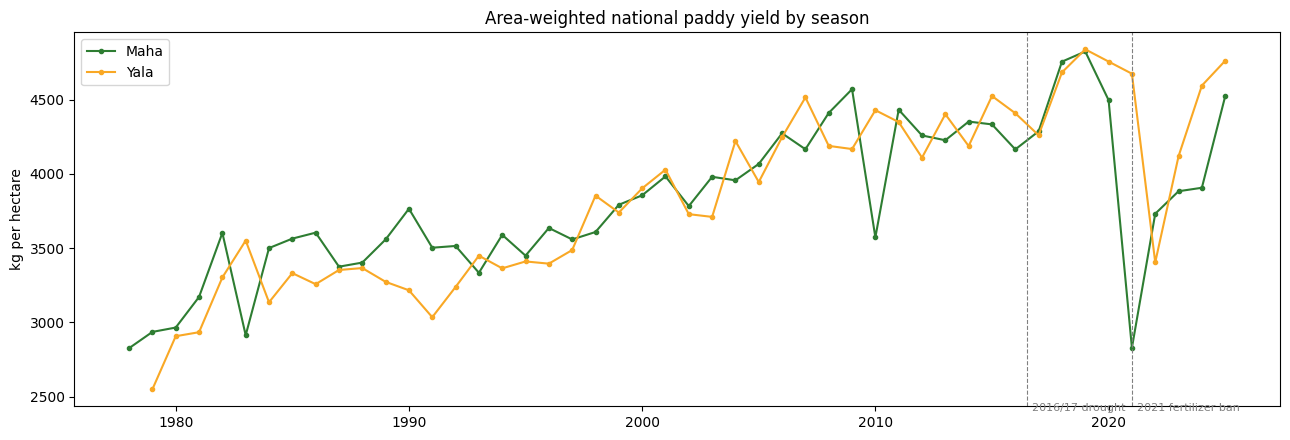

season,Maha,Yala
year,,
2014,4351.0,4187.0
2015,4332.0,4524.0
2016,4164.0,4408.0
2017,4286.0,4259.0
2018,4755.0,4682.0
2019,4823.0,4838.0
2020,4496.0,4755.0
2021,2828.0,4674.0
2022,3731.0,3403.0


In [77]:
nat = national_yield(panel)
plt.figure(figsize=(13, 4.5))
for season, colour in [("Maha", "#2E7D32"), ("Yala", "#F9A825")]:
    s = nat[nat.season == season]
    plt.plot(s.year, s.national_yield, marker="o", markersize=3, color=colour, label=season)
for x, label in [(2016.5, "2016/17 drought"), (2021, "2021 fertilizer ban")]:
    plt.axvline(x, color="grey", linestyle="--", linewidth=0.8)
    plt.text(x + 0.2, 2400, label, fontsize=8, color="grey")
plt.ylabel("kg per hectare")
plt.title("Area-weighted national paddy yield by season")
plt.legend()
plt.tight_layout()
plt.show()
nat.pivot(index="year", columns="season", values="national_yield").loc[2014:].round(0)

Three patterns are evident.

1. Yields rose steadily, from approximately 3,000 kg/ha in the early 1980s to approximately 4,500 kg/ha before 2021, through improved varieties, irrigation and fertilizer subsidies. Any model must accommodate this rising baseline.
2. Yields collapsed in Maha 2021/22. The national yield fell from about 4,500 to 2,828 kg/ha, a decline of over a third, and Yala 2022 (3,403) remained severely affected. This reflects the 2021 chemical-fertilizer import ban and subsequent shortages, a man-made shock unprecedented in the 40 years of data.
3. Recovery is partial. Yields returned to 3,700-4,600 from 2022/23, but Maha remained below its pre-2021 level until 2025.

Smaller declines such as the 2016/17 drought are visible but considerably less severe.

### <b>8.2 Differences Between Districts</b>

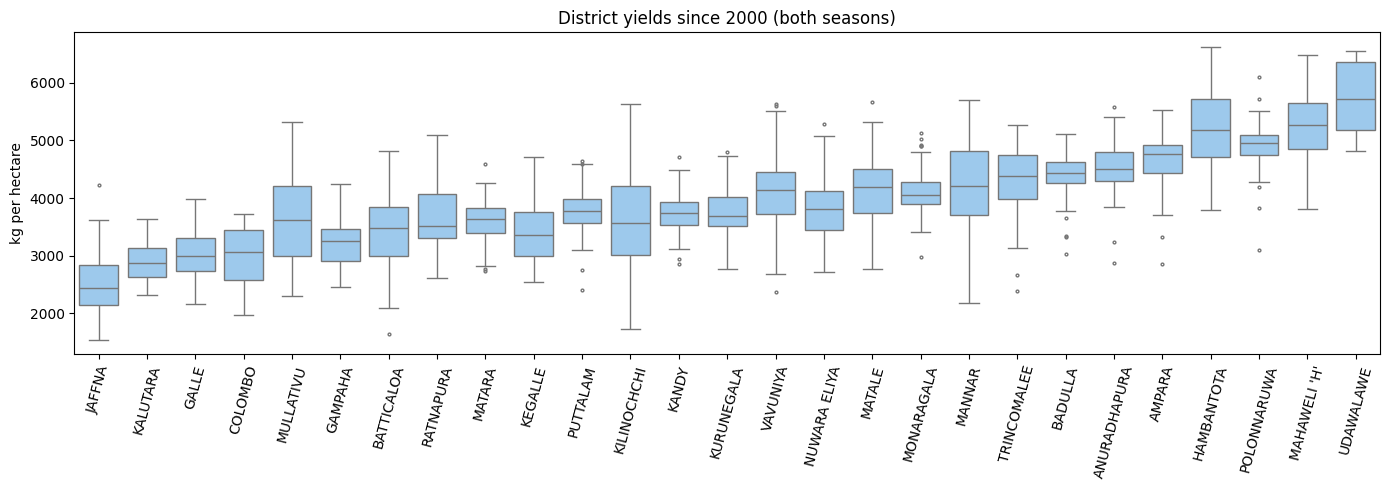

,share_major,share_minor,share_rainfed
district,,,
JAFFNA,0.00,0.00,1.00
KALUTARA,0.01,0.14,0.85
GALLE,0.01,0.09,0.90
POLONNARUWA,0.88,0.10,0.03
MAHAWELI 'H',1.00,NaN,NaN
UDAWALAWE,1.00,NaN,NaN


In [78]:
order = panel.groupby("district")["yield_kg_ha"].median().sort_values().index
plt.figure(figsize=(14, 5))
sns.boxplot(data=panel[panel.year >= 2000], x="district", y="yield_kg_ha", order=order, color="#90CAF9", fliersize=2)
plt.xticks(rotation=75)
plt.title("District yields since 2000 (both seasons)")
plt.ylabel("kg per hectare")
plt.xlabel("")
plt.tight_layout()
plt.show()

irrigation_mix = panel[panel.year >= 2015].groupby("district")[["share_major", "share_minor", "share_rainfed"]].mean().round(2)
irrigation_mix.loc[order[[0, 1, 2, -3, -2, -1]]]

District yields differ by a large, stable margin that follows irrigation. The lowest-yielding units (Jaffna, Kalutara, Galle) are almost entirely rainfed (85-100% of sown extent), and the highest (Polonnaruwa, Mahaweli 'H', Udawalawe) are almost entirely under major irrigation (88-100%).

Reliable water explains most of the difference, since an irrigated field can be planted on time and does not fail in a dry month. The district and its irrigation mix are therefore required inputs, and a national model without them would perform poorly.

### <b>8.3 Weather and Irrigation Against Yield</b>

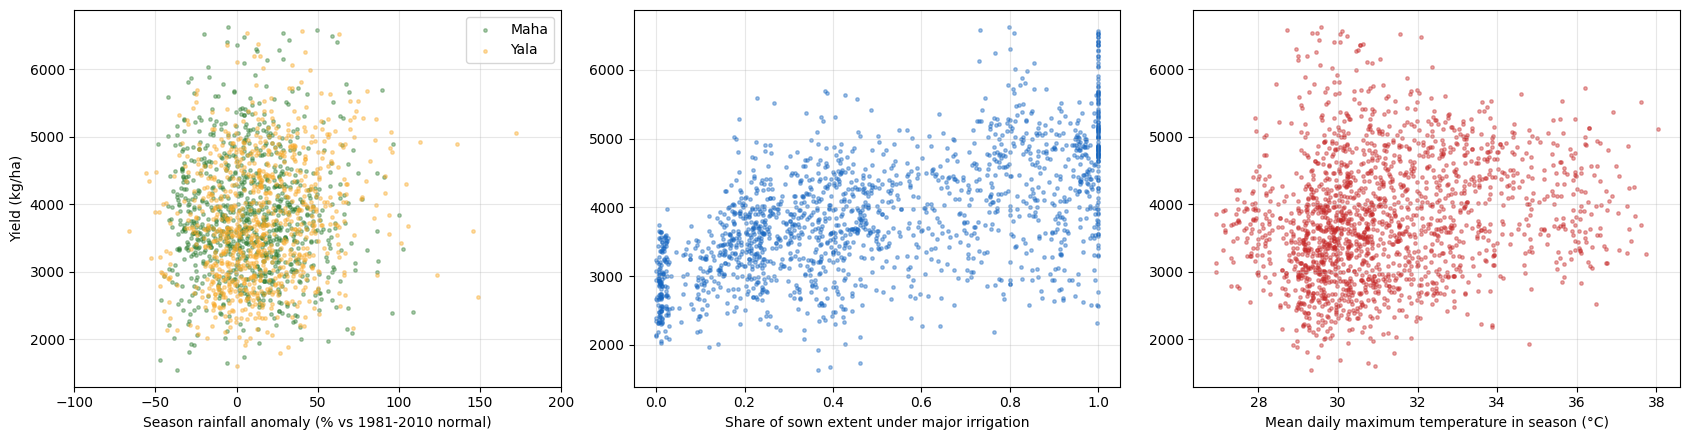

In [79]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
recent = panel[panel.year >= 1990]
for season, colour in [("Maha", "#2E7D32"), ("Yala", "#F9A825")]:
    s = recent[recent.season == season]
    axes[0].scatter(s.rain_anomaly_pct, s.yield_kg_ha, s=6, alpha=0.4, color=colour, label=season)
axes[0].set_xlabel("Season rainfall anomaly (% vs 1981-2010 normal)")
axes[0].set_ylabel("Yield (kg/ha)")
axes[0].set_xlim(-100, 200)
axes[0].legend()
axes[1].scatter(recent.share_major, recent.yield_kg_ha, s=6, alpha=0.4, color="#1565C0")
axes[1].set_xlabel("Share of sown extent under major irrigation")
axes[2].scatter(recent.tmax, recent.yield_kg_ha, s=6, alpha=0.4, color="#C62828")
axes[2].set_xlabel("Mean daily maximum temperature in season (°C)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

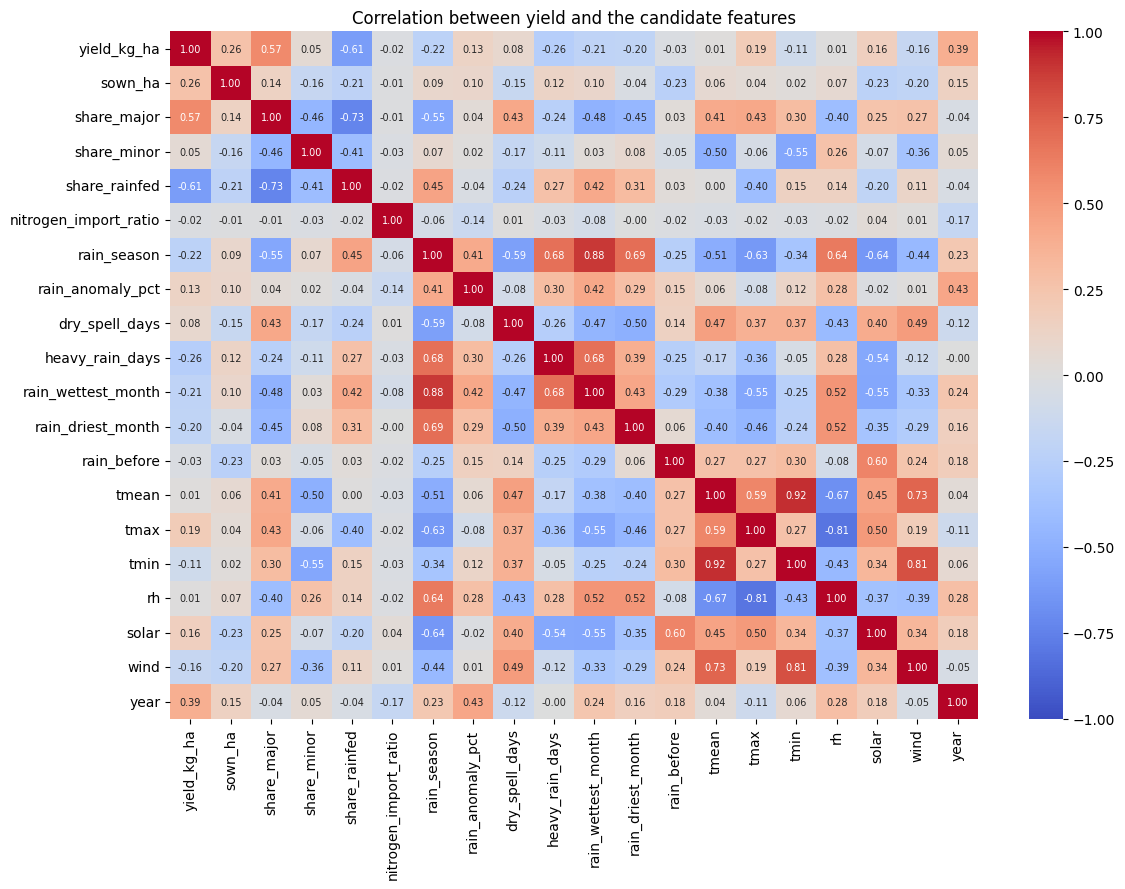

share_rainfed           -0.608
heavy_rain_days         -0.260
rain_season             -0.223
rain_wettest_month      -0.208
rain_driest_month       -0.203
wind                    -0.164
tmin                    -0.105
rain_before             -0.028
nitrogen_import_ratio   -0.018
rh                       0.005
tmean                    0.009
share_minor              0.049
dry_spell_days           0.080
rain_anomaly_pct         0.133
solar                    0.163
tmax                     0.193
sown_ha                  0.259
year                     0.388
share_major              0.574
Name: yield_kg_ha, dtype: float64

In [80]:
explore_cols = ["yield_kg_ha", "sown_ha", "share_major", "share_minor", "share_rainfed", "nitrogen_import_ratio", "rain_season", "rain_anomaly_pct", "dry_spell_days", "heavy_rain_days",
                "rain_wettest_month", "rain_driest_month", "rain_before", "tmean", "tmax", "tmin", "rh", "solar", "wind", "year"]
corr = panel[explore_cols].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation between yield and the candidate features")
plt.tight_layout()
plt.show()
corr["yield_kg_ha"].drop("yield_kg_ha").sort_values().round(3)

- Irrigation dominates. The rainfed share has the strongest correlation with yield (r = -0.61), followed by the major-irrigation share (+0.57). In the scatter plot, districts with mostly major irrigation rarely fall below 4,000 kg/ha.
- With CHIRPS, rainfall correlates negatively with yield for heavy-rain days (r = -0.26), season rainfall (-0.22) and the wettest month (-0.21), reflecting floods, lodging and disease, whereas the coarser NASA data produced near-zero values. The dry spell (+0.08) and rainfall anomaly (+0.13) are weak.
- Weather is weaker than irrigation partly because irrigation buffers rainfall. A dry season is a tank-management problem in Polonnaruwa but a direct yield loss in Kalutara, and a linear correlation across districts conflates these effects. Tree models or irrigation interactions may capture this, which supports non-linear models.
- Wind correlates negatively (-0.16), as windy seasons bring strong monsoon flows and storms that cause lodging (the collapse of plants) and spikelet damage at flowering.
- Nitrogen imports are uncorrelated with yield (-0.02), anticipating the finding in 10.1.
- The year correlates at 0.39, reflecting the upward trend.

### <b>8.4 Distribution of Yield</b>

The distribution of the target determines whether a transformation is needed and which error measure suits it. It is shown for all modelling rows and separately for the two seasons.

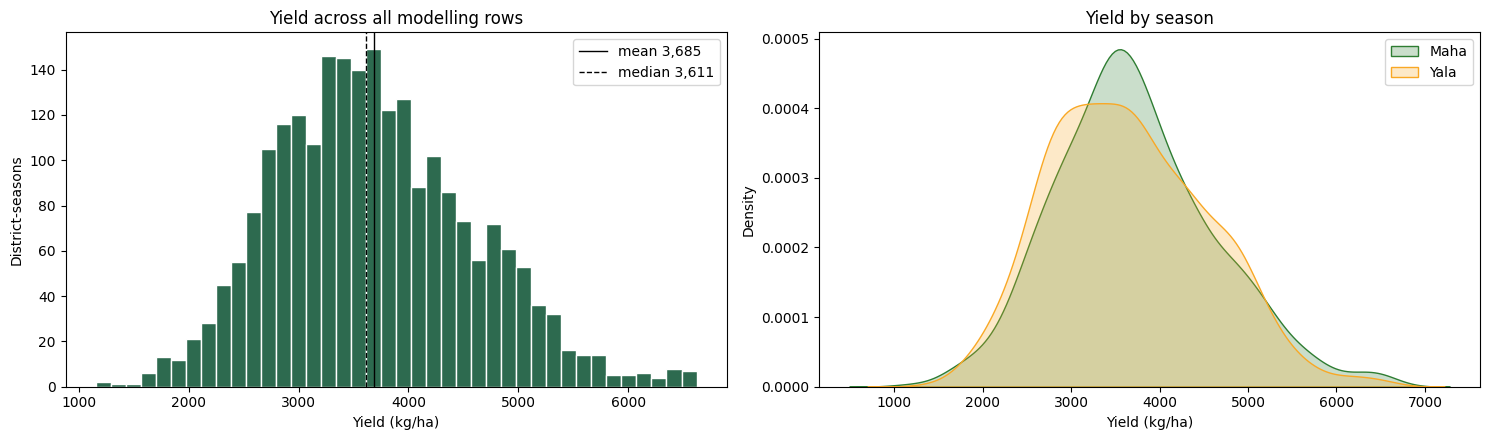

,count,mean,std,min,25%,50%,75%,max,skew
season,,,,,,,,,
Maha,1171.0,3716.8,904.3,1153.0,3098.0,3630.0,4266.0,6622.0,0.4
Yala,1105.0,3650.8,898.2,1361.0,2950.0,3587.0,4277.0,6560.0,0.4


In [81]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(model_df.yield_kg_ha, bins=40, color="#2D6A4F", edgecolor="white")
for value, style, label in [(model_df.yield_kg_ha.mean(), "-", "mean"), (model_df.yield_kg_ha.median(), "--", "median")]:
    axes[0].axvline(value, color="black", linestyle=style, linewidth=1, label=f"{label} {value:,.0f}")
axes[0].set_xlabel("Yield (kg/ha)")
axes[0].set_ylabel("District-seasons")
axes[0].set_title("Yield across all modelling rows")
axes[0].legend()
for season, colour in [("Maha", "#2E7D32"), ("Yala", "#F9A825")]:
    sns.kdeplot(model_df[model_df.season == season].yield_kg_ha, ax=axes[1], color=colour, fill=True, alpha=0.25, label=season)
axes[1].set_xlabel("Yield (kg/ha)")
axes[1].set_title("Yield by season")
axes[1].legend()
plt.tight_layout()
plt.show()

by_season_stats = model_df.groupby("season").yield_kg_ha.describe()
by_season_stats["skew"] = model_df.groupby("season").yield_kg_ha.skew()
by_season_stats.round(1)

Yield is close to symmetric in both seasons (skew 0.4). The Maha mean is 3,717 kg/ha with a median of 3,630, and the Yala mean is 3,651 with a median of 3,587. Values range from about 1,150 to 6,600 kg/ha and the spread is almost identical in the two seasons (standard deviation about 900 kg/ha).

No transformation of the target is therefore required, and the mean absolute error, which weights every kilogram equally, is a suitable main measure of accuracy.

### <b>8.5 Maha and Yala Compared</b>

The two seasons differ in rainfall and water supply, so their yields are compared within the same district and year, which removes the differences between districts.

District-years with both seasons 1095 | Maha higher in 65% | mean difference +136 kg/ha | median +180 kg/ha
Wilcoxon signed-rank p-value 6.7e-18


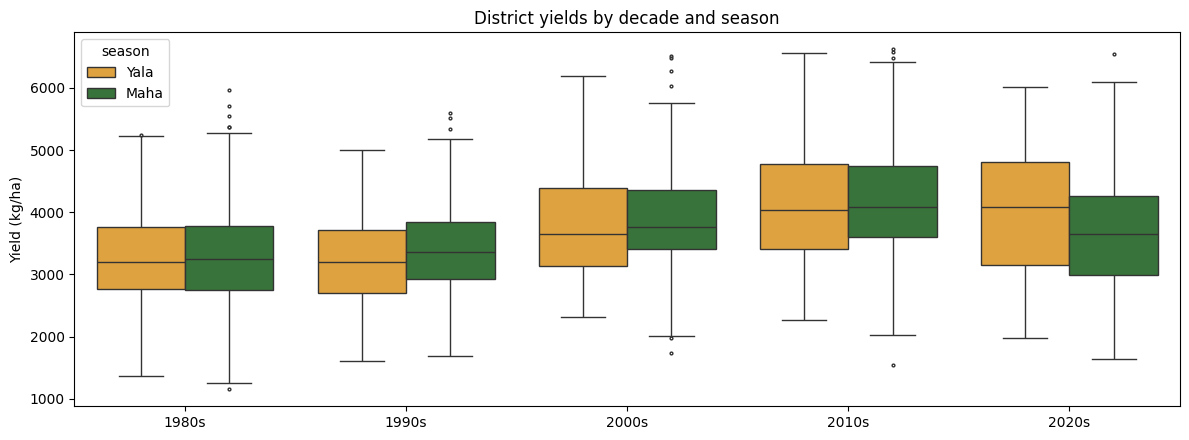

In [82]:
pairs_my = model_df.pivot_table(index=["district", "year"], columns="season", values="yield_kg_ha").dropna()
pairs_my["Maha minus Yala"] = pairs_my.Maha - pairs_my.Yala
print("District-years with both seasons", len(pairs_my), "| Maha higher in", f"{(pairs_my['Maha minus Yala'] > 0).mean() * 100:.0f}%",
      "| mean difference", f"{pairs_my['Maha minus Yala'].mean():+.0f} kg/ha", "| median", f"{pairs_my['Maha minus Yala'].median():+.0f} kg/ha")
print("Wilcoxon signed-rank p-value", f"{wilcoxon(pairs_my.Maha, pairs_my.Yala).pvalue:.2g}")

decade = (model_df.year // 10 * 10).astype(int).astype(str) + "s"
plt.figure(figsize=(12, 4.5))
sns.boxplot(x=decade, y=model_df.yield_kg_ha, hue=model_df.season, palette={"Maha": "#2E7D32", "Yala": "#F9A825"}, fliersize=2,
            order=sorted(decade.unique()))
plt.xlabel("")
plt.ylabel("Yield (kg/ha)")
plt.title("District yields by decade and season")
plt.tight_layout()
plt.show()

Within the same district and year, the Maha yield exceeds the Yala yield in 65% of the 1,095 comparisons, by 136 kg/ha on average (median 180 kg/ha). The difference is highly significant (Wilcoxon signed-rank test, p < 0.001) but small compared with the differences between districts in 8.2, and both seasons rise together across the decades.

Season is therefore kept as an input so that the model can apply this offset, and the history features are built separately for each season (the same season last year and the three-season average).

### <b>8.6 Summary of the Exploratory Analysis</b>

The analysis leads to six decisions for the modelling.

1. Yields rose steadily for forty years (8.1), so the model requires recent history features and a time-ordered split rather than a random one.
2. The 2021/22 collapse was a policy shock unlike any earlier season (8.1), which motivates the fertilizer shortage input examined in Section 11.
3. Districts differ by a large and stable margin that follows irrigation (8.2 and 8.3), so the district and the irrigation shares are required inputs.
4. Weather correlates only weakly with yield because irrigation buffers rainfall (8.3), which favours non-linear models and the daily dry-spell and heavy-rain indicators.
5. Maha yields are slightly higher than Yala yields within the same district and year (8.5), so season is an input and the history is built per season.
6. The target is close to symmetric (8.4), so it is modelled directly and evaluated mainly by the mean absolute error.

## <center><b>9. Train/Test Split and Validation</b></center>

### <b>9.1 Holding Out One Season for Inference</b>

The most recent season in the data, Polonnaruwa, Maha 2025/26, is set aside at this stage. Polonnaruwa is one of the principal rice districts and almost entirely under major irrigation, which makes it a meaningful example for the final inference and the app.

In [83]:
holdout_mask = (model_df.district == "POLONNARUWA") & (model_df.t == model_df.t.max())
holdout_row = model_df[holdout_mask].copy()
model_df = model_df[~holdout_mask]
holdout_row[["district", "season", "year", "yield_kg_ha", "sown_ha", "rain_season", "rain_anomaly_pct"]]

,district,season,year,yield_kg_ha,sown_ha,rain_season,rain_anomaly_pct
2012,POLONNARUWA,Maha,2025,6095.0,68961.0,1153.871,4.655


### <b>9.2 Time-Based Split</b>

Seasons are in chronological order, so the split is temporal. The model is trained on 1981-2016 (up to the 2016/17 Maha) and tested on 2017 Yala onwards, about 20% of the rows. The test period deliberately contains two very different shocks, the 2016-2017 drought and the 2021/22 fertilizer crisis.

For model selection, the training period is itself split by year. Each fold trains on all earlier years and validates on one year, for 2010 to 2016 (seven folds).

In [84]:
train_df = model_df[model_df.t < 2017].copy()
test_df = model_df[model_df.t >= 2017].copy()
X_train, y_train = train_df[feature_columns], train_df["yield_kg_ha"]
X_test, y_test = test_df[feature_columns], test_df["yield_kg_ha"]
print(f"Train {len(train_df)} rows ({train_df.t.min()} to {train_df.t.max()}) | Test {len(test_df)} rows ({test_df.t.min()} to {test_df.t.max()}) "
      f"= {len(test_df) / len(model_df) * 100:.0f}% of rows")

cv_folds = []
for val_year in range(2010, 2017):
    tr_idx = np.where(train_df.t.values < val_year)[0]
    va_idx = np.where((train_df.t.values >= val_year) & (train_df.t.values < val_year + 1))[0]
    cv_folds.append((tr_idx, va_idx))
print("Validation folds", [(len(a), len(b)) for a, b in cv_folds])

shock_seasons = [2021.75, 2022.25]  # 2021/22 Maha and 2022 Yala, the seasons hit by the fertilizer ban
is_shock = test_df.t.isin(shock_seasons).values

Train 1829 rows (1981.25 to 2016.75) | Test 446 rows (2017.25 to 2025.75) = 20% of rows
Validation folds [(1462, 50), (1512, 52), (1564, 53), (1617, 53), (1670, 53), (1723, 53), (1776, 53)]


### <b>9.3 Preprocessing Pipeline</b>

Numeric features receive median imputation and standard scaling, and district and season receive one-hot encoding, all inside a `Pipeline` fitted on the training rows only. CatBoost and the Explainable Boosting Machine skip this pipeline and receive the cleaned columns directly. Neither needs scaling, as both split features at thresholds, both encode district and season themselves, and both handle missing values natively (6.1). Section 15.5 confirms that this does not change the result. Scaling is important for Ridge and SVR, and although tree models do not require it, a shared step provides every model with the same input.

Cleaning and preprocessing are deliberately separated. Errors with one correct answer (misspelt district names, mislabelled seasons, impossible values) were corrected on the entire table in Sections 4 to 6, as the correction depends on no statistic. Steps that learn from data (imputation medians, scaling means and standard deviations, the category list) are fitted on the training rows only, so no information from the validation or test years leaks in.

After deployment, the API validates user input against a data contract, rejecting incorrect types, impossible values and unknown districts. It then constructs the derived features (rainfall against normal, sown extent against recent seasons and the ARIMA forecast) from the stored history as in Section 7, and the model applies its learned preprocessing before predicting (Section 19).

In [85]:
chosen_scaler = StandardScaler()  # replaced below if the robust scaler does better


def build_preprocessor(scaler=None):
    return ColumnTransformer([
        ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", clone(scaler if scaler is not None else chosen_scaler))]), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ])


def make_pipeline(model):
    return Pipeline([("prep", build_preprocessor()), ("model", model)])


def scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAPE %": mean_absolute_percentage_error(y_true, y_pred) * 100, "R2": r2_score(y_true, y_pred)}


def cv_scores(make_model, X=None, y=None):
    # time-ordered validation, fitting on the years before each validation year
    X = X_train if X is None else X
    y = y_train if y is None else y
    maes = []
    for tr_idx, va_idx in cv_folds:
        m = make_model().fit(X.iloc[tr_idx], y.iloc[tr_idx])
        maes.append(mean_absolute_error(y.iloc[va_idx], m.predict(X.iloc[va_idx])))
    return np.mean(maes), np.std(maes)

Section 7.5 identified strongly skewed features (sown_vs_prev3, sown_ha, rainfall). StandardScaler uses the mean and standard deviation, which extreme values distort, whereas RobustScaler uses the median and interquartile range. Both are therefore evaluated with Ridge (the scale-sensitive model) on the validation years rather than assuming which is superior.

In [86]:
scaler_results = {}
for name, scaler in [("StandardScaler", StandardScaler()), ("RobustScaler", RobustScaler())]:
    scaler_results[name] = cv_scores(lambda: Pipeline([("prep", build_preprocessor(scaler)), ("model", Ridge(alpha=10))]))
    print(f"Ridge with {name} validation MAE {scaler_results[name][0]:.1f} (std {scaler_results[name][1]:.1f})")

# the robust scaler has to be clearly better (by more than 1%) to replace the standard one
best_scaler = "RobustScaler" if scaler_results["RobustScaler"][0] < scaler_results["StandardScaler"][0] * 0.99 else "StandardScaler"
chosen_scaler = {"StandardScaler": StandardScaler(), "RobustScaler": RobustScaler()}[best_scaler]
print("Used from here on", best_scaler)

Ridge with StandardScaler validation MAE 355.0 (std 86.0)
Ridge with RobustScaler validation MAE 355.2 (std 88.8)
Used from here on StandardScaler


The two scalers give practically the same validation MAE for Ridge (355.0 and 355.2), so the skewed features have little effect here. The most likely reason is that the most heavily weighted features (the history features) are close to symmetric (skew about 0.4).

As there is no gain, the StandardScaler is retained. It has the practical advantage that the Ridge coefficients can be read as kg/ha per standard deviation of each feature (Section 17).

The pipeline is fitted on the training seasons below to confirm what it produces before any model uses it, namely the number of columns after encoding, the absence of missing values and the effect of the scaling.

In [87]:
from sklearn import set_config
set_config(display="diagram")

prep_check = build_preprocessor().fit(X_train)
X_train_prepared = prep_check.transform(X_train)
n_numeric = len(numeric_features)
n_onehot = len(prep_check.named_transformers_["categorical"].get_feature_names_out())
print("Training rows", X_train_prepared.shape[0], "| columns after preprocessing", X_train_prepared.shape[1],
      "| numeric", n_numeric, "| one-hot district and season", n_onehot)
print("Missing values remaining", int(np.isnan(X_train_prepared).sum()), "| before imputation", int(X_train[numeric_features].isna().sum().sum()))
print("Scaled numeric columns on the training rows, mean", round(float(X_train_prepared[:, :n_numeric].mean()), 3),
      "| standard deviation", round(float(X_train_prepared[:, :n_numeric].std()), 3))
make_pipeline(Ridge(alpha=10))

Training rows 1829 | columns after preprocessing 56 | numeric 27 | one-hot district and season 29
Missing values remaining 0 | before imputation 3372
Scaled numeric columns on the training rows, mean -0.0 | standard deviation 1.0


,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Two further choices are tested on the validation years rather than assumed. The first is that tree models do not need scaling, which is checked by training the same Random Forest on imputed-only and on scaled inputs. The second is whether a log transform of the skewed features identified in 7.5 helps Ridge, the scale-sensitive model.

In [88]:
from sklearn.preprocessing import FunctionTransformer

skewed_cols = [c for c in ["sown_vs_prev3", "sown_ha", "dry_spell_days", "heavy_rain_days", "nitrogen_import_ratio"] if c in numeric_features]
other_cols = [c for c in numeric_features if c not in skewed_cols]
onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)


def imputed_only(model):
    return Pipeline([("prep", ColumnTransformer([("numeric", SimpleImputer(strategy="median"), numeric_features),
                                                 ("categorical", clone(onehot), categorical_features)])), ("model", model)])


def with_log(model):
    log_steps = Pipeline([("impute", SimpleImputer(strategy="median")), ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("scale", StandardScaler())])
    plain_steps = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    return Pipeline([("prep", ColumnTransformer([("skewed", log_steps, skewed_cols), ("numeric", plain_steps, other_cols),
                                                 ("categorical", clone(onehot), categorical_features)])), ("model", model)])


small_rf = RandomForestRegressor(n_estimators=200, max_depth=8, min_samples_leaf=10, random_state=random_state, n_jobs=-1)
prep_rows = []
for label, make in [("Random Forest, imputed only", lambda: imputed_only(clone(small_rf))),
                    ("Random Forest, imputed and scaled", lambda: make_pipeline(clone(small_rf))),
                    ("Ridge, standard scaling", lambda: make_pipeline(Ridge(alpha=10))),
                    ("Ridge, log of the skewed features then scaling", lambda: with_log(Ridge(alpha=10)))]:
    mean_mae, sd_mae = cv_scores(make)
    prep_rows.append({"setup": label, "validation MAE": mean_mae, "std": sd_mae})
print("Skewed features given the log transform", ", ".join(skewed_cols))
pd.DataFrame(prep_rows).set_index("setup").round(1)

Skewed features given the log transform sown_vs_prev3, sown_ha, dry_spell_days, heavy_rain_days, nitrogen_import_ratio


,validation MAE,std
setup,,
"Random Forest, imputed only",370.5,87.2
"Random Forest, imputed and scaled",370.5,87.2
"Ridge, standard scaling",355.0,86.0
"Ridge, log of the skewed features then scaling",358.3,83.9


Fitted on the 1,829 training rows, the pipeline produces 56 columns, the 27 numeric candidates and 29 one-hot columns for the 27 units and the two seasons. All 3,372 missing values are filled, and the scaled columns have a mean of 0 and a standard deviation of 1 on the training rows, as intended. The diagram shows the structure that every model in Section 12 receives.

The Random Forest obtains an identical validation MAE with and without scaling (370.5 kg/ha), which confirms that tree models are unaffected by the scale of their inputs. The log transform of the five skewed features makes Ridge slightly worse (358.3 against 355.0 kg/ha), so the skewed features are used without transformation, consistent with the decision in 7.5 not to cap them.

### <b>9.4 Data Leakage Checklist</b>

Leakage occurs when a model receives information that would not be available at the moment of prediction, which makes its scores look better than they will be in use. The safeguards used in this notebook are listed below, and the next cell tests each one on the data rather than assuming it holds.

1. Every history feature uses earlier seasons only. The lags and the three-season average are shifted by one season (7.1).
2. The ARIMA forecast for a season is fitted only on the seasons before it (7.1).
3. Columns produced by the same end-of-season survey as the target (production, harvested extent, harvested share) are excluded (7.4).
4. The split is by time. Every training season precedes every test season, and every validation fold trains only on years before its validation year (9.2).
5. The season held out for inference is in neither the training nor the test rows (9.1).
6. Imputation, scaling and encoding are fitted inside the pipeline on the training rows of each fold only (9.3).
7. The rainfall normal is the 1981-2010 average, which ends before the test period.
8. The test seasons are used once, after the model is chosen on the validation years (12.6, 14.1).

In [89]:
# each safeguard is checked on the data rather than assumed
leak_checks = []
ordered = panel.sort_values(["district", "season", "t"])
previous = ordered.groupby(["district", "season"]).yield_kg_ha.shift(1)
has_lag = ordered.yield_same_season_lag1.notna()
leak_checks.append(("1. lag equals the previous same-season yield", bool(np.allclose(ordered.yield_same_season_lag1[has_lag], previous[has_lag]))))
earlier3 = ordered.groupby(["district", "season"]).yield_kg_ha.transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
has_roll = ordered.yield_same_season_roll3.notna()
leak_checks.append(("1. three-season average uses the three seasons before", bool(np.allclose(ordered.yield_same_season_roll3[has_roll], earlier3[has_roll]))))

sample = panel[(panel.district == "POLONNARUWA") & (panel.season == "Maha")].sort_values("t")
row = sample[sample.year == 2015].iloc[0]
history_before = sample[sample.t < row.t].yield_kg_ha.dropna().values
refit = ARIMA(history_before, order=(1, 1, 1)).fit().forecast(1)[0]
leak_checks.append(("2. ARIMA forecast refitted on earlier seasons only matches", bool(abs(refit - row.arima_forecast) < 0.01)))

leak_checks.append(("3. no survey output among the features", not any(("production" in c) or ("harvested" in c) for c in feature_columns)))
leak_checks.append(("4. every training season precedes every test season", bool(train_df.t.max() < test_df.t.min())))
leak_checks.append(("4. every validation fold trains only on earlier years",
                    all(train_df.t.values[tr].max() < train_df.t.values[va].min() for tr, va in cv_folds)))
held = (holdout_row.district.iloc[0], holdout_row.t.iloc[0])
leak_checks.append(("5. held-out season absent from training and test",
                    not ((model_df.district == held[0]) & (model_df.t == held[1])).any()))
leak_checks.append(("6. preprocessing sits inside the pipeline", isinstance(make_pipeline(Ridge()).steps[0][1], ColumnTransformer)))
leak_checks.append(("8. the test period starts after the validation years", bool(test_df.t.min() > max(train_df.t.values[va].max() for _, va in cv_folds))))
for name, passed in leak_checks:
    print(f"{name:62s} {'passed' if passed else 'FAILED'}")
print(f"ARIMA check for Polonnaruwa Maha 2015/16, stored {row.arima_forecast:,.1f} and refitted {refit:,.1f} kg/ha")

1. lag equals the previous same-season yield                   passed
1. three-season average uses the three seasons before          passed
2. ARIMA forecast refitted on earlier seasons only matches     passed
3. no survey output among the features                         passed
4. every training season precedes every test season            passed
4. every validation fold trains only on earlier years          passed
5. held-out season absent from training and test               passed
6. preprocessing sits inside the pipeline                      passed
8. the test period starts after the validation years           passed
ARIMA check for Polonnaruwa Maha 2015/16, stored 4,945.0 and refitted 4,945.0 kg/ha


All nine checks pass. The lag and three-season features equal values recomputed from earlier seasons only, and refitting the ARIMA model for Polonnaruwa Maha 2015/16 on the preceding seasons alone reproduces the stored forecast exactly (4,945.0 kg/ha). The training, validation and test periods are strictly ordered in time, and the held-out season is in neither the training nor the test rows.

Safeguard 7 is a property of the data source, the fixed 1981-2010 rainfall normal, so it is documented rather than computed.

## <center><b>10. Feature Selection</b></center>

Feature selection determines which inputs the model uses. The models are held fixed in this section. A few fast models with fixed settings are trained on each candidate set only to measure whether the set improves performance. The choice of algorithm and settings is a separate question addressed in Section 12 once the inputs are fixed. Separating the two steps limits the number of combinations and reduces the risk of overfitting the validation years.

### <b>10.1 Testing Each Candidate Source</b>

Each feature set is evaluated by training three fast models with different behaviour (Ridge, XGBoost and CatBoost) on the seven validation folds for two versions of the target, with the Explainable Boosting Machine, the deployed model type, also trained for reference. The cell prints the total number of models trained. The comparison of 20 models in Section 12 uses only the chosen features.

Sections 3.4-3.6 and 7.1 added data to address the errors of the first models. The weather grid was too coarse (6.3), the 2021/22 fertilizer crash was invisible to the model, and the tree models could not follow yields to new records.

Each candidate is added individually and retained only if it lowers validation error across the three models, so the result does not depend on one algorithm. Test seasons are not used, and every candidate is justified and known by the end of the season.

- A. The original setup, with NASA POWER rainfall.
- B. CHIRPS rainfall averaged over the district, instead of the single NASA grid point.
- C. B plus the longest dry spell and the number of heavy-rain days.
- D. C plus nitrogen fertilizer imports (the 2021 shock).
- E. C plus the previous season of neighbouring districts (regional shocks).
- F. C plus NDVI greenness during the season.
- G. C with one temperature (tmax) instead of three, since tmean, tmax and tmin are strongly collinear (7.3).
- H. C without the weakest weather variables (humidity, solar radiation, driest month), whose correlation with yield was close to zero (8.3).
- I. C plus the El Niño index (ONI) over the growing months.
- J. C plus the Indian Ocean Dipole index over the growing months.
- K. C plus the government fertilizer support level.
- L. C plus crop health over the rice fields (VCI, TCI and peak NDVI).

Each set is also evaluated with an alternative target, the deviation from the three-season average of the district, which is added back afterwards. A tree can then predict "8% above normal" in a record year instead of being capped at the highest yield observed.

In [90]:
history = ["yield_same_season_lag1", "yield_same_season_roll3", "yield_prev_season", "national_prev_season", "arima_forecast"]
planting = ["sown_ha", "share_major", "share_minor", "share_rainfed", "sown_vs_prev3"]
other_weather = ["tmean", "tmax", "tmin", "rh", "solar", "wind"]
nasa_rain = ["nasa_rain_season", "nasa_rain_anomaly_pct", "nasa_rain_wettest", "nasa_rain_driest", "rain_before"]
chirps_rain = ["rain_season", "rain_anomaly_pct", "rain_wettest_month", "rain_driest_month", "rain_before"]
daily_rain = ["dry_spell_days", "heavy_rain_days"]
set_c = history + planting + chirps_rain + daily_rain + other_weather
feature_sets = {
    "A. Original (NASA rainfall)": history + planting + nasa_rain + other_weather,
    "B. CHIRPS rainfall": history + planting + chirps_rain + other_weather,
    "C. B + dry spell, heavy-rain days": set_c,
    "D. C + nitrogen imports": set_c + ["nitrogen_import_ratio"],
    "E. C + neighbours": set_c + ["neighbours_prev_ratio"],
    "F. C + NDVI": set_c + ["ndvi_anomaly", "ndvi_max"],
    "G. C, one temperature": [c for c in set_c if c not in ("tmean", "tmin")],
    "H. C, no weak weather": [c for c in set_c if c not in ("rh", "solar", "rain_driest_month")],
    "I. C + El Nino": set_c + ["enso_index"],
    "J. C + Indian Ocean Dipole": set_c + ["iod_index"],
    "K. C + fertilizer policy": set_c + ["fertilizer_support"],
    "L. C + rice crop health": set_c + ["rice_vci", "rice_tci", "rice_ndvi_peak"],
}


class OnAverage:
    # predicts the difference from the 3-season average, then adds the average back
    def __init__(self, model):
        self.model = model

    def fit(self, X, y):
        self.model.fit(X, np.asarray(y) - X["yield_same_season_roll3"].values)
        return self

    def predict(self, X):
        return self.model.predict(X) + X["yield_same_season_roll3"].values


def model_for(name, num):
    # qualitative columns (set R) go with district and season to the categorical encoders
    cats = categorical_features + [c for c in num if c in qualitative_features]
    num = [c for c in num if c not in qualitative_features]
    prep = ColumnTransformer([("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
                              ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats)])
    if name == "Ridge":
        return Pipeline([("prep", prep), ("model", Ridge(alpha=ridge_alpha_start))])
    if name == "XGBoost":
        return Pipeline([("prep", prep), ("model", XGBRegressor(n_estimators=200, learning_rate=0.03, max_depth=3, min_child_weight=5, subsample=0.8,
                                                                  colsample_bytree=0.7, reg_lambda=5.0, random_state=random_state, n_jobs=-1))])
    return Pipeline([("cols", ColumnTransformer([("keep", "passthrough", cats + num)], verbose_feature_names_out=False).set_output(transform="pandas")),
                     ("model", CatBoostRegressor(iterations=400, learning_rate=0.03, depth=4, l2_leaf_reg=10, random_seed=random_state, verbose=0,
                                                 cat_features=cats))])


def ebm_for(num):
    # the deployed model type, trained on exactly the columns of one feature set
    keep = ColumnTransformer([("keep", "passthrough", categorical_features + num)], verbose_feature_names_out=False).set_output(transform="pandas")
    return Pipeline([("cols", keep), ("model", ExplainableBoostingRegressor(interactions=5, outer_bags=8, random_state=random_state))])


ridge_alpha_start = 3
experiment_rows = []
for set_name, num in feature_sets.items():
    for target in ["yield", "change from average"]:
        row = {"features": set_name, "target": target}
        for name in ["Ridge", "XGBoost", "CatBoost"]:
            make = (lambda: OnAverage(model_for(name, num))) if target != "yield" else (lambda: model_for(name, num))
            row[name] = cv_scores(make, X=train_df, y=y_train)[0]
        row["average of the three"] = np.mean([row[m] for m in ["Ridge", "XGBoost", "CatBoost"]])
        # shown for every set so the deployed model type can be compared directly, but not used in the decisions below
        row["EBM"] = cv_scores(lambda: ebm_for(num), X=train_df, y=y_train)[0] if target == "yield" else np.nan
        experiment_rows.append(row)
feature_experiments = pd.DataFrame(experiment_rows)
n_fits = len(feature_sets) * (2 * 3 + 1) * len(cv_folds)
print(f"{len(feature_sets)} feature sets, {len(cv_folds)} validation folds each {n_fits} models trained in this cell")
feature_experiments.round(1)

12 feature sets, 7 validation folds each 588 models trained in this cell


,features,target,Ridge,XGBoost,CatBoost,average of the three,EBM
0,A. Original (NASA rainfall),yield,361.0,354.6,358.2,357.9,361.8
1,A. Original (NASA rainfall),change from average,360.9,357.4,358.8,359.0,NaN
2,B. CHIRPS rainfall,yield,356.4,354.9,361.9,357.7,353.5
3,B. CHIRPS rainfall,change from average,356.1,356.1,358.2,356.8,NaN
4,"C. B + dry spell, heavy-rain days",yield,353.5,357.3,358.9,356.6,346.9
5,"C. B + dry spell, heavy-rain days",change from average,353.3,353.2,358.6,355.0,NaN
6,D. C + nitrogen imports,yield,355.2,358.4,360.1,357.9,353.0
7,D. C + nitrogen imports,change from average,355.0,356.8,359.0,356.9,NaN
8,E. C + neighbours,yield,353.7,358.3,357.2,356.4,350.0
9,E. C + neighbours,change from average,353.5,352.6,360.0,355.3,NaN


The results are strikingly close, all between about 350 and 366 kg/ha, while the error varies by about 85-90 kg/ha between validation years. No addition therefore alters the overall result substantially.

- CHIRPS instead of NASA rainfall (A to B) improves Ridge (361.0 to 356.4), is neutral for the tree models and is retained as the better data.
- Dry spell and heavy-rain days (B to C) lower Ridge to 353.5, heavy-rain days being the weather variable most correlated with yield (r = -0.26, see 8.3).
- Nitrogen imports (D) slightly worsen every model, as the next cell explains.
- Neighbours (E) have a negligible effect (-0.1%).
- NDVI (F) improves CatBoost (358.9 to 352.3) but not Ridge or XGBoost (0.7% better on average). Its anomaly barely correlates with the yield deviation of a season (r = 0.05, 7.1), as the 10 x 10 km area around a district centre is mostly forest, villages and other crops rather than paddy.
- One temperature instead of three (G) is slightly better on average, since tmean and tmin were near duplicates (VIF 49 and 37 in 7.3).
- Removing the weak weather variables (H) substantially degrades the tree models (XGBoost 363.4, CatBoost 366.2), so humidity, solar radiation and the driest month are more important than their correlations suggested.
- Predicting the change from the 3-season average improves some sets and degrades others, never by more than about 1%.

- El Niño (I) is slightly worse (+0.3%). Its correlation with the yield change was weak (0.15 for Maha, 0.10 for Yala, 7.1), and its effect acts through rainfall already supplied by CHIRPS.
- The Indian Ocean Dipole (J) is slightly better on average (-0.6%), mainly for Ridge, but below the 1% threshold.
- The fertilizer policy level (K) has a negligible effect (-0.2%), since every validation year shares one level and in training only the normal 1990-1994 no-subsidy seasons differ (7.1).
- Crop health over the rice fields (L) is the best new source (-0.8% on average, with XGBoost reaching 347.0 on the change-from-average target). It nevertheless remains below 1% and is nearly uncorrelated with the yield change (7.1).

The EBM column shows the same pattern for the deployed model type. Its validation error falls from 361.8 with the original setup to 346.9 with set C and 346.6 with set G. Among the new sources only the Indian Ocean Dipole improves it by more than 1% (342.7), a gain the three probe models do not confirm, so the decision stands.

No candidate source passes the 1% threshold, so the feature set remains set G (Section 10.2). The fertilizer shortage itself is examined in Section 11, and further checks of the feature choice are reported in Section 15.

In [91]:
# the variation of the import ratio in the training years, which explains why the nitrogen feature cannot detect 2021
train_ratio = train_df.drop_duplicates("fertilizer_year").set_index("fertilizer_year")["nitrogen_import_ratio"].sort_index()
print("Nitrogen import ratio in the training years min", round(train_ratio.min(), 2), "| max", round(train_ratio.max(), 2),
      "| years below 0.6", ", ".join(f"{k} {v}" for k, v in train_ratio[train_ratio < 0.6].round(2).items()))
low = train_df[train_df.nitrogen_import_ratio < 0.6]
print("Average yield vs 3-season average in those years", round((low.yield_kg_ha / low.yield_same_season_roll3).mean(), 3),
      "| in all training years", round((train_df.yield_kg_ha / train_df.yield_same_season_roll3).mean(), 3))

Nitrogen import ratio in the training years min 0.17 | max 3.64 | years below 0.6 1981 0.57, 1982 0.17, 1983 0.29
Average yield vs 3-season average in those years 1.093 | in all training years 1.028


Within the training years the import ratio ranged from 0.17 to 3.64, and the only years below 0.6 (1981-1983) were favourable seasons, about 9% above the three-season average. Because importers bring fertilizer in bursts and hold stocks, a year of low imports does not imply that farmers lacked fertilizer. Against that history a ratio of 0.44 appears unremarkable, so the feature cannot detect 2021.

In [92]:
# Two kinds of change are judged against two thresholds (MAE averaged over Ridge, XGBoost and CatBoost)
# - a data clean-up or simplification (a better rainfall source, features from the same source, removed duplicates) is kept if it is not worse
# - new outside data or a new modelling trick must be more than 1% better, the same bar as in 12.6, since it adds a dependency and complexity.
on_yield = feature_experiments[feature_experiments.target == "yield"].set_index("features")["average of the three"]
steps = [("B. CHIRPS rainfall", "clean-up"), ("C. B + dry spell, heavy-rain days", "clean-up"),
         ("D. C + nitrogen imports", "new data"), ("E. C + neighbours", "new data"), ("F. C + NDVI", "new data"),
         ("G. C, one temperature", "clean-up"), ("H. C, no weak weather", "clean-up"),
         ("I. C + El Nino", "new data"), ("J. C + Indian Ocean Dipole", "new data"), ("K. C + fertilizer policy", "new data"),
         ("L. C + rice crop health", "new data")]
late_checks = ("M.", "N.", "O.", "Q.", "R.")
decisions = {}
current = "A. Original (NASA rainfall)"
chosen = list(feature_sets[current])
for step, kind in steps:
    base = current if step.startswith(("B.", "C.")) else "C. B + dry spell, heavy-rain days"
    new_mae, base_mae = on_yield[step], on_yield[base]
    kept = new_mae <= base_mae if kind == "clean-up" else new_mae < base_mae * 0.99
    if step.startswith(late_checks):
        decisions[step] = (new_mae / base_mae - 1) * 100, "late check, passes the bar, reported only" if kept else "late check, not kept"
        print(f"{step:36s} late check {base_mae:6.1f} -> {new_mae:6.1f} ({(new_mae / base_mae - 1) * 100:+.1f}%)  "
              f"{'passes the bar, reported only (15.4)' if kept else 'does not pass the bar'}")
        continue
    if step.startswith(("B.", "C.")) and kept:
        current, chosen = step, list(feature_sets[step])
    elif kept:
        chosen = [c for c in chosen if c in feature_sets[step]] + [c for c in feature_sets[step] if c not in chosen]
    decisions[step] = (new_mae / base_mae - 1) * 100, "kept" if kept else "not kept"
    print(f"{step:36s} {kind:9s} {base_mae:6.1f} -> {new_mae:6.1f} ({(new_mae / base_mae - 1) * 100:+.1f}%)  {'kept' if kept else 'not kept'}")

final_set = next((name for name, cols in feature_sets.items() if sorted(cols) == sorted(chosen)), None)
target_rows = feature_experiments[feature_experiments.features == final_set].set_index("target")["average of the three"]
use_change_target = target_rows["change from average"] < target_rows["yield"] * 0.99
print(f"\nChange-from-average target on the final set {target_rows['yield']:.1f} -> {target_rows['change from average']:.1f}",
      "| used" if use_change_target else "| not used (less than 1% better)")
FINAL_FEATURES = chosen

B. CHIRPS rainfall                   clean-up   357.9 ->  357.7 (-0.1%)  kept
C. B + dry spell, heavy-rain days    clean-up   357.7 ->  356.6 (-0.3%)  kept
D. C + nitrogen imports              new data   356.6 ->  357.9 (+0.4%)  not kept
E. C + neighbours                    new data   356.6 ->  356.4 (-0.1%)  not kept
F. C + NDVI                          new data   356.6 ->  354.0 (-0.7%)  not kept
G. C, one temperature                clean-up   356.6 ->  354.9 (-0.5%)  kept
H. C, no weak weather                clean-up   356.6 ->  361.4 (+1.4%)  not kept
I. C + El Nino                       new data   356.6 ->  357.6 (+0.3%)  not kept
J. C + Indian Ocean Dipole           new data   356.6 ->  354.5 (-0.6%)  not kept
K. C + fertilizer policy             new data   356.6 ->  356.0 (-0.2%)  not kept
L. C + rice crop health              new data   356.6 ->  353.6 (-0.8%)  not kept

Change-from-average target on the final set 354.9 -> 354.6 | not used (less than 1% better)


The chart below summarises the decision on every feature set. A set was required to pass the dashed line, 1% below the reference set C, to be retained.

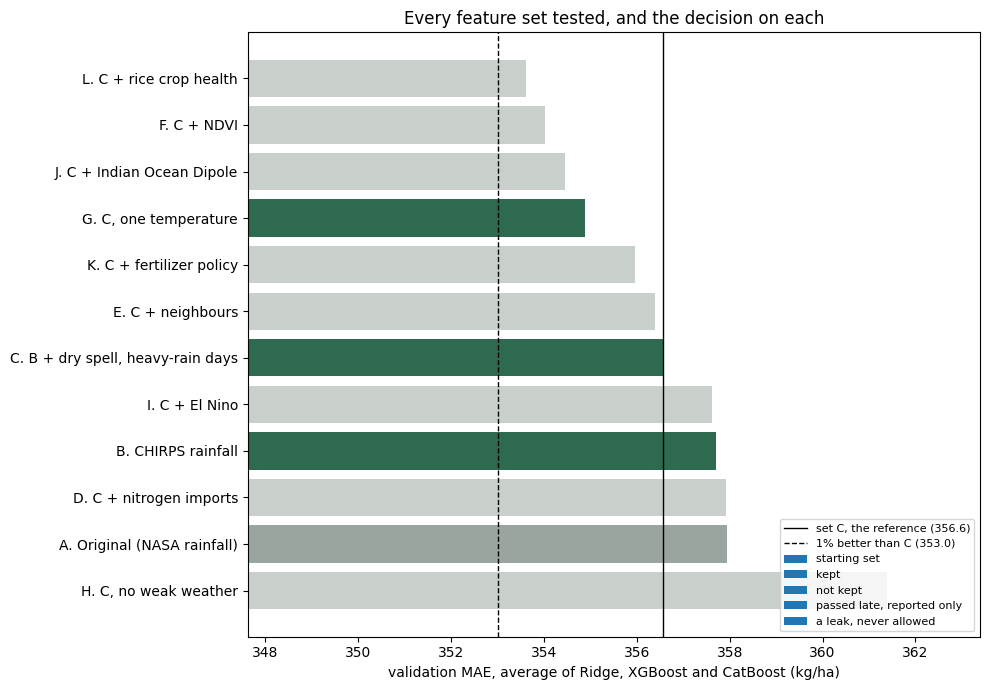

In [93]:
# every feature set on one chart, showing the average validation error of the three probe models coloured by the decision
base_c = on_yield["C. B + dry spell, heavy-rain days"]
outcome = {"A. Original (NASA rainfall)": "starting set", "P. C + harvested share (a leak)": "a leak, never allowed"}
for name, (change, decision) in decisions.items():
    outcome[name] = "kept" if decision == "kept" else ("passed late, reported only" if "passes" in decision else "not kept")
colours = {"starting set": "#9AA5A0", "kept": "#2D6A4F", "not kept": "#C9CFCB", "passed late, reported only": "#D89A3D", "a leak, never allowed": "#C1432C"}
order = on_yield.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(order.index, order.values, color=[colours[outcome.get(n, "not kept")] for n in order.index])
ax.axvline(base_c, color="black", linewidth=1, label=f"set C, the reference ({base_c:.1f})")
ax.axvline(base_c * 0.99, color="black", linewidth=1, linestyle="--", label=f"1% better than C ({base_c * 0.99:.1f})")
for label, colour in colours.items():
    ax.barh([], [], color=colour, label=label)
ax.set_xlim(order.min() - 6, order.max() + 2)
ax.set_xlabel("validation MAE, average of Ridge, XGBoost and CatBoost (kg/ha)")
ax.set_title("Every feature set tested, and the decision on each")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

### <b>10.2 The Final Feature Set</b>

The final feature set is set C with one temperature instead of three (set G). It has 21 numeric features plus district and season, and it requires four sources, the DCS paddy statistics, CHIRPS rainfall, NASA POWER weather and, through Section 11, the fertilizer policy record. Section 15 reports further checks of this choice, and Section 15.6 lists every source with its final verdict.

In [94]:
numeric_features = FINAL_FEATURES
feature_columns = categorical_features + numeric_features
X_train, X_test = train_df[feature_columns], test_df[feature_columns]
print("Final features", len(feature_columns), "|", numeric_features)

Final features 23 | ['yield_same_season_lag1', 'yield_same_season_roll3', 'yield_prev_season', 'national_prev_season', 'arima_forecast', 'sown_ha', 'share_major', 'share_minor', 'share_rainfed', 'sown_vs_prev3', 'rain_season', 'rain_anomaly_pct', 'rain_wettest_month', 'rain_driest_month', 'rain_before', 'dry_spell_days', 'heavy_rain_days', 'tmax', 'rh', 'solar', 'wind']


## <center><b>11. Government Policy as a Model Input</b></center>

The fertilizer policy level in 10.1 is identical (level 3) in every validation year, and the shortage flag is 0 in every season before 2021/22. No model trained on 1981-2016 can therefore learn the effect of a shortage, which explains why every model failed to predict Maha 2021/22.

The more useful question is whether a model can recognise the next shortage after observing one. This is the situation of the deployed model, which is retrained on all seasons including 2021/22.

Each model is trained on all seasons up to and including Maha 2021/22 and then estimates Yala 2022, the second shortage season, with and without the policy input. This single test season is not used to select a model or to change any score in Section 14. It determines only whether the deployed model receives a policy input.

In [95]:
seen_one_shortage = model_df[model_df.t <= 2021.75]
second_shortage = model_df[model_df.t == 2022.25]
weights = second_shortage.sown_ha
policy_inputs = {"no policy input": [], "+ fertilizer_shortage (yes/no)": ["fertilizer_shortage"], "+ fertilizer_support (level 0-4)": ["fertilizer_support"]}
policy_rows = []
for name in ["Ridge", "CatBoost", "Explainable Boosting Machine"]:
    for label, extra in policy_inputs.items():
        num = numeric_features + extra
        model = (ExplainableBoostingRegressor(interactions=5, outer_bags=8, random_state=random_state) if name.startswith("Explainable")
                 else model_for(name, num))
        pred = model.fit(seen_one_shortage[categorical_features + num], seen_one_shortage.yield_kg_ha).predict(second_shortage[categorical_features + num])
        policy_rows.append({"model": name, "policy input": label, "MAE Yala 2022": mean_absolute_error(second_shortage.yield_kg_ha, pred),
                            "national estimate": np.average(pred, weights=weights)})
print(f"Yala 2022, actual national yield (area-weighted) {np.average(second_shortage.yield_kg_ha, weights=weights):,.0f} kg/ha")
pd.DataFrame(policy_rows).round(0)

Yala 2022, actual national yield (area-weighted) 3,403 kg/ha


,model,policy input,MAE Yala 2022,national estimate
0,Ridge,no policy input,661.0,4189.0
1,Ridge,+ fertilizer_shortage (yes/no),982.0,2578.0
2,Ridge,+ fertilizer_support (level 0-4),425.0,3871.0
3,CatBoost,no policy input,814.0,4326.0
4,CatBoost,+ fertilizer_shortage (yes/no),318.0,3474.0
5,CatBoost,+ fertilizer_support (level 0-4),332.0,3544.0
6,Explainable Boosting Machine,no policy input,556.0,4047.0
7,Explainable Boosting Machine,+ fertilizer_shortage (yes/no),702.0,2646.0
8,Explainable Boosting Machine,+ fertilizer_support (level 0-4),643.0,2759.0


After one shortage season, the policy input enables the models to recognise the next, although the benefit depends on the model.

- CatBoost improves the most. Its Yala 2022 error falls from 814 to 318 kg/ha with the yes/no input, and its national estimate (3,474) lies within 71 kg/ha of the actual 3,403.
- Ridge performs best with the support level (661 to 425) but overestimates with the yes/no flag (982).
- The EBM overestimates. It learns the size of the Maha 2021/22 collapse from that single season and applies it in full, estimating 2,646 against 3,403, and its error rises from 556 to 702. Yala 2022 was a shortage rather than a ban, and national yield fell less (about 28% below the three-season average, against about 39% in Maha 2021/22).

A policy shock can thus be incorporated into the model once it has occurred, but after one example the size of its effect is uncertain. The deployed model receives the yes/no fertilizer_shortage input (Section 18), which the app treats as a scenario switch.

A planner anticipating a shortage can then examine the expected outcome instead of a normal-season estimate, read as the effect of a severe shortage like 2021/22. The input is not used to choose the model or in any test score.

## <center><b>12. Model Selection and Parameter Engineering</b></center>

With the inputs fixed in Section 10, this section selects the algorithm and its settings. Twenty approaches are trained on the same 21 features and the same validation folds, from baselines and weak learners to ensembles, stacking, hybrids and seven additional models. Their hyperparameters are designed from the data and validated through early stopping and grid search, which is the parameter engineering step.

The sequence progresses from simple baselines and weak learners to bagging, boosting, stacking and hybrids. Every model is scored on the seven validation years first, and the test seasons are used only at the end.

### <b>12.1 Baselines</b>

Three baselines without machine learning are used, namely last year's same-season yield, the mean of the last three same seasons, and the district's own ARIMA forecast (a classical time-series model).

In [96]:
baseline_rows = []
for name, col in [("Naive same season last year", "yield_same_season_lag1"), ("Naive average of last 3 same seasons", "yield_same_season_roll3"),
                  ("ARIMA(1,1,1) per district and season", "arima_forecast")]:
    pred = test_df[col].fillna(test_df["yield_same_season_roll3"])
    cv = np.mean([mean_absolute_error(train_df.iloc[va].yield_kg_ha, train_df.iloc[va][col].fillna(train_df.iloc[va].yield_same_season_roll3)) for _, va in cv_folds])
    baseline_rows.append({"Model": name, "Family": "Baseline", "CV MAE": cv, **{f"Test {k}": v for k, v in scores(y_test, pred).items()}})
pd.DataFrame(baseline_rows).round(3)

,Model,Family,CV MAE,Test MAE,Test RMSE,Test MAPE %,Test R2
0,Naive same season last year,Baseline,438.173,560.548,749.881,15.483,0.379
1,Naive average of last 3 same seasons,Baseline,366.361,532.346,719.803,14.775,0.428
2,"ARIMA(1,1,1) per district and season",Baseline,375.336,509.190,687.286,14.178,0.478


### <b>12.2 Weak Learners, Ridge Regression and a Decision Tree</b>

Ridge is linear regression with an L2 penalty, which stabilises the coefficients when features are correlated (as the history features are, see 7.3). A single decision tree is the building block of the ensembles that follow. Both are tuned with `GridSearchCV` over the yearly folds, scoring on MAE.

In [97]:
ridge_search = GridSearchCV(make_pipeline(Ridge()), {"model__alpha": [0.1, 1, 3, 10, 30, 100]},
                            cv=cv_folds, scoring="neg_mean_absolute_error").fit(X_train, y_train)
tree_search = GridSearchCV(make_pipeline(DecisionTreeRegressor(random_state=random_state)),
                           {"model__max_depth": [3, 4, 5, 6, 8], "model__min_samples_leaf": [10, 20, 40], "model__criterion": ["squared_error", "absolute_error"]},
                           cv=cv_folds, scoring="neg_mean_absolute_error", n_jobs=-1).fit(X_train, y_train)
ridge_alpha = ridge_search.best_params_["model__alpha"]
tree_params = {k.replace("model__", ""): v for k, v in tree_search.best_params_.items()}
print("Ridge alpha", ridge_alpha, "| CV MAE", round(-ridge_search.best_score_, 1))
print("Decision tree", tree_params, "| CV MAE", round(-tree_search.best_score_, 1))

Ridge alpha 3 | CV MAE 352.9
Decision tree {'criterion': 'squared_error', 'max_depth': 3, 'min_samples_leaf': 10} | CV MAE 389.6


Limiting the depth and leaf size stops the tree before it grows too far. The decision tree lecture also describes cost-complexity pruning, which grows a full tree and then removes the branches that reduce the error least for their size, with the strength of pruning (ccp_alpha) chosen by cross-validation. It is tried below on the same yearly folds, over the range of pruning strengths that scikit-learn's pruning path gives for this data.

In [98]:
path = DecisionTreeRegressor(random_state=random_state).cost_complexity_pruning_path(build_preprocessor().fit_transform(X_train), y_train)
pruning = pd.DataFrame([{"ccp_alpha": alpha, "CV MAE": cv_scores(lambda a=alpha: make_pipeline(DecisionTreeRegressor(ccp_alpha=a, random_state=random_state)))[0]}
                        for alpha in np.unique(np.quantile(path.ccp_alphas, [0.90, 0.95, 0.98, 0.99, 0.995, 0.999]))])
print(f"Best pruned tree, CV MAE {pruning['CV MAE'].min():.1f} | depth-limited tree above, CV MAE {-tree_search.best_score_:.1f}")
pruning.round(1)

Best pruned tree, CV MAE 391.3 | depth-limited tree above, CV MAE 389.6


,ccp_alpha,CV MAE
0,231.8,441.8
1,467.2,413.4
2,998.5,402.6
3,1799.3,392.8
4,3556.9,391.3
5,62382.0,508.8


Cost-complexity pruning does not improve on the depth-limited tree. The best pruning strength gives 391.3 kg/ha against 389.6, and the strongest removes useful splits as well (508.8 kg/ha). Limiting the depth and the leaf size is therefore kept.

### <b>12.3 Designing the Ensemble Hyperparameters</b>

No default values are used. With about 1,800 training rows, 50 columns after one-hot encoding, a strong autoregressive signal in a few history features, and weak, noisy weather effects at district level, the trees are kept shallow and the leaves large so that they learn broad patterns rather than individual district-seasons.

The settings and their rationale are listed below.

- Bagging uses 500 trees with all features, `max_depth=8` and `min_samples_leaf=10`. Averaging many trees reduces variance.
- Random Forest uses 500 trees, `max_features=1/3` (Breiman's p/3 rule for regression), `max_depth=8`, `min_samples_leaf=10` and `max_samples=0.8`. Random feature subsets decorrelate the trees, and every leaf holds at least 10 district-seasons.
- XGBoost uses `learning_rate=0.03`, `max_depth=3`, `min_child_weight=5`, `subsample=0.8`, `colsample_bytree=0.7` and `reg_lambda=5`, with the number of trees set by early stopping on 2015-2016. Small steps, shallow trees and a strong L2 penalty suit the weak signal.
- LightGBM uses `num_leaves=8`, `min_child_samples=30`, `learning_rate=0.03`, `subsample=0.8`, `colsample_bytree=0.7` and `reg_lambda=5`, with the number of trees set by early stopping. As LightGBM grows trees leaf by leaf, capping the leaves prevents deep, narrow branches.
- CatBoost uses `depth=4`, `learning_rate=0.03` and `l2_leaf_reg=10`, with district and season passed as native categorical features and the number of iterations set by early stopping. Its ordered target statistics replace one-hot encoding, which suits a district column with 27 levels.

In [99]:
# early stopping, fitted on seasons before 2015 and monitored by MAE on 2015-2016
es_fit, es_val = train_df[train_df.t < 2015], train_df[train_df.t >= 2015]
es_prep = build_preprocessor().fit(es_fit[feature_columns])
Xf, Xv = es_prep.transform(es_fit[feature_columns]), es_prep.transform(es_val[feature_columns])

xgb_es = XGBRegressor(n_estimators=3000, learning_rate=0.03, max_depth=3, min_child_weight=5, subsample=0.8, colsample_bytree=0.7,
                      reg_lambda=5.0, eval_metric="mae", early_stopping_rounds=100, random_state=random_state, n_jobs=-1)
xgb_es.fit(Xf, es_fit.yield_kg_ha, eval_set=[(Xv, es_val.yield_kg_ha)], verbose=False)

lgbm_es = LGBMRegressor(n_estimators=3000, learning_rate=0.03, num_leaves=8, min_child_samples=30, subsample=0.8, subsample_freq=1,
                        colsample_bytree=0.7, reg_lambda=5.0, random_state=random_state, verbose=-1)
lgbm_es.fit(Xf, es_fit.yield_kg_ha, eval_set=[(Xv, es_val.yield_kg_ha)], eval_metric="l1",
            callbacks=[lightgbm.early_stopping(100, verbose=False)])

cat_es = CatBoostRegressor(iterations=3000, learning_rate=0.03, depth=4, l2_leaf_reg=10, loss_function="RMSE", eval_metric="MAE",
                           od_type="Iter", od_wait=100, random_seed=random_state, verbose=0, cat_features=categorical_features)
cat_es.fit(es_fit[feature_columns], es_fit.yield_kg_ha, eval_set=(es_val[feature_columns], es_val.yield_kg_ha))

n_trees = {"xgb": xgb_es.best_iteration + 1, "lgbm": lgbm_es.best_iteration_, "cat": cat_es.get_best_iteration() + 1}
print("Boosting rounds chosen by early stopping", n_trees)

Boosting rounds chosen by early stopping {'xgb': 359, 'lgbm': 248, 'cat': 736}


In [100]:
rf_params = dict(n_estimators=500, max_depth=8, min_samples_leaf=10, min_samples_split=20, max_features=1 / 3, max_samples=0.8,
                 bootstrap=True, oob_score=True, n_jobs=-1, random_state=random_state)
xgb_params = dict(n_estimators=n_trees["xgb"], learning_rate=0.03, max_depth=3, min_child_weight=5, subsample=0.8, colsample_bytree=0.7,
                  reg_lambda=5.0, random_state=random_state, n_jobs=-1)
lgbm_params = dict(n_estimators=n_trees["lgbm"], learning_rate=0.03, num_leaves=8, min_child_samples=30, subsample=0.8, subsample_freq=1,
                   colsample_bytree=0.7, reg_lambda=5.0, random_state=random_state, verbose=-1)
cat_params = dict(iterations=n_trees["cat"], learning_rate=0.03, depth=4, l2_leaf_reg=10, random_seed=random_state, verbose=0,
                  cat_features=categorical_features)

A limited grid search around the designed LightGBM and CatBoost values tests the design. As in the activity, tuned values are adopted only if they outperform the designed ones by more than the fold-to-fold spread.

In [101]:
lgbm_grid = GridSearchCV(make_pipeline(LGBMRegressor(**lgbm_params)),
                         {"model__num_leaves": [4, 8, 16], "model__min_child_samples": [15, 30, 60], "model__reg_lambda": [1.0, 5.0, 20.0]},
                         cv=cv_folds, scoring="neg_mean_absolute_error", n_jobs=-1).fit(X_train, y_train)
cat_rows = []
for depth in [3, 4, 6]:
    for l2 in [3, 10, 30]:
        m, s = cv_scores(lambda: CatBoostRegressor(**{**cat_params, "depth": depth, "l2_leaf_reg": l2}))
        cat_rows.append({"depth": depth, "l2_leaf_reg": l2, "CV MAE": m, "std": s})
cat_grid = pd.DataFrame(cat_rows).sort_values("CV MAE")

lgbm_designed = cv_scores(lambda: make_pipeline(LGBMRegressor(**lgbm_params)))
cat_designed = cv_scores(lambda: CatBoostRegressor(**cat_params))
print(f"LightGBM designed CV MAE {lgbm_designed[0]:.1f} (std {lgbm_designed[1]:.1f}) | best grid {-lgbm_grid.best_score_:.1f} with {lgbm_grid.best_params_}")
print(f"CatBoost designed CV MAE {cat_designed[0]:.1f} (std {cat_designed[1]:.1f}) | best grid {cat_grid.iloc[0]['CV MAE']:.1f} with depth={int(cat_grid.iloc[0]['depth'])}, l2={cat_grid.iloc[0]['l2_leaf_reg']}")
if lgbm_designed[0] - (-lgbm_grid.best_score_) > lgbm_designed[1]:
    lgbm_params.update({k.replace("model__", ""): v for k, v in lgbm_grid.best_params_.items()})
if cat_designed[0] - cat_grid.iloc[0]["CV MAE"] > cat_designed[1]:
    cat_params.update({"depth": int(cat_grid.iloc[0]["depth"]), "l2_leaf_reg": cat_grid.iloc[0]["l2_leaf_reg"]})
print("LightGBM used", ", ".join(f"{k} {lgbm_params[k]}" for k in ["num_leaves", "min_child_samples", "reg_lambda"]),
      "| CatBoost used", ", ".join(f"{k} {cat_params[k]}" for k in ["depth", "l2_leaf_reg"]))

LightGBM designed CV MAE 357.2 (std 83.9) | best grid 351.7 with {'model__min_child_samples': 15, 'model__num_leaves': 16, 'model__reg_lambda': 1.0}
CatBoost designed CV MAE 352.6 (std 90.3) | best grid 349.4 with depth=6, l2=30.0
LightGBM used num_leaves 8, min_child_samples 30, reg_lambda 5.0 | CatBoost used depth 4, l2_leaf_reg 10


Early stopping selected 359 trees for XGBoost, 248 for LightGBM and 736 for CatBoost at a learning rate of 0.03.

Both grids obtained slightly lower validation MAEs, 351.7 against 357.2 for LightGBM (more leaves, less regularisation) and 349.4 against 352.6 for CatBoost (deeper trees, stronger L2). These gains of 3-6 kg/ha are small relative to the fold-to-fold standard deviation of 84-90 kg/ha.

The designed, more regularised settings are therefore retained. With only seven validation years, optimising for a few kg/ha would largely fit the model to those particular years.

The designed values were reasoned from the data, so they are checked in two ways. The first is the Random Forest error against the number of trees, measured on the out-of-bag rows, on the seven validation years and on the training rows themselves. The second is the XGBoost error on the training and validation seasons at every boosting round, which shows where early stopping cut the model off.

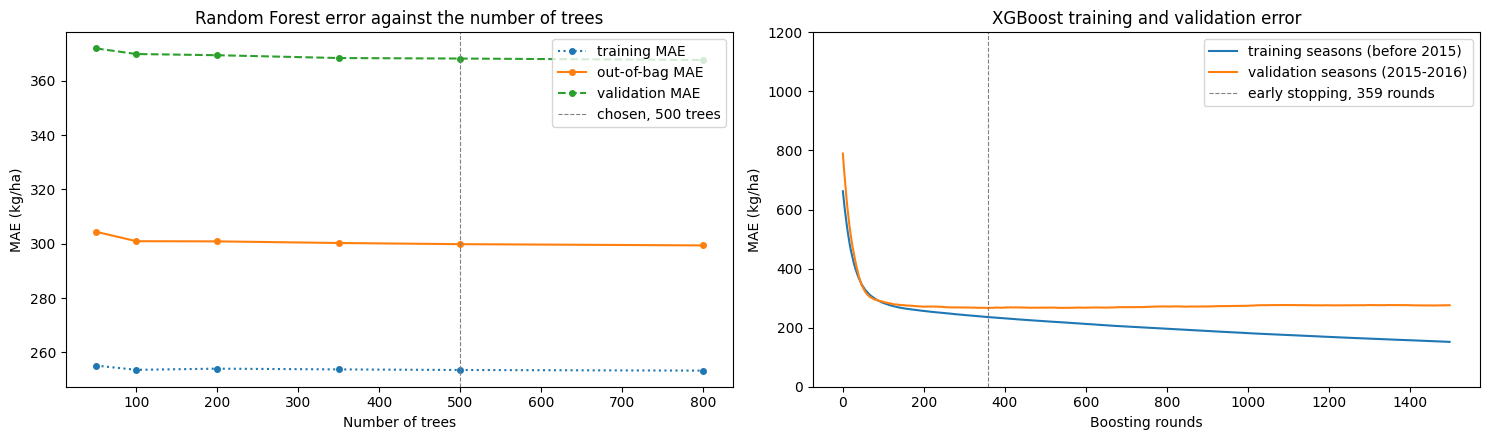

XGBoost at the early-stopping point, training MAE 235.9 | validation MAE 266.5 | after 1,500 rounds 151.9 and 276.0


,training MAE,out-of-bag MAE,validation MAE
trees,,,
50,255.1,304.4,372.0
100,253.5,300.9,369.9
200,254.0,300.9,369.5
350,253.7,300.3,368.4
500,253.5,299.8,368.2
800,253.2,299.4,367.7


In [102]:
# Random Forest error as trees are added, on the training rows, the out-of-bag rows and the validation years
rf_prep = build_preprocessor().fit(X_train)
X_train_rf = rf_prep.transform(X_train)
tree_counts = [50, 100, 200, 350, 500, 800]
design_rows = []
for n in tree_counts:
    rf_n = RandomForestRegressor(**{**rf_params, "n_estimators": n}).fit(X_train_rf, y_train)
    design_rows.append({"trees": n, "training MAE": mean_absolute_error(y_train, rf_n.predict(X_train_rf)),
                        "out-of-bag MAE": mean_absolute_error(y_train, rf_n.oob_prediction_),
                        "validation MAE": cv_scores(lambda: make_pipeline(RandomForestRegressor(**{**rf_params, "n_estimators": n, "oob_score": False})))[0]})
rf_design = pd.DataFrame(design_rows).set_index("trees")

# XGBoost error at every boosting round, on the seasons before 2015 and on 2015-2016
xgb_curve = XGBRegressor(**{**xgb_params, "n_estimators": 1500}, eval_metric="mae")
xgb_curve.fit(Xf, es_fit.yield_kg_ha, eval_set=[(Xf, es_fit.yield_kg_ha), (Xv, es_val.yield_kg_ha)], verbose=False)
curve = xgb_curve.evals_result()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for col, style in [("training MAE", ":o"), ("out-of-bag MAE", "-o"), ("validation MAE", "--o")]:
    axes[0].plot(rf_design.index, rf_design[col], style, label=col, markersize=4)
axes[0].axvline(500, color="grey", linestyle="--", linewidth=0.8, label="chosen, 500 trees")
axes[0].set_xlabel("Number of trees")
axes[0].set_ylabel("MAE (kg/ha)")
axes[0].set_title("Random Forest error against the number of trees")
axes[0].legend()
axes[1].plot(curve["validation_0"]["mae"], label="training seasons (before 2015)")
axes[1].plot(curve["validation_1"]["mae"], label="validation seasons (2015-2016)")
axes[1].axvline(n_trees["xgb"], color="grey", linestyle="--", linewidth=0.8, label=f"early stopping, {n_trees['xgb']} rounds")
axes[1].set_ylim(0, 1200)
axes[1].set_xlabel("Boosting rounds")
axes[1].set_ylabel("MAE (kg/ha)")
axes[1].set_title("XGBoost training and validation error")
axes[1].legend()
plt.tight_layout()
plt.show()
print("XGBoost at the early-stopping point, training MAE", f"{curve['validation_0']['mae'][n_trees['xgb'] - 1]:.1f}",
      "| validation MAE", f"{curve['validation_1']['mae'][n_trees['xgb'] - 1]:.1f}",
      "| after 1,500 rounds", f"{curve['validation_0']['mae'][-1]:.1f} and {curve['validation_1']['mae'][-1]:.1f}")
rf_design.round(1)

Both checks support the designed settings.

The Random Forest validation error barely changes beyond about 200 trees (369.5 kg/ha, and 367.7 at 800), and adding trees never makes it worse, so 500 trees lie well past the point of diminishing returns. The out-of-bag error (about 300 kg/ha) is lower than the validation error (about 368 kg/ha) because out-of-bag rows are drawn at random from the same years the trees learned from, whereas the validation years lie in the future. It is therefore an optimistic guide for this time-ordered problem. The training error stays near 253 kg/ha, so the shallow trees with large leaves do not memorise the training seasons.

For XGBoost the training error continues to fall with more rounds, to 152 kg/ha after 1,500, while the validation error is lowest near the early-stopping point and then rises slowly (266.5 to 276.0 kg/ha on 2015-2016). This divergence is the characteristic sign of overfitting, and early stopping halts the model before it develops.

The designed settings above were reasoned from the data and checked with the two curves and two small grids. As a fuller test, a randomised search draws settings from wide ranges for the three strong models that have no grid above, 25 for XGBoost, 20 for Random Forest and 12 for the Explainable Boosting Machine, and scores every one on the same seven validation years. The rule is the same as for LightGBM and CatBoost, so a tuned setting replaces the designed one only if it lowers the validation MAE by more than the fold-to-fold standard deviation.

XGBoost | best settings subsample 0.6, reg_lambda 10.0, n_estimators 600, min_child_weight 5, max_depth 4, learning_rate 0.03, colsample_bytree 0.5
Random Forest | best settings n_estimators 500, min_samples_leaf 3, max_samples None, max_features 0.2, max_depth 12
Explainable Boosting Machine | best settings min_samples_leaf 20, max_leaves 2, max_bins 128, learning_rate 0.005, interactions 5


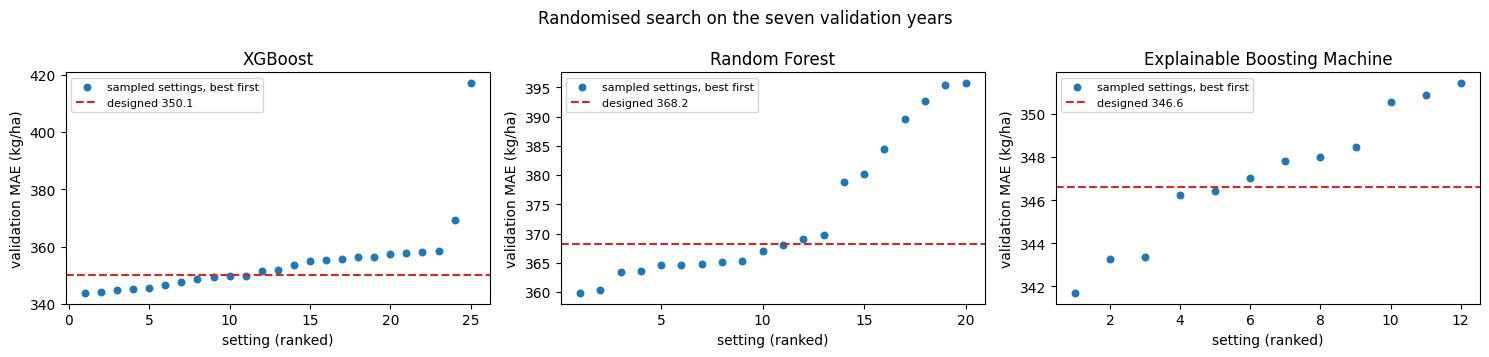

,designed CV MAE,fold std,best of search,gain kg/ha,worst of search,settings tried,tuned setting adopted,minutes
model,,,,,,,,
XGBoost,350.1,87.1,343.7,6.4,417.2,25,no,2.8
Random Forest,368.2,85.7,359.8,8.4,395.8,20,no,1.2
Explainable Boosting Machine,346.6,79.0,341.7,4.9,351.4,12,no,5.2


In [103]:
# randomised search over wide ranges for the three strong models without a grid above, on the same seven validation years
from sklearn.model_selection import ParameterSampler

search_spaces = {
    "XGBoost": (lambda p: make_pipeline(XGBRegressor(**{**xgb_params, **p})), 25, {
        "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1], "n_estimators": [200, 359, 600, 1000], "max_depth": [2, 3, 4, 5, 6],
        "min_child_weight": [1, 3, 5, 10, 20], "subsample": [0.6, 0.7, 0.8, 0.9, 1.0], "colsample_bytree": [0.5, 0.7, 0.9, 1.0],
        "reg_lambda": [0.5, 1.0, 5.0, 10.0, 30.0]}),
    "Random Forest": (lambda p: make_pipeline(RandomForestRegressor(**{**rf_params, "oob_score": False, **p})), 20, {
        "n_estimators": [300, 500, 800], "max_depth": [6, 8, 12, 16, None], "min_samples_leaf": [3, 5, 10, 20, 40],
        "max_features": [0.2, 1 / 3, 0.5, 0.7, 1.0], "max_samples": [0.6, 0.8, None]}),
    "Explainable Boosting Machine": (lambda p: ExplainableBoostingRegressor(**{"interactions": 5, "outer_bags": 8, "random_state": random_state, **p}), 12, {
        "learning_rate": [0.005, 0.01, 0.02, 0.04], "interactions": [0, 5, 10, 15], "max_bins": [128, 256, 512, 1024],
        "min_samples_leaf": [2, 4, 10, 20], "max_leaves": [2, 3]}),
}
search_rows, search_tried = [], {}
for name, (make, n_iter, space) in search_spaces.items():
    start = time.time()
    designed_mae, designed_sd = cv_scores(lambda: make({}))
    tried, best = [], None
    for p in ParameterSampler(space, n_iter=n_iter, random_state=random_state):
        m, s = cv_scores(lambda: make(p))
        tried.append({"CV MAE": m, "std": s})
        if best is None or m < best[1]:
            best = (p, m)
    tried = pd.DataFrame(tried).sort_values("CV MAE")
    search_tried[name] = (tried, designed_mae)
    gain = designed_mae - tried["CV MAE"].iloc[0]
    search_rows.append({"model": name, "designed CV MAE": designed_mae, "fold std": designed_sd, "best of search": tried["CV MAE"].iloc[0],
                        "gain kg/ha": gain, "worst of search": tried["CV MAE"].max(), "settings tried": len(tried),
                        "tuned setting adopted": "yes" if gain > designed_sd else "no", "minutes": (time.time() - start) / 60})
    print(name, "| best settings", ", ".join(f"{k} {round(v, 3) if isinstance(v, float) else v}" for k, v in best[0].items()))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (name, (tried, designed_mae)) in zip(axes, search_tried.items()):
    ax.scatter(range(1, len(tried) + 1), tried["CV MAE"], color="tab:blue", s=22, label="sampled settings, best first")
    ax.axhline(designed_mae, color="tab:red", ls="--", label=f"designed {designed_mae:.1f}")
    ax.set(title=name, xlabel="setting (ranked)", ylabel="validation MAE (kg/ha)")
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.legend(fontsize=8)
plt.suptitle("Randomised search on the seven validation years")
plt.tight_layout()
plt.show()
pd.DataFrame(search_rows).set_index("model").round(1)

The search serves as a sensitivity analysis of the designed configurations. The best sampled setting reduced the validation MAE by 6.4 kg/ha for XGBoost (343.7 against 350.1), 8.4 for Random Forest (359.8 against 368.2) and 4.9 for the Explainable Boosting Machine (341.7 against 346.6). These differences are small relative to the fold-to-fold standard deviation of 79-87 kg/ha, and the minimum of several noisy validation scores overstates the true improvement, particularly as these years have informed every earlier decision. Under the adoption criterion applied to LightGBM and CatBoost, the designed configurations are therefore retained.

The designed settings lie within the near-optimal region of each search, whereas poorly chosen settings increase the error by up to 67 kg/ha for XGBoost (417 against 350). The best tuned Explainable Boosting Machine also remains more accurate than the best tuned XGBoost and Random Forest, so the choice of model is robust to tuning. The search indicates that a smaller learning rate may yield a modest improvement for the Explainable Boosting Machine, consistent with the check in 15.5, and this is noted for evaluation when the model is retrained on new seasons.

The XGBoost lecture lists a third form of regularisation besides the L2 penalty and the minimum child weight, namely the minimum gain a split must achieve (gamma), which prunes splits that improve the loss too little. It is checked separately on the designed XGBoost.

In [104]:
gamma_check = pd.DataFrame([{"gamma": g, "CV MAE": cv_scores(lambda g=g: make_pipeline(XGBRegressor(**{**xgb_params, "gamma": g})))[0]} for g in [0, 1, 5, 20, 50]])
gamma_check.round(1)

,gamma,CV MAE
0,0,350.1
1,1,350.1
2,5,350.1
3,20,350.1
4,50,350.1


Gamma makes no difference from 0 to 50 (350.1 kg/ha throughout), most likely because it is measured in the squared-error loss, in which any useful split on yields in kg/ha gains far more than 50, so no split is blocked. The shallow depth, the L2 penalty and the minimum child weight already limit the trees, so gamma is left at 0.

### <b>12.4 Stacking and Hybrid Models</b>

- Heterogeneous stacking combines Ridge, Random Forest, LightGBM and CatBoost through a Ridge meta-model. The meta-model learns from forward out-of-fold predictions, so for every year from 1995 the base models are fitted on the earlier years only and predict that year, as a random or blocked split would let them learn from later seasons.
- Hybrid 1, the ARIMA residual model, uses ARIMA for the trend forecast and a Random Forest trained on the ARIMA residuals to add the weather and planting effects. This is the "ARIMA + Random Forest" approach presented in the lecture.
- Hybrid 2 blends Ridge, for the linear trend and history effects, with CatBoost, for the non-linear weather and district effects, averaging their predictions with a weight chosen on the validation years.

In [105]:
class ArimaResidualForest:
    # ARIMA trend forecast + Random Forest on what ARIMA gets wrong
    def __init__(self, **rf_kwargs):
        self.rf_kwargs = rf_kwargs

    def _trend(self, X):
        return X["arima_forecast"].fillna(X["yield_same_season_roll3"]).values

    def fit(self, X, y):
        self.model_ = make_pipeline(RandomForestRegressor(**self.rf_kwargs)).fit(X, np.asarray(y) - self._trend(X))
        return self

    def predict(self, X):
        return self._trend(X) + self.model_.predict(X)


class RidgeCatBoostBlend:
    # weighted average of a Ridge pipeline and CatBoost with native categorical features
    def __init__(self, weight_ridge=0.5, alpha=10.0, cat_kwargs=None):
        self.weight_ridge, self.alpha, self.cat_kwargs = weight_ridge, alpha, cat_kwargs or {}

    def fit(self, X, y):
        self.ridge_ = make_pipeline(Ridge(alpha=self.alpha)).fit(X, y)
        self.cat_ = CatBoostRegressor(**self.cat_kwargs).fit(X, y)
        return self

    def predict(self, X):
        return self.weight_ridge * self.ridge_.predict(X) + (1 - self.weight_ridge) * self.cat_.predict(X)


class ForwardStack:
    # stacking in which the meta-model learns only from forecasts made by base models fitted on earlier years
    def __init__(self, makers, alpha=1.0, first_year=1995):
        self.makers, self.alpha, self.first_year = makers, alpha, first_year

    def fit(self, X, y):
        years = np.floor(model_df.loc[X.index, "t"].values)
        inputs, rows = [], []
        for year in sorted(set(years[years >= self.first_year])):
            before, now = years < year, years == year
            inputs.append(np.column_stack([make().fit(X[before], y[before]).predict(X[now]) for make in self.makers]))
            rows.append(np.where(now)[0])
        self.meta_ = Ridge(alpha=self.alpha).fit(np.vstack(inputs), y.iloc[np.concatenate(rows)])
        self.models_ = [make().fit(X, y) for make in self.makers]
        return self

    def predict(self, X):
        return self.meta_.predict(np.column_stack([m.predict(X) for m in self.models_]))


rf_no_oob = {**rf_params, "oob_score": False}
stack_makers = [lambda: make_pipeline(Ridge(alpha=ridge_alpha)), lambda: make_pipeline(RandomForestRegressor(**rf_no_oob)),
                lambda: make_pipeline(LGBMRegressor(**lgbm_params)), lambda: CatBoostRegressor(**cat_params)]
blend_rows = []
for w in [0.0, 0.25, 0.5, 0.75, 1.0]:
    m, s = cv_scores(lambda: RidgeCatBoostBlend(w, ridge_alpha, cat_params))
    blend_rows.append({"weight on Ridge": w, "CV MAE": m, "std": s})
blend_table = pd.DataFrame(blend_rows)
blend_weight = blend_table.sort_values("CV MAE").iloc[0]["weight on Ridge"]
print("Blend weight chosen on the validation years", blend_weight)
blend_table.round(1)

Blend weight chosen on the validation years 0.5


,weight on Ridge,CV MAE,std
0,0.0,352.6,90.3
1,0.2,349.3,90.5
2,0.5,348.1,89.9
3,0.8,349.1,89.1
4,1.0,352.9,89.5


### <b>12.5 Models Not Covered in the Lectures</b>

The lectures covered linear and logistic regression, SVM, decision trees, Random Forest, XGBoost, bagging and stacking. Seven further models are evaluated, each suited to a specific property of this data.

- The Explainable Boosting Machine (EBM), from Microsoft's InterpretML, is a boosted generalised additive model. Learning one shape function per feature (plus a few pairwise interactions), it approaches boosting accuracy while every effect can be plotted and read, which suits a problem where the explanation matters as much as the number.
- The linear mixed-effects model is the standard model for panel data, where the same units are measured repeatedly. Each district has its own random intercept (baseline), while the effects of rainfall, irrigation and history are shared, so "Jaffna is always lower" is treated as a property of the district rather than rediscovered from one-hot columns.
- NGBoost (natural gradient boosting) predicts a full normal distribution, with its own mean and spread for every season. The spread gives a proper uncertainty estimate for each prediction.
- Gaussian Process regression is a smooth, kernel-based model that also provides its own uncertainty. It does not predict in flat steps like trees, so it should extrapolate more gently.
- Extra Trees (extremely randomised trees) resemble a Random Forest with randomly drawn split points, which averages out more noise on a small, noisy dataset.
- Histogram Gradient Boosting is scikit-learn's LightGBM-style booster, used as a fourth boosting implementation.
- Huber regression is a linear model whose loss is quadratic for small errors and linear for large ones, so extreme seasons (floods, droughts) influence it less than Ridge.

The EBM is the selected model (12.6), so its working is described in more detail. Each estimate is a baseline plus one learned function of each feature, together with a few functions of two features. These functions are learned by boosting. The algorithm fits a long sequence of very small trees to the remaining error, each with a single split on one feature only, with a small learning rate (0.04) and early stopping on an internal 15% validation sample. The trees for each feature are then added together into one curve, called a shape function, and the final model averages eight such fits on resampled data (outer_bags=8) with five pairwise interactions (interactions=5).

This differs from the standard models in the lectures. A decision tree combines many features in one chain of splits, so an estimate depends on a long sequence of conditions and a single tree is unstable. Linear and logistic regression are also additive, but force each effect into a straight line or a fixed curve, so they cannot represent a threshold such as the heavy-rain penalty (17.4). k-nearest neighbours predicts from the most similar past cases, has no explicit effect for each feature and depends on how the inputs are scaled. XGBoost and the other boosting methods grow trees over all features together, which captures interactions but needs SHAP to explain. The EBM keeps the flexibility of boosting while every effect can be plotted and read exactly.

In [106]:
class MixedEffects:
    # linear mixed model with shared (fixed) effects for the scaled features and the season, and a random intercept for each district
    def fit(self, X, y):
        self.prep_ = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(X[numeric_features])
        self.result_ = sm.MixedLM(np.asarray(y, dtype=float), self._exog(X), groups=X["district"].values).fit(method="lbfgs")
        self.district_effects_ = {d: float(v.iloc[0]) for d, v in self.result_.random_effects.items()}
        return self

    def _exog(self, X):
        return np.column_stack([np.ones(len(X)), (X["season"] == "Yala").astype(float), self.prep_.transform(X[numeric_features])])

    def predict(self, X):
        return self._exog(X) @ self.result_.fe_params + np.array([self.district_effects_.get(d, 0.0) for d in X["district"]])


huber_scores = {a: cv_scores(lambda a=a: make_pipeline(HuberRegressor(epsilon=1.35, alpha=a, max_iter=2000)))[0] for a in [0.0001, 0.001, 0.01, 0.1, 1, 10]}
huber_alpha = min(huber_scores, key=huber_scores.get)
print("Huber penalty chosen on the validation years, alpha", huber_alpha, "| CV MAE by alpha", {a: round(v, 1) for a, v in huber_scores.items()})

new_models = {
    ("Not in lectures", "Explainable Boosting Machine"): lambda: ExplainableBoostingRegressor(interactions=5, outer_bags=8, random_state=random_state),
    ("Not in lectures", "Linear mixed-effects (district intercepts)"): lambda: MixedEffects(),
    ("Not in lectures", "NGBoost"): lambda: make_pipeline(NGBRegressor(
        Base=DecisionTreeRegressor(criterion="friedman_mse", max_depth=3, random_state=random_state),  # NGBoost's default base tree, with a fixed seed
        n_estimators=400, learning_rate=0.03, verbose=False, random_state=random_state)),
    ("Not in lectures", "Gaussian Process"): lambda: make_pipeline(GaussianProcessRegressor(
        kernel=ConstantKernel(1.0) * RBF(length_scale=5.0) + WhiteKernel(1.0), normalize_y=True, random_state=random_state)),
    ("Not in lectures", "Extra Trees"): lambda: make_pipeline(ExtraTreesRegressor(n_estimators=500, max_depth=10, min_samples_leaf=5, max_features=0.5,
                                                                                   n_jobs=-1, random_state=random_state)),
    ("Not in lectures", "Histogram Gradient Boosting"): lambda: make_pipeline(HistGradientBoostingRegressor(
        learning_rate=0.03, max_iter=300, max_leaf_nodes=8, min_samples_leaf=30, l2_regularization=5.0, random_state=random_state)),
    ("Not in lectures", "Huber regression"): lambda: make_pipeline(HuberRegressor(epsilon=1.35, alpha=huber_alpha, max_iter=2000)),
}
new_rows = []
for (family, name), make in new_models.items():
    start = time.time()
    m, sd = cv_scores(make)
    new_rows.append({"Model": name, "CV MAE": m, "CV std": sd, "seconds": round(time.time() - start)})
pd.DataFrame(new_rows).round(1)

Huber penalty chosen on the validation years, alpha 0.01 | CV MAE by alpha {0.0001: np.float64(355.4), 0.001: np.float64(355.2), 0.01: np.float64(354.3), 0.1: np.float64(357.0), 1: np.float64(362.3), 10: np.float64(466.1)}


,Model,CV MAE,CV std,seconds
0,Explainable Boosting Machine,346.6,79.0,14
1,Linear mixed-effects (district intercepts),354.8,91.2,0
2,NGBoost,343.2,90.2,52
3,Gaussian Process,361.1,79.9,24
4,Extra Trees,361.5,82.3,2
5,Histogram Gradient Boosting,355.2,82.5,11
6,Huber regression,354.3,90.4,0


Two new models outperform all models up to this point on the validation years, NGBoost (343.2) and the Explainable Boosting Machine (346.6), against 348-350 for the best earlier models (12.6). NGBoost uses shallow boosted trees like XGBoost but fits the mean and spread of a normal distribution together, which appears to reduce its sensitivity to the noisiest district-seasons.

The EBM has the most stable year-to-year error of the strong models (standard deviation 79 kg/ha, against 90 for NGBoost). The mixed-effects model (354.8) matches Ridge, as expected for a linear model with district baselines as random effects. The Gaussian Process and Extra Trees are weaker (361-362), while Huber regression, with its penalty tuned on the validation years (alpha 0.01), is level with the mixed-effects model (354.3 against 354.8).

### <b>12.6 Choosing the Model on the Validation Years</b>

The final model is chosen on the validation years alone, by lowest average validation MAE. With seven validation years varying by 80-90 kg/ha, very small differences are not meaningful.

Models within 1% of the best validation MAE are therefore treated as tied. Among them, the model with the smallest fold-to-fold standard deviation, and hence the most stable accuracy, is chosen.

In [107]:
candidates = {
    ("Weak learner", "Ridge regression"): lambda: make_pipeline(Ridge(alpha=ridge_alpha)),
    ("Weak learner", "Decision tree"): lambda: make_pipeline(DecisionTreeRegressor(**tree_params, random_state=random_state)),
    ("Bagging", "Bagging (500 trees)"): lambda: make_pipeline(BaggingRegressor(DecisionTreeRegressor(max_depth=8, min_samples_leaf=10),
                                                                               n_estimators=500, max_samples=0.8, n_jobs=-1, random_state=random_state)),
    ("Bagging", "Random Forest"): lambda: make_pipeline(RandomForestRegressor(**rf_no_oob)),
    ("Boosting", "XGBoost"): lambda: make_pipeline(XGBRegressor(**xgb_params)),
    ("Boosting", "LightGBM"): lambda: make_pipeline(LGBMRegressor(**lgbm_params)),
    ("Boosting", "CatBoost (native categories)"): lambda: CatBoostRegressor(**cat_params),
    ("Stacking", "Stacking Ridge + RF + LightGBM + CatBoost -> Ridge"): lambda: ForwardStack(stack_makers),
    ("Hybrid", "ARIMA + Random Forest on residuals"): lambda: ArimaResidualForest(**rf_no_oob),
    ("Hybrid", f"Ridge + CatBoost blend (w={blend_weight})"): lambda: RidgeCatBoostBlend(blend_weight, ridge_alpha, cat_params),
    **new_models,
}

results = []
fitted = {}
for (family, name), make in candidates.items():
    cv_mean, cv_std = cv_scores(make)
    model = make().fit(X_train, y_train)
    fitted[name] = model
    pred = model.predict(X_test)
    results.append({"Model": name, "Family": family, "CV MAE": cv_mean, "CV std": cv_std,
                    **{f"Test {k}": v for k, v in scores(y_test, pred).items()},
                    "Test MAE excl. fertilizer-ban seasons": mean_absolute_error(y_test[~is_shock], pred[~is_shock]),
                    "Test R2 excl. fertilizer-ban seasons": r2_score(y_test[~is_shock], pred[~is_shock])})

results_df = pd.concat([pd.DataFrame(baseline_rows), pd.DataFrame(results)], ignore_index=True)
results_df.sort_values("CV MAE").round(3)

,Model,Family,CV MAE,Test MAE,Test RMSE,Test MAPE %,Test R2,CV std,Test MAE excl. fertilizer-ban seasons,Test R2 excl. fertilizer-ban seasons
15,NGBoost,Not in lectures,343.217,459.305,644.802,13.011,0.541,90.203,367.874,0.717
13,Explainable Boosting Machine,Not in lectures,346.631,446.191,615.608,12.425,0.581,79.001,374.318,0.717
12,Ridge + CatBoost blend (w=0.5),Hybrid,348.122,442.963,617.186,12.407,0.579,89.895,358.063,0.733
7,XGBoost,Boosting,350.077,455.415,634.269,12.818,0.556,87.071,364.230,0.725
9,CatBoost (native categories),Boosting,352.580,456.390,623.922,12.708,0.570,90.299,377.131,0.708
3,Ridge regression,Weak learner,352.941,438.051,619.544,12.327,0.576,89.537,348.561,0.745
19,Huber regression,Not in lectures,354.322,443.311,626.384,12.434,0.567,90.398,352.788,0.737
14,Linear mixed-effects (district intercepts),Not in lectures,354.826,441.106,626.371,12.442,0.567,91.242,347.474,0.745
18,Histogram Gradient Boosting,Not in lectures,355.164,458.421,633.953,12.902,0.556,82.542,370.337,0.715
8,LightGBM,Boosting,357.165,463.021,640.175,12.951,0.547,83.891,373.203,0.712


In [108]:
ranked = pd.DataFrame(results).sort_values("CV MAE")
tied = ranked[ranked["CV MAE"] <= ranked["CV MAE"].iloc[0] * 1.01]
print("Models within 1% of the best validation MAE")
print(tied[["Model", "CV MAE", "CV std"]].round(1).to_string(index=False))
best_name = tied.sort_values("CV std").iloc[0]["Model"]
print("\nChosen (most stable of the tied models)", best_name)
print("Random Forest out-of-bag R2", round(make_pipeline(RandomForestRegressor(**rf_params)).fit(X_train, y_train).named_steps["model"].oob_score_, 3))

Models within 1% of the best validation MAE
                       Model  CV MAE  CV std
                     NGBoost   343.2    90.2
Explainable Boosting Machine   346.6    79.0

Chosen (most stable of the tied models) Explainable Boosting Machine
Random Forest out-of-bag R2 0.784


On the validation years (2010-2016), NGBoost has the lowest error (343.2 kg/ha), and the Explainable Boosting Machine (346.6) falls inside the 1% band around it, so the two are tied. The EBM's error varies much less between years (standard deviation 79.0 against 90.2), so the rule selects the Explainable Boosting Machine.

The decision is close, as the EBM is only marginally inside the band and the choice rests on stability. The EBM is also the most interpretable strong model, which matters for Section 17.

Further observations from the table are listed below.

- Models with a linear component follow closely, namely the Ridge + CatBoost blend (348.1), Ridge (352.9) and Huber regression (354.3).
- Stacking reaches only 360.2, with the least stable error of all models between years (standard deviation 106.8), because its meta-model learns only from forecasts of earlier years (12.4).
- XGBoost (350.1) and CatBoost (352.6) are about 5 kg/ha better than with the original features (10.1).
- The naive three-season average (366) remains a strong benchmark, beating Random Forest, Bagging and the ARIMA hybrid, because yields move slowly.
- ARIMA alone (375) is weaker than the simple average, and using it to correct a Random Forest (369) did not improve accuracy.
- The single decision tree is the weakest learned model (390), as expected.
- The Random Forest OOB R² (out-of-bag score) of 0.784 is computed on random rows rather than future seasons, so it is optimistic for this time-ordered problem.

## <center><b>13. Comparison with Existing Approaches</b></center>

Three published or standard approaches for Sri Lankan paddy yield are reproduced on the same data and time split.

1. Stacked XGBoost (Senevirathne and Premasiri, "AI Driven Paddy (Oryza sativa) Yield Forecasting Using Open Satellite Data, Weather APIs and Historical Data for Sri Lankan Agro Zones", IECAG 2025) applies a stacked XGBoost ensemble to district-season data for 2004-2024 with CHIRPS rainfall, NASA POWER climate variables and soil maps. It is reproduced as three XGBoost models of different depth under a Ridge meta-model, using the NASA POWER inputs of this notebook (without CHIRPS and the soil maps).
2. Support Vector Regression (Ekanayake, Wickramasinghe and Weliwatta, "Use of regression techniques for rice yield estimation in the North-Western province of Sri Lanka", *Ceylon Journal of Science* 50(4), 2021). The authors compared SVR with multiple linear, power and robust regression on 2000-2018 yields with monthly weather, and SVR performed best. It is reproduced as an RBF-kernel SVR with `C` and `epsilon` tuned on the yearly folds.
3. Classical time-series forecasting with ARIMA (already in 12.1).

In [109]:
svr_search = GridSearchCV(make_pipeline(SVR(kernel="rbf")), {"model__C": [100, 300, 1000, 3000], "model__epsilon": [50, 100, 200], "model__gamma": ["scale"]},
                          cv=cv_folds, scoring="neg_mean_absolute_error", n_jobs=-1).fit(X_train, y_train)
existing = {
    "Existing stacked XGBoost (Senevirathne & Premasiri, 2025)": lambda: make_pipeline(StackingRegressor(
        [(f"xgb_d{d}", XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=d, subsample=0.8, random_state=random_state, n_jobs=-1)) for d in (3, 5, 7)],
        final_estimator=Ridge(alpha=1.0), cv=KFold(5, shuffle=False))),
    f"Existing SVR, RBF kernel (CJS 2021) {svr_search.best_params_}": lambda: clone(svr_search.best_estimator_),
}
existing_rows = []
for name, make in existing.items():
    cv_mean, cv_std = cv_scores(make)
    pred = make().fit(X_train, y_train).predict(X_test)
    existing_rows.append({"Model": name, "Family": "Existing approach", "CV MAE": cv_mean, "CV std": cv_std,
                          **{f"Test {k}": v for k, v in scores(y_test, pred).items()},
                          "Test MAE excl. fertilizer-ban seasons": mean_absolute_error(y_test[~is_shock], pred[~is_shock]),
                          "Test R2 excl. fertilizer-ban seasons": r2_score(y_test[~is_shock], pred[~is_shock])})
pd.DataFrame(existing_rows).round(3)

,Model,Family,CV MAE,CV std,Test MAE,Test RMSE,Test MAPE %,Test R2,Test MAE excl. fertilizer-ban seasons,Test R2 excl. fertilizer-ban seasons
0,Existing stacked XGBoost (Senevirathne & Prema...,Existing approach,345.327,83.263,451.042,630.124,12.757,0.561,361.209,0.73
1,"Existing SVR, RBF kernel (CJS 2021) {'model__C...",Existing approach,387.688,77.636,443.356,609.372,12.230,0.590,380.432,0.70


- Stacked XGBoost (Senevirathne and Premasiri) has one of the best validation MAEs (345.3), but on test (451, R² 0.56) it performs similarly to the other tree ensembles.
- SVR (Ceylon Journal of Science 2021) is weakest in validation (388) but competitive on test (443, R² 0.59), as its RBF kernel is smooth like Ridge, which helps after 2017 (see 14.1).

The published studies used different districts, years and inputs, so their reported scores are not directly comparable. Re-running their methods on the same data and split is the fair comparison.

The published SVR is reproduced with the settings its authors tuned, C and epsilon, and scikit-learn's default kernel width. As the SVM lectures treat the kernel and its width as choices to be made on validation data, the method is also run with the kernel width tuned and with a linear kernel, and the selection rule of 12.6 is applied again with the tuned SVR included. The published reproduction above remains the comparison with the existing approach.

In [110]:
svr_kernels = GridSearchCV(make_pipeline(SVR()), [{"model__kernel": ["rbf"], "model__C": [1000, 3000, 10000, 30000, 100000], "model__epsilon": [100, 200, 300],
                                                   "model__gamma": ["scale", 0.001, 0.002, 0.003, 0.005, 0.01]},
                                                  {"model__kernel": ["linear"], "model__C": [1, 10, 100, 1000], "model__epsilon": [50, 100, 200]}],
                           cv=cv_folds, scoring="neg_mean_absolute_error", n_jobs=-1).fit(X_train, y_train)
svr_table = pd.DataFrame(svr_kernels.cv_results_)
for kernel in ["rbf", "linear"]:
    best_row = svr_table[svr_table.param_model__kernel == kernel].sort_values("rank_test_score").iloc[0]
    print(f"{kernel} kernel, best CV MAE {-best_row.mean_test_score:.1f} with {best_row.params}")
X_scaled = build_preprocessor().fit_transform(X_train)
print(f"Default kernel width (gamma 'scale') for these inputs {1 / (X_scaled.shape[1] * X_scaled.var()):.4f}")

tuned_svr = lambda: clone(svr_kernels.best_estimator_)
svr_cv, svr_std = cv_scores(tuned_svr)
rule = pd.concat([ranked[["Model", "CV MAE", "CV std", "Test MAE"]],
                  pd.DataFrame([{"Model": "SVR, kernel width tuned", "CV MAE": svr_cv, "CV std": svr_std,
                                 "Test MAE": mean_absolute_error(y_test, tuned_svr().fit(X_train, y_train).predict(X_test))}])]).sort_values("CV MAE")
rule_tied = rule[rule["CV MAE"] <= rule["CV MAE"].iloc[0] * 1.01]
print("\nModels within 1% of the best validation MAE, with the tuned SVR added")
print(rule_tied.round(1).to_string(index=False))
print("Chosen by the rule of 12.6 (most stable of the tied models)", rule_tied.sort_values("CV std").iloc[0]["Model"])

rbf kernel, best CV MAE 345.3 with {'model__C': 10000, 'model__epsilon': 200, 'model__gamma': 0.003, 'model__kernel': 'rbf'}
linear kernel, best CV MAE 351.6 with {'model__C': 100, 'model__epsilon': 200, 'model__kernel': 'linear'}
Default kernel width (gamma 'scale') for these inputs 0.0436

Models within 1% of the best validation MAE, with the tuned SVR added
                       Model  CV MAE  CV std  Test MAE
                     NGBoost   343.2    90.2     459.3
     SVR, kernel width tuned   345.3    83.0     431.5
Explainable Boosting Machine   346.6    79.0     446.2
Chosen by the rule of 12.6 (most stable of the tied models) Explainable Boosting Machine


With the kernel width tuned as well, the RBF kernel improves from 387.7 to 345.3 kg/ha on the validation years, and the linear kernel reaches 351.6. scikit-learn's default width (gamma 0.0436 for these inputs) is about fifteen times narrower than the best one (0.003), so each season was compared only with its closest neighbours.

The tuned SVR falls inside the 1% band around the best validation result. Under the rule of 12.6 its error varies more between years than the EBM's (standard deviation 83.0 against 79.0), so the Explainable Boosting Machine remains the chosen model. On the test seasons the tuned SVR is more accurate (431.5 against 446.2 kg/ha), for the same reason as Ridge in 14.1, as a smooth model extrapolates beyond the record highs where trees cannot. The model is chosen on the validation years only, however, because choosing it by its test score would let the test seasons influence the choice, and the SVR gives no explanation of its own, which Section 17 relies on.

## <center><b>14. Evaluating and Comparing Performance</b></center>

### <b>14.1 All Models on the Test Seasons (2017-2026)</b>

In [111]:
all_results = pd.concat([results_df, pd.DataFrame(existing_rows)], ignore_index=True)
table = all_results[["Model", "Family", "CV MAE", "Test MAE", "Test RMSE", "Test MAPE %", "Test R2", "Test MAE excl. fertilizer-ban seasons", "Test R2 excl. fertilizer-ban seasons"]]
table.sort_values("Test MAE").round(3)

,Model,Family,CV MAE,Test MAE,Test RMSE,Test MAPE %,Test R2,Test MAE excl. fertilizer-ban seasons,Test R2 excl. fertilizer-ban seasons
16,Gaussian Process,Not in lectures,361.148,425.957,601.773,11.982,0.600,352.532,0.741
3,Ridge regression,Weak learner,352.941,438.051,619.544,12.327,0.576,348.561,0.745
14,Linear mixed-effects (district intercepts),Not in lectures,354.826,441.106,626.371,12.442,0.567,347.474,0.745
12,Ridge + CatBoost blend (w=0.5),Hybrid,348.122,442.963,617.186,12.407,0.579,358.063,0.733
19,Huber regression,Not in lectures,354.322,443.311,626.384,12.434,0.567,352.788,0.737
21,"Existing SVR, RBF kernel (CJS 2021) {'model__C...",Existing approach,387.688,443.356,609.372,12.230,0.590,380.432,0.700
10,Stacking Ridge + RF + LightGBM + CatBoost -> R...,Stacking,360.159,443.397,623.716,12.651,0.570,350.773,0.744
13,Explainable Boosting Machine,Not in lectures,346.631,446.191,615.608,12.425,0.581,374.318,0.717
20,Existing stacked XGBoost (Senevirathne & Prema...,Existing approach,345.327,451.042,630.124,12.757,0.561,361.209,0.730
7,XGBoost,Boosting,350.077,455.415,634.269,12.818,0.556,364.230,0.725


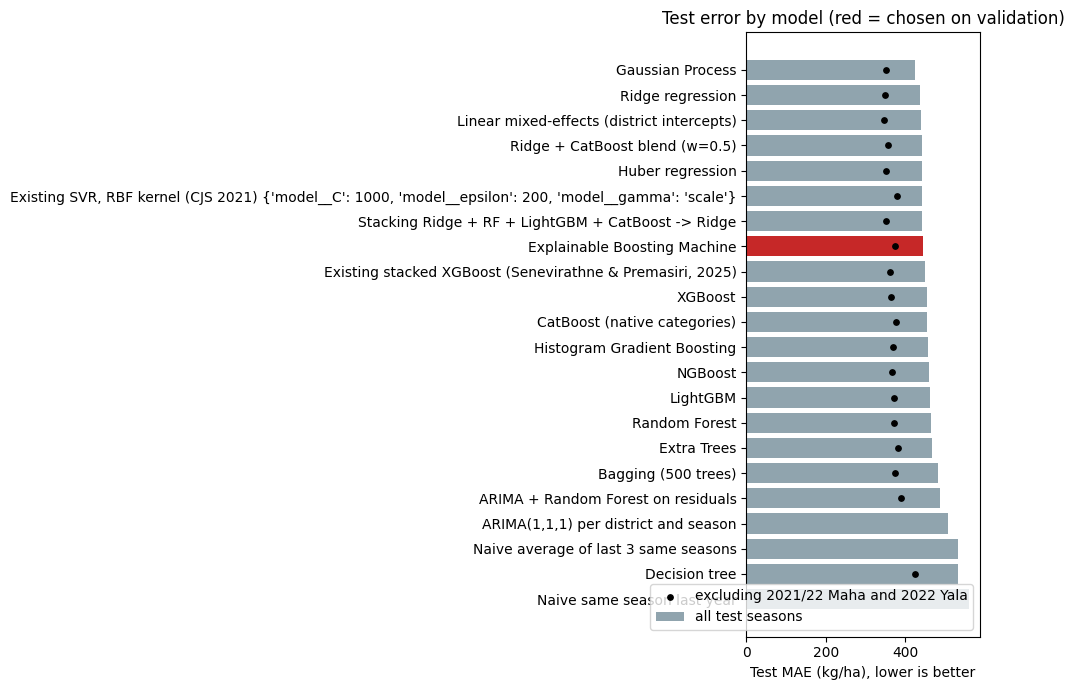

In [112]:
plot_df = table.dropna(subset=["CV MAE"]).sort_values("Test MAE")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(plot_df["Model"], plot_df["Test MAE"], color=["#C62828" if m == best_name else "#90A4AE" for m in plot_df["Model"]], label="all test seasons")
ax.scatter(plot_df["Test MAE excl. fertilizer-ban seasons"], plot_df["Model"], color="black", zorder=3, s=15, label="excluding 2021/22 Maha and 2022 Yala")
ax.invert_yaxis()
ax.set_xlabel("Test MAE (kg/ha), lower is better")
ax.set_title("Test error by model (red = chosen on validation)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Results on the test seasons (2017 Yala to 2025/26 Maha, 446 district-seasons) are summarised below.

- Every learned model outperforms the naive baselines, the single decision tree only narrowly (533 vs 532). The chosen EBM has MAE 446 kg/ha (12.4% average error) and R² 0.58, against 532 and 0.43 for the three-season average and 509 and 0.48 for ARIMA.
- The ranking differs from validation. The smooth models perform best on unseen seasons, namely the Gaussian Process (426, R² 0.60), Ridge (438), the mixed-effects model (441), the blend (443), Huber regression (443) and stacking (443), followed by the EBM (446), while NGBoost, best on validation, falls to 459.
- The tree ensembles (NGBoost, XGBoost, CatBoost, LightGBM, Random Forest, Bagging, Extra Trees) perform worse on test than in validation and worse than models with a linear or smooth component (see 14.2). After 2017 yields reached record highs (2018-2020) and then collapsed (2021/22). Trees predict only within the range they have seen and cannot follow such shifts, whereas linear and kernel models can extrapolate. The EBM lies between the two, building its curves from trees but adding them one feature at a time like a linear model.
- Excluding the two fertilizer-ban seasons, every model improves substantially (the EBM reaches MAE 374 and R² 0.72, and Ridge 349 and R² 0.74), so a large part of the test error comes from those two seasons alone.

Overfitting is checked directly by comparing each model's error on the training seasons it learned from with its error on the validation years and the test seasons. A model that fits its training data far better than new seasons has memorised rather than learned.

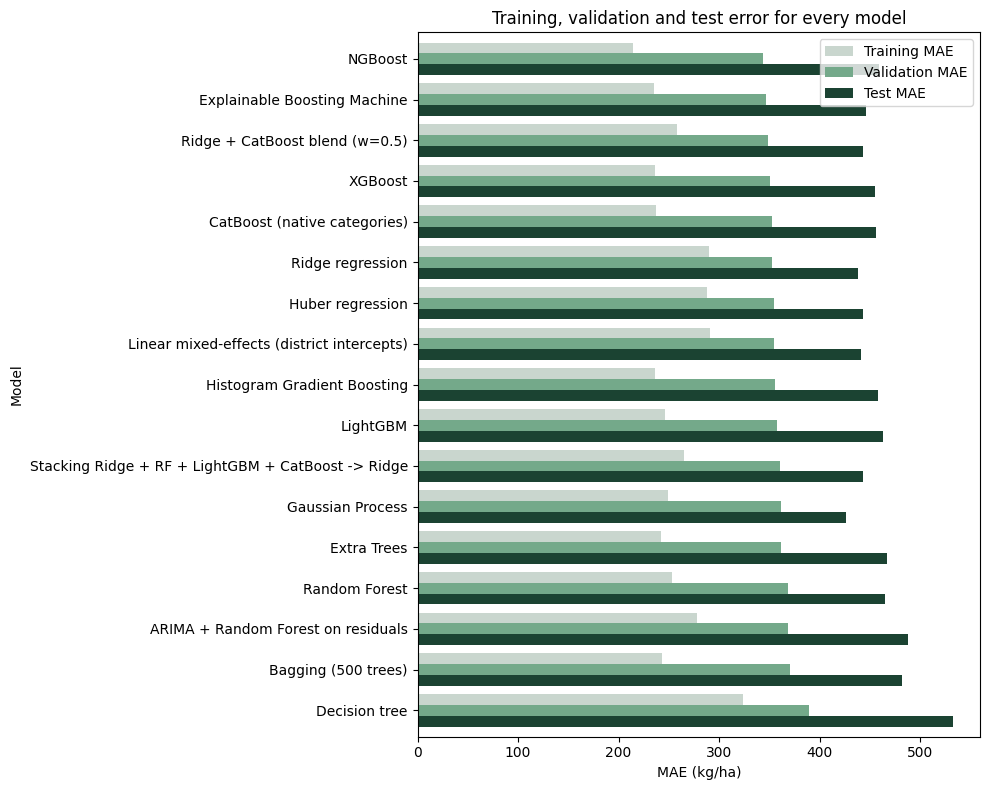

Explainable Boosting Machine training MAE 235.2 | validation 346.6 | test 446.2


,Training MAE,Validation MAE,Test MAE,test / training
Model,,,,
NGBoost,214.06,343.22,459.31,2.15
Explainable Boosting Machine,235.18,346.63,446.19,1.90
Ridge + CatBoost blend (w=0.5),258.40,348.12,442.96,1.71
XGBoost,235.72,350.08,455.41,1.93
CatBoost (native categories),236.95,352.58,456.39,1.93
Ridge regression,290.05,352.94,438.05,1.51
Huber regression,287.73,354.32,443.31,1.54
Linear mixed-effects (district intercepts),291.21,354.83,441.11,1.51
Histogram Gradient Boosting,235.83,355.16,458.42,1.94


In [113]:
by_name = pd.DataFrame(results).set_index("Model")
fit_rows = []
for name, model in fitted.items():
    fit_rows.append({"Model": name, "Training MAE": mean_absolute_error(y_train, model.predict(X_train)),
                     "Validation MAE": by_name.loc[name, "CV MAE"], "Test MAE": by_name.loc[name, "Test MAE"]})
fit_check = pd.DataFrame(fit_rows).set_index("Model")
fit_check["test / training"] = fit_check["Test MAE"] / fit_check["Training MAE"]
fit_check = fit_check.sort_values("Validation MAE")

ax = fit_check[["Training MAE", "Validation MAE", "Test MAE"]].plot.barh(figsize=(10, 8), color=["#C9D6CE", "#74A98A", "#1B4332"], width=0.8)
ax.invert_yaxis()
ax.set_xlabel("MAE (kg/ha)")
ax.set_title("Training, validation and test error for every model")
plt.tight_layout()
plt.show()
print(f"{best_name} training MAE {fit_check.loc[best_name, 'Training MAE']:.1f} | validation {fit_check.loc[best_name, 'Validation MAE']:.1f}"
      f" | test {fit_check.loc[best_name, 'Test MAE']:.1f}")
fit_check.round(2)

Every model fits its training seasons more closely than new seasons, as expected. The gap from training to validation is larger for the flexible tree-based models (the EBM from 235 to 347 kg/ha, NGBoost from 214 to 343 and XGBoost from 236 to 350) than for the linear models (Ridge from 290 to 353), which is the usual trade-off between flexibility and stability. The flexible models still reach the lowest validation errors, so much of their closer fit to the training seasons is genuine signal rather than memorisation.

NGBoost fits its training seasons most closely and falls furthest on test (459 kg/ha), which is consistent with the stability rule in 12.6 that chose the steadier EBM over it, and the EBM was indeed better on test (446 kg/ha). The rise from validation to test, between about 65 and 115 kg/ha for the strongest models, affects every model and reflects the harder test period of record yields followed by the 2021/22 collapse rather than overfitting of any one model.

### <b>14.2 Season by Season, and the Fertilizer Ban</b>

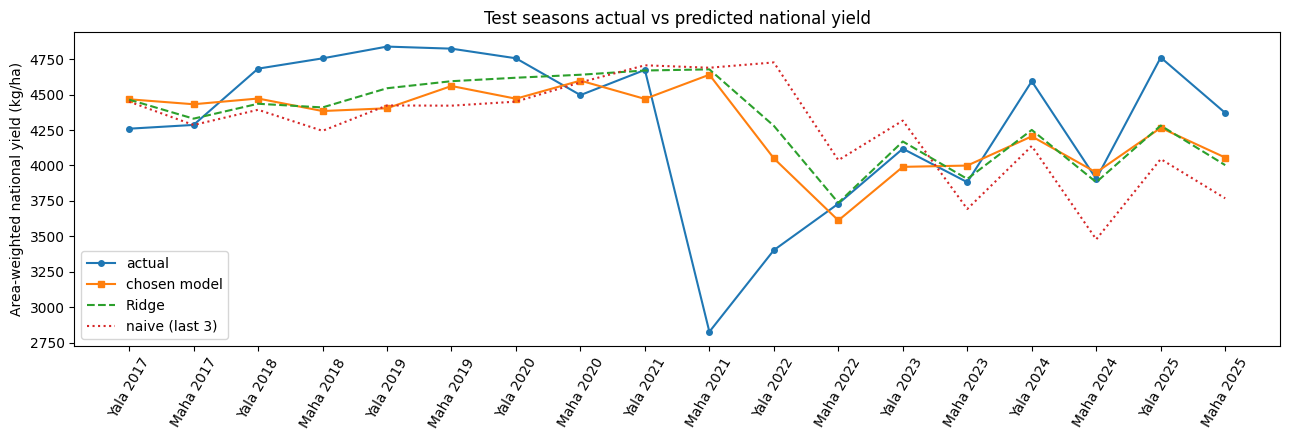

,actual,chosen model,Ridge,naive (last 3),MAE chosen
t,,,,,
2017.25,4259.0,4467.0,4464.0,4450.0,358.0
2017.75,4286.0,4432.0,4330.0,4285.0,288.0
2018.25,4682.0,4472.0,4435.0,4393.0,361.0
2018.75,4755.0,4384.0,4409.0,4244.0,528.0
2019.25,4838.0,4403.0,4544.0,4423.0,572.0
2019.75,4823.0,4560.0,4594.0,4422.0,352.0
2020.25,4755.0,4471.0,4618.0,4450.0,453.0
2020.75,4496.0,4598.0,4639.0,4586.0,306.0
2021.25,4674.0,4469.0,4669.0,4706.0,383.0


In [114]:
best_model = fitted[best_name]
test_df["pred_best"] = best_model.predict(X_test)
test_df["pred_ridge"] = fitted["Ridge regression"].predict(X_test)
test_df["pred_naive"] = test_df["yield_same_season_roll3"]

by_season = test_df.groupby("t").apply(lambda g: pd.Series({
    "actual": np.average(g.yield_kg_ha, weights=g.sown_ha), "chosen model": np.average(g.pred_best, weights=g.sown_ha),
    "Ridge": np.average(g.pred_ridge, weights=g.sown_ha), "naive (last 3)": np.average(g.pred_naive, weights=g.sown_ha),
    "MAE chosen": mean_absolute_error(g.yield_kg_ha, g.pred_best)}))
labels = [f"{'Maha' if t % 1 == 0.75 else 'Yala'} {int(t)}" for t in by_season.index]

plt.figure(figsize=(13, 4.5))
for col, style in [("actual", "-o"), ("chosen model", "-s"), ("Ridge", "--"), ("naive (last 3)", ":")]:
    plt.plot(labels, by_season[col], style, label=col, markersize=4)
plt.xticks(rotation=60)
plt.ylabel("Area-weighted national yield (kg/ha)")
plt.title("Test seasons actual vs predicted national yield")
plt.legend()
plt.tight_layout()
plt.show()
by_season.round(0)

National estimates track actual yields within 100-450 kg/ha in normal seasons, with two exceptions.

- Record yields in 2018-2020. Like the naive baseline, the model underestimates Yala 2018 to Yala 2020 by about 210-435 kg/ha, as tree models cannot extrapolate beyond the training range.
- The fertilizer ban in 2021/22 Maha and 2022 Yala. The model predicted a normal season (about 4,640 kg/ha nationally) against an actual 2,828, and the mean district error in Maha 2021/22 was 1,480 kg/ha, three to five times normal. Fertilizer supply was tested as a feature (10.1 and Section 11), but national import figures do not capture a policy shock. With no precedent in 1981-2016, this is a limitation of the data rather than of any algorithm, and such a shock must enter as information (for example district fertilizer distribution figures) or human judgement.
- Rapid recovery. From 2022/23 the history features (lag and three-season average) include the crash, and errors return to around 270-450 kg/ha.

### <b>14.3 By District</b>

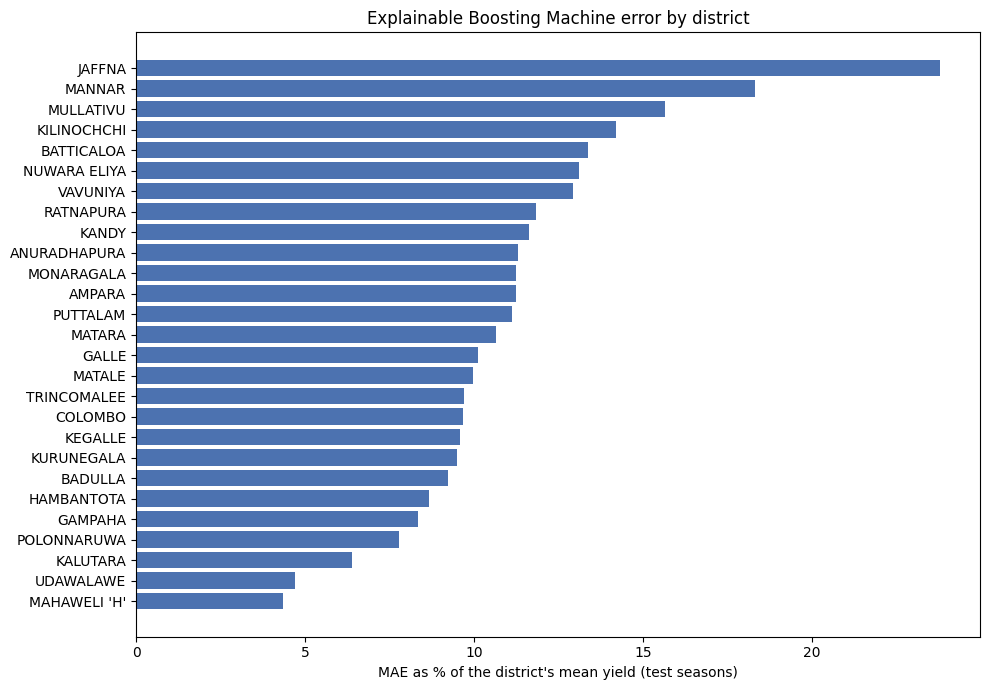

,seasons,MAE,mean_yield,MAE_pct
district,,,,
MAHAWELI 'H',3,233.8,5365.3,4.4
UDAWALAWE,3,292.7,6228.3,4.7
KALUTARA,18,190.0,2972.5,6.4
POLONNARUWA,17,383.3,4930.3,7.8
KILINOCHCHI,18,540.4,3807.2,14.2
MULLATIVU,18,628.8,4014.3,15.7
MANNAR,18,791.5,4320.2,18.3
JAFFNA,9,650.1,2733.4,23.8


In [115]:
district_err = (test_df.assign(abs_err=(test_df.pred_best - test_df.yield_kg_ha).abs())
                .groupby("district").agg(seasons=("abs_err", "size"), MAE=("abs_err", "mean"), mean_yield=("yield_kg_ha", "mean"))
                .assign(MAE_pct=lambda d: d.MAE / d.mean_yield * 100).sort_values("MAE_pct"))
plt.figure(figsize=(10, 7))
plt.barh(district_err.index, district_err["MAE_pct"], color="#4C72B0")
plt.xlabel("MAE as % of the district's mean yield (test seasons)")
plt.title(f"{best_name} error by district")
plt.tight_layout()
plt.show()
pd.concat([district_err.head(4), district_err.tail(4)]).round(1)

Accuracy is highest for the large irrigated and stable wet-zone districts (Mahaweli 'H', Udawalawe, Kalutara and Polonnaruwa, 4-8% average error) and lowest in the north (Kilinochchi, Mullaitivu, Mannar and Jaffna, 14-24%).

These northern districts are mostly rainfed or minor-irrigation, so a single dry spell or flood alters the yield substantially, and war-year gaps (6.1, 6.4) weaken their lag features. Estimates for the Northern Province therefore require a wider margin.

### <b>14.4 Statistical Significance of the Differences</b>

A Wilcoxon signed-rank test on the absolute errors of each test district-season tests whether one model's errors are systematically smaller than another's, without assuming normality.

In [116]:
abs_err = {name: np.abs(fitted[name].predict(X_test) - y_test.values) for name in fitted}
abs_err["Naive average of last 3 same seasons"] = np.abs(test_df.yield_same_season_roll3.values - y_test.values)
pairs = [(best_name, "Ridge regression"), (best_name, "XGBoost"), (best_name, "CatBoost (native categories)"), (best_name, "Random Forest"),
         (best_name, "Naive average of last 3 same seasons"), ("Ridge regression", "Random Forest")]
rows = []
for a, b in pairs:
    if a == b:
        continue
    stat, p = wilcoxon(abs_err[a], abs_err[b])
    rows.append({"Model A": a, "Model B": b, "mean |error| A": abs_err[a].mean(), "mean |error| B": abs_err[b].mean(), "p-value": p})
pd.DataFrame(rows).round(4)

,Model A,Model B,mean |error| A,mean |error| B,p-value
0,Explainable Boosting Machine,Ridge regression,446.191,438.051,1.372e-01
1,Explainable Boosting Machine,XGBoost,446.191,455.415,3.887e-01
2,Explainable Boosting Machine,CatBoost (native categories),446.191,456.390,7.660e-02
3,Explainable Boosting Machine,Random Forest,446.191,465.058,1.164e-01
4,Explainable Boosting Machine,Naive average of last 3 same seasons,446.191,532.346,0.000e+00
5,Ridge regression,Random Forest,438.051,465.058,1.000e-04


- The chosen EBM and Ridge, the best simple model on test, are not significantly different (446 vs 438, p = 0.14), nor is the EBM different from XGBoost (p = 0.39), CatBoost (p = 0.08) or Random Forest (p = 0.12).
- The EBM is significantly better than the naive three-season average (p < 0.001), and Ridge than Random Forest (p < 0.001).

The EBM is therefore statistically equivalent to the best simple model and the main ensembles, and substantially better than the baselines. Differences among the stronger models are small relative to season-to-season noise, and the test period of record highs and an unprecedented crash favours smooth extrapolators.

A single model without comparison would give no basis for judging its accuracy. In this study 20 approaches were compared and the choice was made on validation data. Most of the value comes from the history and irrigation features, so feature choice matters more than algorithm choice.

### <b>14.5 Accuracy in Planning Terms</b>

MAE and R² are standard, but a planner requires knowledge of how often an estimate is usable and how accurate the total harvest estimate is. Three measures address this.

- Accuracy, defined as 100% minus the mean absolute percentage error, with the share of district-seasons within 10%, 15% and 20% of the official yield.
- District production in tonnes, the yield estimate multiplied by the sown extent and by the district's median harvested-to-sown ratio in the training years, all known at season end. It is compared with the official yield multiplied by the harvested extent.
- National production per season, the sum over districts, which determines rice imports.

In [117]:
pct_error = (test_df.pred_best - test_df.yield_kg_ha).abs() / test_df.yield_kg_ha * 100
naive_error = (test_df.pred_naive - test_df.yield_kg_ha).abs() / test_df.yield_kg_ha * 100
planning_rows = []
for label, e in [("chosen model, all test seasons", pct_error), ("chosen model, without the 2 ban seasons", pct_error[~is_shock]),
                 ("naive last 3 seasons, all test seasons", naive_error)]:
    planning_rows.append({"": label, "accuracy (100 - MAPE)": 100 - e.mean(), "median % error": e.median(),
                          "within 10%": (e <= 10).mean() * 100, "within 15%": (e <= 15).mean() * 100, "within 20%": (e <= 20).mean() * 100})
pd.DataFrame(planning_rows).set_index("").round(1)

,accuracy (100 - MAPE),median % error,within 10%,within 15%,within 20%
,,,,,
"chosen model, all test seasons",87.6,8.4,57.4,75.1,86.1
"chosen model, without the 2 ban seasons",90.6,7.4,62.7,80.9,92.7
"naive last 3 seasons, all test seasons",85.2,10.1,49.1,67.9,79.4


In [118]:
usual_harvest = (train_df.harvested_ha / train_df.sown_ha).groupby([train_df.district, train_df.season]).median()
test_df["production_est_t"] = test_df.pred_best * test_df.sown_ha * [usual_harvest.get((d, s), np.nan) for d, s in zip(test_df.district, test_df.season)] / 1000
test_df["production_t"] = test_df.yield_kg_ha * test_df.harvested_ha / 1000
ok = test_df[["production_est_t", "production_t"]].notna().all(axis=1).values
print(f"District production R2 {r2_score(test_df.production_t[ok], test_df.production_est_t[ok]):.3f}"
      f" | without the ban seasons {r2_score(test_df.production_t[ok & ~is_shock], test_df.production_est_t[ok & ~is_shock]):.3f}"
      f" | median error {((test_df.production_est_t - test_df.production_t).abs() / test_df.production_t)[ok].median() * 100:.1f}% ({ok.sum()} district-seasons)")
national = test_df[ok].groupby("t")[["production_t", "production_est_t"]].sum() / 1000
national["error %"] = (national.production_est_t / national.production_t - 1) * 100
national.index = [f"{'Maha' if t % 1 == 0.75 else 'Yala'} {int(t)}" for t in national.index]
print(f"National production per season mean absolute error {national['error %'].abs().mean():.1f}%,"
      f" {national['error %'].abs().drop(['Maha 2021', 'Yala 2022']).mean():.1f}% without the ban seasons")
national.rename(columns={"production_t": "actual (000 t)", "production_est_t": "estimated (000 t)"}).round(1)

District production R2 0.952 | without the ban seasons 0.981 | median error 9.8% (446 district-seasons)
National production per season mean absolute error 9.5%, 5.8% without the ban seasons


,actual (000 t),estimated (000 t),error %
Yala 2017,1011.5,1099.7,8.7
Maha 2017,2659.3,2875.8,8.1
Yala 2018,1701.9,1642.9,-3.5
Maha 2018,3439.5,3183.8,-7.4
Yala 2019,1691.8,1598.2,-5.5
Maha 2019,3574.9,3329.3,-6.9
Yala 2020,2146.6,2002.7,-6.7
Maha 2020,3434.3,3436.0,0.0
Yala 2021,2326.7,2196.8,-5.6
Maha 2021,2169.3,3492.8,61.0


- Accuracy is 87.6%, with a mean deviation of 12.4% and a median of 8.4%, or 90.6% and 7.4% without the two ban seasons.
- 86% of estimates fall within 20% of the official yield, 75% within 15% and 57% within 10%. Without the ban seasons 93% are within 20%. The naive three-season average reaches 79%.
- District production has an R² of 0.95 (0.98 without the ban seasons) and a median error of 9.8%. This exceeds the yield R² (0.58) mainly because district sizes differ greatly and the sown extent is known, which reflects the planning scale rather than a better model.
- National production was within 12.1% of the official figure in every season except the two ban seasons, and within 5.8% on average, with overestimates of 61% in Maha 2021/22 and 17% in Yala 2022. Outside the policy shock, the total that matters for import planning was within about 6%.

### <b>14.6 Further Error Measures</b>

MAE and R² summarise the error but leave three questions open, namely whether the model is biased in one direction, how large a typical error is when a few extreme seasons are set aside, and how much better it is than a naive forecast. The measures below address them for the chosen model, the strongest alternatives and the baselines.

- Median absolute error, the error that half of the estimates stay within. It is less affected than MAE by the two ban seasons.
- Bias, the mean of estimate minus actual. A positive value means systematic overestimation, the costlier mistake for import planning.
- MASE (mean absolute scaled error, Hyndman and Koehler, 2006), the test MAE divided by the MAE of the same-season-last-year forecast on the training seasons. It allows models to be compared on a common scale.
- Skill against the three-season average, one minus the ratio of the two test MAEs, the share of the naive error the model removes.

The Diebold-Mariano test (Diebold and Mariano, 1995) then asks whether two forecasts differ in accuracy over time. The district errors are averaged per season, because districts in the same season share their weather and are not independent, and the test is run on the 18 seasonal differences. It complements the Wilcoxon test in 14.4, which treats each district-season separately.

In [119]:
from scipy import stats
from sklearn.metrics import median_absolute_error

has_lag_train = train_df.yield_same_season_lag1.notna()
naive_scale = mean_absolute_error(train_df.yield_kg_ha[has_lag_train], train_df.yield_same_season_lag1[has_lag_train])
naive3_mae = mean_absolute_error(y_test, test_df.yield_same_season_roll3)
compared = [best_name, "Ridge regression", "Gaussian Process", "XGBoost", "Random Forest", "NGBoost"]
test_preds = {name: fitted[name].predict(X_test) for name in compared}
test_preds["Naive average of last 3 same seasons"] = test_df.yield_same_season_roll3.values
test_preds["ARIMA(1,1,1) per district and season"] = test_df.arima_forecast.fillna(test_df.yield_same_season_roll3).values
measure_rows = []
for name, pred in test_preds.items():
    mae = mean_absolute_error(y_test, pred)
    measure_rows.append({"Model": name, "MAE": mae, "median absolute error": median_absolute_error(y_test, pred),
                         "bias (estimate - actual)": float(np.mean(pred - y_test.values)), "MASE": mae / naive_scale,
                         "skill vs 3-season average %": (1 - mae / naive3_mae) * 100})
print(f"MASE scale, same season last year on the training seasons {naive_scale:.1f} kg/ha")
further_measures = pd.DataFrame(measure_rows).set_index("Model")
further_measures.round(2)

MASE scale, same season last year on the training seasons 354.9 kg/ha


,MAE,median absolute error,bias (estimate - actual),MASE,skill vs 3-season average %
Model,,,,,
Explainable Boosting Machine,446.19,327.78,-16.10,1.26,16.18
Ridge regression,438.05,308.63,34.75,1.23,17.71
Gaussian Process,425.96,302.64,6.49,1.20,19.98
XGBoost,455.41,323.21,28.00,1.28,14.45
Random Forest,465.06,337.86,-6.79,1.31,12.64
NGBoost,459.31,307.03,51.04,1.29,13.72
Naive average of last 3 same seasons,532.35,404.67,9.90,1.50,0.00
"ARIMA(1,1,1) per district and season",509.19,377.27,-3.14,1.43,4.35


In [120]:
def diebold_mariano(pred_a, pred_b):
    # loss differential of absolute errors, averaged per season, tested against zero with a t distribution
    d = pd.Series(np.abs(pred_a - y_test.values) - np.abs(pred_b - y_test.values)).groupby(test_df.t.values).mean()
    statistic = d.mean() / np.sqrt(d.var(ddof=1) / len(d))
    return d.mean(), statistic, 2 * stats.t.sf(abs(statistic), df=len(d) - 1), len(d)


dm_rows = []
for other in ["Ridge regression", "Gaussian Process", "XGBoost", "Random Forest", "NGBoost", "Naive average of last 3 same seasons",
              "ARIMA(1,1,1) per district and season"]:
    mean_d, statistic, p_value, n_seasons = diebold_mariano(test_preds[best_name], test_preds[other])
    dm_rows.append({"compared with": other, "mean difference in |error| (kg/ha)": mean_d, "DM statistic": statistic, "p-value": p_value,
                    "seasons": n_seasons})
pd.DataFrame(dm_rows).set_index("compared with").round(3)

,mean difference in |error| (kg/ha),DM statistic,p-value,seasons
compared with,,,,
Ridge regression,8.679,0.522,0.609,18
Gaussian Process,20.625,2.010,0.061,18
XGBoost,-9.360,-0.462,0.650,18
Random Forest,-19.167,-0.753,0.462,18
NGBoost,-13.110,-0.735,0.472,18
Naive average of last 3 same seasons,-86.922,-2.465,0.025,18
"ARIMA(1,1,1) per district and season",-63.096,-1.890,0.076,18


- The EBM has a median absolute error of 328 kg/ha, so half of its district estimates lie within 328 kg/ha of the official yield, against 405 kg/ha for the three-season average.
- Its bias is small, -16 kg/ha, a slight underestimate on average, while Ridge (+35 kg/ha) and NGBoost (+51 kg/ha) overestimate.
- Every model, including the baselines, has a MASE above 1 (the EBM 1.26, the three-season average 1.50), because the scale is the naive error on the training seasons and the test period is harder. The comparison between models is therefore what matters. Measured against the same-season-last-year forecast on the test seasons themselves, the EBM error is 0.80 of the naive error (446 against 561 kg/ha).
- The EBM removes 16% of the error of the three-season average, against 18% for Ridge and 20% for the Gaussian Process.

The Diebold-Mariano test on the 18 seasonal error differences agrees with the Wilcoxon test in 14.4. The EBM is significantly better than the three-season average (p = 0.025), while its differences from Ridge (p = 0.61), XGBoost (p = 0.65), Random Forest (p = 0.46) and NGBoost (p = 0.47) are not significant. The differences from the Gaussian Process (p = 0.061) and ARIMA (p = 0.076) are borderline and not significant at the 5% level.

With only 18 test seasons the test has limited power. The conclusion is that the strongest models cannot be separated on these seasons, while the gain over the naive baseline is genuine.

The regression lectures also list assumptions about the errors themselves. They should not be correlated from one season to the next (no autocorrelation), and their spread should not grow with the size of the estimate (homoscedasticity). Both are checked on the test seasons for the chosen model and Ridge.

- The Durbin-Watson statistic is computed for each district's errors in time order. A value near 2 means no autocorrelation, and values well below 2 mean that a high error tends to be followed by another high error.
- The Spearman correlation between the size of each error and the estimate shows whether larger estimates carry larger errors.

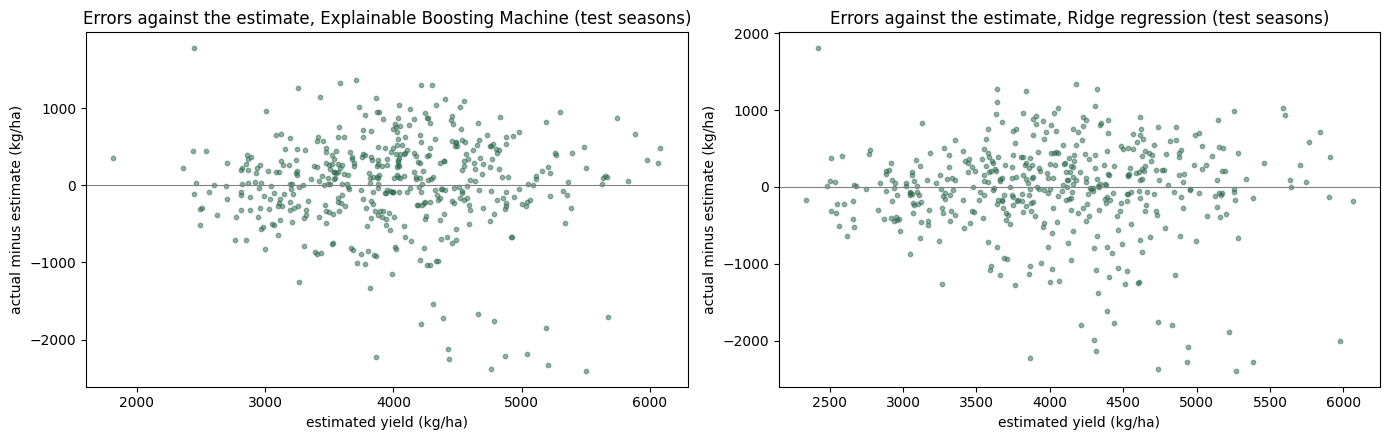

,median Durbin-Watson by district,lowest,highest,districts below 1.5,"Spearman, error size against estimate",p-value
model,,,,,,
Explainable Boosting Machine,1.683,0.215,2.363,8,0.109,0.022
Ridge regression,1.485,0.616,2.074,14,0.143,0.002


In [121]:
from scipy.stats import spearmanr
from statsmodels.stats.stattools import durbin_watson

residual_rows, residual_plots = [], {}
for name in [best_name, "Ridge regression"]:
    estimate = fitted[name].predict(X_test)
    errors = test_df.assign(error=y_test.values - estimate, estimate=estimate).sort_values(["district", "t"])
    dw = errors.groupby("district")["error"].apply(lambda s: durbin_watson(s.values))
    spread = spearmanr(errors.estimate, errors.error.abs())
    residual_plots[name] = errors
    residual_rows.append({"model": name, "median Durbin-Watson by district": dw.median(), "lowest": dw.min(), "highest": dw.max(),
                          "districts below 1.5": int((dw < 1.5).sum()), "Spearman, error size against estimate": spread.correlation, "p-value": spread.pvalue})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (name, errors) in zip(axes, residual_plots.items()):
    ax.scatter(errors.estimate, errors.error, s=10, alpha=0.5, color="#2D6A4F")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xlabel("estimated yield (kg/ha)")
    ax.set_ylabel("actual minus estimate (kg/ha)")
    ax.set_title(f"Errors against the estimate, {name} (test seasons)")
plt.tight_layout()
plt.show()
pd.DataFrame(residual_rows).set_index("model").round(3)

The errors show mild autocorrelation. The median Durbin-Watson statistic across districts is 1.68 for the chosen model and 1.49 for Ridge, slightly below the value of 2 that means none, and 8 of the 27 districts fall below 1.5 for the chosen model (14 for Ridge). A district that is underestimated in one season therefore tends to be underestimated in the next, which matches the run of record highs from 2017 and the fall during the fertilizer ban.

The spread of the errors grows only a little with the estimate (Spearman 0.11 for the chosen model and 0.14 for Ridge). The relationship is statistically significant but weak, so the errors are close to homoscedastic.

Neither finding invalidates the comparison, as all models are scored on the same seasons. The autocorrelation does mean that consecutive errors are not independent, which is why the Diebold-Mariano test above averages the errors per season.

### <b>14.7 Strengths and Limitations of Each Model Family</b>

- Naive baselines and ARIMA. They are transparent, need no training and are strong because yields change slowly (the three-season average reaches 366 kg/ha on validation). They cannot use weather, irrigation or policy, and ARIMA fitted to about 45 seasons per district is noisy (375 kg/ha on validation, weaker than the simple average).
- Linear models (Ridge, Huber regression and the mixed-effects model). They are stable, their coefficients are readable, and they extrapolate beyond the training range, which helped on the test seasons (438-443 kg/ha). They assume additive straight-line effects, so they miss thresholds such as the heavy-rain penalty, and correlated inputs must be interpreted jointly.
- The single decision tree. It is the easiest model to read, but its step-like predictions and high variance make it the weakest learned model (390 kg/ha on validation, 533 on test).
- Bagging, Random Forest and Extra Trees. Averaging many trees reduces variance and needs little preprocessing, but averaged leaves pull estimates towards the middle and trees cannot exceed the yields seen in training, so record seasons were underestimated (465-482 kg/ha on test).
- Boosting (XGBoost, LightGBM, CatBoost and Histogram Gradient Boosting). They are among the most accurate on validation (350-357 kg/ha) and capture non-linear effects and interactions, but they require careful regularisation and early stopping (12.3), cannot extrapolate and need SHAP to be explained.
- NGBoost. It had the lowest validation error (343 kg/ha) and predicts a full distribution, but its intervals were overconfident (46% coverage for a nominal 80%, Section 18.1) and its error varied most between years, rising to 459 kg/ha on test.
- Gaussian Process. Its smooth predictions extrapolate gently and gave the lowest test error (426 kg/ha), but it was only mid-ranking on validation (361 kg/ha), its training cost grows with the cube of the number of rows, and its accuracy depends on the choice of kernel.
- Stacking and hybrids. Combining models gave mixed validation results (the blend 348 kg/ha, and stacking 360 kg/ha once built only from forecasts of earlier years) at the cost of complexity and a harder explanation, and the ARIMA residual hybrid did not improve on the Random Forest.
- Explainable Boosting Machine. It was within 1% of the best on validation (347 kg/ha) with the steadiest year-to-year error, every estimate decomposes exactly into feature contributions, and each learned curve can be checked against agronomy (17.4). Its terms are built from trees, so it shares their inability to extrapolate beyond the training range.

## <center><b>15. Further Experiments</b></center>

The experiments in this section were added after the main analysis was complete, once the features, the model and the test results in Sections 10 to 14 had been fixed. By then the same seven validation years had informed every earlier decision. Testing many further ideas on the same years makes some of them appear better by chance, which is known as overfitting to the validation set.

The results below are therefore reported but are not allowed to change the final model. For transparency, the most promising alternatives are also scored on the test seasons (15.4 and 15.5). Choosing among them by test score would turn the test seasons into another validation set, so the final model remains unchanged regardless of the result.

### <b>15.1 Further Candidate Features</b>

Six further feature sets were tested in the same way as in Section 10.1, against the same reference set C.

- M. C plus soil moisture and evapotranspiration over the growing months.
- N. C plus proxies for tank storage and planting conditions (rain in the six months before, soil moisture at planting).
- O. C plus the hottest month of the season (heat at flowering).
- P. C plus the harvested share. It leaks the target, is never a candidate and only shows the size of the leak.
- Q. C plus the weather at each growth stage (heat at flowering, night temperature and sunshine while ripening, rain at harvest).
- R. C plus the four qualitative features (policy regime, province, climate zone and El Niño phase).

In [122]:
late_sets = {
    "M. C + soil moisture, evaporation": set_c + ["soil_moisture", "soil_moisture_min", "et0_total"],
    "N. C + tank storage, planting moisture": set_c + ["rain_storage", "soil_moisture_start"],
    "O. C + heat at flowering": set_c + ["tmax_hottest_month"],
    "P. C + harvested share (a leak)": set_c + ["harvested_share"],
    "Q. C + weather by crop stage": set_c + ["tmax_flowering", "tmin_ripening", "solar_ripening", "rain_harvest_month"],
    "R. C + qualitative features": set_c + qualitative_features,
}
late_rows = []
for set_name, num in late_sets.items():
    for target in ["yield", "change from average"]:
        row = {"features": set_name, "target": target}
        for name in ["Ridge", "XGBoost", "CatBoost"]:
            make = (lambda: OnAverage(model_for(name, num))) if target != "yield" else (lambda: model_for(name, num))
            row[name] = cv_scores(make, X=train_df, y=y_train)[0]
        row["average of the three"] = np.mean([row[m] for m in ["Ridge", "XGBoost", "CatBoost"]])
        row["EBM"] = cv_scores(lambda: ebm_for(num), X=train_df, y=y_train)[0] if target == "yield" else np.nan
        late_rows.append(row)
late_experiments = pd.DataFrame(late_rows)
print(f"{len(late_sets)} further feature sets {len(late_sets) * (2 * 3 + 1) * len(cv_folds)} models trained in this cell, "
      f"{(len(feature_sets) + len(late_sets)) * (2 * 3 + 1) * len(cv_folds)} for all feature sets together")

late_on_yield = late_experiments[late_experiments.target == "yield"].set_index("features")["average of the three"]
base_mae = on_yield["C. B + dry spell, heavy-rain days"]
for step in late_sets:
    new_mae = late_on_yield[step]
    if step.startswith("P."):
        print(f"{step:38s} {base_mae:6.1f} -> {new_mae:6.1f} ({(new_mae / base_mae - 1) * 100:+.1f}%)  a leak, never allowed")
        continue
    passes = new_mae < base_mae * 0.99
    decisions[step] = (new_mae / base_mae - 1) * 100, "late check, passes the bar, reported only" if passes else "late check, not kept"
    print(f"{step:38s} {base_mae:6.1f} -> {new_mae:6.1f} ({(new_mae / base_mae - 1) * 100:+.1f}%)  "
          f"{'passes the bar, reported only' if passes else 'does not pass the bar'}")

# from here on, the tables and the ledger cover every feature set
feature_sets.update(late_sets)
feature_experiments = pd.concat([feature_experiments, late_experiments], ignore_index=True)
on_yield = pd.concat([on_yield, late_on_yield])
late_experiments.round(1)

6 further feature sets 294 models trained in this cell, 882 for all feature sets together
M. C + soil moisture, evaporation       356.6 ->  357.4 (+0.2%)  does not pass the bar
N. C + tank storage, planting moisture  356.6 ->  358.7 (+0.6%)  does not pass the bar
O. C + heat at flowering                356.6 ->  356.5 (-0.0%)  does not pass the bar
P. C + harvested share (a leak)         356.6 ->  346.9 (-2.7%)  a leak, never allowed
Q. C + weather by crop stage            356.6 ->  351.2 (-1.5%)  passes the bar, reported only
R. C + qualitative features             356.6 ->  356.5 (-0.0%)  does not pass the bar


,features,target,Ridge,XGBoost,CatBoost,average of the three,EBM
0,"M. C + soil moisture, evaporation",yield,356.8,356.2,359.3,357.4,353.8
1,"M. C + soil moisture, evaporation",change from average,356.6,353.7,361.5,357.3,NaN
2,"N. C + tank storage, planting moisture",yield,355.2,359.4,361.5,358.7,351.8
3,"N. C + tank storage, planting moisture",change from average,354.9,351.9,359.8,355.5,NaN
4,O. C + heat at flowering,yield,354.8,357.5,357.3,356.5,349.0
5,O. C + heat at flowering,change from average,354.6,350.4,361.1,355.4,NaN
6,P. C + harvested share (a leak),yield,348.0,345.0,347.6,346.9,341.0
7,P. C + harvested share (a leak),change from average,347.7,344.1,351.1,347.6,NaN
8,Q. C + weather by crop stage,yield,352.3,352.1,349.3,351.2,337.6
9,Q. C + weather by crop stage,change from average,352.0,345.6,355.0,350.9,NaN


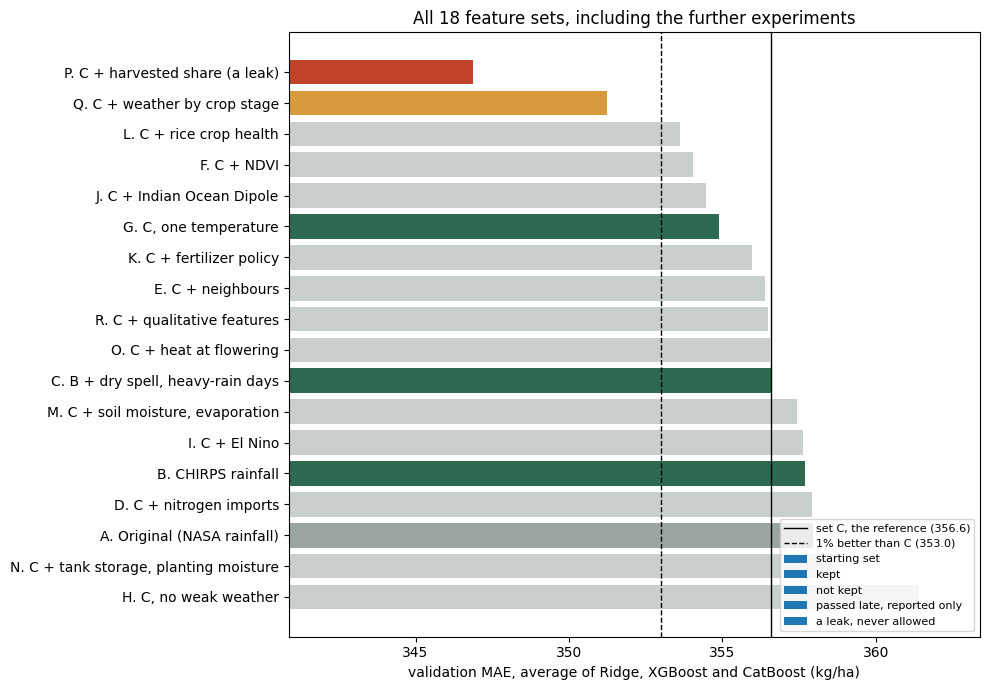

In [123]:
# every feature set on one chart, showing the average validation error of the three probe models coloured by the decision
base_c = on_yield["C. B + dry spell, heavy-rain days"]
outcome = {"A. Original (NASA rainfall)": "starting set", "P. C + harvested share (a leak)": "a leak, never allowed"}
for name, (change, decision) in decisions.items():
    outcome[name] = "kept" if decision == "kept" else ("passed late, reported only" if "passes" in decision else "not kept")
colours = {"starting set": "#9AA5A0", "kept": "#2D6A4F", "not kept": "#C9CFCB", "passed late, reported only": "#D89A3D", "a leak, never allowed": "#C1432C"}
order = on_yield.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(order.index, order.values, color=[colours[outcome.get(n, "not kept")] for n in order.index])
ax.axvline(base_c, color="black", linewidth=1, label=f"set C, the reference ({base_c:.1f})")
ax.axvline(base_c * 0.99, color="black", linewidth=1, linestyle="--", label=f"1% better than C ({base_c * 0.99:.1f})")
for label, colour in colours.items():
    ax.barh([], [], color=colour, label=label)
ax.set_xlim(order.min() - 6, order.max() + 2)
ax.set_xlabel("validation MAE, average of Ridge, XGBoost and CatBoost (kg/ha)")
ax.set_title("All 18 feature sets, including the further experiments")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

- Soil moisture and evaporation (M) are slightly worse (+0.2%). Soil moisture tracks season rainfall (correlation 0.76), adding little beyond CHIRPS, and none of the three measures moves with the yield change (correlations between -0.03 and 0.03, 7.1).
- The tank storage and planting proxies (N) are also worse (+0.6%), as rain over the six preceding months is an approximate indicator of reservoir storage and pre-season rain is already a feature.
- Heat at flowering (O) produces no change (0.0%), as a monthly average misses the few very hot days that damage grain.
- The harvested share (P) is the only substantially better addition (2.7% on average, the best in the table), which is precisely why it is problematic. Published with the yield, it contains part of the target information and shows how a leak inflates apparent performance. It is never a candidate.

- Weather at each growth stage (Q) is the one late addition to pass the 1% threshold, 1.5% better on average and helped by all three models. Harvest-month rain has the strongest link with the yield change among late additions (correlation -0.13, 7.1), consistent with wet harvests causing losses. Since sets M to Q followed the main analysis, the model is unchanged, and Section 15.4 checks the gain on the test seasons.

- The qualitative features (R) produce no change on average (0.0%), as Ridge, XGBoost and CatBoost already encode the district and province and climate zone are fixed per district. The Explainable Boosting Machine uses them differently (Section 15.4).

The EBM column shows the deployed model type responding most to the weather at each growth stage (337.6 against 346.9 for set C, 2.7% lower) and to the qualitative features (345.3). Section 15.4 checks whether these gains hold on the test seasons.

### <b>15.2 Contribution of Each Kept Feature</b>

The next question is whether every retained feature is justified. The steps above tested only added features, and the starting set (yield history, planting features and NASA weather) was never examined individually. A feature belongs in the final model only if it improves accuracy.

A drop-column test measures this. Each retained feature is removed in turn, the same three models are scored on the seven validation years, and the change in average error is recorded. An increase indicates that the feature is needed.

Unhelpful features are then removed one at a time, starting with the one whose removal reduced the error most, and each removal is kept only if the error does not rise. The stepwise order matters because two features carrying the same information can each appear unnecessary in isolation while the model still needs one of them.

As with sets M to R, this check followed the main analysis on validation years already used for every earlier decision, so its result is reported without changing the final set. Section 15.4 shows how the reduced set performed on the test seasons.

In [124]:
def three_model_mae(num):
    return np.mean([cv_scores(lambda: model_for(name, num), X=train_df, y=y_train)[0] for name in ["Ridge", "XGBoost", "CatBoost"]])


full_mae = three_model_mae(numeric_features)
drop_rows = []
for f in numeric_features:
    without = three_model_mae([c for c in numeric_features if c != f])
    drop_rows.append({"feature": f, "validation MAE without it": without, "change when removed %": (without / full_mae - 1) * 100})
drop_check = pd.DataFrame(drop_rows).set_index("feature").sort_values("change when removed %")

kept_features, kept_mae, removed = list(numeric_features), full_mae, []
for f in drop_check.index[drop_check["change when removed %"] <= 0]:
    trial = [c for c in kept_features if c != f]
    trial_mae = three_model_mae(trial)
    if trial_mae <= kept_mae:  # a simplification is kept if it is not worse
        kept_features, kept_mae = trial, trial_mae
        removed.append(f)
print(f"All {len(numeric_features)} features {full_mae:.1f} | without the ones that do not help {kept_mae:.1f} "
      f"({(kept_mae / full_mae - 1) * 100:+.1f}%) with {len(kept_features)} features")
print("Not helping on the validation years", removed if removed else "none", "| reported only, the final set is unchanged (15.4)")
drop_check.round(2)

All 21 features 354.9 | without the ones that do not help 347.3 (-2.1%) with 19 features
Not helping on the validation years ['national_prev_season', 'yield_same_season_lag1'] | reported only, the final set is unchanged (15.4)


,validation MAE without it,change when removed %
feature,,
national_prev_season,352.78,-0.59
yield_same_season_lag1,353.41,-0.41
rain_driest_month,354.68,-0.06
rh,355.03,0.04
tmax,355.19,0.09
dry_spell_days,355.29,0.12
rain_wettest_month,355.31,0.12
rain_anomaly_pct,355.36,0.13
share_minor,355.36,0.14


Nineteen of the 21 features are justified. Removing the three-season average worsens the error by 2.5% and removing solar radiation by 1.6%, followed by the rainfed share and the heavy-rain days (0.9% each). Every other feature also raises the error slightly when removed.

Two features provide no benefit, namely the national yield of the previous season (removal lowers the error by 0.6%) and the same season last year (0.4%). The latter is redundant because the three-season average and the ARIMA forecast already contain last year's yield. Removing both lowers the error by 2.1%.

As this check followed the main analysis, both features remain in the final set. Section 15.4 shows whether removing them is beneficial on the test seasons.

### <b>15.3 Standard Feature Selection Methods</b>

Section 10.1 added each new source alone, which shows whether one source helps but not whether another combination of candidates would perform better. Three standard feature selection methods examine this, each considering all candidates at once using only the training years and the seven validation years. The test seasons remain untouched.

Lasso (Tibshirani, 1996) is linear regression with an L1 penalty, the counterpart of the L2 penalty in Ridge. It shrinks the weights of unhelpful features to exactly zero, so the features retaining a weight are selected, with the penalty strength chosen on the validation years.

Permutation importance (Breiman, 2001) trains CatBoost, then shuffles one feature at a time in the validation year and measures how much the error rises. Shuffling an irrelevant feature changes nothing.

Backward elimination (Kohavi and John, 1997) starts from a Ridge model with every candidate and repeatedly removes the feature whose removal lowers the validation error most. It stops when any further removal would raise the error.

Because the methods work very differently, a feature kept by at least two is a robust choice. This consensus mix is compared with the final set (10.2).

A method that selects features on the validation years will always score well on those years. The seven validation years are therefore split, with features chosen on 2010 to 2013 only and judged on 2014 to 2016, which the methods never saw.

The same three models are used. As with sets M to Q, this check followed the main analysis, so its result is reported without changing the model. Section 15.4 shows how the consensus mix performed on the test seasons.

In [125]:
from sklearn.linear_model import LassoCV
from sklearn.inspection import permutation_importance

extra_sources = ["nitrogen_import_ratio", "neighbours_prev_ratio", "ndvi_anomaly", "ndvi_max", "enso_index", "iod_index", "fertilizer_support",
                 "rice_vci", "rice_tci", "rice_ndvi_peak", "soil_moisture", "soil_moisture_min", "et0_total",
                 "rain_storage", "soil_moisture_start", "tmax_hottest_month",
                 "tmax_flowering", "tmin_ripening", "solar_ripening", "rain_harvest_month"]
pool = set_c + extra_sources
print("Candidate features", len(pool))

# the methods select features on the first four validation years only, and the last three are reserved to evaluate the selection
select_folds, check_folds = cv_folds[:4], cv_folds[4:]


def folds_mae(make_model, num, folds):
    cols = categorical_features + num
    return np.mean([mean_absolute_error(y_train.iloc[va], make_model().fit(train_df.iloc[tr][cols], y_train.iloc[tr]).predict(train_df.iloc[va][cols]))
                    for tr, va in folds])

# 1. Lasso. An L1 penalty sets the weight of an unhelpful feature to exactly zero, and the penalty strength is selected on the yearly folds
lasso = Pipeline([("prep", ColumnTransformer([("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), pool),
                                              ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)])),
                  ("model", LassoCV(cv=select_folds, max_iter=50000, random_state=random_state))])
lasso.fit(train_df[categorical_features + pool], y_train)
lasso_weight = pd.Series(lasso.named_steps["model"].coef_[:len(pool)], index=pool)
by_lasso = set(lasso_weight[lasso_weight.abs() > 1e-6].index)

# 2. Permutation importance. One feature is shuffled in the validation year and the increase in CatBoost error is averaged over the folds
perm = []
for tr_idx, va_idx in select_folds:
    m = model_for("CatBoost", pool).fit(train_df.iloc[tr_idx][categorical_features + pool], y_train.iloc[tr_idx])
    r = permutation_importance(m, train_df.iloc[va_idx][categorical_features + pool], y_train.iloc[va_idx], scoring="neg_mean_absolute_error",
                               n_repeats=5, random_state=random_state)
    perm.append(pd.Series(r.importances_mean, index=categorical_features + pool))
perm_importance = pd.concat(perm, axis=1).mean(axis=1)[pool]
by_permutation = set(perm_importance[perm_importance > 0].index)

# 3. Backward elimination. Starting from every candidate, the feature whose removal most lowers the Ridge validation error is removed until no removal helps
current_set, current_mae = list(pool), folds_mae(lambda: model_for("Ridge", pool), pool, select_folds)
while True:
    trials = {f: folds_mae(lambda: model_for("Ridge", [c for c in current_set if c != f]), [c for c in current_set if c != f], select_folds) for f in current_set}
    worst, mae = min(trials.items(), key=lambda kv: kv[1])
    if mae >= current_mae:
        break
    current_set.remove(worst)
    current_mae = mae
by_backward = set(current_set)

votes = pd.DataFrame({"Lasso": [f in by_lasso for f in pool], "permutation": [f in by_permutation for f in pool],
                      "backward": [f in by_backward for f in pool]}, index=pool)
votes["votes"] = votes.sum(axis=1)
votes["in final set"] = [f in numeric_features for f in pool]
consensus = [f for f in pool if votes.loc[f, "votes"] >= 2]
print("Kept by Lasso", len(by_lasso), "| by permutation importance", len(by_permutation), "| by backward elimination", len(by_backward),
      "| by at least two of the three", len(consensus))
votes.sort_values(["votes", "in final set"], ascending=False)

Candidate features 43
Kept by Lasso 24 | by permutation importance 35 | by backward elimination 20 | by at least two of the three 28


,Lasso,permutation,backward,votes,in final set
yield_same_season_lag1,True,True,True,3,True
yield_same_season_roll3,True,True,True,3,True
yield_prev_season,True,True,True,3,True
share_rainfed,True,True,True,3,True
heavy_rain_days,True,True,True,3,True
ndvi_anomaly,True,True,True,3,False
iod_index,True,True,True,3,False
rice_ndvi_peak,True,True,True,3,False
et0_total,True,True,True,3,False
solar_ripening,True,True,True,3,False


All three methods agree on the core of the model. Last year's yield, the three-season average, the previous season, the rainfed share and the heavy-rain days are kept by every method, and most other history and planting features by two.

Beyond this core they disagree. Lasso keeps 24 of the 43 candidates, permutation importance 35 and backward elimination 20. All three select several late additions, such as sunshine during ripening, evapotranspiration, the Indian Ocean Dipole and greenness over the rice fields, while some CHIRPS rainfall details and the NASA wind and sunshine are dropped.

Rainfall, soil moisture, evapotranspiration and greenness all track wet and dry seasons, so each method may select a different one of them. Such disagreement is normal when features overlap. The 28 features kept by at least two methods form the consensus mix tested below.

In [126]:
# judged on 2014-2016, the validation years the selection methods never saw, with the same three models as in 10.1
compare = {}
for label, num in [("set chosen in 7.4", numeric_features), ("consensus of the three methods", consensus)]:
    compare[label] = {name: folds_mae(lambda: model_for(name, num), num, check_folds) for name in ["Ridge", "XGBoost", "CatBoost"]}
    compare[label]["the same, on the four years used to choose"] = np.mean([folds_mae(lambda: model_for(name, num), num, select_folds)
                                                                           for name in ["Ridge", "XGBoost", "CatBoost"]])
compare = pd.DataFrame(compare).T
compare.insert(3, "average of the three", compare[["Ridge", "XGBoost", "CatBoost"]].mean(axis=1))
change = compare.loc["consensus of the three methods", "average of the three"] / compare.loc["set chosen in 7.4", "average of the three"] - 1
print(f"Consensus vs the 10.2 set on 2014-2016 {change * 100:+.1f}% | in the consensus but not the 10.2 set {sorted(set(consensus) - set(numeric_features))}"
      f" | in the 10.2 set but not the consensus {sorted(set(numeric_features) - set(consensus))}")
print("Reported as a check only. Like sets M to Q, this came after the main analysis, so it does not change the model (15.4).")
compare.round(1)

Consensus vs the 10.2 set on 2014-2016 -2.8% | in the consensus but not the 10.2 set ['et0_total', 'iod_index', 'ndvi_anomaly', 'neighbours_prev_ratio', 'rain_harvest_month', 'rain_storage', 'rice_ndvi_peak', 'rice_tci', 'soil_moisture', 'solar_ripening', 'tmax_hottest_month', 'tmin', 'tmin_ripening'] | in the 10.2 set but not the consensus ['rain_before', 'rain_driest_month', 'rain_wettest_month', 'solar', 'tmax', 'wind']
Reported as a check only. Like sets M to Q, this came after the main analysis, so it does not change the model (15.4).


,Ridge,XGBoost,CatBoost,average of the three,"the same, on the four years used to choose"
set chosen in 7.4,298.8,295.8,290.1,294.9,399.9
consensus of the three methods,293.2,283.6,283.2,286.7,392.9


On 2010 to 2013, the selection years, the consensus mix is 1.8% better than the final set (10.2) (392.9 against 399.9 kg/ha). On 2014 to 2016, unseen by the methods, it is 2.8% better (286.7 against 294.9), and all three models improve.

Those three years are not genuinely independent, however, since every decision in 10.1 used all seven validation years and this check followed them. After so many decisions on the same years, a gain of a few per cent may reflect chance. An earlier version of the check, run before the growth-stage weather was added, gave the opposite result (1.0% worse on 2014 to 2016).

As planned, the result is reported without changing the model, and Section 15.4 shows how the consensus performed on the test seasons. The final model keeps the set chosen in 10.2, which needs only four sources. These are the DCS paddy statistics (past yields, extent sown and irrigation shares), CHIRPS rainfall, NASA POWER for the maximum temperature, humidity, solar radiation and wind, and the fertilizer policy record for the shortage switch (Section 11).

OpenStreetMap is used once to locate each district. The other sources in Section 3 serve only for testing and are not needed by the app or the API.

Principal component analysis (PCA) is also evaluated. Rather than keeping some features and dropping others, it replaces a group of related features with a few components that retain most of their information.

The eleven weather features in the final set overlap (rainfall, its anomaly and the wettest month all rise in a wet season), making them a natural group to compress. PCA is fitted within each validation fold on the training years only, the history and planting features are unchanged, and the same three models as in 10.1 are scored. The plot shows how much weather information the first few components retain.

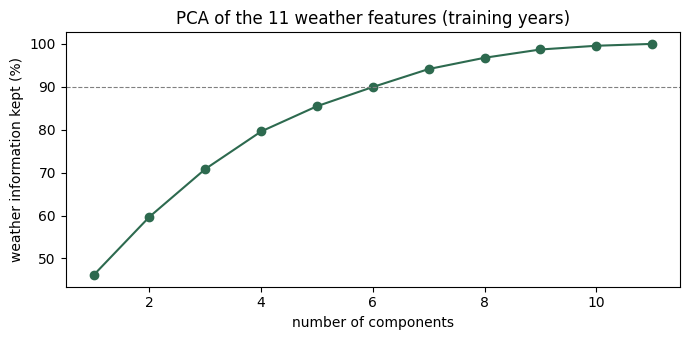

7 components keep 90% of the information in 11 weather features


,Ridge,XGBoost,CatBoost,average of the three
"final set, weather as it is",352.9,355.2,356.5,354.9
weather compressed to 3 components,360.7,362.9,360.1,361.2
weather compressed to 7 components,350.2,360.0,357.0,355.7


In [127]:
from sklearn.decomposition import PCA

weather_cols = [c for c in ["rain_season", "rain_anomaly_pct", "rain_wettest_month", "rain_driest_month", "rain_before", "dry_spell_days",
                            "heavy_rain_days", "tmax", "rh", "solar", "wind"] if c in numeric_features]
other_cols = [c for c in numeric_features if c not in weather_cols]
weather_pca_fit = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("pca", PCA())]).fit(train_df[weather_cols])
kept_share = weather_pca_fit.named_steps["pca"].explained_variance_ratio_.cumsum()
n_components_90 = int(np.searchsorted(kept_share, 0.9) + 1)

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, len(kept_share) + 1), kept_share * 100, marker="o", color="#2D6A4F")
plt.axhline(90, color="grey", linestyle="--", linewidth=0.8)
plt.xlabel("number of components")
plt.ylabel("weather information kept (%)")
plt.title("PCA of the 11 weather features (training years)")
plt.tight_layout()
plt.show()
print(f"{n_components_90} components keep 90% of the information in {len(weather_cols)} weather features")


def pca_model(name, n_components):
    weather_pca = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                            ("pca", PCA(n_components=n_components, random_state=random_state))])
    if name == "CatBoost":
        prep = ColumnTransformer([("weather", weather_pca, weather_cols), ("other", "passthrough", other_cols), ("cat", "passthrough", categorical_features)],
                                 verbose_feature_names_out=False).set_output(transform="pandas")
        return Pipeline([("prep", prep), ("model", CatBoostRegressor(iterations=400, learning_rate=0.03, depth=4, l2_leaf_reg=10, random_seed=random_state,
                                                                     verbose=0, cat_features=categorical_features))])
    prep = ColumnTransformer([("weather", weather_pca, weather_cols),
                              ("other", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), other_cols),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)])
    model = Ridge(alpha=ridge_alpha_start) if name == "Ridge" else XGBRegressor(
        n_estimators=200, learning_rate=0.03, max_depth=3, min_child_weight=5, subsample=0.8, colsample_bytree=0.7, reg_lambda=5.0,
        random_state=random_state, n_jobs=-1)
    return Pipeline([("prep", prep), ("model", model)])


pca_rows = {"final set, weather as it is": {name: cv_scores(lambda: model_for(name, numeric_features), X=train_df, y=y_train)[0]
                                            for name in ["Ridge", "XGBoost", "CatBoost"]}}
for n in sorted({3, n_components_90}):
    pca_rows[f"weather compressed to {n} components"] = {name: cv_scores(lambda: pca_model(name, n), X=train_df, y=y_train)[0]
                                                         for name in ["Ridge", "XGBoost", "CatBoost"]}
pca_results = pd.DataFrame(pca_rows).T
pca_results["average of the three"] = pca_results.mean(axis=1)
pca_results.round(1)

PCA provides no benefit. Seven components are needed to retain 90% of the weather information, so the eleven features are less redundant than they appear. Three components make every model worse (1.8% on average), and seven are slightly worse (0.2%).

Only Ridge gains slightly from seven components, as a linear model benefits from decorrelated inputs, whereas the tree models lose the original features they split on. The weather features are therefore kept unchanged.

### <b>15.4 Further Checks on the Test Seasons</b>

Sets M to R in 15.1 and the selection check in 15.3 came after the main analysis, so they were reported but not allowed to change the model. Here the deployed Explainable Boosting Machine, with the same settings, is trained on the three most promising alternatives and scored on the test seasons beside the final feature set.

This is for transparency only. Choosing a feature set by test score would make the test seasons another validation set, so nothing changes whatever the result.

In [128]:
stage_weather_features = ["tmax_flowering", "tmin_ripening", "solar_ripening", "rain_harvest_month"]
late_options = {"final set (10.2)": numeric_features,
                "final set without the features that did not help (10.1)": kept_features,
                "final set + weather by crop stage (Q)": numeric_features + stage_weather_features,
                "final set + qualitative features (R)": numeric_features + qualitative_features,
                "consensus of the three selection methods (15.3)": consensus}
late_rows = []
for label, num in late_options.items():
    cols = categorical_features + num
    make = lambda: ExplainableBoostingRegressor(interactions=5, outer_bags=8, random_state=random_state)
    pred = make().fit(train_df[cols], y_train).predict(test_df[cols])
    late_rows.append({"features": label, "number of features": len(num),
                      "validation MAE": cv_scores(make, X=train_df[cols], y=y_train)[0], "test MAE": mean_absolute_error(y_test, pred),
                      "test accuracy %": 100 - mean_absolute_percentage_error(y_test, pred) * 100,
                      "within 20% of official %": (np.abs(pred - y_test) / y_test <= 0.2).mean() * 100})
pd.DataFrame(late_rows).set_index("features").round(1)

,number of features,validation MAE,test MAE,test accuracy %,within 20% of official %
features,,,,,
final set (10.2),21,346.6,446.2,87.6,86.1
final set without the features that did not help (10.1),19,344.6,453.4,87.1,83.9
final set + weather by crop stage (Q),25,341.3,447.1,87.5,86.5
final set + qualitative features (R),25,341.2,433.6,88.0,86.8
consensus of the three selection methods (15.3),28,337.8,464.5,87.2,84.1


Four alternatives are scored on the test seasons beside the final set.

- The reduced set without the two unhelpful features (15.2) is worse, with a test error of 453 against 446 kg/ha, accuracy 87.1% against 87.6%, and 83.9% within 20% against 86.1%. Retaining all 21 features was therefore justified, although two appeared unnecessary on validation.
- The growth-stage weather (Q) performs equivalently, at 447 against 446 kg/ha, accuracy 87.5% against 87.6% and 86.5% against 86.1% within 20%. Its 1.5% validation gain does not transfer to the test seasons.
- The qualitative features (R) alone improve the Explainable Boosting Machine on both validation (341.2 against 346.6, 1.6% better) and test (434 against 446 kg/ha, accuracy 88.0% against 87.6%). They did not help the three models in 15.1, which already had the district, whereas the EBM learns a separate effect per label, such as an El Niño season. Individually the El Niño phase helped most and the policy regime least, but no label passed the 1% bar, and the combined gain fell to about 0.5% under slightly different rounding, so it is genuine but small and fragile.
- The consensus of the three selection methods (15.3) is substantially worse (464 kg/ha, accuracy 87.2%, 84.1% within 20%) despite the best validation error of all (338).

This is the validation overfitting warned of at the start of Section 15 and in 15.3. The more often the same validation years drive choices, the better the winner looks on them and the less this says about new seasons.

The deployed model keeps the 21-feature set. The qualitative features are the most promising direction and are recommended for a fresh test on the 2026/27 seasons once the DCS publishes them (Section 20).

### <b>15.5 Changes to the Model Itself</b>

The same check is applied to three model changes intended to obtain greater accuracy from the same data. Settings are chosen on the validation years and the chosen version is scored once on test. These also followed the main analysis and do not change the deployed model.

- Blending the EBM with Ridge. Section 14 showed the smooth models slightly better in the record and crash years and the EBM better on validation, so a weighted average may combine both. The Ridge weight is chosen from 0, 0.25, 0.5 and 0.75.
- Weighting recent seasons. Agricultural practice has changed since the 1980s (new varieties, mechanisation, irrigation), so each training season receives a weight halving every 10 or 20 years back.
- Tuning the EBM. Beyond the current 5 pairwise interactions and default learning rate, three settings are evaluated, namely no interactions, 10 interactions, and 5 interactions with a smaller learning rate.

In [129]:
# three late model tweaks, each chosen on the validation years and then scored once on the test seasons
X_tr, X_te = train_df[feature_columns], test_df[feature_columns]
season_age = (train_df.t.max() - train_df.t).values  # years before the end of training


def ebm_make(**settings):
    params = {"interactions": 5, "outer_bags": 8, "random_state": random_state}
    params.update(settings)
    return lambda: ExplainableBoostingRegressor(**params)


def fold_preds(make, weights=None):
    out = []
    for tr, va in cv_folds:
        fit_args = {} if weights is None else {"sample_weight": weights[tr]}
        out.append(make().fit(X_tr.iloc[tr], y_train.iloc[tr], **fit_args).predict(X_tr.iloc[va]))
    return out


def folds_mae_of(preds):
    return np.mean([mean_absolute_error(y_train.iloc[va], p) for (tr, va), p in zip(cv_folds, preds)])


def test_row(label, setting, val_mae, pred):
    return {"change": label, "setting chosen on validation": setting, "validation MAE": val_mae, "test MAE": mean_absolute_error(y_test, pred),
            "test accuracy %": 100 - mean_absolute_percentage_error(y_test, pred) * 100,
            "within 20% of official %": (np.abs(pred - y_test) / y_test <= 0.2).mean() * 100}


tweak_rows = []
ebm_val = fold_preds(ebm_make())
ebm_test = ebm_make()().fit(X_tr, y_train).predict(X_te)
tweak_rows.append(test_row("deployed EBM, as it is", "-", folds_mae_of(ebm_val), ebm_test))

ridge_make = lambda: make_pipeline(Ridge(alpha=ridge_alpha))
ridge_val = fold_preds(ridge_make)
blend = {w: folds_mae_of([w * r + (1 - w) * e for r, e in zip(ridge_val, ebm_val)]) for w in [0.0, 0.25, 0.5, 0.75]}
w_best = min(blend, key=blend.get)
ridge_test = ridge_make().fit(X_tr, y_train).predict(X_te)
tweak_rows.append(test_row("EBM + Ridge blend", f"weight on Ridge {w_best}", blend[w_best], w_best * ridge_test + (1 - w_best) * ebm_test))

recency = {h: folds_mae_of(fold_preds(ebm_make(), 0.5 ** (season_age / h))) for h in [10, 20]}
h_best = min(recency, key=recency.get)
recency_test = ebm_make()().fit(X_tr, y_train, sample_weight=0.5 ** (season_age / h_best)).predict(X_te)
tweak_rows.append(test_row("recent seasons weighted more", f"weight halves every {h_best} years", recency[h_best], recency_test))

tuning = {"no interactions": {"interactions": 0}, "10 interactions": {"interactions": 10}, "smaller learning rate": {"learning_rate": 0.005}}
tuned = {label: folds_mae_of(fold_preds(ebm_make(**settings))) for label, settings in tuning.items()}
t_best = min(tuned, key=tuned.get)
tweak_rows.append(test_row("EBM settings tuned", t_best, tuned[t_best], ebm_make(**tuning[t_best])().fit(X_tr, y_train).predict(X_te)))
as_text = lambda d: ", ".join(f"{k} = {v:.1f}" for k, v in d.items())
print("Validation MAE of every setting tried | blend weight on Ridge", as_text(blend), "| recency half-life in years", as_text(recency),
      "| EBM settings", as_text(tuned))
pd.DataFrame(tweak_rows).set_index("change").round(1)

Validation MAE of every setting tried | blend weight on Ridge 0.0 = 346.6, 0.25 = 344.9, 0.5 = 345.7, 0.75 = 348.0 | recency half-life in years 10 = 361.2, 20 = 354.8 | EBM settings no interactions = 348.9, 10 interactions = 347.8, smaller learning rate = 343.4


,setting chosen on validation,validation MAE,test MAE,test accuracy %,within 20% of official %
change,,,,,
"deployed EBM, as it is",-,346.6,446.2,87.6,86.1
EBM + Ridge blend,weight on Ridge 0.25,344.9,440.5,87.7,86.3
recent seasons weighted more,weight halves every 20 years,354.8,442.0,87.7,86.1
EBM settings tuned,smaller learning rate,343.4,442.1,87.7,85.9


All three changes are small, and none passes the 1% bar on the validation years.

- The blend works best with a Ridge weight of 0.25, 0.5% better on validation (344.9) and slightly better on test (441 against 446 kg/ha), consistent with Ridge coping better with extreme years. The gain does not warrant a second model.
- Recency weighting worsens the validation error (354.8 halving every 20 years, 361.2 every 10), so it would never be chosen despite scoring 442 on test. Old seasons remain informative.
- A smaller learning rate is 0.9% better on validation (343.4) and scores 442 on test, narrowly below the bar.

The deployed model is thus close to the best this data allows. Each change moves the test error by about 1%, well within the 80 to 90 kg/ha season-to-season variation.

The last check concerns the preprocessing route. CatBoost and the EBM take the cleaned columns directly, while every other model goes through the shared pipeline (9.3). Both are also trained through the pipeline here, with median imputation alone and with the full pipeline of imputation, scaling and one-hot encoding, on the same seven validation years.

In [130]:
# CatBoost and the EBM are trained through the pipeline as well, to check that the preprocessing route does not change the result
ebm_make = lambda: ExplainableBoostingRegressor(interactions=5, outer_bags=8, random_state=random_state)


def impute_only(model):
    # median imputation of the numeric columns, district and season passed through unchanged
    prep = ColumnTransformer([("numeric", SimpleImputer(strategy="median"), numeric_features), ("categorical", "passthrough", categorical_features)],
                             verbose_feature_names_out=False).set_output(transform="pandas")
    return Pipeline([("prep", prep), ("model", model)])


route_rows = []
for label, make in [("EBM, cleaned columns directly (deployed)", ebm_make),
                    ("EBM, median imputation only", lambda: impute_only(ebm_make())),
                    ("EBM, full pipeline (median, scaling, one-hot)", lambda: make_pipeline(ebm_make())),
                    ("CatBoost, cleaned columns with native categories", lambda: CatBoostRegressor(**cat_params)),
                    ("CatBoost, full pipeline (median, scaling, one-hot)", lambda: make_pipeline(CatBoostRegressor(**{**cat_params, "cat_features": None})))]:
    mean_mae, sd_mae = cv_scores(make)
    route_rows.append({"setup": label, "validation MAE": mean_mae, "std": sd_mae})
pd.DataFrame(route_rows).set_index("setup").round(1)

,validation MAE,std
setup,,
"EBM, cleaned columns directly (deployed)",346.6,79.0
"EBM, median imputation only",344.2,81.6
"EBM, full pipeline (median, scaling, one-hot)",346.5,80.5
"CatBoost, cleaned columns with native categories",352.6,90.3
"CatBoost, full pipeline (median, scaling, one-hot)",352.3,89.3


The route makes no meaningful difference. The EBM scores 346.6 kg/ha on the cleaned columns, 344.2 with median imputation and 346.5 through the full pipeline, and CatBoost 352.6 against 352.3, all within the 1% threshold and well inside the year-to-year spread of about 80-90 kg/ha. The deployed setup is therefore kept.

### <b>15.6 Every Source and the Final Verdict</b>

The feature ledger below lists every source in the order of loading in Section 3, with its features, the feature set that tested them, the change in average validation error on adding them, and the decision. The change is measured against the preceding set (B against A, C against B) or otherwise against set C, and a negative value means a lower error.

In [131]:
ledger = [
    ("1. DCS paddy statistics", "3.1", "yield history, ARIMA forecast, sown extent, irrigation shares", "A"),
    ("1. DCS paddy statistics", "3.1", "neighbouring districts' previous season", "E"),
    ("1. DCS paddy statistics", "3.1", "harvested share (a leak, never a candidate)", "P"),
    ("2. OpenStreetMap", "3.2", "district locations and boundaries for the weather", "A"),
    ("3. NASA POWER", "3.3", "temperature, humidity, solar radiation, wind", "A"),
    ("3. NASA POWER", "3.3", "one temperature instead of three", "G"),
    ("3. NASA POWER", "3.3", "hottest month of the season", "O"),
    ("3. NASA POWER + 4. CHIRPS", "3.3, 3.4", "weather at each growth stage", "Q"),
    ("3. NASA POWER + 9. ERA5-Land", "3.3, 3.9", "soil moisture and evapotranspiration", "M"),
    ("4. CHIRPS", "3.4", "season rainfall, anomaly, wettest and driest month", "B"),
    ("4. CHIRPS", "3.4", "dry spells and heavy-rain days", "C"),
    ("4. CHIRPS + 9. ERA5-Land", "3.4, 3.9", "rain in the six months before, soil moisture at planting", "N"),
    ("5. FAOSTAT", "3.5", "nitrogen fertilizer imports", "D"),
    ("6. MODIS", "3.6", "vegetation greenness (NDVI)", "F"),
    ("7. NOAA climate indices", "3.7", "El Niño index", "I"),
    ("7. NOAA climate indices", "3.7", "Indian Ocean Dipole index", "J"),
    ("8. NOAA Vegetation Health", "3.8", "crop health over the rice fields", "L"),
    ("10. Fertilizer policy record", "7.1", "fertilizer support level", "K"),
    ("10. Fertilizer policy record", "7.1, 11", "fertilizer shortage switch", "11"),
    ("7, 10, 11. Policy, ENSO, provinces, climate zones", "7.1", "qualitative features", "R"),
]
set_names = {name.split(".")[0]: name for name in feature_sets}
rows = []
for source, section, features, tested in ledger:
    if tested == "A":
        rows.append([source, section, features, "A", np.nan, "in the starting set", "yes" if any(f in numeric_features for f in
                     ["yield_same_season_roll3", "sown_ha", "tmax", "rh", "solar", "wind"]) else "no"])
        continue
    if tested == "11":
        rows.append([source, section, features, "11", np.nan, "added as a scenario input (Section 11)", "yes"])
        continue
    name = set_names[tested]
    if name in decisions:
        change, decision = decisions[name]
    else:  # the leak is scored but never a candidate
        change, decision = (on_yield[name] / on_yield["C. B + dry spell, heavy-rain days"] - 1) * 100, "a leak, never allowed"
    added = [f for f in feature_sets[name] if f not in feature_sets["C. B + dry spell, heavy-rain days"]]
    in_final = "yes" if (decision == "kept" and all(f in numeric_features for f in added)) else "no"
    rows.append([source, section, features, tested, change, decision, in_final])
feature_ledger = pd.DataFrame(rows, columns=["source", "section", "features", "tested in set", "validation change %", "decision", "in the final model"])
feature_ledger.round(1)

,source,section,features,tested in set,validation change %,decision,in the final model
0,1. DCS paddy statistics,3.1,"yield history, ARIMA forecast, sown extent, ir...",A,NaN,in the starting set,yes
1,1. DCS paddy statistics,3.1,neighbouring districts' previous season,E,-0.1,not kept,no
2,1. DCS paddy statistics,3.1,"harvested share (a leak, never a candidate)",P,-2.7,"a leak, never allowed",no
3,2. OpenStreetMap,3.2,district locations and boundaries for the weather,A,NaN,in the starting set,yes
4,3. NASA POWER,3.3,"temperature, humidity, solar radiation, wind",A,NaN,in the starting set,yes
5,3. NASA POWER,3.3,one temperature instead of three,G,-0.5,kept,yes
6,3. NASA POWER,3.3,hottest month of the season,O,-0.0,"late check, not kept",no
7,3. NASA POWER + 4. CHIRPS,"3.3, 3.4",weather at each growth stage,Q,-1.5,"late check, passes the bar, reported only",no
8,3. NASA POWER + 9. ERA5-Land,"3.3, 3.9",soil moisture and evapotranspiration,M,0.2,"late check, not kept",no
9,4. CHIRPS,3.4,"season rainfall, anomaly, wettest and driest m...",B,-0.1,kept,yes


In [132]:
# which datasets the final model still needs, and which were dropped completely
dataset_sets = {"1. DCS paddy statistics": ["A", "E"], "2. OpenStreetMap": ["A"], "3. NASA POWER": ["A", "G", "O", "Q", "M"],
                "4. CHIRPS": ["B", "C", "N", "Q"], "5. FAOSTAT": ["D"], "6. MODIS": ["F"], "7. NOAA climate indices": ["I", "J", "R"],
                "8. NOAA Vegetation Health": ["L"], "9. ERA5-Land": ["M", "N"], "10. Fertilizer policy record": ["K", "11", "R"],
                "11. Provinces and climate zones": ["R"]}
verdicts = []
for dataset, sets in dataset_sets.items():
    rows_here = feature_ledger[feature_ledger["tested in set"].isin(sets) & feature_ledger.source.str.contains(dataset.split(". ")[1].split(" ")[0])]
    used = (rows_here["in the final model"] == "yes").any()
    verdicts.append({"dataset": dataset, "tested in sets": ", ".join(sets), "verdict": "used by the final model" if used else "dropped completely"})
pd.DataFrame(verdicts).set_index("dataset")

,tested in sets,verdict
dataset,,
1. DCS paddy statistics,"A, E",used by the final model
2. OpenStreetMap,A,used by the final model
3. NASA POWER,"A, G, O, Q, M",used by the final model
4. CHIRPS,"B, C, N, Q",used by the final model
5. FAOSTAT,D,dropped completely
6. MODIS,F,dropped completely
7. NOAA climate indices,"I, J, R",dropped completely
8. NOAA Vegetation Health,L,dropped completely
9. ERA5-Land,"M, N",dropped completely


Five of the eleven datasets are used by the final model, namely the DCS paddy statistics, OpenStreetMap, NASA POWER, CHIRPS and the fertilizer policy record. FAOSTAT, MODIS, the NOAA climate indices, NOAA crop health, ERA5-Land and the province and climate zone maps were dropped completely, because none of their features passed the tests in Sections 10 and 15.

### <b>15.7 Grouping the Districts with K-means Clustering</b>

K-means clustering, from the clustering lecture, is an unsupervised method. It places each district in one of K groups by repeatedly assigning every district to the nearest centroid and moving each centroid to the mean of its districts, which makes the districts within a group as similar as possible.

Planners already group districts informally, for example the irrigated dry zone, the rainfed wet zone and the north and east. Clustering tests whether the data supports such groups and whether a group label helps the chosen model.

Each district is described by six features computed from the training seasons alone (1981-2016), so the test seasons play no part in the grouping. These are its average yield, how far its yield swings around its own three-season average (standard deviation of the ratio), its average rainfed and major irrigation shares, its average season rainfall and its typical sown extent on a log scale. The features are standardised so that no single unit dominates the distances.

K is chosen with the elbow method, which plots the within-cluster sum of squares, and the silhouette score, which measures how much closer each district is to its own cluster than to the nearest other cluster (1 is perfect, 0 means overlapping clusters).

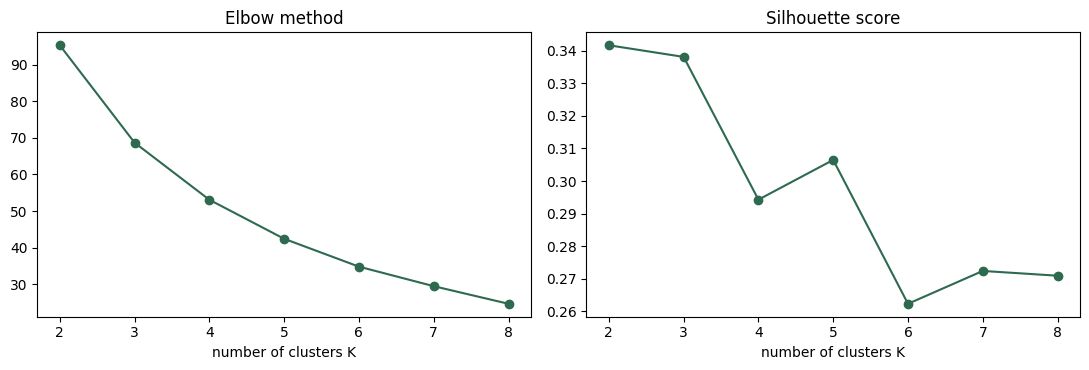

27 districts, 6 profile features


,within-cluster sum of squares,silhouette
K,,
2,95.251,0.342
3,68.685,0.338
4,53.105,0.294
5,42.465,0.306
6,34.863,0.262
7,29.538,0.272
8,24.731,0.271


In [133]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# one profile per district from the training seasons only (to 2016), so the test seasons play no part in the grouping
district_profile = train_df.assign(yield_vs_average=train_df.yield_kg_ha / train_df.yield_same_season_roll3).groupby("district").agg(
    mean_yield=("yield_kg_ha", "mean"),
    yield_swing=("yield_vs_average", "std"),
    share_rainfed=("share_rainfed", "mean"),
    share_major=("share_major", "mean"),
    season_rain_mm=("rain_season", "mean"),
    sown_ha=("sown_ha", "mean"))
district_profile["log_sown_ha"] = np.log10(district_profile.pop("sown_ha"))
profile_scaled = StandardScaler().fit_transform(district_profile)

k_rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=50, random_state=random_state).fit(profile_scaled)
    k_rows.append({"K": k, "within-cluster sum of squares": km.inertia_, "silhouette": silhouette_score(profile_scaled, km.labels_)})
k_choice = pd.DataFrame(k_rows).set_index("K")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(k_choice.index, k_choice["within-cluster sum of squares"], marker="o", color="#2D6A4F")
axes[0].set_title("Elbow method")
axes[1].plot(k_choice.index, k_choice["silhouette"], marker="o", color="#2D6A4F")
axes[1].set_title("Silhouette score")
for ax in axes:
    ax.set_xlabel("number of clusters K")
plt.tight_layout()
plt.show()
print(f"{len(district_profile)} districts, {district_profile.shape[1]} profile features")
k_choice.round(3)

The silhouette score is highest for two clusters (0.342) and practically the same for three (0.338), then lower for every larger K. The elbow curve shows the largest reduction from two to three clusters (from 95 to 69) and steadily smaller ones afterwards. Three clusters are therefore used, as they separate one more meaningful group at no real loss of cohesion.

high rainfall     Colombo, Galle, Gampaha, Kalutara, Kandy, Kegalle, Matara, Nuwara Eliya, Ratnapura
major irrigation  Ampara, Anuradhapura, Badulla, Hambantota, Kurunegala, Mahaweli 'H', Matale, Monaragala, Polonnaruwa, Trincomalee, Udawalawe
volatile yields   Batticaloa, Jaffna, Kilinochchi, Mannar, Mullativu, Puttalam, Vavuniya


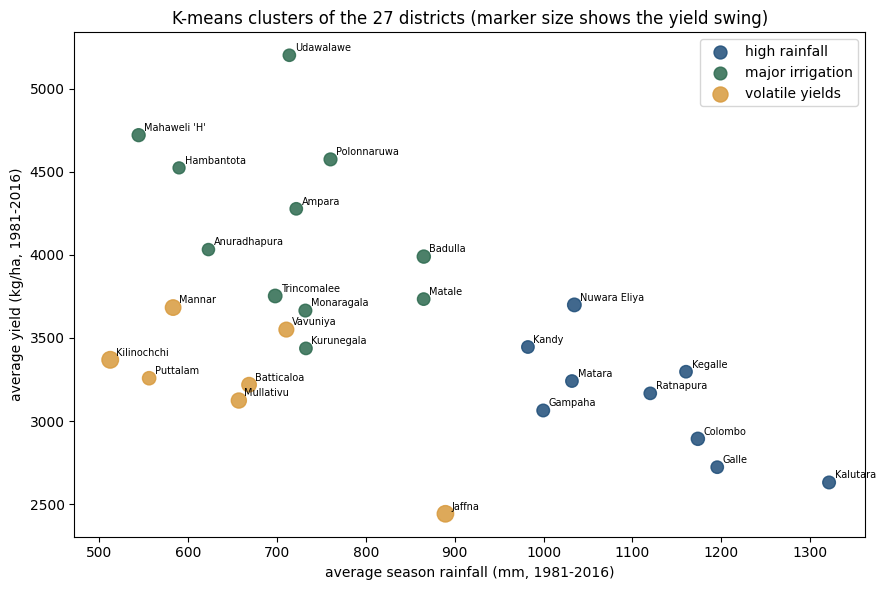

,districts,mean_yield,yield_swing,share_rainfed,share_major,season_rain_mm,typical_sown_ha
cluster,,,,,,,
high rainfall,9,3128.82,0.11,0.58,0.12,1113.22,10735.62
major irrigation,11,4173.16,0.11,0.11,0.69,713.31,26838.09
volatile yields,7,3234.89,0.20,0.32,0.52,653.98,11032.26


In [134]:
k_best = 3  # the silhouette is practically tied for K = 2 and 3, and the largest elbow reduction is from 2 to 3
kmeans = KMeans(n_clusters=k_best, n_init=50, random_state=random_state).fit(profile_scaled)
district_profile["cluster"] = kmeans.labels_
# each cluster is named after the profile feature that sets it apart most, its rainfall, the swing of its yields or its irrigation
centres = district_profile.groupby("cluster").mean()
wettest = centres["season_rain_mm"].idxmax()
most_volatile = centres.drop(wettest)["yield_swing"].idxmax()
cluster_names = {wettest: "high rainfall", most_volatile: "volatile yields"}
cluster_names[next(c for c in centres.index if c not in cluster_names)] = "major irrigation"
district_profile["cluster"] = district_profile.cluster.map(cluster_names)
for name, g in district_profile.groupby("cluster"):
    print(f"{name:17s} {', '.join(g.index.str.title())}")

cluster_colours = {"major irrigation": "#2D6A4F", "volatile yields": "#D89A3D", "high rainfall": "#1F4E79"}
fig, ax = plt.subplots(figsize=(9, 6))
for name, g in district_profile.groupby("cluster"):
    ax.scatter(g.season_rain_mm, g.mean_yield, s=40 + 400 * g.yield_swing, color=cluster_colours[name], label=name, alpha=0.85)
    for d, row in g.iterrows():
        ax.annotate(d.title(), (row.season_rain_mm, row.mean_yield), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("average season rainfall (mm, 1981-2016)")
ax.set_ylabel("average yield (kg/ha, 1981-2016)")
ax.set_title(f"K-means clusters of the {len(district_profile)} districts (marker size shows the yield swing)")
ax.legend()
plt.tight_layout()
plt.show()

district_profile.groupby("cluster").agg(districts=("mean_yield", "size"), mean_yield=("mean_yield", "mean"), yield_swing=("yield_swing", "mean"),
                                        share_rainfed=("share_rainfed", "mean"), share_major=("share_major", "mean"),
                                        season_rain_mm=("season_rain_mm", "mean"), typical_sown_ha=("log_sown_ha", lambda s: (10 ** s).mean())).round(2)

- Major irrigation (11 districts). The large Mahaweli and dry-zone tank districts such as Polonnaruwa, Ampara and Anuradhapura, with 69% of the extent under major irrigation and only 11% rainfed on average. They have the highest average yield (4,173 kg/ha) and the largest sown extent.
- Volatile yields (7 districts). The northern and eastern districts (Jaffna, Kilinochchi, Mannar, Mullaitivu, Vavuniya and Batticaloa) and Puttalam. Their yields swing almost twice as much around their own average as elsewhere (0.20 against 0.11), and their seasons are the driest (654 mm). Their irrigation ranges from mostly major schemes (Mannar and Kilinochchi) to almost fully rainfed (Jaffna), so what unites them is instability, which reflects the conflict years and the gaps in their records.
- High rainfall (9 districts). The wet-zone districts of the south-west and the hill country, such as Colombo, Galle, Kandy, Nuwara Eliya and Ratnapura, with the most rain (1,113 mm), the most rainfed land (58% on average) and the lowest average yield (3,129 kg/ha).

The grouping was found without any labels, yet it reproduces the agro-ecological picture that planners use, and it matches the error pattern of Section 14.3, where the volatile northern districts had the largest errors. It supports the conclusion that irrigation and the stability of a district's record matter more than its rainfall.

In [135]:
# the cluster as a feature of the chosen model, reported only as set out at the start of Section 15. An EBM's bagging depends on its random
# seed, so the comparison is repeated with three further seeds to see whether a difference is larger than that noise
with_cluster = X_train.assign(district_cluster=train_df.district.map(district_profile.cluster).values)
test_with_cluster = X_test.assign(district_cluster=test_df.district.map(district_profile.cluster).values)
seed_rows = []
for seed in [random_state, 1, 2, 3]:
    make_seeded = lambda: ExplainableBoostingRegressor(interactions=5, outer_bags=8, random_state=seed)
    without, with_ = cv_scores(make_seeded, X=X_train, y=y_train)[0], cv_scores(make_seeded, X=with_cluster, y=y_train)[0]
    seed_rows.append({"seed": seed, "validation MAE without": without, "validation MAE with": with_, "validation change %": (with_ / without - 1) * 100,
                      "test MAE without": mean_absolute_error(y_test, make_seeded().fit(X_train, y_train).predict(X_test)),
                      "test MAE with": mean_absolute_error(y_test, make_seeded().fit(with_cluster, y_train).predict(test_with_cluster))})
cluster_check = pd.DataFrame(seed_rows).set_index("seed")
print(f"Validation change with the cluster ranges from {cluster_check['validation change %'].min():+.1f}% to {cluster_check['validation change %'].max():+.1f}% "
      f"across the four seeds")
cluster_check.round(1)

Validation change with the cluster ranges from -0.4% to +1.1% across the four seeds


,validation MAE without,validation MAE with,validation change %,test MAE without,test MAE with
seed,,,,,
42,346.6,345.2,-0.4,446.2,441.1
1,346.7,346.7,-0.0,441.9,437.1
2,343.7,347.5,1.1,442.6,444.7
3,345.1,344.5,-0.2,440.6,439.6


With the notebook's seed, the cluster lowers the EBM's validation error by only 0.4% (346.6 to 345.2 kg/ha), well short of the 1% bar. Repeating the comparison with three further seeds gives changes between -0.4% and +1.1% on validation. On test the error is slightly lower for three of the four seeds, by 1 to 5 kg/ha (about 1%), which is no larger than the spread between seeds of the same model without the cluster (441 to 446 kg/ha).

This matches the qualitative features in 15.1, which also made no difference on average, because a fixed district-level label carries little that the district column and the irrigation shares do not already provide. The cluster is therefore not added to the model. Its value lies in describing the districts, for example to report accuracy or to plan support by group.

The clustering lecture recommends trying more than one algorithm and notes that K-means is sensitive to outliers, as a single extreme point pulls its cluster's centre. Two checks follow.

- Ward hierarchical clustering, which merges the closest groups step by step, is run on the same scaled profiles and cut at three clusters. The adjusted Rand index (ARI) compares its grouping with K-means, where 1 means identical groupings and 0 means agreement no better than chance.
- Each district's distance from its own K-means centre is listed, to show whether one district sits far from all the others.

Adjusted Rand index, Ward against K-means 0.796 | silhouette, Ward 0.351 against K-means 0.338
Ward cluster       0  1  2
K-means                   
high rainfall      0  9  0
major irrigation  11  0  0
volatile yields    2  0  5


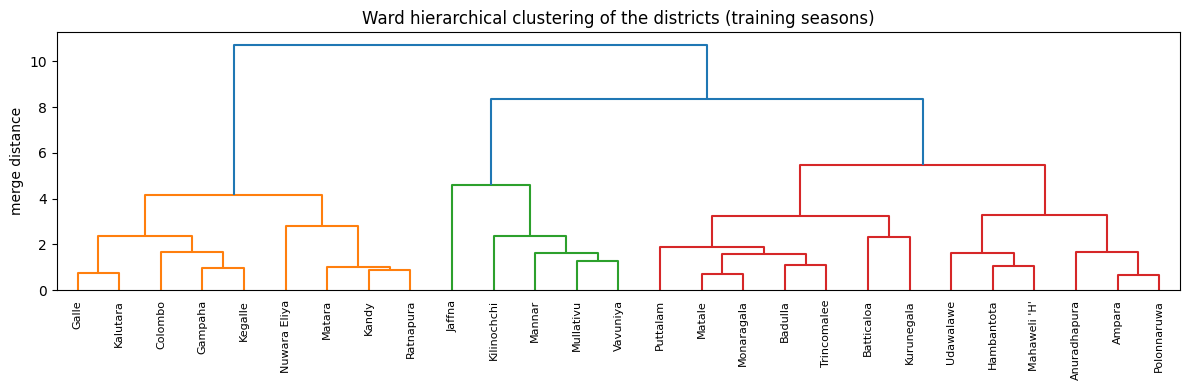

Median distance from the centre 1.50


,cluster,distance from its centre
district,,
JAFFNA,volatile yields,3.12
KURUNEGALA,major irrigation,2.51
NUWARA ELIYA,high rainfall,2.43
UDAWALAWE,major irrigation,2.22
PUTTALAM,volatile yields,1.74


In [136]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

ward_labels = AgglomerativeClustering(n_clusters=k_best, linkage="ward").fit_predict(profile_scaled)
print(f"Adjusted Rand index, Ward against K-means {adjusted_rand_score(kmeans.labels_, ward_labels):.3f} | "
      f"silhouette, Ward {silhouette_score(profile_scaled, ward_labels):.3f} against K-means {silhouette_score(profile_scaled, kmeans.labels_):.3f}")
print(pd.crosstab(district_profile.cluster, ward_labels, rownames=["K-means"], colnames=["Ward cluster"]).to_string())

fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(linkage(profile_scaled, method="ward"), labels=list(district_profile.index.str.title()), leaf_rotation=90, leaf_font_size=8, ax=ax, color_threshold=None)
ax.set_title("Ward hierarchical clustering of the districts (training seasons)")
ax.set_ylabel("merge distance")
plt.tight_layout()
plt.show()

distance = np.linalg.norm(profile_scaled - kmeans.cluster_centers_[kmeans.labels_], axis=1)
far = pd.DataFrame({"cluster": district_profile.cluster, "distance from its centre": distance}).sort_values("distance from its centre", ascending=False)
print(f"Median distance from the centre {np.median(distance):.2f}")
far.head(5).round(2)

Ward clustering agrees closely with K-means (adjusted Rand index 0.80) and has a slightly higher silhouette (0.351 against 0.338). It reproduces the high-rainfall and major-irrigation clusters exactly and differs only in the volatile group, where it places two of the seven districts with the major-irrigation districts. The three groups are therefore not an artefact of one algorithm.

Jaffna lies furthest from its centre (3.12 against a median of 1.50), as the only almost fully rainfed district, with a record that is mostly Maha only, followed by Kurunegala (2.51) and Nuwara Eliya (2.43). None is far enough to form a group of its own or to pull a centre away from the other districts, and Ward clustering, which does not use centres, gives nearly the same grouping. The K-means result is therefore kept.

## <center><b>16. Classification of Poor, Normal and Good Harvests</b></center>

Regression estimates the yield itself, but a planner often first needs to know whether a district's harvest is poor, normal or good. This classification task uses the same features, time split and validation years.

Each district-season is labelled against its own average over the last three same seasons, as poor if more than 10% below, good if more than 10% above, and normal otherwise. The 10% line exceeds the regression model's median error (8.4%), so the classes are practically meaningful, and the label uses no future information.

Six approaches are compared. These are a naive baseline that always predicts normal, the regression estimate converted with the same 10% thresholds, Logistic Regression and Random Forest with balanced class weights, XGBoost with balanced sample weights, and the classification version of the Explainable Boosting Machine.

Selection uses macro F1 on the validation years, which averages the F1 of the three classes so that predicting only normal scores poorly. For a planner the key figure is recall of the poor class, the share of truly poor harvests flagged.

In [137]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, recall_score, precision_score, balanced_accuracy_score, accuracy_score, confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from interpret.glassbox import ExplainableBoostingClassifier

class_names = ["poor", "normal", "good"]


def harvest_class(yields, average):
    ratio = np.asarray(yields, dtype=float) / np.asarray(average, dtype=float)
    return np.select([ratio < 0.9, ratio > 1.1], [0, 2], 1)  # 0 poor, 1 normal, 2 good


y_train_cls = harvest_class(y_train, train_df.yield_same_season_roll3)
y_test_cls = harvest_class(y_test, test_df.yield_same_season_roll3)
print("Share of each class (%), training", ", ".join(f"{k} {v:.1f}" for k, v in zip(class_names, np.bincount(y_train_cls, minlength=3) / len(y_train_cls) * 100)))
print("Share of each class (%), test    ", ", ".join(f"{k} {v:.1f}" for k, v in zip(class_names, np.bincount(y_test_cls, minlength=3) / len(y_test_cls) * 100)))


def class_prep():
    return ColumnTransformer([("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_features),
                              ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)])


# settings of the three tunable classifiers, each tuned below by macro F1 on the same seven validation years as the regression models
class_settings = {"Logistic Regression (balanced)": {"C": 1.0},
                  "Random Forest (balanced)": {"min_samples_leaf": 5, "max_features": 0.4},
                  "XGBoost (balanced weights)": {"max_depth": 3, "n_estimators": 300, "gamma": 0}}
class_grids = {"Logistic Regression (balanced)": [{"C": c} for c in [0.01, 0.03, 0.1, 0.3, 1, 3, 10]],
               "Random Forest (balanced)": [{"min_samples_leaf": leaf, "max_features": mf} for leaf in [2, 5, 10, 20] for mf in [0.2, 0.4, "sqrt"]],
               "XGBoost (balanced weights)": [{"max_depth": d, "n_estimators": n, "gamma": g} for d in [2, 3, 4] for n in [100, 300, 600] for g in [0, 1]]}


def class_model(name, settings=None):
    settings = class_settings[name] if settings is None else settings
    if name == "Logistic Regression (balanced)":
        return Pipeline([("prep", class_prep()), ("model", LogisticRegression(class_weight="balanced", max_iter=5000, **settings))])
    if name == "Random Forest (balanced)":
        return Pipeline([("prep", class_prep()), ("model", RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=random_state, n_jobs=-1, **settings))])
    return Pipeline([("prep", class_prep()), ("model", XGBClassifier(learning_rate=0.05, subsample=0.8, colsample_bytree=0.7, random_state=random_state, n_jobs=-1, **settings))])


def fit_class(model, name, X_fit, y_fit):
    # XGBoost takes the balanced weights per row, the other two through class_weight
    if name.startswith("XGBoost"):
        return model.fit(X_fit, y_fit, model__sample_weight=compute_sample_weight("balanced", y_fit))
    return model.fit(X_fit, y_fit)


def fit_predict(name, X_fit, y_fit, yield_fit, X_new):
    # every approach gets the training rows and returns a class (0, 1 or 2) for the new rows
    if name == "Naive always normal":
        return np.ones(len(X_new), dtype=int)
    if name == "Regression model (EBM), same thresholds":
        estimate = ExplainableBoostingRegressor(interactions=5, outer_bags=8, random_state=random_state).fit(X_fit, yield_fit).predict(X_new)
        return harvest_class(estimate, X_new.yield_same_season_roll3)
    if name in class_settings:
        return np.asarray(fit_class(class_model(name), name, X_fit, y_fit).predict(X_new)).astype(int)
    model = ExplainableBoostingClassifier(interactions=5, outer_bags=8, random_state=random_state)
    return np.asarray(model.fit(X_fit, y_fit).predict(X_new)).astype(int)


approaches = ["Naive always normal", "Regression model (EBM), same thresholds", "Logistic Regression (balanced)", "Random Forest (balanced)",
              "XGBoost (balanced weights)", "Explainable Boosting Machine (classifier)"]
X_cls_train, X_cls_test = train_df[feature_columns], test_df[feature_columns]
tuning_rows = []
for name, grid in class_grids.items():
    scored = [(np.mean([f1_score(y_train_cls[va], fit_class(class_model(name, s), name, X_cls_train.iloc[tr], y_train_cls[tr]).predict(X_cls_train.iloc[va]), average="macro")
                        for tr, va in cv_folds]), s) for s in grid]
    best_f1, class_settings[name] = max(scored, key=lambda x: x[0])
    tuning_rows.append({"classifier": name, "settings tried": len(grid), "chosen settings": class_settings[name], "validation macro F1": round(best_f1, 3)})
print(pd.DataFrame(tuning_rows).to_string(index=False))
lr_check = fit_class(class_model("Logistic Regression (balanced)"), "Logistic Regression", X_cls_train, y_train_cls).named_steps["model"]
print(f"Logistic regression converged in {lr_check.n_iter_.max()} of at most {lr_check.max_iter} iterations\n")
class_rows, class_test_pred = [], {}
for name in approaches:
    val_f1 = [f1_score(y_train_cls[va], fit_predict(name, X_cls_train.iloc[tr], y_train_cls[tr], y_train.iloc[tr], X_cls_train.iloc[va]), average="macro")
              for tr, va in cv_folds]
    pred = fit_predict(name, X_cls_train, y_train_cls, y_train, X_cls_test)
    class_test_pred[name] = pred
    class_rows.append({"approach": name, "validation macro F1": np.mean(val_f1), "test macro F1": f1_score(y_test_cls, pred, average="macro"),
                       "test accuracy": accuracy_score(y_test_cls, pred), "test balanced accuracy": balanced_accuracy_score(y_test_cls, pred),
                       "poor harvests caught (recall)": recall_score(y_test_cls, pred, labels=[0], average="macro", zero_division=0),
                       "poor flags that were right (precision)": precision_score(y_test_cls, pred, labels=[0], average="macro", zero_division=0)})
class_results = pd.DataFrame(class_rows).set_index("approach")
best_classifier = class_results["validation macro F1"].idxmax()
print("Chosen on the validation years (highest macro F1)", best_classifier)
class_results.round(3)

Share of each class (%), training poor 12.5, normal 64.3, good 23.2
Share of each class (%), test     poor 23.1, normal 47.5, good 29.4
                    classifier  settings tried                                   chosen settings  validation macro F1
Logistic Regression (balanced)               7                                       {'C': 0.03}                0.460
      Random Forest (balanced)              12  {'min_samples_leaf': 20, 'max_features': 'sqrt'}                0.422
    XGBoost (balanced weights)              18 {'max_depth': 3, 'n_estimators': 100, 'gamma': 1}                0.465
Logistic regression converged in 27 of at most 5000 iterations

Chosen on the validation years (highest macro F1) XGBoost (balanced weights)


,validation macro F1,test macro F1,test accuracy,test balanced accuracy,poor harvests caught (recall),poor flags that were right (precision)
approach,,,,,,
Naive always normal,0.262,0.215,0.475,0.333,0.000,0.000
"Regression model (EBM), same thresholds",0.347,0.464,0.552,0.467,0.340,0.714
Logistic Regression (balanced),0.460,0.470,0.516,0.466,0.388,0.430
Random Forest (balanced),0.422,0.335,0.446,0.358,0.155,0.302
XGBoost (balanced weights),0.465,0.338,0.455,0.362,0.126,0.250
Explainable Boosting Machine (classifier),0.291,0.241,0.480,0.342,0.010,0.250


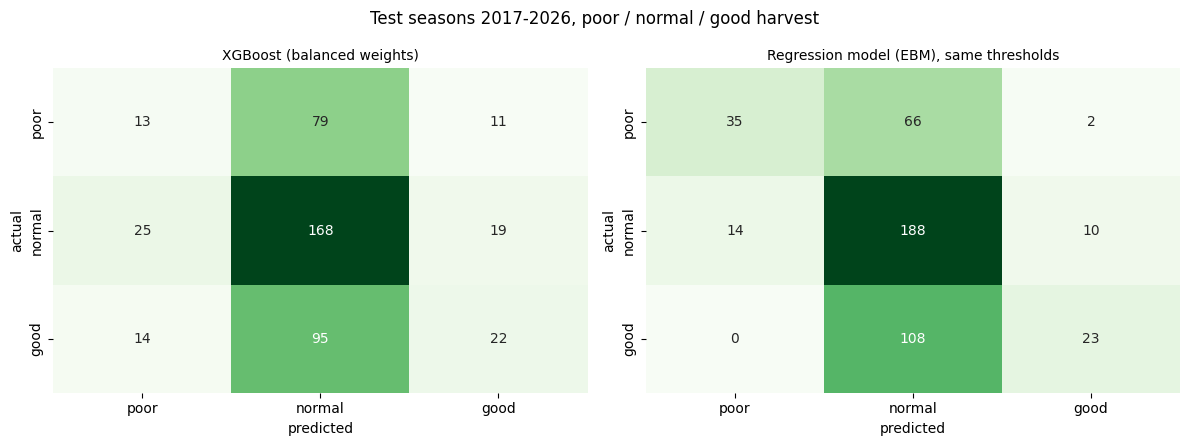

Ban seasons 47 of 49 district-seasons were poor, flagged by XGBoost (balanced weights) 3


In [138]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, [best_classifier, "Regression model (EBM), same thresholds"]):
    cm = confusion_matrix(y_test_cls, class_test_pred[name], labels=[0, 1, 2])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.set_title(name, fontsize=10)
plt.suptitle("Test seasons 2017-2026, poor / normal / good harvest")
plt.tight_layout()
plt.show()
shock_rows = test_df.t.isin(shock_seasons).values
print(f"Ban seasons {int((y_test_cls[shock_rows] == 0).sum())} of {int(shock_rows.sum())} district-seasons were poor, "
      f"flagged by {best_classifier} {int(((class_test_pred[best_classifier] == 0) & (y_test_cls == 0))[shock_rows].sum())}")

The classes are imbalanced and shift over time. Training years were 12.5% poor, 64.3% normal and 23.2% good, while test seasons were 23.1% poor, mainly because 47 of the 49 district-seasons in the two ban seasons were poor.

Each learned classifier was tuned on the validation years. Logistic regression chose a stronger penalty (C 0.03), Random Forest larger leaves and XGBoost fewer trees with a minimum split gain, and logistic regression converged well within its iteration limit.

XGBoost is selected on validation (macro F1 0.465), narrowly ahead of logistic regression (0.460). On test, however, it falls to 0.338 against 0.215 for always predicting normal, identifying only 13% of poor harvests with 25% of its poor flags correct, whereas logistic regression reaches 0.470 and identifies 39%. The validation years, with few poor seasons, favoured a classifier whose advantage did not carry over to 2017-2026.

Converting the regression estimate is the most cautious approach, identifying 34% of poor harvests but with 71% of flags correct and the highest test accuracy (55%). Its lower validation macro F1 (0.347) excluded it.

The tree classifiers (Random Forest, XGBoost and the EBM classifier) mostly predict normal even after tuning, identifying 1% to 16% of poor harvests despite balanced weights. Only 12.5% of training seasons were poor, mostly in the war years, leaving too few clear examples, and a linear model aggregating small signals copes better.

The regression flag is therefore the more dependable warning. Neither approach fully anticipated the ban, the chosen classifier flagging 3 of the 47 poor ban-season district-seasons, consistent with Section 14.2.

### <b>16.1 ROC Curves, MCC and a Lower Threshold for Poor Harvests</b>

The measures above judge each classifier by its single most likely class. As in the lecture's diabetes example, a classifier also gives a probability for each class, and two further measures use it.

- The ROC curve plots the share of poor harvests caught against the share of other seasons wrongly flagged, as the probability needed to flag a poor harvest is lowered. The area under it (AUC) is the chance that a randomly chosen poor season is ranked above a randomly chosen other season, so 0.5 means no skill and 1 a perfect ranking.
- The Matthews correlation coefficient (MCC) uses all cells of the confusion matrix and stays near 0 for a classifier that mostly predicts the largest class, which makes it suitable for imbalanced classes. It ranges from -1 to 1.

The regression model gives no probability, but how far its estimate falls below the district's three-season average ranks the seasons in the same way, so it also receives an AUC for the poor class.

In [139]:
from sklearn.metrics import roc_curve, roc_auc_score, matthews_corrcoef, fbeta_score


def class_probabilities(name, X_fit, y_fit, X_new):
    # the probability of poor, normal and good from each learned classifier, with the settings tuned above
    if name in class_settings:
        return fit_class(class_model(name), name, X_fit, y_fit).predict_proba(X_new)
    model = ExplainableBoostingClassifier(interactions=5, outer_bags=8, random_state=random_state)
    return model.fit(X_fit, y_fit).predict_proba(X_new)


learned = ["Logistic Regression (balanced)", "Random Forest (balanced)", "XGBoost (balanced weights)", "Explainable Boosting Machine (classifier)"]
class_test_prob = {name: class_probabilities(name, X_cls_train, y_train_cls, X_cls_test) for name in learned}
# the regression model gives no probability, but how far its estimate falls below the average ranks the seasons in the same way
poor_score = {name: p[:, 0] for name, p in class_test_prob.items()}
poor_score["Regression model (EBM), same thresholds"] = 1 - fitted["Explainable Boosting Machine"].predict(X_cls_test) / test_df.yield_same_season_roll3.values
is_poor = (y_test_cls == 0).astype(int)

auc_rows = []
for name in ["Regression model (EBM), same thresholds"] + learned:
    auc_rows.append({"approach": name, "AUC, poor against the rest": roc_auc_score(is_poor, poor_score[name]),
                     "AUC, all three classes (one-vs-rest)": roc_auc_score(y_test_cls, class_test_prob[name], multi_class="ovr") if name in learned else np.nan,
                     "MCC": matthews_corrcoef(y_test_cls, class_test_pred[name])})
auc_rows.append({"approach": "Naive always normal", "AUC, poor against the rest": 0.5, "AUC, all three classes (one-vs-rest)": 0.5,
                 "MCC": matthews_corrcoef(y_test_cls, class_test_pred["Naive always normal"])})
probability_results = pd.DataFrame(auc_rows).set_index("approach")
probability_results.round(3)

,"AUC, poor against the rest","AUC, all three classes (one-vs-rest)",MCC
approach,,,
"Regression model (EBM), same thresholds",0.769,NaN,0.259
Logistic Regression (balanced),0.717,0.674,0.205
Random Forest (balanced),0.631,0.584,0.043
XGBoost (balanced weights),0.639,0.599,0.060
Explainable Boosting Machine (classifier),0.600,0.593,0.054
Naive always normal,0.500,0.500,0.000


- The converted regression estimate ranks poor seasons best (AUC 0.77) and has the highest MCC (0.26), followed by logistic regression (AUC 0.72, MCC 0.21). Both are clearly better than chance.
- The tree classifiers rank poor seasons only a little better than chance (AUC 0.60 to 0.64), and their MCC is close to 0 (0.04 to 0.06), which confirms that their predictions are mostly normal, as seen above.
- Across all three classes, logistic regression has the highest one-vs-rest AUC (0.67).

An AUC of about 0.75 means that a truly poor season receives a higher poor score than a normal or good one about three times in four. The ranking of the chosen XGBoost (AUC 0.64) is much weaker, which matters for the threshold below.

Missing a poor harvest costs a planner more than a false alarm. A false alarm leads only to a closer look at the district, whereas a missed shortfall can leave procurement, storage and imports unplanned.

The probability needed to flag a poor harvest is therefore chosen on the validation years by the highest F2 score for the poor class, which weights recall twice as heavily as precision. Each validation year's probabilities come from a model fitted on the earlier years only, and the test seasons are used once, after the choice.

In [140]:
def with_threshold(prob, threshold):
    # flag poor whenever its probability reaches the threshold, otherwise take the more likely of normal and good
    return np.where(prob[:, 0] >= threshold, 0, np.where(prob[:, 2] > prob[:, 1], 2, 1))


# probabilities for the validation years, each from a model fitted on the years before it, as in Section 16
val_prob = np.vstack([class_probabilities(best_classifier, X_cls_train.iloc[tr], y_train_cls[tr], X_cls_train.iloc[va]) for tr, va in cv_folds])
val_true = np.concatenate([y_train_cls[va] for tr, va in cv_folds])
threshold_rows = []
for threshold in np.round(np.arange(0.20, 0.71, 0.05), 2):
    pred = with_threshold(val_prob, threshold)
    threshold_rows.append({"threshold": threshold, "recall": recall_score(val_true, pred, labels=[0], average="macro", zero_division=0),
                           "precision": precision_score(val_true, pred, labels=[0], average="macro", zero_division=0),
                           "F2": fbeta_score(val_true, pred, beta=2, labels=[0], average="macro", zero_division=0),
                           "macro F1": f1_score(val_true, pred, average="macro")})
threshold_scan = pd.DataFrame(threshold_rows).set_index("threshold")
poor_threshold = threshold_scan["F2"].idxmax()
print("Threshold chosen on the validation years (highest F2 for the poor class)", poor_threshold)
threshold_scan.round(3)

Threshold chosen on the validation years (highest F2 for the poor class) 0.2


,recall,precision,F2,macro F1
threshold,,,,
0.20,0.661,0.187,0.438,0.351
0.25,0.458,0.196,0.361,0.400
0.30,0.373,0.282,0.350,0.470
0.35,0.288,0.315,0.293,0.471
0.40,0.220,0.406,0.243,0.481
0.45,0.102,0.353,0.119,0.440
0.50,0.000,0.000,0.000,0.387
0.55,0.000,0.000,0.000,0.386
0.60,0.000,0.000,0.000,0.386


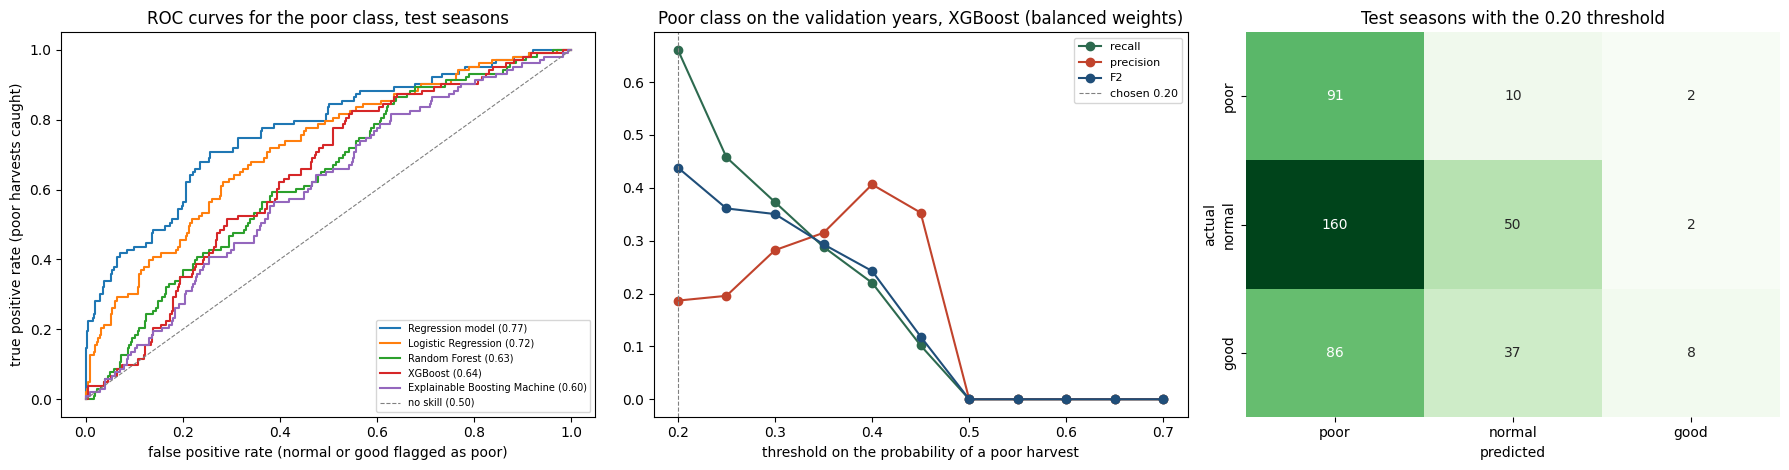

,poor harvests caught (recall),poor flags that were right (precision),"F2, poor",macro F1,MCC,poor flags raised,ban-season poor harvests flagged
decision rule,,,,,,,
most likely class (Section 16),0.126,0.25,0.140,0.338,0.060,52,3
poor if its probability is at least 0.20,0.883,0.27,0.607,0.283,0.098,337,43


In [141]:
test_prob = class_test_prob[best_classifier]
compare_rows = []
for label, pred in [("most likely class (Section 16)", class_test_pred[best_classifier]),
                    (f"poor if its probability is at least {poor_threshold:.2f}", with_threshold(test_prob, poor_threshold))]:
    compare_rows.append({"decision rule": label, "poor harvests caught (recall)": recall_score(y_test_cls, pred, labels=[0], average="macro"),
                         "poor flags that were right (precision)": precision_score(y_test_cls, pred, labels=[0], average="macro"),
                         "F2, poor": fbeta_score(y_test_cls, pred, beta=2, labels=[0], average="macro"), "macro F1": f1_score(y_test_cls, pred, average="macro"),
                         "MCC": matthews_corrcoef(y_test_cls, pred), "poor flags raised": int((pred == 0).sum()),
                         "ban-season poor harvests flagged": int(((pred == 0) & (y_test_cls == 0))[shock_rows].sum())})
threshold_results = pd.DataFrame(compare_rows).set_index("decision rule")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for name in ["Regression model (EBM), same thresholds"] + learned:
    fpr, tpr, _ = roc_curve(is_poor, poor_score[name])
    axes[0].plot(fpr, tpr, label=f"{name.split(' (')[0]} ({probability_results.loc[name, 'AUC, poor against the rest']:.2f})")
axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=0.8, label="no skill (0.50)")
axes[0].set_xlabel("false positive rate (normal or good flagged as poor)")
axes[0].set_ylabel("true positive rate (poor harvests caught)")
axes[0].set_title("ROC curves for the poor class, test seasons")
axes[0].legend(fontsize=7, loc="lower right")
for col, colour in [("recall", "#2D6A4F"), ("precision", "#C1432C"), ("F2", "#1F4E79")]:
    axes[1].plot(threshold_scan.index, threshold_scan[col], marker="o", color=colour, label=col)
axes[1].axvline(poor_threshold, color="grey", linestyle="--", linewidth=0.8, label=f"chosen {poor_threshold:.2f}")
axes[1].set_xlabel("threshold on the probability of a poor harvest")
axes[1].set_title(f"Poor class on the validation years, {best_classifier}")
axes[1].legend(fontsize=8)
cm = confusion_matrix(y_test_cls, with_threshold(test_prob, poor_threshold), labels=[0, 1, 2])
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, xticklabels=class_names, yticklabels=class_names, ax=axes[2])
axes[2].set_xlabel("predicted")
axes[2].set_ylabel("actual")
axes[2].set_title(f"Test seasons with the {poor_threshold:.2f} threshold")
plt.tight_layout()
plt.show()
threshold_results.round(3)

On the validation years F2 is highest at the lowest probability tried, 0.20 (0.438), and falls steadily above it. For the chosen XGBoost poor is rarely the most likely class, and above 0.45 it flags no poor harvests at all.

On the test seasons the lower threshold raises the share of poor harvests caught from 13% to 88% and the poor-class F2 from 0.14 to 0.61. The price is many false alarms. Precision stays near a quarter (25% to 27%), the number of poor flags rises from 52 to 337 of 446 district-seasons, and macro F1 falls from 0.34 to 0.28, as most normal seasons are flagged too.

The lower threshold catches 43 of the 47 poor district-seasons in the fertilizer-ban period instead of 3, but only because it flags three quarters of all seasons.

A rule that flags most seasons gives a planner little guidance. The ROC curve shows that the converted regression estimate ranks poor seasons best (AUC 0.77), so a threshold on the regression estimate, or on the logistic regression's probability, is the more useful early warning. The chosen threshold also lies at the edge of the range tried, a further sign that the chosen classifier's probabilities are compressed.

The threshold is applied to the classifier's probability of a poor harvest, so a calibration curve, which the lectures recommend before probabilities are used for decisions, shows whether a probability of 0.3 really means that about 30% of such seasons are poor. It is drawn on the validation years, from the same forward-fitted probabilities used to choose the threshold.

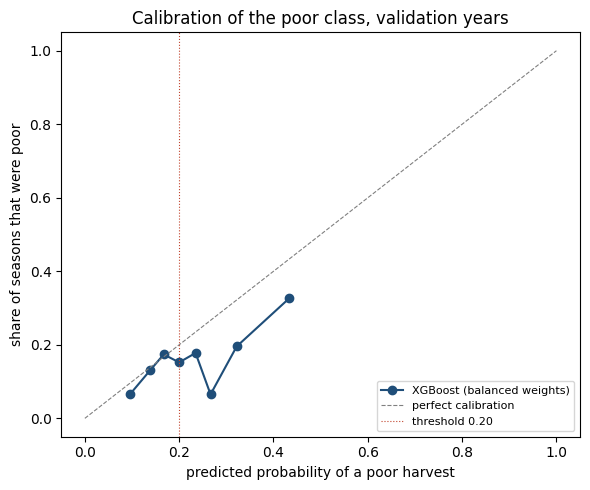

,mean predicted probability,share actually poor
0,0.10,0.07
1,0.14,0.13
2,0.17,0.17
3,0.20,0.15
4,0.23,0.18
5,0.27,0.07
6,0.32,0.20
7,0.43,0.33


In [142]:
from sklearn.calibration import calibration_curve

observed, predicted = calibration_curve((val_true == 0).astype(int), val_prob[:, 0], n_bins=8, strategy="quantile")
plt.figure(figsize=(6, 5))
plt.plot(predicted, observed, marker="o", color="#1F4E79", label=best_classifier)
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=0.8, label="perfect calibration")
plt.axvline(poor_threshold, color="#C1432C", linestyle=":", linewidth=0.8, label=f"threshold {poor_threshold:.2f}")
plt.xlabel("predicted probability of a poor harvest")
plt.ylabel("share of seasons that were poor")
plt.title("Calibration of the poor class, validation years")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()
pd.DataFrame({"mean predicted probability": predicted, "share actually poor": observed}).round(2)

Up to a probability of about 0.25 the chosen XGBoost matches the observed share of poor seasons within a few points (for example 0.17 against 17%), but the curve is uneven and runs high above that, as seasons given about 0.43 were poor only 33% of the time. The probabilities also span a narrow range (bin averages from 0.10 to 0.43), so the classifier rarely expresses strong confidence that a harvest will be poor, which is why the F2 threshold falls to the lowest value tried.

The threshold was chosen on these same probabilities, so it already allows for this, but the probability should not be presented to planners as the chance of a poor harvest.

## <center><b>17. Interpreting the Output with SHAP and LIME</b></center>

### <b>17.1 Global Feature Importance (SHAP)</b>

SHAP (SHapley Additive exPlanations) comes from cooperative game theory, with features as "players" and the prediction as the "gain". Each feature's Shapley value is its average marginal contribution over all orders of adding features, and a prediction equals the base value (the average prediction) plus the sum of the SHAP values.

For a tree model the exact additive contributions are tree SHAP values (`TreeExplainer`). An Explainable Boosting Machine is additive by construction (an intercept, one term per feature and a few pairwise terms), so its terms are already exact SHAP values, with each pairwise term split equally between its two features.

In pipelines, the one-hot district and season columns are summed back into single features. Ridge, the strongest linear model, is explained by its coefficients, its own exact additive contributions, giving a linear view to compare with the non-linear one.

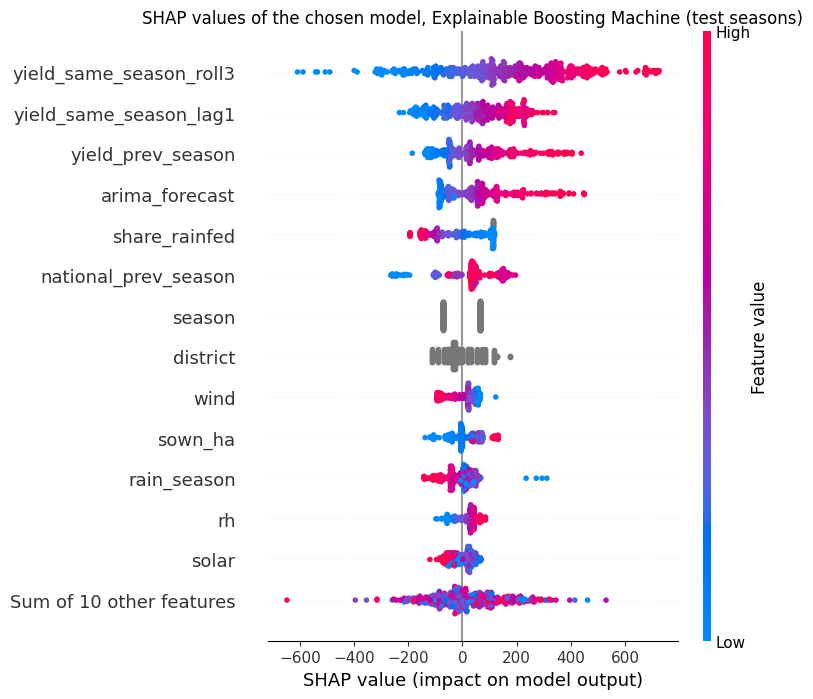

In [143]:
def shap_explain(model, X):
    # exact tree SHAP for CatBoost, the CatBoost part of the blend, or a tree model inside a preprocessing pipeline
    if hasattr(model, "cat_"):
        model = model.cat_
    if isinstance(model, CatBoostRegressor):
        return shap.TreeExplainer(model)(X)
    if isinstance(model, ExplainableBoostingRegressor):
        # an EBM is additive (an intercept plus one term per feature and a few pairs), so its terms are its exact explanation
        # a pairwise term is shared equally between its two features
        terms = model.eval_terms(X)
        values = pd.DataFrame(0.0, index=range(len(X)), columns=list(X.columns))
        for j, features in enumerate(model.term_features_):
            for f in features:
                values[model.feature_names_in_[f]] += terms[:, j] / len(features)
        return shap.Explanation(values.values, base_values=np.full(len(X), model.intercept_), data=X.values, feature_names=list(X.columns))
    prep, tree = model.named_steps["prep"], model.named_steps["model"]
    names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
    raw = shap.TreeExplainer(tree)(prep.transform(X))
    values = pd.DataFrame(raw.values, columns=names)
    for col in categorical_features:  # add the one-hot columns of each category back into one value
        dummies = [n for n in names if n.startswith(col + "_")]
        values[col] = values[dummies].sum(axis=1)
        values = values.drop(columns=dummies)
    values = values[list(X.columns)]
    return shap.Explanation(values.values, base_values=raw.base_values, data=X.values, feature_names=list(X.columns))


shap_test = shap_explain(best_model, X_test)
shap.plots.beeswarm(shap_test, max_display=14, show=False)
plt.title(f"SHAP values of the chosen model, {best_name} (test seasons)")
plt.tight_layout()
plt.show()

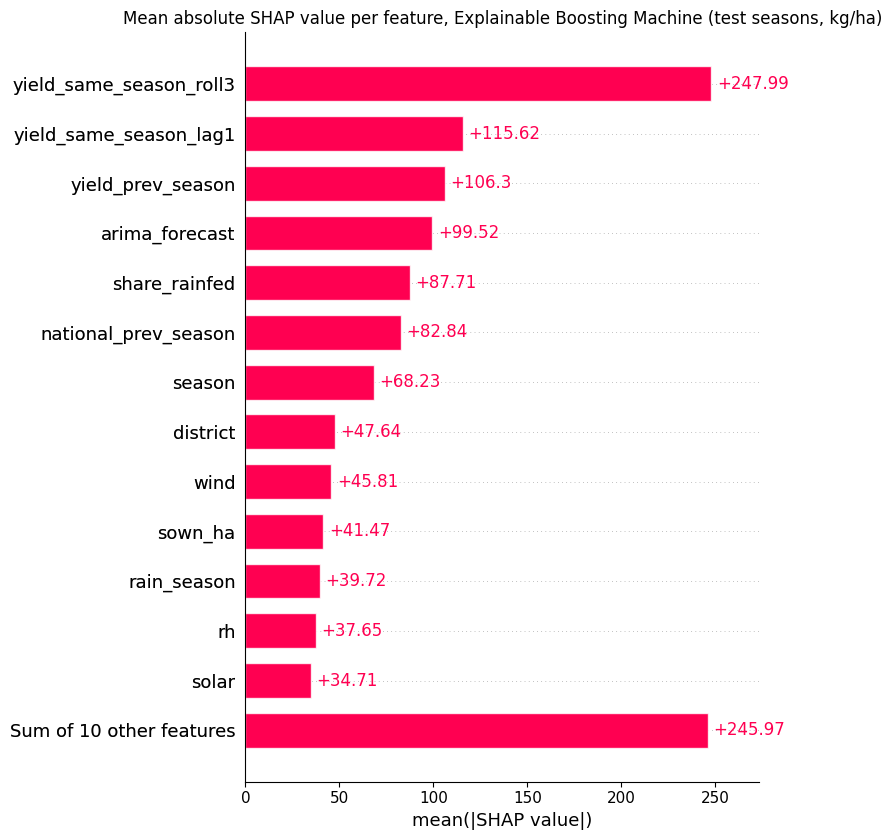

In [144]:
shap.plots.bar(shap_test, max_display=14, show=False)
plt.title(f"Mean absolute SHAP value per feature, {best_name} (test seasons, kg/ha)")
plt.tight_layout()
plt.show()

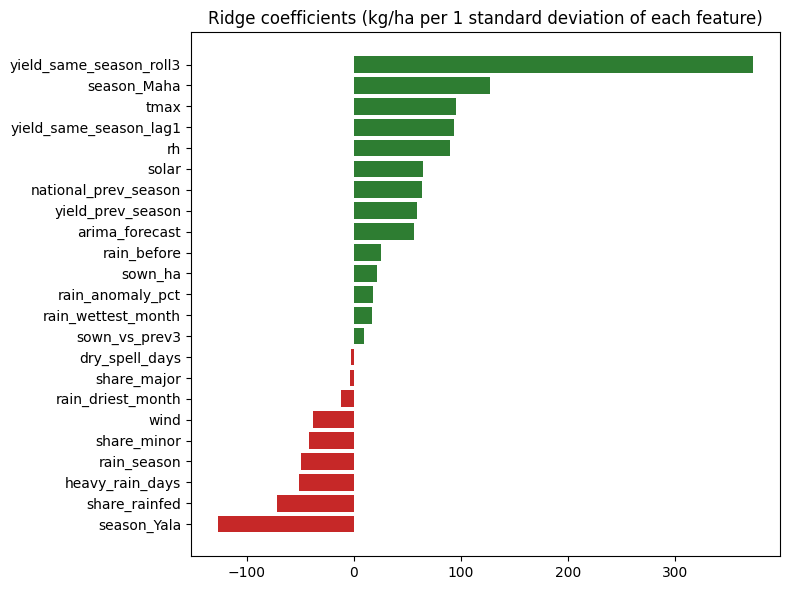

In [145]:
ridge_part = fitted["Ridge regression"]
coef = pd.Series(ridge_part.named_steps["model"].coef_, index=[n.split("__", 1)[1] for n in ridge_part.named_steps["prep"].get_feature_names_out()])
top = coef[[c for c in coef.index if not c.startswith("district_")]].sort_values()
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=["#C62828" if v < 0 else "#2E7D32" for v in top.values])
plt.title("Ridge coefficients (kg/ha per 1 standard deviation of each feature)")
plt.tight_layout()
plt.show()

The bar plot shows mean absolute SHAP, the average effect size of each feature in kg/ha. The three-season average contributes 248 kg/ha, more than twice the next feature (last year's same season, 116), followed by the previous season (106), the ARIMA forecast (100), the rainfed share (88), the national previous season (83), the season (68) and the district (48). Wind, the first weather variable, ranks ninth (46), and the ten smallest features together add 246 kg/ha, about as much as the three-season average.

In the Explainable Boosting Machine SHAP plot the history features dominate. The three-season average raises the estimate by up to 700 kg/ha for districts with high recent yields and lowers it by up to 600 for low ones, followed by last year's same season, the previous season and the ARIMA forecast.

Next come the rainfed share (high share lowers the estimate), the national previous-season yield, the season (Maha above Yala) and the district, then wind (windier seasons lower), the sown extent and season rainfall (very wet seasons lower). As the exploration suggested, most weather variables matter far less than history and irrigation.

In the Ridge coefficients the three-season average again dominates (about +370 kg/ha per standard deviation), followed by the season (Maha about +130 above Yala), maximum temperature, last year's yield and humidity. Negative terms are the Yala season, the rainfed share, heavy-rain days, total season rainfall (floods, lodging and disease) and wind. With one temperature variable left (10.1), the inconsistent opposite signs of the three collinear temperature columns disappear.

Both models rank recent history first, irrigation second and weather a distant third, and this agreement strengthens the explanation. As noted in the lecture, these are attributions of predictions to inputs, not causal effects, so windy seasons yielded less in this data without wind alone being the cause.

Two checks recommended in the XAI lectures follow. The base value plus a season's SHAP values should equal the model's estimate exactly, which matters here because each pairwise term of the EBM is split between its two features. Mean absolute SHAP shows how much the model uses a feature, whereas permutation importance on held-out seasons shows how much accuracy depends on it, and the two can differ when features overlap. Permutation importance is computed on the test seasons as the rise in MAE when one feature is shuffled, averaged over 10 shuffles.

In [146]:
from scipy.stats import spearmanr
from sklearn.inspection import permutation_importance

gap = np.abs(shap_test.base_values + shap_test.values.sum(axis=1) - best_model.predict(X_test))
print(f"Additivity, largest gap between base value + SHAP values and the estimate, {gap.max():.6f} kg/ha over {len(gap)} test seasons")
print(f"Base value {shap_test.base_values[0]:,.0f} kg/ha (the EBM intercept) | mean training yield {y_train.mean():,.0f} kg/ha")

perm = permutation_importance(best_model, X_test, y_test, scoring="neg_mean_absolute_error", n_repeats=10, random_state=random_state, n_jobs=1)
importance = pd.DataFrame({"mean |SHAP| (kg/ha)": np.abs(shap_test.values).mean(axis=0), "MAE rise when shuffled (kg/ha)": perm.importances_mean},
                          index=X_test.columns).sort_values("mean |SHAP| (kg/ha)", ascending=False)
importance["SHAP rank"] = np.arange(1, len(importance) + 1)
importance["permutation rank"] = importance["MAE rise when shuffled (kg/ha)"].rank(ascending=False).astype(int)
rho = spearmanr(importance["mean |SHAP| (kg/ha)"], importance["MAE rise when shuffled (kg/ha)"])
print(f"Spearman rank correlation between the two importances {rho.correlation:.2f} (p = {rho.pvalue:.3f})")
importance.round(1)

Additivity, largest gap between base value + SHAP values and the estimate, 0.000000 kg/ha over 446 test seasons
Base value 3,606 kg/ha (the EBM intercept) | mean training yield 3,606 kg/ha
Spearman rank correlation between the two importances 0.57 (p = 0.005)


,mean |SHAP| (kg/ha),MAE rise when shuffled (kg/ha),SHAP rank,permutation rank
yield_same_season_roll3,248.0,103.1,1,1
yield_same_season_lag1,115.6,19.0,2,6
yield_prev_season,106.3,44.2,3,2
arima_forecast,99.5,25.8,4,4
share_rainfed,87.7,30.9,5,3
national_prev_season,82.8,21.6,6,5
season,68.2,-3.3,7,23
district,47.6,8.7,8,8
wind,45.8,2.4,9,16
sown_ha,41.5,2.5,10,15


Additivity holds exactly. Across all 446 test seasons the base value plus the SHAP values equals the estimate to within 0.000001 kg/ha, so splitting the pairwise terms equally loses nothing. The base value is the EBM's intercept, 3,606 kg/ha, which equals the average yield of the training seasons.

The two rankings agree moderately (Spearman 0.57). Both put the three-season average first by a wide margin, and both place the previous season, the ARIMA forecast, the rainfed share and the national previous season in the top six, so the ranking above holds.

The differences come from overlapping features. Last year's same season ranks second by SHAP but sixth by permutation, because when it is shuffled the three-season average and the previous season still carry most of the same information. The season ranks seventh by SHAP but last by permutation, most likely because the season is also reflected in the ARIMA forecast, the three-season average and that season's weather. Some weather variables (maximum temperature, rainfall before planting and heavy-rain days) rank higher by permutation than by SHAP, as their small effects are not duplicated elsewhere. SHAP thus describes how the model divides the estimate among features, whereas permutation importance shows how much accuracy depends on each one.

### <b>17.2 Explanation of a Single Season, Polonnaruwa Maha 2021/22</b>

This is the fertilizer-ban season in one of the main rice districts. The SHAP waterfall starts from the base value and shows how each feature pushed this prediction up (red) or down (blue).

Actual yield 3103 kg/ha | chosen model predicted 5505


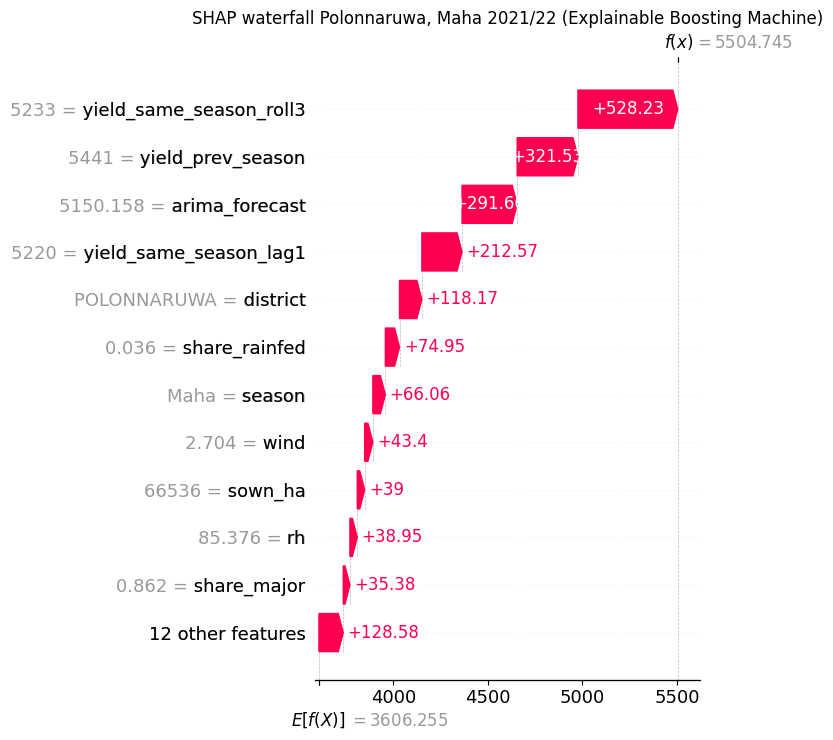

In [147]:
case_idx = np.where((test_df.district.values == "POLONNARUWA") & (test_df.t.values == 2021.75))[0][0]
case = test_df.iloc[case_idx]
print(f"Actual yield {case.yield_kg_ha:.0f} kg/ha | chosen model predicted {case.pred_best:.0f}")
shap.plots.waterfall(shap_test[case_idx], max_display=12, show=False)
plt.title(f"SHAP waterfall Polonnaruwa, Maha 2021/22 ({best_name})")
plt.tight_layout()
plt.show()

The force plot shows the same explanation, with features pushing up (red) or down (blue) from the base value and block length showing strength. Only contributions above 5% of the total are labelled.

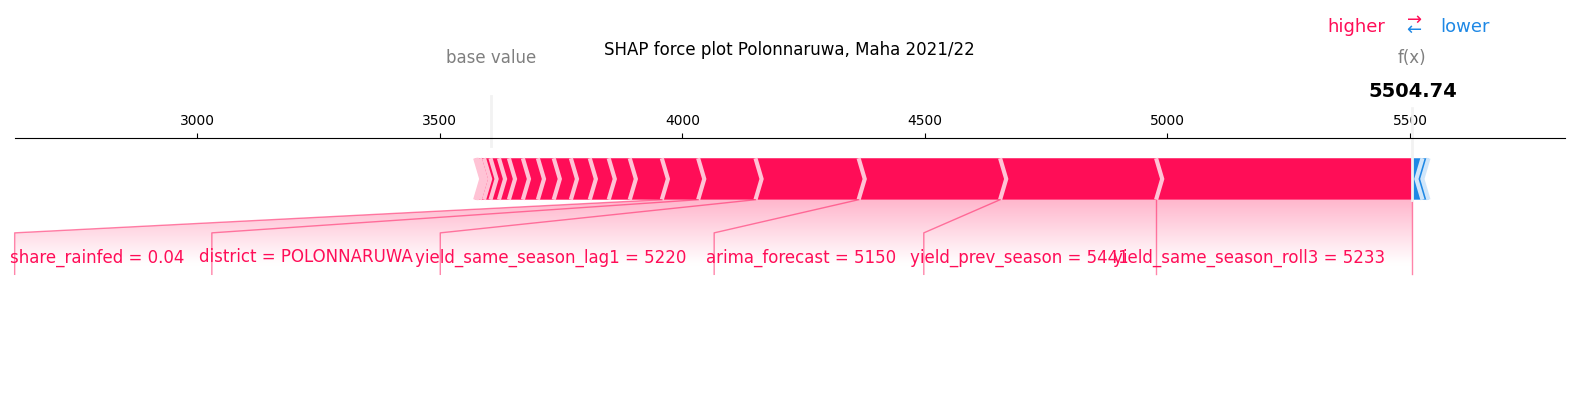

In [148]:
shown = [round(v) if isinstance(v, (int, float, np.floating)) and abs(v) >= 10 else (round(v, 2) if isinstance(v, (float, np.floating)) else v)
         for v in X_test.iloc[case_idx].values]
shap.plots.force(shap_test[case_idx].base_values, shap_test[case_idx].values, features=np.array(shown, dtype=object),
                 feature_names=list(X_test.columns), matplotlib=True, show=False, contribution_threshold=0.05, figsize=(20, 3.5))
plt.title("SHAP force plot Polonnaruwa, Maha 2021/22", pad=60)
plt.show()

### <b>17.3 The Same Season with LIME</b>

LIME (Local Interpretable Model-agnostic Explanations) perturbs the input around this season, observes the final chosen model's responses and fits a small local linear model. Needing only a `predict` function, it works for any model and gives a second opinion on the SHAP waterfall.

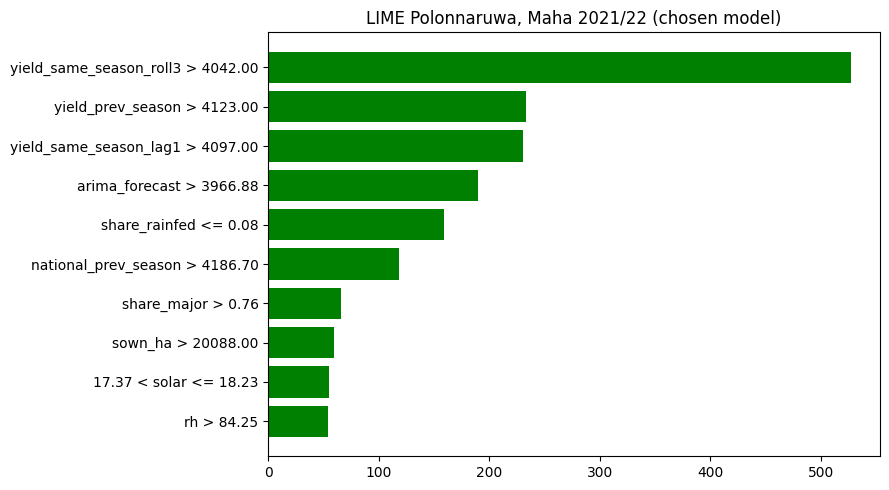

In [149]:
lime_numeric = [c for c in numeric_features]
train_numeric = train_df[lime_numeric].fillna(train_df[lime_numeric].median())


def predict_from_numeric(rows):
    frame = pd.DataFrame(rows, columns=lime_numeric)
    frame["district"], frame["season"] = case.district, case.season
    return best_model.predict(frame[feature_columns])


lime_explainer = LimeTabularExplainer(train_numeric.values, feature_names=lime_numeric, mode="regression", random_state=random_state, discretize_continuous=True)
lime_exp = lime_explainer.explain_instance(case[lime_numeric].astype(float).fillna(train_df[lime_numeric].median()).values,
                                           predict_from_numeric, num_features=10)
fig = lime_exp.as_pyplot_figure()
fig.set_size_inches(9, 5)
plt.title("LIME Polonnaruwa, Maha 2021/22 (chosen model)")
plt.tight_layout()
plt.show()

Polonnaruwa's actual yield in Maha 2021/22 was 3,103 kg/ha against a prediction of 5,505. From the average prediction (3,606), the district's strong history adds about 1,350 kg/ha (three-season average 5,233, previous season 5,441, ARIMA forecast 5,150, same season last year 5,220), with the district, its low rainfed share and the Maha season contributing further.

Every contribution points up, because the cause of the drop (no chemical fertilizer) is not an input. LIME agrees, with recent-yield features above about 4,000 kg/ha dominating, then the low rainfed share and high national previous season, and all ten top features pushing up.

For a decision maker this is the most useful explanation. The model was confident for reasons that held in every previous season and failed in 2021, so a large gap between its estimate and early field reports signals something outside its knowledge.

LIME's samples are random and its explanation depends on the width of the kernel that weights them, so two checks from the LIME notes follow. The local fit shows how well LIME's linear model reproduces the chosen model around this season (its R², and its own estimate against the chosen model's). For stability, LIME is rerun with 10 seeds and three kernel widths (half, equal to and twice the default), and each run's top five features and their signs are compared with those above.

In [150]:
lime_row = case[lime_numeric].astype(float).fillna(train_df[lime_numeric].median()).values
print(f"LIME local fit (R2) {lime_exp.score:.3f} | LIME's estimate {np.ravel(lime_exp.local_pred)[0]:,.0f} kg/ha | chosen model {predict_from_numeric(lime_row.reshape(1, -1))[0]:,.0f} kg/ha")

original_top5 = {lime_numeric[i] for i, _ in lime_exp.as_map()[1][:5]}
default_width = np.sqrt(len(lime_numeric)) * 0.75  # LIME's default kernel width
stability_rows = []
for width in [0.5, 1, 2]:
    for seed in range(10):
        run = LimeTabularExplainer(train_numeric.values, feature_names=lime_numeric, mode="regression", random_state=seed, discretize_continuous=True,
                                   kernel_width=default_width * width).explain_instance(lime_row, predict_from_numeric, num_features=10)
        ranked = [(lime_numeric[i], w) for i, w in run.as_map()[1]]
        top5 = {f for f, _ in ranked[:5]}
        stability_rows.append({"kernel width (x default)": width, "seed": seed, "local fit R2": run.score, "top feature": ranked[0][0],
                               "top-5 overlap with 17.3 (Jaccard)": len(top5 & original_top5) / len(top5 | original_top5),
                               "top-5 signs as in 17.3": np.mean([np.sign(w) == np.sign(dict(lime_exp.as_map()[1])[lime_numeric.index(f)])
                                                                   for f, w in ranked[:5] if lime_numeric.index(f) in dict(lime_exp.as_map()[1])])})
stability = pd.DataFrame(stability_rows)
stability.groupby("kernel width (x default)").agg(**{"mean local fit R2": ("local fit R2", "mean"), "mean top-5 overlap": ("top-5 overlap with 17.3 (Jaccard)", "mean"),
                                                     "share of signs unchanged": ("top-5 signs as in 17.3", "mean"),
                                                     "top feature (runs out of 10)": ("top feature", lambda s: ", ".join(f"{k} {v}" for k, v in s.value_counts().items()))}).round(3)

LIME local fit (R2) 0.499 | LIME's estimate 5,039 kg/ha | chosen model 5,505 kg/ha


,mean local fit R2,mean top-5 overlap,share of signs unchanged,top feature (runs out of 10)
kernel width (x default),,,,
0.5,0.546,1.0,1.0,yield_same_season_roll3 10
1.0,0.515,1.0,1.0,yield_same_season_roll3 10
2.0,0.509,1.0,1.0,yield_same_season_roll3 10


- LIME's local fit is moderate. Its linear model explains about half of the chosen model's variation around the season (R² 0.50), and its estimate (5,039 kg/ha) is 466 below the chosen model's (5,505). LIME is therefore a fair but approximate summary, and the exact SHAP values of 17.2 are the more reliable explanation of this season.
- LIME is stable. All 30 runs give the same top five features with the same signs as above, and the three-season average ranks first in every run, so the agreement between SHAP and LIME is not a chance result of one set of random samples.

### <b>17.4 What the Explainable Boosting Machine Learned</b>

An EBM is a glass-box model whose prediction is a sum of one learned curve per feature (plus a few pairwise terms), so the curves can be read directly without approximation.

The overall term importance (mean absolute contribution over the training seasons) is shown first, then the curves for the rainfed share and weather features. Each curve gives the feature's contribution (kg/ha) across its range, with the shaded band showing variation across the EBM's bagged fits.

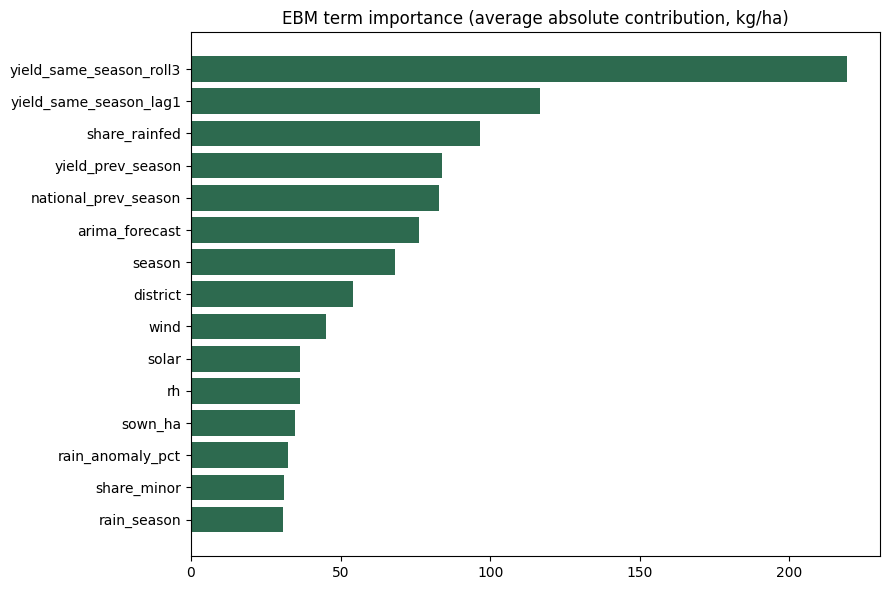

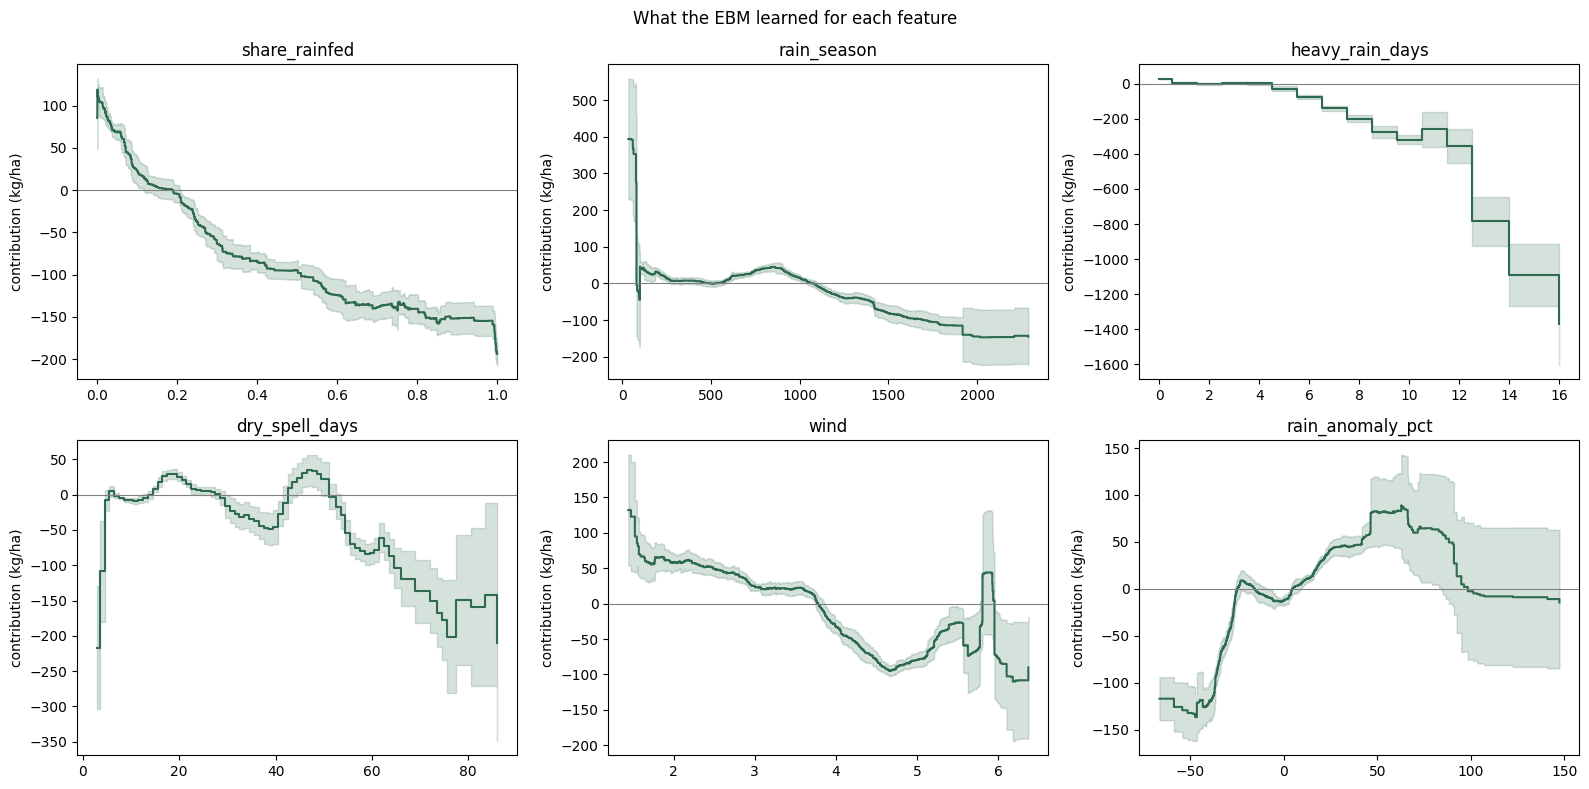

In [151]:
ebm = fitted["Explainable Boosting Machine"]
importance = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values().tail(15)
plt.figure(figsize=(9, 6))
plt.barh(importance.index, importance.values, color="#2D6A4F")
plt.title("EBM term importance (average absolute contribution, kg/ha)")
plt.tight_layout()
plt.show()

global_view = ebm.explain_global()
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
curve_features = [f for f in ["share_rainfed", "rain_season", "heavy_rain_days", "dry_spell_days", "wind", "rain_anomaly_pct",
                                  "rain_before", "solar", "rh", "tmax"] if f in ebm.term_names_][:6]
for ax, name in zip(axes.flat, curve_features):
    d = global_view.data(ebm.term_names_.index(name))
    edges, scores = np.asarray(d["names"], dtype=float), np.asarray(d["scores"], dtype=float)
    ax.step(edges[:-1], scores, where="post", color="#2D6A4F")
    ax.fill_between(edges[:-1], np.asarray(d["lower_bounds"], dtype=float), np.asarray(d["upper_bounds"], dtype=float), step="post", color="#2D6A4F", alpha=0.2)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(name)
    ax.set_ylabel("contribution (kg/ha)")
plt.suptitle("What the EBM learned for each feature")
plt.tight_layout()
plt.show()

The importance ranking matches SHAP, with the three-season average, last year's yield, the rainfed share and other history features first, then season and district, then weather. The curves are the EBM's main strength, as each can be checked against paddy agronomy.

- Rainfed share declines steadily from about +100 kg/ha (fully irrigated) to about -150 to -200 (fully rainfed), so reliable water is worth roughly 300 kg/ha beyond the district's history.
- Season rainfall has almost no effect between about 100 and 1,000 mm, then a penalty reaching about -150 kg/ha above 1,500 mm (floods, lodging, disease). The jump at the lowest rainfall rests on very few seasons (wide band) and should not be interpreted.
- Heavy-rain days have no effect up to about 4 days of 50 mm or more, then a penalty of about -200 kg/ha at 8 days and much more beyond 12, though such seasons are few (wide band). This clearest weather effect is measurable only because CHIRPS rainfall is daily.
- The longest dry spell has small effects up to about 50 days, then a penalty of 50-150 kg/ha with wide uncertainty.
- Wind moves from about +130 kg/ha at 1.5 m/s to about -90 at 4.5 m/s, as strong monsoon winds flatten the crop.
- For the rainfall anomaly, a season 40% or more below the district's normal reduces the yield by about 120 kg/ha, a moderately wet one is slightly beneficial (+50 to +80), and the effect then fades.

These curves serve the same purpose as partial dependence plots, but they are exact, because they are the model itself. The model is its own explanation, without SHAP or LIME. This transparency, together with tying the most accurate model on validation, makes the EBM suitable for provision to a planner.

### <b>17.5 Effect of Each Feature (SHAP Dependence Plots)</b>

A dependence plot places every test season on one chart, with a feature's value on the x-axis and its SHAP value on the y-axis. The slope, fitted directly to the SHAP values, provides a planning figure, such as the change in kg/ha per additional 100 kg/ha of three-season average or per additional 10 percentage points of rainfed land.

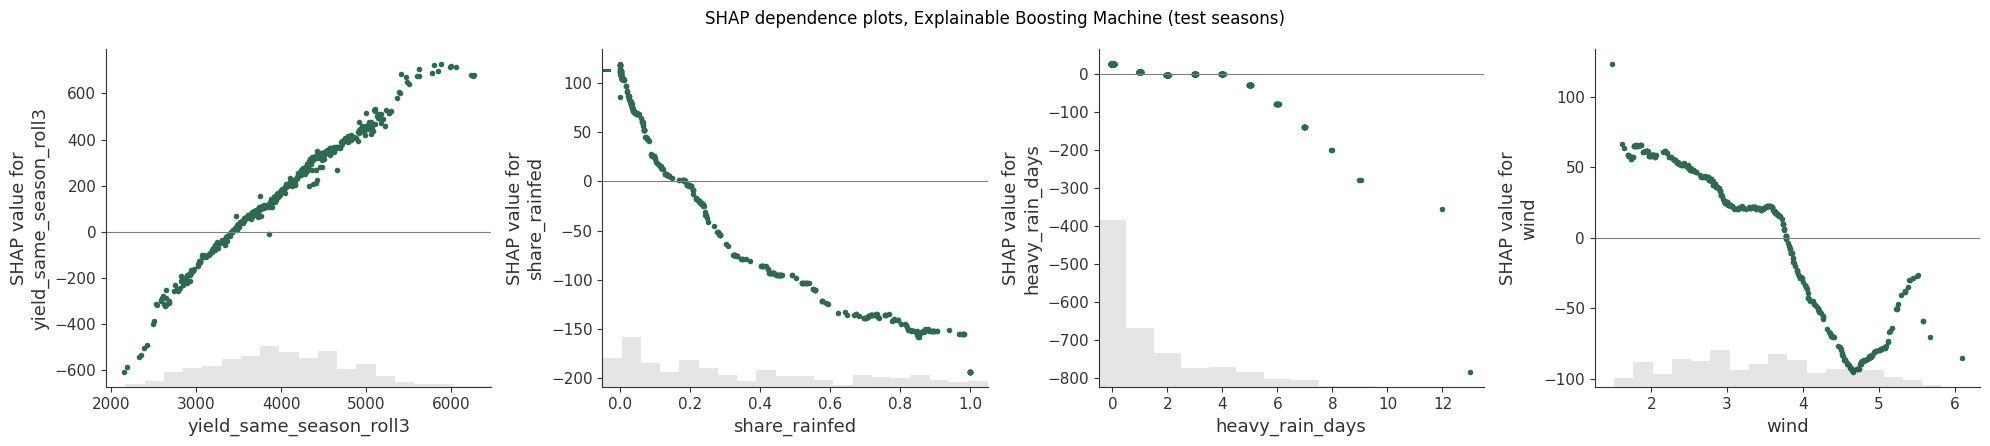

Three-season average +31 kg/ha per 100 kg/ha more
Rainfed share -29 kg/ha per 10 percentage points more rainfed land
Heavy-rain days average SHAP +16 kg/ha with 4 days or fewer (398 seasons), -349 with 8 or more (6 seasons)
Wind -46 kg/ha per 1 m/s more


In [152]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
dependence_features = [f for f in ["yield_same_season_roll3", "share_rainfed", "heavy_rain_days", "wind", "rain_season", "rh"] if f in X_test.columns][:4]
for ax, name in zip(axes, dependence_features):
    shap.plots.scatter(shap_test[:, name], ax=ax, show=False, color="#2D6A4F")
    ax.axhline(0, color="grey", linewidth=0.8)
plt.suptitle(f"SHAP dependence plots, {best_name} (test seasons)")
plt.tight_layout()
plt.show()

col = {name: list(X_test.columns).index(name) for name in X_test.columns}
sv = lambda name: shap_test.values[:, col[name]]
xv = lambda name: X_test[name].astype(float).values
if "yield_same_season_roll3" in col:
    ok = ~np.isnan(xv("yield_same_season_roll3"))
    print(f"Three-season average {np.polyfit(xv('yield_same_season_roll3')[ok], sv('yield_same_season_roll3')[ok], 1)[0] * 100:+.0f} kg/ha per 100 kg/ha more")
if "share_rainfed" in col:
    ok = ~np.isnan(xv("share_rainfed"))
    print(f"Rainfed share {np.polyfit(xv('share_rainfed')[ok], sv('share_rainfed')[ok], 1)[0] * 0.1:+.0f} kg/ha per 10 percentage points more rainfed land")
if "heavy_rain_days" in col:
    hr = xv("heavy_rain_days")
    print(f"Heavy-rain days average SHAP {sv('heavy_rain_days')[hr <= 4].mean():+.0f} kg/ha with 4 days or fewer ({(hr <= 4).sum()} seasons),"
          f" {sv('heavy_rain_days')[hr >= 8].mean():+.0f} with 8 or more ({(hr >= 8).sum()} seasons)")
if "wind" in col:
    ok = ~np.isnan(xv("wind"))
    print(f"Wind {np.polyfit(xv('wind')[ok], sv('wind')[ok], 1)[0]:+.0f} kg/ha per 1 m/s more")

- The three-season average is close to linear, about +31 kg/ha per 100 kg/ha, so the model uses history but attenuates it. A district 1,000 kg/ha above another receives an estimate about 310 kg/ha higher from this feature alone (the previous year's yield and the ARIMA forecast add further). It flattens above about 5,800 kg/ha, where training seasons were few, which is the extrapolation limit observed in 14.2.
- Rainfed share contributes about -29 kg/ha per 10 percentage points, most steeply between fully irrigated and about 30% rainfed.
- Heavy-rain days are flat (+16 kg/ha on average) up to 4 days, then decline to -349 kg/ha on average for the 6 seasons with 8 or more days.
- Wind gives about -46 kg/ha per 1 m/s on a linear fit, but the curve is flat to about 3.6 m/s and declines to about -95 kg/ha at 4.7 m/s. The rise beyond 5 m/s rests on a small number of seasons.

These figures underlie the explanations in the app. Like all SHAP values, they describe how the model uses its inputs, not causal effects in the field.

### <b>17.6 Stability of the Explanation with Less Data</b>

With limited data, a feature may appear important by chance. The chosen model is therefore retrained on random 20%, 40%, 60% and 80% samples of the training seasons, and each feature's mean absolute SHAP on the test seasons is compared with the full model. If the top features and their order are preserved, the explanation in 17.1 is not an artefact of the sample.

In [153]:
rng = np.random.default_rng(random_state)
full_importance = pd.Series(np.abs(shap_test.values).mean(axis=0), index=X_test.columns)
stability_rows, top_by_fraction = [], {}
for fraction in [0.2, 0.4, 0.6, 0.8, 1.0]:
    if fraction < 1:
        idx = rng.choice(len(X_train), size=int(fraction * len(X_train)), replace=False)
        model = candidates[next(k for k in candidates if k[1] == best_name)]().fit(X_train.iloc[idx], y_train.iloc[idx])
        importance = pd.Series(np.abs(shap_explain(model, X_test).values).mean(axis=0), index=X_test.columns)
    else:
        importance = full_importance
    top_by_fraction[f"{int(fraction * 100)}% of the training seasons"] = importance.sort_values(ascending=False).index[:6].tolist()
    stability_rows.append({"training data": f"{int(fraction * 100)}%", "rows": int(fraction * len(X_train)),
                           "rank correlation with full model": importance.corr(full_importance, method="spearman"),
                           "top 6 shared with full model": len(set(importance.nlargest(6).index) & set(full_importance.nlargest(6).index))})
for k, v in top_by_fraction.items():
    print(f"{k:32s} {v}")
pd.DataFrame(stability_rows).round(3)

20% of the training seasons      ['yield_same_season_roll3', 'yield_same_season_lag1', 'yield_prev_season', 'arima_forecast', 'share_rainfed', 'national_prev_season']
40% of the training seasons      ['yield_same_season_roll3', 'yield_same_season_lag1', 'arima_forecast', 'yield_prev_season', 'national_prev_season', 'sown_ha']
60% of the training seasons      ['yield_same_season_roll3', 'yield_prev_season', 'yield_same_season_lag1', 'arima_forecast', 'share_rainfed', 'season']
80% of the training seasons      ['yield_same_season_roll3', 'yield_same_season_lag1', 'yield_prev_season', 'share_rainfed', 'national_prev_season', 'arima_forecast']
100% of the training seasons     ['yield_same_season_roll3', 'yield_same_season_lag1', 'yield_prev_season', 'arima_forecast', 'share_rainfed', 'national_prev_season']


,training data,rows,rank correlation with full model,top 6 shared with full model
0,20%,365,0.737,6
1,40%,731,0.861,5
2,60%,1097,0.835,5
3,80%,1463,0.906,6
4,100%,1829,1.000,6


The top features are stable across sample sizes. The three-season average ranks first in every sample, at least five of the full model's top six always appear, and all six appear with 20% and with 80% of the data. Rank correlation with the full model's importance list rises from 0.74 with 20% of the seasons to 0.91 with 80%.

Less important features change order with less data (with 40%, the sown extent enters the top six), but from 365 seasons upwards history ranks first, followed by irrigation and national conditions. The explanation in 17.1 is therefore not an artefact of the sample.

### <b>17.7 Counterfactual Explanations with DiCE</b>

SHAP and LIME explain why the model gave an estimate. A counterfactual explanation answers a different question, namely what would have to be different for the model to give another answer. DiCE (Diverse Counterfactual Explanations), shown in the SHAP and LIME lectures, searches for several small and varied changes to the inputs that move the prediction into a desired range.

Two seasons are examined with the chosen model. Only the weather inputs may change, since history, irrigation and the district are fixed at the time of the estimate, and each weather input may move only within what the same district recorded in the same season type from 1981 to 2016, so every counterfactual is a season that could plausibly occur. DiCE's model-agnostic random search is used, as the Explainable Boosting Machine is not differentiable.

The first case is Galle in Yala 2023, a season the model correctly flagged as poor. The question is which weather would have given a normal estimate, at least 90% of the district's three-season average.

In [154]:
import dice_ml
from raiutils.exceptions import UserConfigValidationException  # raised by DiCE when no counterfactual is found

training_medians = train_df[numeric_features].median()


def complete(rows):
    # DiCE needs complete rows. A missing irrigation share is what the other two leave, and other gaps take the training median
    rows = rows.copy()
    rows["share_major"] = rows.share_major.fillna(1 - rows.share_minor - rows.share_rainfed)
    rows[numeric_features] = rows[numeric_features].fillna(training_medians)
    return rows


dice_data = dice_ml.Data(dataframe=complete(train_df[feature_columns + ["yield_kg_ha"]]), continuous_features=numeric_features, outcome_name="yield_kg_ha")
dice = dice_ml.Dice(dice_data, dice_ml.Model(model=best_model, backend="sklearn", model_type="regressor"), method="random")
weather_inputs = ["rain_season", "rain_anomaly_pct", "rain_wettest_month", "rain_driest_month", "rain_before", "dry_spell_days", "heavy_rain_days",
                  "tmax", "rh", "solar", "wind"]


def counterfactuals(district, t, desired_range, n=4):
    # only the weather may change, and only within what the district recorded in the same season type from 1981 to 2016
    case = test_df[(test_df.district == district) & (test_df.t == t)]
    history = train_df[(train_df.district == district) & (train_df.season == case.season.iloc[0])]
    allowed = {f: [float(history[f].min()), float(history[f].max())] for f in weather_inputs}
    query = complete(case[feature_columns])
    state = np.random.get_state()  # DiCE draws from numpy's global generator, so its state is put back afterwards
    try:
        result = dice.generate_counterfactuals(query, total_CFs=n, desired_range=desired_range, features_to_vary=weather_inputs,
                                               permitted_range=allowed, random_seed=random_state, verbose=False)
    finally:
        np.random.set_state(state)
    table = pd.concat([query.assign(yield_kg_ha=best_model.predict(query)), result.cf_examples_list[0].final_cfs_df], ignore_index=True)
    changed = [f for f in weather_inputs if (table[f].round(2) != table[f].round(2).iloc[0]).any()]
    table.index = ["actual season"] + [f"counterfactual {i + 1}" for i in range(len(table) - 1)]
    return table[changed + ["yield_kg_ha"]].rename(columns={"yield_kg_ha": "model estimate"})


galle = test_df[(test_df.district == "GALLE") & (test_df.t == 2023.25)].iloc[0]
galle_normal = 0.9 * galle.yield_same_season_roll3
print(f"Galle, Yala 2023 actual {galle.yield_kg_ha:,.0f} kg/ha, three-season average {galle.yield_same_season_roll3:,.0f}, "
      f"a normal harvest from {galle_normal:,.0f}")
counterfactuals("GALLE", 2023.25, [galle_normal, 9000]).round(1)

Galle, Yala 2023 actual 2,169 kg/ha, three-season average 2,643, a normal harvest from 2,378


100%|██████████| 1/1 [00:00<00:00,  9.11it/s]


,rain_season,heavy_rain_days,rh,model estimate
actual season,2076.5,13.0,83.1,1824.1
counterfactual 1,1184.7,4.5,83.1,2660.0
counterfactual 2,2076.5,5.9,82.6,2528.0
counterfactual 3,833.6,1.3,83.1,2770.0
counterfactual 4,2076.5,5.0,82.2,2571.0


In Yala 2023 Galle had 13 days with 50 mm or more of rain, whereas most seasons have four or fewer (17.5), and the model estimated 1,824 kg/ha, a poor harvest (the actual yield was 2,169). Every counterfactual reduces the heavy-rain days, to between 1.3 and 5.9. In two of them nothing else changes noticeably, and with five or six heavy-rain days instead of thirteen and the same total rainfall the estimate rises to about 2,530-2,570 kg/ha, a normal harvest.

The counterfactuals therefore point to the heavy-rain penalty found in 17.4 and 17.5, where the EBM's curve falls steeply beyond about four such days. For a planner the message is concrete. The poor estimate for Galle was driven by flooding rain, and a season with no more than about five heavy-rain days would have been expected to be normal.

The second case is Polonnaruwa in Maha 2021/22, the fertilizer-ban season explained in 17.2, which the model missed. The question is reversed, namely which weather would have made the model predict a poor harvest, and whether any recorded weather comes close to the actual 3,103 kg/ha.

In [155]:
polonnaruwa = test_df[(test_df.district == "POLONNARUWA") & (test_df.t == 2021.75)].iloc[0]
poor_line = 0.9 * polonnaruwa.yield_same_season_roll3
print(f"Polonnaruwa, Maha 2021/22 actual {polonnaruwa.yield_kg_ha:,.0f} kg/ha, three-season average {polonnaruwa.yield_same_season_roll3:,.0f}, "
      f"a poor harvest below {poor_line:,.0f}")
polonnaruwa_cf = counterfactuals("POLONNARUWA", 2021.75, [0, poor_line])

# could any weather the district has recorded bring the estimate close to the actual yield?
try:
    counterfactuals("POLONNARUWA", 2021.75, [0, 3500])
    print("DiCE found recorded weather that gives an estimate below 3,500 kg/ha")
except UserConfigValidationException:
    print("DiCE found no weather within Polonnaruwa's recorded Maha range that gives an estimate below 3,500 kg/ha")
history = train_df[(train_df.district == "POLONNARUWA") & (train_df.season == "Maha")]
sampler = np.random.RandomState(random_state)
trials = complete(test_df[(test_df.district == "POLONNARUWA") & (test_df.t == 2021.75)][feature_columns])
trials = trials.loc[trials.index.repeat(5000)].reset_index(drop=True)
for f in weather_inputs:
    trials[f] = sampler.uniform(history[f].min(), history[f].max(), len(trials))
print(f"Lowest estimate from 5,000 random combinations of the recorded weather {best_model.predict(trials).min():,.0f} kg/ha")
polonnaruwa_cf.round(1)

Polonnaruwa, Maha 2021/22 actual 3,103 kg/ha, three-season average 5,233, a poor harvest below 4,710


100%|██████████| 1/1 [00:00<00:00,  6.20it/s]

No Counterfactuals found for the given configuration, perhaps try with different parameters... ; total time taken: 00 min 00 sec
DiCE found no weather within Polonnaruwa's recorded Maha range that gives an estimate below 3,500 kg/ha
Lowest estimate from 5,000 random combinations of the recorded weather 3,840 kg/ha


,rain_season,rain_driest_month,rain_before,dry_spell_days,heavy_rain_days,rh,model estimate
actual season,1101.1,33.1,284.7,19.0,1.0,85.4,5504.7
counterfactual 1,1101.1,33.1,284.7,28.8,12.9,85.4,4682.0
counterfactual 2,1101.1,187.3,284.7,28.4,12.7,85.4,4672.0
counterfactual 3,2159.6,33.1,415.1,19.0,12.7,85.4,4548.0
counterfactual 4,1101.1,188.0,284.7,19.0,12.7,86.9,4701.0


To push the Polonnaruwa estimate below the poor line (4,710 kg/ha), DiCE has to raise the heavy-rain days from 1 to almost 13, close to the most the district has recorded in a Maha season, in two cases with a longer dry spell as well. Even then the estimate falls only to between 4,548 and 4,701 kg/ha.

No weather within the district's recorded range brings the estimate below 3,500 kg/ha, and the lowest of 5,000 random combinations of recorded weather is 3,840 kg/ha, still about 740 kg/ha above the actual 3,103. The counterfactuals therefore confirm the conclusion of 17.2 from a different angle. The 2021/22 collapse cannot be explained by any plausible weather, because its cause, the ban on chemical fertilizer, was not among the model's inputs, which is why the policy input of Section 11 was added.

## <center><b>18. Final Model and Single-Sample Inference</b></center>

The final model is an Explainable Boosting Machine trained on all 2,275 district-seasons from Yala 1981 to Maha 2025/26. It uses 21 numeric features, district, season and the fertilizer shortage switch from Section 11, drawn from four sources, namely the DCS paddy statistics, CHIRPS rainfall, NASA POWER weather and the fertilizer policy record.

The choice follows the rule in 12.6. The Gaussian Process, Ridge and some other smooth models scored slightly better on the test seasons (14.4), and this is reported, but selection by test score would convert the test set into a selection set.

On the test seasons, the EBM is statistically equivalent to the best of these and substantially superior to the baselines. Every estimate also decomposes exactly into per-input contributions, which a planner needs in order to trust or question it.

### <b>18.1 Uncertainty of Each Estimate</b>

A planner also requires an indication of how far an estimate may deviate from the true yield. NGBoost is the only compared model that predicts a full distribution per season and hence its own interval. Such an interval must be checked, since an "80% interval" should contain the actual yield in about 80% of test seasons.

The alternative is split-conformal prediction. It determines the size within which 80% of the chosen model's absolute errors on the seven validation years fall and applies it as the ± range for every new estimate. It makes no assumption about the shape of the errors and uses only the validation years.

In [156]:
from scipy.stats import norm

validation_errors = []
for tr_idx, va_idx in cv_folds:
    m = candidates[next(k for k in candidates if k[1] == best_name)]().fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    validation_errors.extend(np.abs(y_train.iloc[va_idx].values - m.predict(X_train.iloc[va_idx])))
range_80 = float(np.quantile(validation_errors, 0.8))

test_errors = np.abs(y_test.values - best_model.predict(X_test))
rows = [{"interval": "conformal, ± 80th percentile of validation errors", "width (kg/ha)": 2 * range_80,
         "test seasons inside": (test_errors <= range_80).mean() * 100, "inside, without the ban seasons": (test_errors[~is_shock] <= range_80).mean() * 100}]
ngboost_model = fitted["NGBoost"]  # NGBoost is the one model here that gives its own interval, so it is checked whether or not it is chosen
dist = ngboost_model.named_steps["model"].pred_dist(ngboost_model.named_steps["prep"].transform(X_test))
half = norm.ppf(0.9) * dist.params["scale"]  # an 80% interval is the mean ± 1.28 standard deviations
inside = np.abs(y_test.values - dist.params["loc"]) <= half
rows.insert(0, {"interval": "NGBoost's own 80% interval", "width (kg/ha)": np.median(2 * half),
                "test seasons inside": inside.mean() * 100, "inside, without the ban seasons": inside[~is_shock].mean() * 100})
print(f"80% of the validation errors were within ± {range_80:.0f} kg/ha")
pd.DataFrame(rows).round(0)

80% of the validation errors were within ± 545 kg/ha


,interval,width (kg/ha),test seasons inside,"inside, without the ban seasons"
0,NGBoost's own 80% interval,585.0,46.0,51.0
1,"conformal, ± 80th percentile of validation errors",1091.0,72.0,77.0


NGBoost's intervals are considerably too narrow. Its "80% interval" contained the actual yield in only 46% of test seasons (51% excluding the two fertilizer-ban seasons), because the spread learned on 1981-2016 understates the uncertainty of later seasons. Such intervals would mislead a planner and argue against reliance on NGBoost's distribution despite its accurate point estimates.

The conformal range (± 545 kg/ha around the EBM's estimate) covered 72% of test seasons, and 77% without the ban seasons. This is close to the 80% target, with wider but more reliable intervals.

The shortfall from 80% reflects a test period more difficult than the validation years (record highs and the crash), which no method based on past errors can fully anticipate. This ± 545 kg/ha range is shown in the app.

The chosen model is retrained on all modelling rows (1981 to the most recent season, excluding the held-out Polonnaruwa row). It is saved together with the feature lists and reference tables that automatically supply each district's history and rainfall normal.

Following Section 11, the deployed model adds one input, fertilizer_shortage (0 in a normal season, 1 under a ban or shortage such as 2021/22). Having observed both shortage seasons, it can represent a future shortage, so the app can show a planner the likely effect of such a policy on a district.

The validation and test scores above are for the model without this input. The training inputs are saved as the reference for drift monitoring (19.1).

In [157]:
numeric_features = numeric_features + ["fertilizer_shortage"]  # the policy input from Section 11
feature_columns = categorical_features + numeric_features
X_all, y_all = model_df[feature_columns], model_df["yield_kg_ha"]
final_model = candidates[next(k for k in candidates if k[1] == best_name)]().fit(X_all, y_all)

latest_history = (panel.dropna(subset=["yield_kg_ha"]).sort_values("t").groupby(["district", "season"]).tail(3)
                  .groupby(["district", "season"])["yield_kg_ha"].apply(list).to_dict())
bundle = {
    "model": final_model,
    "model_name": best_name,
    "feature_columns": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "districts": sorted(model_df.district.unique()),
    "rain_normals": normal.to_dict(),
    "recent_yields": {f"{d}|{s}": v for (d, s), v in latest_history.items()},
    # full chronological history per district and season, so the app can rerun the ARIMA forecast and the lags itself
    "yield_history": {f"{d}|{s}": g.sort_values("t")["yield_kg_ha"].dropna().tolist()
                      for (d, s), g in panel.dropna(subset=["yield_kg_ha"]).groupby(["district", "season"])},
    # the same with years, for the history chart in the app
    "yield_series": {f"{d}|{s}": g.sort_values("t")[["year", "yield_kg_ha"]].values.tolist()
                     for (d, s), g in panel.dropna(subset=["yield_kg_ha"]).groupby(["district", "season"])},
    "sown_history": {f"{d}|{s}": g.sort_values("t")["sown_ha"].dropna().tolist()[-3:]
                     for (d, s), g in panel.dropna(subset=["sown_ha"]).groupby(["district", "season"])},
    "latest_national": nat_t.dropna(subset=["national_yield"]).iloc[-1][["season", "year", "national_yield"]].to_dict(),
    "weather_medians": model_df.groupby(["district", "season"])[["rain_season", "rain_wettest_month", "rain_driest_month", "rain_before", "dry_spell_days",
                                                                 "heavy_rain_days", "tmean", "tmax", "tmin", "rh", "solar", "wind"]].median().to_dict("index"),
    "latest_nitrogen_ratio": {"year": int(n_ratio.dropna().index[-1]), "ratio": float(n_ratio.dropna().iloc[-1])},
    "irrigation_mix": model_df.sort_values("t").groupby("district")[["share_major", "share_minor", "share_rainfed"]].last().to_dict("index"),
    "feature_medians": model_df[numeric_features].median().to_dict(),
    "trained_on": f"{len(model_df)} district-seasons, Yala {int(model_df.year.min())} to Maha {int(model_df.year.max())}/{str(int(model_df.year.max()) + 1)[2:]}",
    "test_scores": table.set_index("Model").loc[best_name, ["Test MAE", "Test R2"]].to_dict(),
    "range_80": range_80,
    "reference_inputs": model_df[["district", "season"] + numeric_features].reset_index(drop=True),
    "validation_mae": all_results.set_index("Model").loc[best_name, ["CV MAE", "CV std"]].astype(float).to_dict(),
}
with open("paddy_model.pkl", "wb") as f:
    pickle.dump(bundle, f)
holdout_row.to_csv("holdout_sample.csv", index=False)
table.round(4).to_csv("model_results.csv", index=False)
print("Saved paddy_model.pkl", round(os.path.getsize("paddy_model.pkl") / 1e6, 1), "MB")

Saved paddy_model.pkl 2.7 MB


In [158]:
with open("paddy_model.pkl", "rb") as f:
    loaded = pickle.load(f)
pred = loaded["model"].predict(holdout_row[loaded["feature_columns"]])[0]
h = holdout_row.iloc[0]
print(f"{h.district}, {h.season} {int(h.year)}/{int(h.year) + 1}")
print(f"  predicted yield {pred:,.0f} kg/ha")
print(f"  actual yield    {h.yield_kg_ha:,.0f} kg/ha  (error {pred - h.yield_kg_ha:+,.0f} kg/ha, {abs(pred - h.yield_kg_ha) / h.yield_kg_ha * 100:.1f}%)")
print(f"  last 3 Maha seasons averaged {h.yield_same_season_roll3:,.0f} kg/ha; season rainfall was {h.rain_anomaly_pct:+.0f}% vs normal")

POLONNARUWA, Maha 2025/2026
  predicted yield 5,026 kg/ha
  actual yield    6,095 kg/ha  (error -1,069 kg/ha, 17.5%)
  last 3 Maha seasons averaged 4,636 kg/ha; season rainfall was +5% vs normal


The saved model is loaded and predicts from raw inputs independently. For Polonnaruwa, Maha 2025/26, it predicted about 5,030 kg/ha against an actual 6,095 kg/ha, about 1,070 kg/ha (17.5%) too low and outside the ± 545 kg/ha range, in a record season for Polonnaruwa.

The previous three Maha seasons, still affected by the 2021 crisis, averaged 4,636. Relying on this history, the model under-predicts a sharp recovery, mirroring its failure to anticipate the 2021/22 crash.

The season's rainfall is uncertain. CHIRPS places it near normal (+5%), but this was the season of Cyclone Ditwah (late November 2025), and NASA POWER estimates 848 mm for November against 452 mm from CHIRPS, whose most recent figures may still be revised.

A single season is insufficient to evaluate a model, but this case reflects the same limitation. When conditions move beyond recent history, the model lags.

The same held-out season was re-estimated with the policy input switched on to represent a fertilizer shortage. This is a scenario, not a forecast, illustrating what the model learned from the two shortage seasons.

In [159]:
scenario = holdout_row.copy()
for flag in [0, 1]:
    scenario["fertilizer_shortage"] = flag
    print(f"fertilizer_shortage = {flag} {loaded['model'].predict(scenario[loaded['feature_columns']])[0]:,.0f} kg/ha")

fertilizer_shortage = 0 5,026 kg/ha
fertilizer_shortage = 1 3,068 kg/ha


Activating the policy input lowers the Polonnaruwa estimate from 5,026 to 3,068 kg/ha, a 39% reduction, close to the district's actual loss in Maha 2021/22 (from a 5,233 average to 3,103, -41%). Because the deployed EBM applies the full Maha 2021/22 effect, it would probably overstate the reduction for a milder shortage, as Section 11 showed.

## <center><b>19. Front End and Deployment</b></center>

The deployed versions can be accessed through the [web application](https://paddy-yield-app.grayflower-d27356cf.malaysiawest.azurecontainerapps.io) and the [prediction API documentation](https://paddy-yield-api.grayflower-d27356cf.malaysiawest.azurecontainerapps.io/docs), and the source code is in the [GitHub repository](https://github.com/Uthpalagit/paddy-yield-prediction-269219J). A [backup copy of the application](https://paddy-yield-prediction-269219j-2wfd9iajbb7ebf2jpuzzgb.streamlit.app) runs on Streamlit Community Cloud. It uses the same saved model directly, without the API, so the application remains available if the Azure deployment is stopped.

The saved model is used by two small programs.

- app.py is a Streamlit front end. After the user selects a district and season, that district's planted extent, irrigation mix, recent yields and typical weather are filled in from the saved bundle and can be edited, and a switch sets the season's fertilizer policy (normal or shortage). The estimate page returns the estimate with its ± 545 kg/ha range (18.1), the harvest outlook (poor, normal or good, by the rule of Section 16), the district's history and each input's contribution, and the estimate can be downloaded as a CSV file. A what-if page varies one input across its range under both fertilizer policies. The district map shows the official yield, or its change from the previous year, for any season, with a district ranking. A model comparison page shows, in three separate views, the validation ranking of the 20 candidates used to choose the model, their test scores, and the benchmark against the two published methods (Section 13). A batch page estimates a whole CSV file of district-seasons, and an about page summarises the model, data and limitations.
- api.py is a FastAPI service with a `/predict` endpoint, a `/predict/batch` endpoint for up to 500 seasons (inputs validated with pydantic in both) and a `/health` check, packaged with a Dockerfile to run as a cloud container (Azure Container Apps, as in the MLOps workshop). Each prediction is logged as one JSON line (inputs, estimate, model and time taken), which Azure collects in Log Analytics.

As in the MLOps workshop, these are supported by tests/test_api.py (automated API tests), a GitHub Actions workflow running them on every push (`.github/workflows/ci.yml`), and monitor.py. The monitor examines new inputs and, once official yields are released, the errors, and reports whether retraining is required. A scheduled workflow (`.github/workflows/monitor.yml`) runs it.

```
pip install -r requirements.txt
streamlit run app.py
uvicorn api:app --port 8000
pytest tests
python monitor.py --season 2021.75
```

### <b>19.1 Monitoring for Drift, and When to Retrain</b>

A model trained on past data remains reliable only while the future resembles the past. As in the workshop, two forms of drift are monitored.

The first is data drift, namely whether new inputs resemble the training inputs. The usual measure is the Population Stability Index (PSI), which bins a feature's training values at their quantiles and compares the share of new values per bin with the training share. A value above 0.25 is usually interpreted as a major shift.

PSI assumes many independent rows, but one season has about 25 districts sharing the same weather. The first two cells therefore test whether PSI is usable here, followed by two checks better suited to this data.

- Out of range is the share of districts whose value lies outside that district's training range for the same season type. The model's tree-based curves cannot extend beyond the values observed in training, so this is where estimates begin to lag (14.2).
- Rolling-window PSI compares the last three years (about 150 district-seasons) with the last ten training years, for the yield-history and planting features.

The second is model drift, namely whether the error rises above normal once the official DCS yields for a season are released. The alert is triggered when a season's MAE exceeds the validation mean plus two standard deviations.

The functions are in paddy_helpers.py, so the notebook and monitor.py share the same rules. Below they are run season by season over the test period, as if the model had been deployed in 2017.

In [160]:
from paddy_helpers import psi, drift_report, out_of_range

# how large PSI gets by chance for 25 values drawn from the same distribution, and for a real shift of one standard deviation
sim = np.random.default_rng(random_state)
base = sim.normal(0, 1, 2000)
no_shift = [psi(base, sim.normal(0, 1, 25)) for _ in range(500)]
real_shift = [psi(base, sim.normal(1, 1, 25)) for _ in range(500)]
print(f"25 values, no shift median PSI {np.median(no_shift):.2f}, 95th percentile {np.percentile(no_shift, 95):.2f}")
print(f"25 values, shifted by 1 standard deviation median PSI {np.median(real_shift):.2f}, 5th percentile {np.percentile(real_shift, 5):.2f}")

25 values, no shift median PSI 0.15, 95th percentile 0.49
25 values, shifted by 1 standard deviation median PSI 2.01, 5th percentile 0.63


In [161]:
monitored_features = [c for c in numeric_features if c not in ("fertilizer_shortage", "national_prev_season")]  # one national value per season, so there is no distribution to compare
history_features = [c for c in ["yield_same_season_lag1", "yield_same_season_roll3", "yield_prev_season", "arima_forecast"] if c in monitored_features]
weather_features = [c for c in ["rain_season", "rain_anomaly_pct", "rain_wettest_month", "rain_driest_month", "rain_before", "dry_spell_days",
                                "heavy_rain_days", "tmax", "rh", "solar", "wind"] if c in monitored_features]
val_mean, val_std = all_results.set_index("Model").loc[best_name, ["CV MAE", "CV std"]].astype(float)
alert_level = val_mean + 2 * val_std
monitor_rows = []
for t, g in test_df.groupby("t"):
    same_type = train_df[train_df.season == g.season.iloc[0]]
    outside = out_of_range(same_type, g, monitored_features)
    mae_season = mean_absolute_error(g.yield_kg_ha, g.pred_best)
    monitor_rows.append({"season": f"{'Maha' if t % 1 == 0.75 else 'Yala'} {int(t)}", "t": t,
                         "features with PSI > 0.5": int((drift_report(same_type[monitored_features], g[monitored_features]).psi > 0.5).sum()),
                         "history out of range %": outside[history_features].max() * 100, "weather out of range %": outside[weather_features].max() * 100,
                         "MAE": mae_season, "error alert": mae_season > alert_level})
monitoring = pd.DataFrame(monitor_rows).set_index("season")
print(f"Error alert above {alert_level:.0f} kg/ha (validation mean {val_mean:.0f} + 2 x {val_std:.0f}); {len(monitored_features)} features checked")
monitoring.drop(columns="t").round(1)

Error alert above 505 kg/ha (validation mean 347 + 2 x 79); 20 features checked


,features with PSI > 0.5,history out of range %,weather out of range %,MAE,error alert
season,,,,,
Yala 2017,6,23.1,65.4,358.3,False
Maha 2017,9,18.5,0.0,287.7,False
Yala 2018,8,23.1,26.9,360.8,False
Maha 2018,10,28.0,4.0,528.4,True
Yala 2019,4,37.5,37.5,572.4,True
Maha 2019,13,52.0,40.0,352.2,False
Yala 2020,9,54.2,58.3,452.9,False
Maha 2020,9,60.0,20.0,306.0,False
Yala 2021,8,75.0,25.0,383.4,False


In [162]:
non_weather = [c for c in monitored_features if c not in weather_features]
recent_training = train_df[train_df.t >= 2007]
rolling_rows = []
for year in range(2019, 2027):
    window = model_df[(model_df.t >= year - 3) & (model_df.t < year)]
    report = drift_report(recent_training[non_weather], window[non_weather])
    rolling_rows.append({"3 years up to": year - 1, "rows": len(window), "largest PSI": report.psi.iloc[0], "feature": report.index[0],
                         "features above 0.25": ", ".join(report[report.psi > 0.25].index)})
pd.DataFrame(rolling_rows).round(2)

,3 years up to,rows,largest PSI,feature,features above 0.25
0,2018,157,0.25,sown_vs_prev3,"sown_vs_prev3, sown_ha"
1,2019,153,0.29,sown_ha,sown_ha
2,2020,149,0.39,sown_vs_prev3,sown_vs_prev3
3,2021,147,0.68,sown_vs_prev3,"sown_vs_prev3, yield_prev_season, yield_same_s..."
4,2022,147,1.82,sown_vs_prev3,sown_vs_prev3
5,2023,147,0.44,sown_vs_prev3,"sown_vs_prev3, yield_prev_season, share_major,..."
6,2024,147,0.47,yield_prev_season,"yield_prev_season, yield_same_season_lag1, sow..."
7,2025,146,0.48,sown_vs_prev3,"sown_vs_prev3, sown_ha, share_major, yield_sam..."


- Season-by-season PSI is unusable here. By chance alone, 25 values give a PSI of up to about 0.49 (95th percentile), and because districts share each season's weather, 3 to 14 of the 20 features exceed 0.5 in every test season, normal or not. It would be triggered every season, so it is not used as an alert criterion.
- History out of range is the informative measure. The share of districts with recent yields outside anything they had in training rose through the record years, from 18-28% in 2017-2018 to 38-60% in 2019-2020 and 75% in Yala 2021. It exceeded half from Maha 2019/20 to Yala 2022, when the model under-predicted the record highs (14.2), and fell back after the crash (4-33% from Maha 2022/23). Weather falls out of range in single seasons (65% in Yala 2017, a drought) without a lasting pattern.
- Rolling three-year PSI detects more gradual changes. Planted extent relative to recent seasons shifts most (PSI 1.82 for 2020-2022, the years of free fertilizer, the ban and the crisis), and the yield-history features cross 0.25 from the 2019-2021 window.
- The error alert was triggered four times, in Maha 2018/19 (528 kg/ha) and Yala 2019 (572) during the record-yield years, and in Maha 2021/22 (1,480) and Yala 2022 (558) during the shortage. Each time, 28% or more of the districts had recent yields out of range.

The useful early warning is therefore the share of districts beyond their training range, not a drift score on the weather. Above about half, estimates should be expected to lag and should be verified against field reports, and monitor.py reports this share for every batch of predictions.

The workshop pipeline retrains when an alert is triggered and promotes the new model only if it outperforms the current one. This champion-challenger rule is simulated here. For each alert season, a challenger trained on all earlier seasons is compared with the current champion on that season, which neither model has seen.

A challenger with lower error is promoted and refitted including the alert season. The result is compared with never retraining the 2016 model.

In [163]:
make_best = candidates[next(k for k in candidates if k[1] == best_name)]
champion, champion_label, log_rows = best_model, "trained to 2016", []
test_seasons = sorted(test_df.t.unique())
monitored_pred = pd.Series(np.nan, index=test_df.index)
for t in test_seasons:
    rows = test_df.t == t
    monitored_pred[rows] = champion.predict(X_test[rows])
    if not monitoring.loc[monitoring.t == t, "error alert"].iloc[0]:
        continue
    challenger = make_best().fit(model_df.loc[model_df.t < t, feature_columns[:-1]], model_df.loc[model_df.t < t, "yield_kg_ha"])
    champ_mae = mean_absolute_error(y_test[rows], champion.predict(X_test[rows]))
    chall_mae = mean_absolute_error(y_test[rows], challenger.predict(X_test[rows]))
    promoted = chall_mae < champ_mae
    if promoted:
        champion = make_best().fit(model_df.loc[model_df.t <= t, feature_columns[:-1]], model_df.loc[model_df.t <= t, "yield_kg_ha"])
        champion_label = f"retrained after {'Maha' if t % 1 == 0.75 else 'Yala'} {int(t)}"
    log_rows.append({"alert season": f"{'Maha' if t % 1 == 0.75 else 'Yala'} {int(t)}", "champion MAE": champ_mae, "challenger MAE": chall_mae,
                     "promoted": promoted, "model in use afterwards": champion_label})
print(pd.DataFrame(log_rows).round(0).to_string(index=False))
later = test_df.t > min(t for t in test_seasons if monitoring.loc[monitoring.t == t, "error alert"].iloc[0])
print(f"\nAll test seasons never retrained MAE {mean_absolute_error(y_test, test_df.pred_best):.1f} | monitored and retrained {mean_absolute_error(y_test, monitored_pred):.1f}")
print(f"Seasons after the first alert never retrained {mean_absolute_error(y_test[later], test_df.pred_best[later]):.1f}"
      f" | monitored and retrained {mean_absolute_error(y_test[later], monitored_pred[later]):.1f}")

alert season  champion MAE  challenger MAE  promoted   model in use afterwards
   Maha 2018         528.0           546.0     False           trained to 2016
   Yala 2019         572.0           497.0      True retrained after Yala 2019
   Maha 2021        1730.0          1653.0      True retrained after Maha 2021
   Yala 2022         556.0           556.0     False retrained after Maha 2021

All test seasons never retrained MAE 446.2 | monitored and retrained 451.0
Seasons after the first alert never retrained 465.9 | monitored and retrained 472.2


The champion-challenger rule worked as designed. In Maha 2018/19 the challenger was worse (546 against 528) and was not promoted. After Yala 2019 and Maha 2021/22 it performed better and replaced the champion, and in Yala 2022 the two were equivalent.

Over the entire test period, however, monitoring and retraining did not outperform retaining the 2016 model (MAE 451 against 446, and 472 against 466 after the first alert). The model retrained after the record Yala 2019 season expected high yields to continue and performed worse in Maha 2021/22 than the 2016 model (1,730 against 1,480).

This agrees with Section 11. With yields this noisy, more recent data alone does not improve the model, whereas new information such as the policy input does. The gate remains worthwhile because it prevents a worse model from being deployed, as in Maha 2018/19.

### <b>19.2 Experiment Tracking with MLflow and Data Versioning with DVC</b>

The MLOps workshop added two tools to the pipeline. MLflow records every experiment (its settings, scores and model) and keeps a model registry, where each trained model becomes a numbered version and an alias such as champion or production marks the one in use. DVC (Data Version Control) records exactly which version of the data and the model produced a result, so that any result can be traced and reproduced.

In this project every model compared in Section 12 is logged to MLflow as one run, with its family, its settings and its validation and test scores. The workshop used a DagsHub server for tracking, while here a local store (mlflow.db, kept out of the repository) serves the same purpose and can be browsed with `mlflow ui --backend-store-uri sqlite:///mlflow.db`.

In [164]:
import logging
import hashlib
import mlflow
from mlflow import MlflowClient
from mlflow.models import infer_signature

logging.getLogger("mlflow").setLevel(logging.ERROR)
mlflow.set_tracking_uri("sqlite:///mlflow.db")
experiment = mlflow.set_experiment("paddy-yield-district-season")
client = MlflowClient()
for old_run in mlflow.search_runs(experiment_ids=[experiment.experiment_id])["run_id"]:  # each full run of the notebook starts a fresh record
    client.delete_run(old_run)

# every model compared in Section 12 becomes one run, with its settings and its validation and test scores
metric_names = {"CV MAE": "validation_mae", "CV std": "validation_mae_std", "Test MAE": "test_mae", "Test RMSE": "test_rmse",
                "Test MAPE %": "test_mape_pct", "Test R2": "test_r2", "Test MAE excl. fertilizer-ban seasons": "test_mae_excl_ban"}
for _, row in all_results.iterrows():
    with mlflow.start_run(run_name=row.Model):
        mlflow.set_tags({"stage": "model comparison", "family": row.Family})
        mlflow.log_params({"training seasons": "1981-2016", "validation": "7 yearly folds, 2010-2016", "test seasons": "Yala 2017 to Maha 2025/26",
                           "features": X_train.shape[1]})
        model = fitted.get(row.Model)
        estimator = model.named_steps["model"] if isinstance(model, Pipeline) else model
        if hasattr(estimator, "get_params"):  # the model's own hyperparameters, simple values only
            settings = {k: v for k, v in estimator.get_params(deep=False).items() if isinstance(v, (int, float, str, bool)) and v is not None}
            mlflow.log_params({f"model.{k}": v for k, v in list(settings.items())[:90]})
        mlflow.log_metrics({new: float(row[old]) for old, new in metric_names.items() if pd.notna(row[old])})

runs = mlflow.search_runs(order_by=["metrics.validation_mae ASC"])
print(f"{len(runs)} runs logged in the experiment, best three by validation MAE")
runs[["tags.mlflow.runName", "tags.family", "metrics.validation_mae", "metrics.test_mae"]].head(3).round(1)

22 runs logged in the experiment, best three by validation MAE


,tags.mlflow.runName,tags.family,metrics.validation_mae,metrics.test_mae
0,NGBoost,Not in lectures,343.2,459.3
1,Existing stacked XGBoost (Senevirathne & Prema...,Existing approach,345.3,451.0
2,Explainable Boosting Machine,Not in lectures,346.6,446.2


The model registry then replays the champion-challenger rule of 19.1 with real model versions. The model evaluated in Sections 12 to 14 is registered as version 1 and marked champion. At each error alert a challenger trained on all earlier seasons is registered, and a quality gate promotes it only if it was more accurate than the champion on the alert season, in which case the alias moves to a refitted version. Finally the deployed model of Section 18 is registered and marked production.

In [165]:
registry_name = "paddy-yield-ebm"
if client.search_registered_models(f"name='{registry_name}'"):  # versions from an earlier run of the notebook are removed
    client.delete_registered_model(registry_name)


def register(model, run_name, X_example, tags, metrics):
    # logs the fitted model with its input signature and adds it to the registry as a new version
    with mlflow.start_run(run_name=run_name):
        mlflow.set_tags(tags)
        mlflow.log_metrics(metrics)
        info = mlflow.sklearn.log_model(model, name="model", registered_model_name=registry_name, serialization_format="cloudpickle",
                                        signature=infer_signature(X_example, model.predict(X_example)))
    return str(info.registered_model_version)


def quality_gate(challenger_mae, champion_mae):
    # the promotion rule of 19.1, a challenger replaces the champion only if it was more accurate on the alert season
    return challenger_mae < champion_mae


def season_label(t):
    return f"{'Maha' if t % 1 == 0.75 else 'Yala'} {int(t)}"


# version 1 is the model evaluated in Sections 12 to 14, and it starts as the champion
ebm_scores = all_results.set_index("Model").loc[best_name]
champion_version = register(best_model, "EBM trained to 2016", X_test.head(5), {"stage": "registry", "trained on": "1981-2016"},
                            {"validation_mae": float(ebm_scores["CV MAE"]), "test_mae": float(ebm_scores["Test MAE"])})
client.set_registered_model_alias(registry_name, "champion", champion_version)
champion_model = best_model

# the champion-challenger rule of 19.1 replayed through the registry: every challenger is registered, and the
# champion alias moves only when the quality gate is passed
X_before_policy = model_df[feature_columns[:-1]]
for t in [t for t in test_seasons if monitoring.loc[monitoring.t == t, "error alert"].iloc[0]]:
    rows = test_df.t == t
    challenger = make_best().fit(X_before_policy[model_df.t < t], model_df.loc[model_df.t < t, "yield_kg_ha"])
    champion_mae = mean_absolute_error(y_test[rows], champion_model.predict(X_test[rows]))
    challenger_mae = mean_absolute_error(y_test[rows], challenger.predict(X_test[rows]))
    passed = quality_gate(challenger_mae, champion_mae)
    version = register(challenger, f"challenger before {season_label(t)}", X_test.head(5),
                       {"stage": "registry", "alert season": season_label(t), "quality gate": "passed" if passed else "failed"},
                       {"alert_season_mae": challenger_mae, "champion_alert_season_mae": champion_mae})
    if passed:
        # as in 19.1, the promoted model is refitted with the alert season included
        champion_model = make_best().fit(X_before_policy[model_df.t <= t], model_df.loc[model_df.t <= t, "yield_kg_ha"])
        champion_version = register(champion_model, f"champion after {season_label(t)}", X_test.head(5),
                                    {"stage": "registry", "trained on": f"1981 to {season_label(t)}"}, {})
        client.set_registered_model_alias(registry_name, "champion", champion_version)

# the deployed model of Section 18, trained on every season and with the policy input, is the production version
data_md5 = hashlib.md5(open("Raw Data/cleaned_paddy_data.csv", "rb").read()).hexdigest()
production_version = register(final_model, "deployed model (all seasons, policy input)", X_all.head(5),
                              {"stage": "registry", "trained on": "1981 to Maha 2025/26", "data md5": data_md5,
                               "model file md5": hashlib.md5(open("paddy_model.pkl", "rb").read()).hexdigest()}, {"training_rows": len(X_all)})
client.set_registered_model_alias(registry_name, "production", production_version)

aliases = {}
for alias, v in client.get_registered_model(registry_name).aliases.items():
    aliases.setdefault(int(v), []).append(alias)
registry_rows = []
for v in sorted(client.search_model_versions(f"name='{registry_name}'"), key=lambda v: int(v.version)):
    run = client.get_run(v.run_id)
    registry_rows.append({"version": int(v.version), "run": run.info.run_name, "quality gate": run.data.tags.get("quality gate", ""),
                          "challenger MAE": run.data.metrics.get("alert_season_mae", np.nan),
                          "champion MAE": run.data.metrics.get("champion_alert_season_mae", np.nan), "alias": ", ".join(aliases.get(int(v.version), []))})
pd.DataFrame(registry_rows).set_index("version").round(1)

Successfully registered model 'paddy-yield-ebm'.
Created version '1' of model 'paddy-yield-ebm'.
Registered model 'paddy-yield-ebm' already exists. Creating a new version of this model...
Created version '2' of model 'paddy-yield-ebm'.
Registered model 'paddy-yield-ebm' already exists. Creating a new version of this model...
Created version '3' of model 'paddy-yield-ebm'.
Registered model 'paddy-yield-ebm' already exists. Creating a new version of this model...
Created version '4' of model 'paddy-yield-ebm'.
Registered model 'paddy-yield-ebm' already exists. Creating a new version of this model...
Created version '5' of model 'paddy-yield-ebm'.
Registered model 'paddy-yield-ebm' already exists. Creating a new version of this model...
Created version '6' of model 'paddy-yield-ebm'.
Registered model 'paddy-yield-ebm' already exists. Creating a new version of this model...
Created version '7' of model 'paddy-yield-ebm'.
Registered model 'paddy-yield-ebm' already exists. Creating a new ver

,run,quality gate,challenger MAE,champion MAE,alias
version,,,,,
1,EBM trained to 2016,,NaN,NaN,
2,challenger before Maha 2018,failed,546.0,528.4,
3,challenger before Yala 2019,passed,496.7,572.4,
4,champion after Yala 2019,,NaN,NaN,
5,challenger before Maha 2021,passed,1653.0,1729.6,
6,champion after Maha 2021,,NaN,NaN,champion
7,challenger before Yala 2022,failed,556.1,556.1,
8,"deployed model (all seasons, policy input)",,NaN,NaN,production


The registry reproduces the decisions of 19.1 exactly. The challenger before Maha 2018/19 failed the gate (546 against 528 kg/ha) and was not promoted. The challengers before Yala 2019 and Maha 2021/22 passed (497 against 572 and 1,653 against 1,730), and each was refitted and became the champion, so the champion alias ends on version 6. The Yala 2022 challenger was trained on the same seasons as the champion and was therefore exactly as accurate (556 kg/ha), so it failed the gate, which requires a strict improvement.

Version 8, the deployed model, carries the production alias and records the MD5 fingerprints of the data and the model file it was built from, which links the registry to the DVC record below.

DVC is set up as a one-stage pipeline around the monitoring check of 19.1. The stage depends on the raw data folder, the saved model and the code that reads them, and `dvc repro` records an MD5 fingerprint of each in dvc.lock, which is committed to Git with the code.

If any data file or the model changes, `dvc status` reports the stage as changed and `dvc repro` reruns the check. The raw data (31 MB) is small enough to remain in Git, so no DVC remote is configured. With a larger dataset the files would be moved to DVC storage (DagsHub in the workshop) and pulled with `dvc pull`.

In [166]:
import sys
import subprocess
import yaml


def dvc(*args):
    # runs a DVC command in the project folder, with this notebook's Python first on the path
    env = {**os.environ, "PATH": os.path.dirname(sys.executable) + os.pathsep + os.environ.get("PATH", ""), "DVC_NO_ANALYTICS": "1"}
    result = subprocess.run([sys.executable, "-m", "dvc", *args], capture_output=True, text=True, env=env)
    return (result.stdout + result.stderr).strip()


if not os.path.isdir(".dvc"):
    dvc("init", "-q")
    dvc("config", "core.analytics", "false")
with open(".dvcignore", "a+") as f:  # Finder's folder files are not data
    f.seek(0)
    if ".DS_Store" not in f.read():
        f.write("\n.DS_Store\n")

# one stage, the monitoring check of 19.1, which depends on the raw data folder, the saved model and the code that reads them
pipeline = {"stages": {"monitor": {"cmd": "python monitor.py --season 2025.75",
                                   "deps": ["Raw Data", "paddy_model.pkl", "paddy_helpers.py", "monitor.py"],
                                   "metrics": [{"monitoring_report.json": {"cache": False}}]}}}
with open("dvc.yaml", "w") as f:
    yaml.safe_dump(pipeline, f, sort_keys=False)
dvc("repro", "-q")

lock = yaml.safe_load(open("dvc.lock"))["stages"]["monitor"]
versions = pd.DataFrame([{"file": d["path"], "md5 recorded in dvc.lock": d["md5"], "files": d.get("nfiles", 1), "size (MB)": d["size"] / 1e6}
                         for d in lock["deps"] + lock["outs"]]).set_index("file")
print("dvc status:", dvc("status"))
report = json.load(open("monitoring_report.json"))
print(f"monitoring result for the replayed season: MAE {report['mae']} kg/ha against an alert level of {report['alert_level']}, "
      f"{report['history_out_of_range_pct']}% of districts with history out of range, action: {report['action']}")
versions.round(2)

dvc status: Data and pipelines are up to date.
monitoring result for the replayed season: MAE 315.8 kg/ha against an alert level of 504.6, 4.0% of districts with history out of range, action: no action


,md5 recorded in dvc.lock,files,size (MB)
file,,,
Raw Data,14a4c9fb03fa183ae8867bbfcbd8282c.dir,20,32.23
monitor.py,ed6f3a408a5ff7e43015a538f6f60f53,1,0.01
paddy_helpers.py,9faff672a006426c780d0dc62ffbc01f,1,0.01
paddy_model.pkl,630c046e1ac56227be4a12ddd979521b,1,2.67
monitoring_report.json,4e44ce41f4a73def1444ea4fb073bd49,1,0.00


The lock file records the raw data folder as one fingerprint over its 20 files (32 MB), together with the model file, the two code files and the monitoring report the stage produced. The model's fingerprint (630c046e...) is the one recorded in the production version of the registry, so an estimate in the app, the registry entry and the repository can all be traced to the same data and model. `dvc status` confirms that the data and pipeline are up to date.

The replayed check itself found no problem (MAE 316 kg/ha against an alert level of 505, and 4% of districts with history out of range), so no retraining is recommended.

## <center><b>20. Conclusion</b></center>

A district-season paddy dataset was constructed from primary sources. Eight Department of Census and Statistics tables were reshaped, matched, cleaned and joined with CHIRPS rainfall averaged over each district's boundary, NASA POWER weather, FAOSTAT fertilizer imports and MODIS vegetation greenness into one saved table.

Cleaning corrected 34 spellings for 27 places, a mislabelled "2000/2021" season, inconsistent layouts, 21 war-year yields recorded as 0, an impossible harvested extent, irrigation parts that do not sum correctly and a production table that does not reconcile. NASA's grid was also found to provide the 27 units with only 19 distinct weather series, so rainfall was taken from CHIRPS.

The main findings are listed below.

- History and irrigation carry most of the signal. The district's recent yields, the irrigation mix and the national previous season dominate in every model and in SHAP and LIME. Weather adds less, although CHIRPS reveals the effect of very wet seasons (heavy-rain days).
- New data was tested rather than assumed to be beneficial. CHIRPS rainfall, dry spells, heavy-rain days and a single temperature variable were kept. Nitrogen imports, neighbouring districts, MODIS NDVI, El Niño, the Indian Ocean Dipole, the government's fertilizer policy level, crop health over the rice fields, soil moisture and evaporation, stand-ins for tank storage, heat at flowering and a change-from-average target were rejected, each for a stated reason. All setups were within about 1% of each other, indicating the extent of district yield variation that no available data explains.

  After the main analysis, growth-stage weather and three standard feature selection methods (Lasso, permutation importance and backward elimination, over all 43 candidates) appeared superior on the validation years. As those years had informed every earlier decision, the results were reported but not adopted, and neither performed better on test (447 and 464 kg/ha against 446), a clear case of overfitting to the validation set (15.1, 15.3, 15.4).

  A blend with Ridge, weighting recent seasons and tuning the EBM each moved the error by about 1% or less, and PCA of the weather features made it worse (0.2% with seven components, 1.8% with three). The qualitative features (policy regime, province, climate zone and El Niño phase) were the one late addition that improved the EBM on both validation and test (434 against 446 kg/ha). The gain was small and fragile, so a fresh test is recommended before adoption.

  The final model requires five of the eleven datasets. FAOSTAT, MODIS, the NOAA indices, NOAA crop health, ERA5-Land and the province and climate zone maps were dropped completely.
- Hyperparameters were designed from the data, checked with early stopping and learning curves, and tested by grid and randomised searches on the validation years (12.2, 12.3). The best searched settings improved the validation MAE by only 4.9-8.4 kg/ha, well within the fold-to-fold variation, so the designed configurations were retained, and the best tuned Explainable Boosting Machine remained ahead of the tuned XGBoost and Random Forest.
- Twenty approaches were compared on the same time-based split, including seven models not covered in the lectures (Explainable Boosting Machine, mixed-effects, NGBoost, Gaussian Process, Extra Trees, Histogram Gradient Boosting, Huber regression) and two published approaches.
- The validation-selected model is the Explainable Boosting Machine, a glass-box model from outside the lectures that tied with NGBoost on accuracy and was chosen for its steadier error. Its average error on unseen seasons is 446 kg/ha (12.4%, R² 0.58), significantly better than the baselines and statistically equivalent to the best models on test.

  The smooth models (Gaussian Process 426, Ridge 438) performed slightly better on 2017-2026, which required extrapolation (record highs, then a crash). Every estimate carries a conformal ± 545 kg/ha range from conformal prediction, whereas NGBoost's own intervals were badly overconfident.
- A second task was flagging a poor harvest (Section 16). Each classifier was tuned on the validation years, and the selected XGBoost identified only 13% of poor harvests on test (macro F1 0.34 against 0.22 for always predicting normal), while logistic regression identified 39% (0.47). The regression model's own poor flag is correct 71% of the time and ranks poor seasons best (AUC 0.77), so it is the more dependable warning. Tree classifiers were limited by how few poor seasons the training years contain.
- In planning terms the model is 87.6% accurate (100% minus the mean percentage error), with 86% of district estimates within 20% of the official yield (93% outside the ban seasons). The implied national production was within 5.8% of the official figure on average outside the two ban seasons, and within 12.1% in every such season (14.5).
- Every model failed to anticipate the 2021/22 fertilizer-ban season (district errors around 1,500 kg/ha). National fertilizer imports, the subsidy level and satellite crop health all failed to reveal it, as the crop over the rice fields looked as green as in any other season. After one shortage season, however, a policy input lets a model recognise the next (CatBoost's error for Yala 2022 fell from 814 to 318 kg/ha, Section 11), so the deployed model has a fertilizer-shortage switch for scenario estimates.
- The explanation is stable. SHAP bar, force and dependence plots quantify each driver (+31 kg/ha per 100 kg/ha of recent average, -29 kg/ha per 10 points of rainfed land), and the top features are preserved when the model is trained on only 20% of the data (17.5, 17.6).
- For monitoring, the useful drift signal is the share of districts with recent yields beyond their training range, which exceeded half from Maha 2019/20 until the crash. Error alerts were triggered in four seasons, and a champion-challenger retraining rule prevented one worse model from being deployed (19.1).

The work has limitations. NASA weather is on a coarse grid for temperature, humidity and wind, and there is no district-level data on fertilizer applied, seed varieties, pests or water releases from reservoirs. Satellite greenness at 4 km cannot detect a crop short of nutrients.

The shortage effect was learned from only two seasons. The Mahaweli 'H' and Udawalawe series end in 2018, and the northern districts have gaps from the war years.

The qualitative features, especially the El Niño phase, should be retested on the 2026/27 seasons once the DCS publishes them. Useful additions would be district fertilizer distribution figures (to capture shocks like 2021), reservoir storage at the start of Yala and finer satellite data (Sentinel-2 at 10 m) over mapped paddy fields.

Blending the EBM with a smooth model such as Ridge or the Gaussian Process could combine accuracy in normal seasons with better extrapolation. A smaller learning rate for the EBM, which the searches in 12.3 and 15.5 both pointed to, should also be evaluated when the model is retrained on the 2026/27 seasons. The monitoring of 19.1 should also run on the deployed service each season, once the official DCS figure is released.

### <b>20.1 Critical Discussion</b>

The main limitation is that the model learns only from conditions that occurred in the past. It did not anticipate the 2021/22 fertilizer collapse (14.2), and its tree-based terms cannot predict beyond the yields seen in training, so record seasons are underestimated. The shortage effect rests on only two seasons, and the conformal range contained the actual yield in 72% of test seasons rather than the intended 80% (18.1).

The data has quality issues of its own. Survey records are missing for parts of the conflict period (6.1, 6.4), the Mahaweli 'H' and Udawalawe series end in 2018, and NASA POWER gives neighbouring districts the same temperature, humidity and wind. There is no district-level record of fertilizer applied, seed varieties, pests or reservoir releases, so part of the variation in yield cannot be explained by any available input.

These gaps create a risk of unequal accuracy. The average error was 4-8% in the large irrigated districts but 14-24% in Kilinochchi, Mullaitivu, Mannar and Jaffna (14.3), which are mostly rainfed and have the most gaps. If decisions on support or procurement relied on the model alone, these northern districts would be served by the least reliable estimates, so their estimates should be given a wider margin and checked against field reports before use.

In practice, an early estimate could help the Department of Agriculture and the Paddy Marketing Board act several months sooner. The model should support the official survey rather than replace it. An underestimate could lead to unnecessary imports that lower farm-gate prices, and an overestimate could delay support after a poor harvest. For this reason each estimate in the app is shown with its range and its explanation, and the app's About page states its limitations. All data used is public and aggregated by district, with no personal information (Section 3).